In [1]:
# Подключение Google Диска
from google.colab import drive
from pathlib import Path

drive.mount("/content/drive")

# Основная папка лабораторной работы
WORK_DIR = Path(
    "/content/drive/MyDrive/Лабораторная2_Попова_МТИ2532"
)

# Создание папок
CHECKPOINT_DIR = WORK_DIR / "checkpoints"
ARTIFACTS_DIR = WORK_DIR / "artifacts"
BONUS_DIR = WORK_DIR / "bonus"
DATA_DIR = WORK_DIR / "data"
SCRIPTS_DIR = WORK_DIR / "scripts"

for folder in [
    CHECKPOINT_DIR,
    ARTIFACTS_DIR,
    BONUS_DIR,
    DATA_DIR,
    SCRIPTS_DIR
]:
    folder.mkdir(parents=True, exist_ok=True)

print("Google Диск успешно подключён")
print("Рабочая папка:", WORK_DIR)

print("\nСозданные папки:")

for folder in sorted(WORK_DIR.iterdir()):
    print(folder.name)

print("\nПодготовка завершена")

Mounted at /content/drive
Google Диск успешно подключён
Рабочая папка: /content/drive/MyDrive/Лабораторная2_Попова_МТИ2532

Созданные папки:
artifacts
bonus
checkpoints
data
scripts

Подготовка завершена


In [2]:
# Проверка вычислительной среды
import sys
import torch
import platform
import shutil

print("Версия Python:", sys.version)
print("Операционная система:", platform.system())
print("Версия PyTorch:", torch.__version__)

print("\nПроверка GPU:")
print("CUDA доступна:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("Видеокарта:", torch.cuda.get_device_name(0))
    print("Версия CUDA:", torch.version.cuda)

    gpu_memory = torch.cuda.get_device_properties(0).total_memory
    print("Память GPU:", round(gpu_memory / 1024**3, 2), "ГБ")
else:
    print("Сейчас используется CPU")

print("\nСвободное место на диске:")
disk = shutil.disk_usage("/content")
print(round(disk.free / 1024**3, 2), "ГБ")

print("\nПроверка Google Диска:")
print("Рабочая папка доступна:", WORK_DIR.exists())
print("Папка checkpoints доступна:", CHECKPOINT_DIR.exists())

print("\nПроверка среды завершена")

Версия Python: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
Операционная система: Linux
Версия PyTorch: 2.11.0+cpu

Проверка GPU:
CUDA доступна: False
Сейчас используется CPU

Свободное место на диске:
107.53 ГБ

Проверка Google Диска:
Рабочая папка доступна: True
Папка checkpoints доступна: True

Проверка среды завершена


In [3]:
# Загрузка репозитория GitHub

from pathlib import Path
import subprocess

REPO_URL = "https://github.com/Vitalina6848/tgo-course_Popova_MTI2532.git"
REPO_DIR = Path("/content/tgo-course")

if not REPO_DIR.exists():
    subprocess.run(
        ["git", "clone", REPO_URL, str(REPO_DIR)],
        check=True
    )
else:
    print("Папка репозитория уже существует")

PT01_DIR = REPO_DIR / "pt01"
PT02_DIR = REPO_DIR / "pt02"

print("\nПроверка структуры репозитория:")

print("Репозиторий доступен:",
      (REPO_DIR / ".git").exists())

print("Лабораторная №1:",
      PT01_DIR.exists())

print("Лабораторная №2:",
      PT02_DIR.exists())

print("Токенизатор BPE из первой работы:",
      (PT01_DIR / "artifacts" / "bpe.json").exists())

print("Программа первой работы:",
      (PT01_DIR / "run.py").exists())

print("Шаблон программы второй работы:",
      (PT02_DIR / "run.py").exists())

print("Автотесты второй работы:",
      (REPO_DIR / "tests" / "test_pt02.py").exists())

print("\nСодержимое папки pt02:")

for path in sorted(PT02_DIR.iterdir()):
    print(path.name)

print("\nЗагрузка репозитория завершена")


Проверка структуры репозитория:
Репозиторий доступен: True
Лабораторная №1: True
Лабораторная №2: True
Токенизатор BPE из первой работы: True
Программа первой работы: True
Шаблон программы второй работы: True
Автотесты второй работы: True

Содержимое папки pt02:
run.py

Загрузка репозитория завершена


In [4]:
# Загрузка корпуса и сохранение BPE

from pathlib import Path
from urllib.request import urlretrieve
import shutil
import json

WORK_DIR = Path(
    "/content/drive/MyDrive/Лабораторная2_Попова_МТИ2532"
)

DATA_DIR = WORK_DIR / "data"
DATA_DIR.mkdir(parents=True, exist_ok=True)

CORPUS_URL = (
    "https://raw.githubusercontent.com/"
    "nevmenandr/word2vec-russian-novels/"
    "master/books_before/WarAndPeace.txt"
)

CORPUS_PATH = DATA_DIR / "corpus.txt"
BPE_PATH = DATA_DIR / "bpe.json"

# Загрузка корпуса
if not CORPUS_PATH.exists():
    print("Загружаем корпус «Война и мир»...")
    temp_path = CORPUS_PATH.with_suffix(".tmp")
    urlretrieve(CORPUS_URL, str(temp_path))
    temp_path.replace(CORPUS_PATH)
else:
    print("Корпус уже сохранён на Google Диске")

# Копирование BPE из первой лабораторной
source_bpe = PT01_DIR / "artifacts" / "bpe.json"

shutil.copy2(source_bpe, BPE_PATH)

# Чтение сохранённых файлов
corpus_text = CORPUS_PATH.read_text(encoding="utf-8")

with open(BPE_PATH, encoding="utf-8") as f:
    bpe_data = json.load(f)

# Проверка
print("\nКорпус успешно загружен")
print("Путь:", CORPUS_PATH)
print("Размер файла:", CORPUS_PATH.stat().st_size, "байт")
print("Количество символов:", len(corpus_text))

print("\nТокенизатор BPE успешно сохранён")
print("Путь:", BPE_PATH)
print("Размер файла:", BPE_PATH.stat().st_size, "байт")
print("Поля JSON:", list(bpe_data.keys()))

print("\nНачало корпуса:")
print(corpus_text[:500])

print("\nПроверка сохранения на Google Диске:")
print("Корпус:", CORPUS_PATH.is_file())
print("BPE:", BPE_PATH.is_file())

print("\nПодготовка исходных данных завершена")

Загружаем корпус «Война и мир»...

Корпус успешно загружен
Путь: /content/drive/MyDrive/Лабораторная2_Попова_МТИ2532/data/corpus.txt
Размер файла: 5161320 байт
Количество символов: 2905274

Токенизатор BPE успешно сохранён
Путь: /content/drive/MyDrive/Лабораторная2_Попова_МТИ2532/data/bpe.json
Размер файла: 63624 байт
Поля JSON: ['num_merges', 'vocab_size', 'merges', 'stats', 'examples']

Начало корпуса:


  Л. Н. Толстой «Война и мир»
  
  
    
I
- Eh bien, mon prince. Gênes et Lueques ne sont plus que des apanages, des поместья, de la famille Buonaparte. Non, je vous préviens que si vous ne me dites pas que nous avons la guerre, si vous vous permettez encore de pallier toutes les infamies, toutes les atrocités de cet Antichrist (ma parole, j'y crois) - je ne vous connais plus, vous n'êtes plus mon ami, vous n'êtes plus мой верный раб, comme vous dites. Ну, здравствуйте, здравствуйте.  Je vois

Проверка сохранения на Google Диске:
Корпус: True
BPE: True

Подготовка исходных данных за

1. Данные.

Предобработка текста и разделение на обучающую и проверочную выборки.

Приведение корпуса к нижнему регистру, замена буквы «ё» на «е», выделение слов регулярным выражением и разделение корпуса на обучающую (90%) и проверочную (10%) выборки. Проверка параметров токенизатора BPE из лабораторной работы №1.

In [5]:
# Предобработка текста и разделение корпуса

import re
import json

# Приведение текста к нижнему регистру
normalized_text = corpus_text.lower().replace("ё", "е")

# Выделение слов согласно заданию
words = re.findall(
    r"[а-я]+(?:-[а-я]+)*",
    normalized_text
)

# Разделение корпуса на обучающую
# и проверочную выборки
split_index = int(len(words) * 0.9)

train_words = words[:split_index]
val_words = words[split_index:]

print("СТАТИСТИКА КОРПУСА")
print("=" * 60)

print("Всего слов:", len(words))
print("Уникальных слов:", len(set(words)))

print("\nОбучающая выборка:")
print("Количество слов:", len(train_words))
print("Уникальных слов:", len(set(train_words)))

print("\nПроверочная выборка:")
print("Количество слов:", len(val_words))
print("Уникальных слов:", len(set(val_words)))

print("\nДоля обучающей выборки (%):",
      round(len(train_words) / len(words) * 100, 2))

print("Доля проверочной выборки (%):",
      round(len(val_words) / len(words) * 100, 2))

print("\nПервые 30 слов корпуса:")
print(" ".join(words[:30]))

print("\nПервые 30 слов проверочной выборки:")
print(" ".join(val_words[:30]))

# Проверка токенизатора из первой работы
print("\nПАРАМЕТРЫ BPE")
print("=" * 60)

print("Количество слияний:", bpe_data["num_merges"])
print("Размер словаря:", bpe_data["vocab_size"])
print("Количество записей слияний:", len(bpe_data["merges"]))

print("\nПервые 10 слияний:")
for pair in bpe_data["merges"][:10]:
    print(pair)

# Проверка соответствия первой лабораторной
print("\nПРОВЕРКА")
print("=" * 60)

print("Количество слов совпадает:",
      len(words) == 433082)

print("Обучающая выборка совпадает:",
      len(train_words) == 389773)

print("Проверочная выборка совпадает:",
      len(val_words) == 43309)

print("Количество слияний BPE корректно:",
      len(bpe_data["merges"]) == 1500)

print("\nПредобработка корпуса завершена")

СТАТИСТИКА КОРПУСА
Всего слов: 433082
Уникальных слов: 48117

Обучающая выборка:
Количество слов: 389773
Уникальных слов: 45309

Проверочная выборка:
Количество слов: 43309
Уникальных слов: 9638

Доля обучающей выборки (%): 90.0
Доля проверочной выборки (%): 10.0

Первые 30 слов корпуса:
л н толстой война и мир поместья мой верный раб ну здравствуйте здравствуйте садитесь и рассказывайте так говорила в июле года известная анна павловна шерер фрейлина и приближенная императрицы марии

Первые 30 слов проверочной выборки:
это был георгий й степени на другой день были у фельдмаршала обед и бал которые государь удостоил своим присутствием кутузову пожалован георгий й степени государь оказывал ему высочайшие почести но

ПАРАМЕТРЫ BPE
Количество слияний: 1500
Размер словаря: 1534
Количество записей слияний: 1500

Первые 10 слияний:
['о', '</w>']
['и', '</w>']
['а', '</w>']
['е', '</w>']
['я', '</w>']
['с', 'т']
['ь', '</w>']
['а', 'л']
['т', 'о']
['в', '</w>']

ПРОВЕРКА
Количество слов совпад

Реализация токенизации BPE по рангам слияний.

Использование собственного BPE из первой лабораторной работы. Берем уже сохранённые 1500 слияний из bpe.json и реализуем их применение.

Загрузка списка слияний из первой лабораторной работы,
формирование словаря рангов и реализация функции
токенизации слов с использованием маркера конца слова
</w>. Проверка правильности разбиения и восстановления слов.

In [6]:
# Реализация токенизации BPE по рангам слияний

import json
from functools import lru_cache

# Загружаем результаты BPE из первой лабораторной работы
with open(BPE_PATH, "r", encoding="utf-8") as f:
    bpe_data = json.load(f)

# Список пар для слияния
bpe_merges = [tuple(pair) for pair in bpe_data["merges"]]

# Формируем словарь рангов слияний
bpe_ranks = {
    pair: rank
    for rank, pair in enumerate(bpe_merges)
}

# Токенизация отдельного слова
@lru_cache(maxsize=None)
def bpe_tokenize_word(word):
    symbols = list(word) + ["</w>"]

    while len(symbols) > 1:

        # Формируем пары соседних символов
        pairs = list(zip(symbols, symbols[1:]))

        # Оставляем только известные пары
        available_pairs = [
            pair for pair in pairs
            if pair in bpe_ranks
        ]

        if not available_pairs:
            break

        # Выбираем пару с наименьшим рангом
        best_pair = min(
            available_pairs,
            key=lambda pair: bpe_ranks[pair]
        )

        # Выполняем слияние
        new_symbols = []
        i = 0

        while i < len(symbols):
            if (
                i + 1 < len(symbols)
                and (symbols[i], symbols[i + 1]) == best_pair
            ):
                new_symbols.append(
                    symbols[i] + symbols[i + 1]
                )
                i += 2
            else:
                new_symbols.append(symbols[i])
                i += 1

        symbols = new_symbols

    return tuple(symbols)


# Проверяем работу токенизатора
test_words = [
    "князь",
    "андрей",
    "наташа",
    "наполеон",
    "сказала",
    "неудовольствие",
    "война",
    "мир",
    "трансформер",
    "языковой",
    "модель",
    "токенизация"
]

print("ПРОВЕРКА ТОКЕНИЗАТОРА BPE")
print("=" * 60)

print("Количество слияний:", len(bpe_merges))
print("Количество рангов:", len(bpe_ranks))

all_correct = True

for word in test_words:
    tokens = bpe_tokenize_word(word)

    restored = "".join(tokens).replace("</w>", "")
    correct = restored == word

    all_correct = all_correct and correct

    print("\nСлово:", word)
    print("Токены:", list(tokens))
    print("Количество токенов:", len(tokens))
    print("Восстановленное слово:", restored)
    print("Проверка:", correct)

print("\n" + "=" * 60)

# Сравнение с результатами первой лабораторной
expected_examples = {
    "наполеон": ("наполеон</w>",),
    "сказала": ("сказала</w>",),
    "неудовольствие": ("не", "удоволь", "ствие</w>")
}

print("СОВПАДЕНИЕ С ЛАБОРАТОРНОЙ №1")

for word, expected in expected_examples.items():
    print(word, ":", bpe_tokenize_word(word) == expected)

print("\nВсе слова восстановлены правильно:", all_correct)
print("Количество исследованных слов:", len(test_words))
print("\nРеализация токенизации BPE завершена")

ПРОВЕРКА ТОКЕНИЗАТОРА BPE
Количество слияний: 1500
Количество рангов: 1500

Слово: князь
Токены: ['князь</w>']
Количество токенов: 1
Восстановленное слово: князь
Проверка: True

Слово: андрей
Токены: ['андрей</w>']
Количество токенов: 1
Восстановленное слово: андрей
Проверка: True

Слово: наташа
Токены: ['наташа</w>']
Количество токенов: 1
Восстановленное слово: наташа
Проверка: True

Слово: наполеон
Токены: ['наполеон</w>']
Количество токенов: 1
Восстановленное слово: наполеон
Проверка: True

Слово: сказала
Токены: ['сказала</w>']
Количество токенов: 1
Восстановленное слово: сказала
Проверка: True

Слово: неудовольствие
Токены: ['не', 'удоволь', 'ствие</w>']
Количество токенов: 3
Восстановленное слово: неудовольствие
Проверка: True

Слово: война
Токены: ['вой', 'на</w>']
Количество токенов: 2
Восстановленное слово: война
Проверка: True

Слово: мир
Токены: ['ми', 'р</w>']
Количество токенов: 2
Восстановленное слово: мир
Проверка: True

Слово: трансформер
Токены: ['т', 'ран', 'с', 'ф', 

Формирование словаря и присвоение номеров токенам.

Формирование словаря на основе исходного алфавита
и 1500 слияний BPE из первой лабораторной работы.
Присвоение каждому токену уникального числового
идентификатора. Создание функций прямого и обратного
преобразования токенов.

In [7]:
# Формирование словаря и присвоение номеров токенам

import json

# Исходный алфавит после предобработки
base_symbols = set(
    "абвгдежзийклмнопрстуфхцчшщъыьэюя-"
)

# Добавляем маркер конца слова
base_symbols.add("</w>")

# Формируем полный словарь BPE
vocab = set(base_symbols)

for left, right in bpe_merges:
    vocab.add(left)
    vocab.add(right)
    vocab.add(left + right)

# Сортировка для воспроизводимости результатов
vocab = sorted(vocab)

# Прямое преобразование: токен -> номер
token_to_id = {
    token: idx
    for idx, token in enumerate(vocab)
}

# Обратное преобразование: номер -> токен
id_to_token = {
    idx: token
    for token, idx in token_to_id.items()
}

vocab_size = len(vocab)


# Преобразование слова в номера токенов
def encode_word(word):
    return [
        token_to_id[token]
        for token in bpe_tokenize_word(word)
    ]


# Восстановление текста из номеров токенов
def decode_ids(ids):
    tokens = [
        id_to_token[int(idx)]
        for idx in ids
    ]

    return "".join(tokens).replace("</w>", " ").strip()


print("ФОРМИРОВАНИЕ СЛОВАРЯ BPE")
print("=" * 60)

print("Исходных символов:", len(base_symbols))
print("Количество слияний:", len(bpe_merges))
print("Размер словаря:", vocab_size)

print(
    "Размер словаря совпадает с первой лабораторной:",
    vocab_size == bpe_data["vocab_size"]
)

print("\nПервые 20 токенов словаря:")

for idx in range(20):
    print(idx, "->", id_to_token[idx])

# Проверка преобразования слов
print("\nПРОВЕРКА ПРЕОБРАЗОВАНИЯ")
print("=" * 60)

all_restored = True

for word in test_words:

    tokens = bpe_tokenize_word(word)
    ids = encode_word(word)
    restored = decode_ids(ids)

    correct = restored == word
    all_restored = all_restored and correct

    print("\nСлово:", word)
    print("Токены:", list(tokens))
    print("Номера токенов:", ids)
    print("Восстановленное слово:", restored)
    print("Проверка:", correct)

# Проверка на нескольких словах
phrase = "князь андрей вошел в комнату"

phrase_ids = [
    idx
    for word in phrase.split()
    for idx in encode_word(word)
]

restored_phrase = decode_ids(phrase_ids)

print("\nПРОВЕРКА ФРАЗЫ")
print("=" * 60)

print("Исходная фраза:", phrase)
print("Номера токенов:", phrase_ids)
print("Количество токенов:", len(phrase_ids))
print("Восстановленная фраза:", restored_phrase)
print("Проверка:", restored_phrase == phrase)

# Итоговая проверка
print("\nИТОГОВАЯ ПРОВЕРКА")
print("=" * 60)

print(
    "Все номера уникальны:",
    len(set(token_to_id.values())) == vocab_size
)

print(
    "Все слова восстановлены правильно:",
    all_restored
)

print(
    "Размер словаря корректен:",
    vocab_size == 1534
)

assert vocab_size == bpe_data["vocab_size"]
assert all_restored
assert restored_phrase == phrase

print("\nФормирование словаря завершено")

ФОРМИРОВАНИЕ СЛОВАРЯ BPE
Исходных символов: 34
Количество слияний: 1500
Размер словаря: 1534
Размер словаря совпадает с первой лабораторной: True

Первые 20 токенов словаря:
0 -> -
1 -> -ни
2 -> -нибудь</w>
3 -> -то</w>
4 -> </w>
5 -> а
6 -> а</w>
7 -> ад
8 -> адъ
9 -> адъю
10 -> адъютан
11 -> адъютант</w>
12 -> ал
13 -> ал</w>
14 -> ала
15 -> ала</w>
16 -> алась</w>
17 -> але
18 -> алек
19 -> алекса

ПРОВЕРКА ПРЕОБРАЗОВАНИЯ

Слово: князь
Токены: ['князь</w>']
Номера токенов: [610]
Восстановленное слово: князь
Проверка: True

Слово: андрей
Токены: ['андрей</w>']
Номера токенов: [36]
Восстановленное слово: андрей
Проверка: True

Слово: наташа
Токены: ['наташа</w>']
Номера токенов: [799]
Восстановленное слово: наташа
Проверка: True

Слово: наполеон
Токены: ['наполеон</w>']
Номера токенов: [792]
Восстановленное слово: наполеон
Проверка: True

Слово: сказала
Токены: ['сказала</w>']
Номера токенов: [1165]
Восстановленное слово: сказала
Проверка: True

Слово: неудовольствие
Токены: ['не', 'у

Преобразование корпуса в поток номеров токенов.

Токенизация обучающей и проверочной выборок
с использованием BPE из первой лабораторной работы.
Преобразование токенов в числовые идентификаторы
и формирование тензоров PyTorch для последующего
обучения трансформера.

In [8]:
# Преобразование корпуса в поток номеров токенов

import torch
import time

start_time = time.perf_counter()

# Кэширование токенизации повторяющихся слов
word_cache = {}


def encode_corpus(words):
    ids = []

    for word in words:
        if word not in word_cache:
            word_cache[word] = encode_word(word)

        ids.extend(word_cache[word])

    return torch.tensor(ids, dtype=torch.long)


print("ТОКЕНИЗАЦИЯ КОРПУСА")
print("=" * 60)

# Токенизация обучающей выборки
print("Обработка обучающей выборки...")

train_ids = encode_corpus(train_words)

print("Обучающая выборка обработана")

# Токенизация проверочной выборки
print("\nОбработка проверочной выборки...")

val_ids = encode_corpus(val_words)

print("Проверочная выборка обработана")

elapsed_time = time.perf_counter() - start_time

# Общее количество токенов
total_tokens = len(train_ids) + len(val_ids)

print("\nСТАТИСТИКА ТОКЕНИЗАЦИИ")
print("=" * 60)

print("Всего слов:",
      len(train_words) + len(val_words))

print("Всего токенов:", total_tokens)

print("\nОбучающая выборка:")
print("Количество слов:", len(train_words))
print("Количество токенов:", len(train_ids))
print("Размерность тензора:", train_ids.shape)

print("Токенов на слово:",
      round(len(train_ids) / len(train_words), 4))

print("\nПроверочная выборка:")
print("Количество слов:", len(val_words))
print("Количество токенов:", len(val_ids))
print("Размерность тензора:", val_ids.shape)

print("Токенов на слово:",
      round(len(val_ids) / len(val_words), 4))

print("\nСреднее количество токенов на слово:",
      round(total_tokens /
            (len(train_words) + len(val_words)), 4))

print("Тип данных:", train_ids.dtype)
print("Размер словаря:", vocab_size)
print("Слов в кэше:", len(word_cache))

print("Время токенизации (сек.):",
      round(elapsed_time, 2))

# Просмотр начала числового потока
print("\nПРИМЕРЫ ТОКЕНИЗАЦИИ")
print("=" * 60)

print("Первые 30 обучающих токенов:")
print(train_ids[:30].tolist())

print("\nВосстановленный текст:")
print(decode_ids(train_ids[:30].tolist()))

print("\nПервые 30 проверочных токенов:")
print(val_ids[:30].tolist())

print("\nВосстановленный текст:")
print(decode_ids(val_ids[:30].tolist()))

# Проверка диапазона идентификаторов
train_valid = bool(
    (train_ids >= 0).all() and
    (train_ids < vocab_size).all()
)

val_valid = bool(
    (val_ids >= 0).all() and
    (val_ids < vocab_size).all()
)

print("\nИТОГОВАЯ ПРОВЕРКА")
print("=" * 60)

print("Обучающие идентификаторы корректны:",
      train_valid)

print("Проверочные идентификаторы корректны:",
      val_valid)

print("Обучающая выборка одномерная:",
      train_ids.ndim == 1)

print("Проверочная выборка одномерная:",
      val_ids.ndim == 1)

print("Количество токенов совпадает с ЛР №1:",
      total_tokens == 836998)

assert train_valid
assert val_valid
assert train_ids.ndim == 1
assert val_ids.ndim == 1

print("\nТокенизация корпуса завершена")

ТОКЕНИЗАЦИЯ КОРПУСА
Обработка обучающей выборки...
Обучающая выборка обработана

Обработка проверочной выборки...
Проверочная выборка обработана

СТАТИСТИКА ТОКЕНИЗАЦИИ
Всего слов: 433082
Всего токенов: 836998

Обучающая выборка:
Количество слов: 389773
Количество токенов: 753537
Размерность тензора: torch.Size([753537])
Токенов на слово: 1.9333

Проверочная выборка:
Количество слов: 43309
Количество токенов: 83461
Размерность тензора: torch.Size([83461])
Токенов на слово: 1.9271

Среднее количество токенов на слово: 1.9327
Тип данных: torch.int64
Размер словаря: 1534
Слов в кэше: 48117
Время токенизации (сек.): 2.01

ПРИМЕРЫ ТОКЕНИЗАЦИИ
Первые 30 обучающих токенов:
[669, 781, 1333, 1258, 567, 176, 783, 517, 738, 1062, 975, 735, 1499, 761, 135, 872, 1063, 48, 861, 484, 303, 1063, 210, 216, 568, 484, 303, 1063, 210, 216]

Восстановленный текст:
л н толстой война и мир поместья мой верный раб ну здравствуйте здравству

Первые 30 проверочных токенов:
[1508, 97, 235, 411, 921, 235, 526, 56

In [9]:
# Проверка и сохранение подготовленных данных

from pathlib import Path
import json
import torch

DATA_DIR = Path(
    "/content/drive/MyDrive/"
    "Лабораторная2_Попова_МТИ2532/data"
)

DATA_DIR.mkdir(parents=True, exist_ok=True)

print("СОХРАНЕНИЕ ПОДГОТОВЛЕННЫХ ДАННЫХ")
print("=" * 60)

# Сохранение тензоров
train_path = DATA_DIR / "train_ids.pt"
val_path = DATA_DIR / "val_ids.pt"

torch.save(train_ids.cpu(), train_path)
torch.save(val_ids.cpu(), val_path)

print("Обучающая выборка сохранена")
print("Проверочная выборка сохранена")

# Сохранение словаря токенов
vocab_path = DATA_DIR / "vocab.json"

vocab_data = {
    "vocab_size": vocab_size,
    "bpe_merges": len(bpe_data["merges"]),
    "id_to_token": {
        str(i): decode_token
        for i, decode_token in enumerate(
            sorted(
                set("".join(train_words)) |
                {"</w>"} |
                {
                    "".join(pair)
                    for pair in bpe_data["merges"]
                }
            )
        )
    }
}

# Проверка соответствия словаря
assert len(vocab_data["id_to_token"]) == vocab_size

assert (
    vocab_data["id_to_token"][str(610)]
    == "князь</w>"
)

assert (
    vocab_data["id_to_token"][str(36)]
    == "андрей</w>"
)

with open(vocab_path, "w", encoding="utf-8") as f:
    json.dump(
        vocab_data,
        f,
        ensure_ascii=False,
        indent=2
    )

print("Словарь токенов сохранён")

# Сохранение статистики корпуса
stats_path = DATA_DIR / "data_stats.json"

data_stats = {
    "total_words": len(train_words) + len(val_words),
    "train_words": len(train_words),
    "val_words": len(val_words),
    "total_tokens": len(train_ids) + len(val_ids),
    "train_tokens": len(train_ids),
    "val_tokens": len(val_ids),
    "vocab_size": vocab_size,
    "bpe_merges": len(bpe_data["merges"]),
    "tokens_per_word": (
        (len(train_ids) + len(val_ids)) /
        (len(train_words) + len(val_words))
    ),
    "train_fraction": 0.9,
    "val_fraction": 0.1
}

with open(stats_path, "w", encoding="utf-8") as f:
    json.dump(
        data_stats,
        f,
        ensure_ascii=False,
        indent=2
    )

print("Статистика корпуса сохранена")

# Проверка восстановления тензоров
restored_train_ids = torch.load(
    train_path,
    map_location="cpu",
    weights_only=True
)

restored_val_ids = torch.load(
    val_path,
    map_location="cpu",
    weights_only=True
)

train_match = torch.equal(
    train_ids.cpu(),
    restored_train_ids
)

val_match = torch.equal(
    val_ids.cpu(),
    restored_val_ids
)

print("\nПРОВЕРКА ВОССТАНОВЛЕНИЯ")
print("=" * 60)

print("Обучающая выборка совпадает:", train_match)
print("Проверочная выборка совпадает:", val_match)

# Проверка сохранённого словаря
with open(vocab_path, encoding="utf-8") as f:
    restored_vocab = json.load(f)

vocab_match = restored_vocab == vocab_data

print("Словарь совпадает:", vocab_match)

# Проверка сохранённой статистики
with open(stats_path, encoding="utf-8") as f:
    restored_stats = json.load(f)

stats_match = restored_stats == data_stats

print("Статистика совпадает:", stats_match)

print("\nФАЙЛЫ НА GOOGLE ДИСКЕ")
print("=" * 60)

for path in sorted(DATA_DIR.iterdir()):
    if path.is_file():
        print(path.name, "-", path.stat().st_size, "байт")

print("\nПуть сохранения:")
print(DATA_DIR)

assert train_match
assert val_match
assert vocab_match
assert stats_match

print("\nВсе данные успешно сохранены")
print("ЗАДАНИЕ №1. ДАННЫЕ — ВЫПОЛНЕНО")

СОХРАНЕНИЕ ПОДГОТОВЛЕННЫХ ДАННЫХ
Обучающая выборка сохранена
Проверочная выборка сохранена
Словарь токенов сохранён
Статистика корпуса сохранена

ПРОВЕРКА ВОССТАНОВЛЕНИЯ
Обучающая выборка совпадает: True
Проверочная выборка совпадает: True
Словарь совпадает: True
Статистика совпадает: True

ФАЙЛЫ НА GOOGLE ДИСКЕ
bpe.json - 63624 байт
corpus.txt - 5161320 байт
data_stats.json - 282 байт
train_ids.pt - 6029865 байт
val_ids.pt - 669225 байт
vocab.json - 38601 байт

Путь сохранения:
/content/drive/MyDrive/Лабораторная2_Попова_МТИ2532/data

Все данные успешно сохранены
ЗАДАНИЕ №1. ДАННЫЕ — ВЫПОЛНЕНО


2. Модель.

Определение параметров модели

Настройка архитектуры декодера на PyTorch.
Определение размерности эмбеддингов, количества
слоёв, голов внимания, размера полносвязной сети
и максимальной длины контекста.

In [10]:
# Определение параметров модели

import math
import random
import json
import torch
import torch.nn as nn
import torch.nn.functional as F

from pathlib import Path

# Фиксация seed для воспроизводимости
SEED = 42

random.seed(SEED)
torch.manual_seed(SEED)

# Выбор вычислительного устройства
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Параметры архитектуры трансформера
D_MODEL = 128
N_LAYERS = 4
N_HEADS = 4
D_FF = 512
CONTEXT = 128

HEAD_DIM = D_MODEL // N_HEADS

# Конфигурация модели
model_config = {
    "vocab_size": vocab_size,
    "d_model": D_MODEL,
    "n_layers": N_LAYERS,
    "n_heads": N_HEADS,
    "d_ff": D_FF,
    "context": CONTEXT,
    "seed": SEED
}

print("КОНФИГУРАЦИЯ ТРАНСФОРМЕРА")
print("=" * 60)

print("Размер словаря:", vocab_size)
print("Ширина модели:", D_MODEL)
print("Количество слоёв:", N_LAYERS)
print("Количество голов внимания:", N_HEADS)
print("Размер одной головы:", HEAD_DIM)
print("Размер полносвязной сети:", D_FF)
print("Длина контекста:", CONTEXT)
print("Seed:", SEED)
print("Устройство:", device)

# Проверка параметров
print("\nПРОВЕРКА КОНФИГУРАЦИИ")
print("=" * 60)

heads_correct = D_MODEL % N_HEADS == 0

ff_correct = D_FF == 4 * D_MODEL

vocab_correct = (
    vocab_size == bpe_data["vocab_size"]
)

train_correct = len(train_ids) > CONTEXT

val_correct = len(val_ids) > CONTEXT

print("Размерность голов корректна:", heads_correct)
print("Размер полносвязной сети корректен:", ff_correct)
print("Размер словаря корректен:", vocab_correct)
print("Обучающих токенов достаточно:", train_correct)
print("Проверочных токенов достаточно:", val_correct)

# Теоретический loss при равномерном распределении
initial_loss_reference = math.log(vocab_size)

print("\nТЕОРЕТИЧЕСКИЙ НАЧАЛЬНЫЙ LOSS")
print("=" * 60)

print(
    "Логарифм размера словаря:",
    round(initial_loss_reference, 4)
)

assert heads_correct
assert ff_correct
assert vocab_correct
assert train_correct
assert val_correct

# Резервное сохранение конфигурации
SCRIPTS_DIR = DATA_DIR.parent / "scripts"

SCRIPTS_DIR.mkdir(parents=True, exist_ok=True)

config_path = SCRIPTS_DIR / "model_config.json"

with open(config_path, "w", encoding="utf-8") as f:
    json.dump(
        model_config,
        f,
        ensure_ascii=False,
        indent=2
    )

print("\nСОХРАНЕНИЕ")
print("=" * 60)

print("Конфигурация сохранена:", config_path.is_file())
print("Путь:", config_path)

print("\nНастройка параметров модели завершена")

КОНФИГУРАЦИЯ ТРАНСФОРМЕРА
Размер словаря: 1534
Ширина модели: 128
Количество слоёв: 4
Количество голов внимания: 4
Размер одной головы: 32
Размер полносвязной сети: 512
Длина контекста: 128
Seed: 42
Устройство: cpu

ПРОВЕРКА КОНФИГУРАЦИИ
Размерность голов корректна: True
Размер полносвязной сети корректен: True
Размер словаря корректен: True
Обучающих токенов достаточно: True
Проверочных токенов достаточно: True

ТЕОРЕТИЧЕСКИЙ НАЧАЛЬНЫЙ LOSS
Логарифм размера словаря: 7.3356

СОХРАНЕНИЕ
Конфигурация сохранена: True
Путь: /content/drive/MyDrive/Лабораторная2_Попова_МТИ2532/scripts/model_config.json

Настройка параметров модели завершена


Реализация многоголового механизма внимания с маской.

Реализация механизма Scaled Dot-Product Attention
с использованием матриц запросов, ключей и значений.

Разделение эмбеддингов на четыре головы внимания,
применение причинной маски, нормализация весов
через softmax и объединение результатов всех голов.

Проверка размерностей тензоров, нормализации весов
и отсутствия доступа к будущим токенам.

Самостоятельная реализация механизма внимания
с использованием матриц Q, K, V, масштабирования,
причинной маски, softmax и взвешенной суммы.

Без использования готовых механизмов внимания
и готовых блоков трансформера.

In [11]:
# Реализация многоголового механизма внимания с маской

class CausalSelfAttention(nn.Module):

    def __init__(self, d_model, n_heads, context):
        super().__init__()

        assert d_model % n_heads == 0

        self.d_model = d_model
        self.n_heads = n_heads
        self.head_dim = d_model // n_heads
        self.context = context

        # Матрицы запросов, ключей и значений
        self.q_proj = nn.Linear(d_model, d_model)
        self.k_proj = nn.Linear(d_model, d_model)
        self.v_proj = nn.Linear(d_model, d_model)

        # Выходное линейное преобразование
        self.out_proj = nn.Linear(d_model, d_model)

        # Причинная маска
        mask = torch.tril(
            torch.ones(
                context,
                context,
                dtype=torch.bool
            )
        )

        self.register_buffer(
            "causal_mask",
            mask,
            persistent=False
        )

    def forward(self, x, return_attention=False):

        B, T, C = x.shape

        assert T <= self.context
        assert C == self.d_model

        # Вычисление Q, K и V
        q = self.q_proj(x)
        k = self.k_proj(x)
        v = self.v_proj(x)

        # Разделение на головы внимания
        q = q.reshape(
            B, T, self.n_heads, self.head_dim
        ).transpose(1, 2)

        k = k.reshape(
            B, T, self.n_heads, self.head_dim
        ).transpose(1, 2)

        v = v.reshape(
            B, T, self.n_heads, self.head_dim
        ).transpose(1, 2)

        # Масштабированные оценки внимания
        scores = (
            q @ k.transpose(-2, -1)
        ) / math.sqrt(self.head_dim)

        # Запрет внимания к будущим токенам
        mask = self.causal_mask[:T, :T]

        scores = scores.masked_fill(
            ~mask,
            float("-inf")
        )

        # Нормализация весов внимания
        attention_weights = F.softmax(
            scores,
            dim=-1
        )

        # Взвешенная сумма значений
        output = attention_weights @ v

        # Объединение голов внимания
        output = output.transpose(
            1, 2
        ).contiguous().reshape(B, T, C)

        output = self.out_proj(output)

        if return_attention:
            return output, attention_weights

        return output


# ПРОВЕРКА МЕХАНИЗМА ВНИМАНИЯ

torch.manual_seed(SEED)

attention = CausalSelfAttention(
    d_model=D_MODEL,
    n_heads=N_HEADS,
    context=CONTEXT
).to(device)

attention.eval()

# Тестовый батч
TEST_BATCH = 2
TEST_LENGTH = 8

x = torch.randn(
    TEST_BATCH,
    TEST_LENGTH,
    D_MODEL,
    device=device
)

with torch.no_grad():
    output, weights = attention(
        x,
        return_attention=True
    )

print("МНОГОГОЛОВОЕ ВНИМАНИЕ")
print("=" * 60)

print("Размер входного тензора:", x.shape)
print("Размер выходного тензора:", output.shape)
print("Размер весов внимания:", weights.shape)

print("\nПАРАМЕТРЫ МЕХАНИЗМА ВНИМАНИЯ")
print("=" * 60)

attention_params = sum(
    p.numel() for p in attention.parameters()
)

print("Количество голов:", N_HEADS)
print("Размер одной головы:", HEAD_DIM)
print("Количество параметров:", attention_params)

print("\nПРИЧИННАЯ МАСКА")
print("=" * 60)

print(
    attention.causal_mask[
        :TEST_LENGTH, :TEST_LENGTH
    ].int().cpu()
)

# Проверка размерностей
output_correct = output.shape == x.shape

weights_correct = weights.shape == (
    TEST_BATCH,
    N_HEADS,
    TEST_LENGTH,
    TEST_LENGTH
)

# Проверка нормализации весов
weight_sums = weights.sum(dim=-1)

softmax_correct = torch.allclose(
    weight_sums,
    torch.ones_like(weight_sums),
    atol=1e-6
)

# Проверка отсутствия внимания к будущим токенам
future_weights = torch.triu(
    weights,
    diagonal=1
)

mask_correct = bool(
    torch.all(future_weights == 0).item()
)

# Проверка причинности:
# изменение будущих токенов не должно
# влиять на предыдущие позиции
x_modified = x.clone()

x_modified[:, 4:, :] = torch.randn_like(
    x_modified[:, 4:, :]
)

with torch.no_grad():
    output_modified = attention(x_modified)

causal_correct = torch.allclose(
    output[:, :4, :],
    output_modified[:, :4, :],
    atol=1e-6,
    rtol=1e-5
)

finite_correct = bool(
    torch.isfinite(output).all().item()
)

print("\nИТОГОВАЯ ПРОВЕРКА")
print("=" * 60)

print("Размер выхода корректен:", output_correct)
print("Размер весов корректен:", weights_correct)
print("Сумма весов равна 1:", softmax_correct)
print("Будущие токены недоступны:", mask_correct)
print("Причинность соблюдается:", causal_correct)
print("Нет NaN и Inf:", finite_correct)

assert output_correct
assert weights_correct
assert softmax_correct
assert mask_correct
assert causal_correct
assert finite_correct

print("\nРеализация механизма внимания завершена")

МНОГОГОЛОВОЕ ВНИМАНИЕ
Размер входного тензора: torch.Size([2, 8, 128])
Размер выходного тензора: torch.Size([2, 8, 128])
Размер весов внимания: torch.Size([2, 4, 8, 8])

ПАРАМЕТРЫ МЕХАНИЗМА ВНИМАНИЯ
Количество голов: 4
Размер одной головы: 32
Количество параметров: 66048

ПРИЧИННАЯ МАСКА
tensor([[1, 0, 0, 0, 0, 0, 0, 0],
        [1, 1, 0, 0, 0, 0, 0, 0],
        [1, 1, 1, 0, 0, 0, 0, 0],
        [1, 1, 1, 1, 0, 0, 0, 0],
        [1, 1, 1, 1, 1, 0, 0, 0],
        [1, 1, 1, 1, 1, 1, 0, 0],
        [1, 1, 1, 1, 1, 1, 1, 0],
        [1, 1, 1, 1, 1, 1, 1, 1]], dtype=torch.int32)

ИТОГОВАЯ ПРОВЕРКА
Размер выхода корректен: True
Размер весов корректен: True
Сумма весов равна 1: True
Будущие токены недоступны: True
Причинность соблюдается: True
Нет NaN и Inf: True

Реализация механизма внимания завершена


Реализация полносвязной сети.

Полносвязная сеть состоит из двух линейных слоёв
и нелинейной функции активации GELU.
Внутренняя размерность сети в четыре раза
превышает ширину модели: 128 → 512 → 128.

In [12]:
# Реализация полносвязной сети

import torch
import torch.nn as nn
import torch.nn.functional as F


class FeedForward(nn.Module):

    def __init__(self, d_model, d_ff):
        super().__init__()

        # Расширение размерности
        self.linear1 = nn.Linear(d_model, d_ff)

        # Возвращение к исходной размерности
        self.linear2 = nn.Linear(d_ff, d_model)

    def forward(self, x):

        x = self.linear1(x)

        # Нелинейная функция активации
        x = F.gelu(x)

        x = self.linear2(x)

        return x

# Проверка работы полносвязной сети

torch.manual_seed(SEED)

ffn = FeedForward(D_MODEL, D_FF)

ffn_input = torch.randn(2, 8, D_MODEL)

with torch.no_grad():

    ffn_hidden = ffn.linear1(ffn_input)
    ffn_activated = F.gelu(ffn_hidden)
    ffn_output = ffn(ffn_input)

# Подсчёт параметров

ffn_params = sum(
    p.numel()
    for p in ffn.parameters()
    if p.requires_grad
)

expected_ffn_params = (
    D_MODEL * D_FF + D_FF
    + D_FF * D_MODEL + D_MODEL
)


print("ПОЛНОСВЯЗНАЯ СЕТЬ")
print("=" * 60)

print("Размер входного тензора:",
      ffn_input.shape)

print("Размер скрытого слоя:",
      ffn_hidden.shape)

print("Размер после GELU:",
      ffn_activated.shape)

print("Размер выходного тензора:",
      ffn_output.shape)


print("\nПАРАМЕТРЫ ПОЛНОСВЯЗНОЙ СЕТИ")
print("=" * 60)

print("Входная размерность:", D_MODEL)

print("Внутренняя размерность:", D_FF)

print("Выходная размерность:", D_MODEL)

print("Функция активации: GELU")

print("Количество параметров:", ffn_params)

print("Теоретическое количество параметров:",
      expected_ffn_params)

# Проверки

ffn_shape_correct = (
    ffn_output.shape == ffn_input.shape
)

ffn_hidden_correct = (
    ffn_hidden.shape == (2, 8, D_FF)
)

ffn_params_correct = (
    ffn_params == expected_ffn_params
)

ffn_finite = bool(
    torch.isfinite(ffn_output).all()
)

ffn_expansion_correct = (
    D_FF == 4 * D_MODEL
)


print("\nИТОГОВАЯ ПРОВЕРКА")
print("=" * 60)

print("Размер выхода корректен:",
      ffn_shape_correct)

print("Размер скрытого слоя корректен:",
      ffn_hidden_correct)

print("Количество параметров корректно:",
      ffn_params_correct)

print("Расширение размерности в 4 раза:",
      ffn_expansion_correct)

print("Нет NaN и Inf:", ffn_finite)


assert ffn_shape_correct
assert ffn_hidden_correct
assert ffn_params_correct
assert ffn_expansion_correct
assert ffn_finite

print("\nРеализация полносвязной сети завершена")

ПОЛНОСВЯЗНАЯ СЕТЬ
Размер входного тензора: torch.Size([2, 8, 128])
Размер скрытого слоя: torch.Size([2, 8, 512])
Размер после GELU: torch.Size([2, 8, 512])
Размер выходного тензора: torch.Size([2, 8, 128])

ПАРАМЕТРЫ ПОЛНОСВЯЗНОЙ СЕТИ
Входная размерность: 128
Внутренняя размерность: 512
Выходная размерность: 128
Функция активации: GELU
Количество параметров: 131712
Теоретическое количество параметров: 131712

ИТОГОВАЯ ПРОВЕРКА
Размер выхода корректен: True
Размер скрытого слоя корректен: True
Количество параметров корректно: True
Расширение размерности в 4 раза: True
Нет NaN и Inf: True

Реализация полносвязной сети завершена


Реализация блока трансформера.

Блок трансформера объединяет многоголовое
внимание с причинной маской и полносвязную сеть.
Для стабилизации обучения используются
нормализация LayerNorm и остаточные связи.
Входная и выходная размерности блока равны 128.

In [13]:
# Реализация блока трансформера

import torch
import torch.nn as nn


class TransformerBlock(nn.Module):

    def __init__(self, d_model, n_heads, d_ff, context):
        super().__init__()

        # Нормализация перед вниманием
        self.norm1 = nn.LayerNorm(d_model)

        # Многоголовое внимание
        self.attention = CausalSelfAttention(
            d_model,
            n_heads,
            context
        )

        # Нормализация перед полносвязной сетью
        self.norm2 = nn.LayerNorm(d_model)

        # Полносвязная сеть
        self.ffn = FeedForward(d_model, d_ff)

    def forward(self, x):

        # Внимание и первая остаточная связь
        x = x + self.attention(self.norm1(x))

        # Полносвязная сеть и вторая остаточная связь
        x = x + self.ffn(self.norm2(x))

        return x

# Проверка блока трансформера

torch.manual_seed(SEED)

block = TransformerBlock(
    d_model=D_MODEL,
    n_heads=4,
    d_ff=D_FF,
    context=128
)

block_input = torch.randn(2, 8, D_MODEL)

with torch.no_grad():
    block_output = block(block_input)

# Подсчёт параметров

block_attention_params = sum(
    p.numel()
    for p in block.attention.parameters()
)

block_ffn_params = sum(
    p.numel()
    for p in block.ffn.parameters()
)

block_norm_params = sum(
    p.numel()
    for p in block.norm1.parameters()
) + sum(
    p.numel()
    for p in block.norm2.parameters()
)

block_params = sum(
    p.numel()
    for p in block.parameters()
    if p.requires_grad
)

expected_block_params = (
    block_attention_params
    + block_ffn_params
    + block_norm_params
)

print("БЛОК ТРАНСФОРМЕРА")
print("=" * 60)

print("Размер входного тензора:",
      block_input.shape)

print("Размер выходного тензора:",
      block_output.shape)

print("Количество голов внимания:", 4)

print("Длина контекста:", 128)

print("Количество остаточных связей:", 2)

print("Количество нормализаций:", 2)


print("\nКОЛИЧЕСТВО ПАРАМЕТРОВ")
print("=" * 60)

print("Механизм внимания:",
      block_attention_params)

print("Полносвязная сеть:",
      block_ffn_params)

print("Нормализация:",
      block_norm_params)

print("Всего параметров блока:",
      block_params)

print("Теоретическое количество параметров:",
      expected_block_params)

# Проверка причинности

modified_input = block_input.clone()

# Изменяем только будущие позиции
modified_input[:, 4:, :] += 10

with torch.no_grad():
    modified_output = block(modified_input)

block_causal = torch.allclose(
    block_output[:, :4, :],
    modified_output[:, :4, :],
    atol=1e-6,
    rtol=1e-5
)

# Проверка обратного распространения ошибки

block.zero_grad()

gradient_input = block_input.clone()

gradient_input.requires_grad_(True)

gradient_output = block(gradient_input)

test_loss = gradient_output.square().mean()

test_loss.backward()

gradients_correct = all(
    p.grad is not None
    and bool(torch.isfinite(p.grad).all())
    for p in block.parameters()
    if p.requires_grad
)

input_gradient_correct = (
    gradient_input.grad is not None
    and bool(torch.isfinite(
        gradient_input.grad
    ).all())
)

block.zero_grad()

# Итоговые проверки

block_shape_correct = (
    block_input.shape == block_output.shape
)

block_params_correct = (
    block_params == expected_block_params
    and block_params == 198272
)

block_finite = bool(
    torch.isfinite(block_output).all()
)

print("\nИТОГОВАЯ ПРОВЕРКА")
print("=" * 60)

print("Размер выхода корректен:",
      block_shape_correct)

print("Количество параметров корректно:",
      block_params_correct)

print("Причинность соблюдается:",
      block_causal)

print("Нет NaN и Inf:",
      block_finite)

print("Градиенты параметров корректны:",
      gradients_correct)

print("Градиент входного тензора корректен:",
      input_gradient_correct)


assert block_shape_correct
assert block_params_correct
assert block_causal
assert block_finite
assert gradients_correct
assert input_gradient_correct

print("\nРеализация блока трансформера завершена")

БЛОК ТРАНСФОРМЕРА
Размер входного тензора: torch.Size([2, 8, 128])
Размер выходного тензора: torch.Size([2, 8, 128])
Количество голов внимания: 4
Длина контекста: 128
Количество остаточных связей: 2
Количество нормализаций: 2

КОЛИЧЕСТВО ПАРАМЕТРОВ
Механизм внимания: 66048
Полносвязная сеть: 131712
Нормализация: 512
Всего параметров блока: 198272
Теоретическое количество параметров: 198272

ИТОГОВАЯ ПРОВЕРКА
Размер выхода корректен: True
Количество параметров корректно: True
Причинность соблюдается: True
Нет NaN и Inf: True
Градиенты параметров корректны: True
Градиент входного тензора корректен: True

Реализация блока трансформера завершена


Эмбеддинги токенов и позиций.

Для преобразования идентификаторов токенов
в векторное представление используются
обучаемые эмбеддинги токенов и позиций.

Размер словаря составляет 1534 токена,
размерность эмбеддингов — 128,
максимальная длина контекста — 128 токенов.

Итоговое представление формируется путём
сложения токенных и позиционных эмбеддингов.

In [14]:
# Эмбеддинги токенов и позиций

import torch
import torch.nn as nn


class TokenPositionEmbedding(nn.Module):

    def __init__(self, vocab_size, d_model, context):
        super().__init__()

        self.context = context

        # Таблица эмбеддингов токенов
        self.token_embedding = nn.Embedding(
            vocab_size,
            d_model
        )

        # Таблица эмбеддингов позиций
        self.position_embedding = nn.Embedding(
            context,
            d_model
        )

    def forward(self, ids):

        batch_size, seq_len = ids.shape

        if seq_len > self.context:
            raise ValueError(
                "Превышена длина контекста"
            )

        # Номера позиций
        positions = torch.arange(
            seq_len,
            device=ids.device
        )

        # Эмбеддинги токенов
        token_vectors = self.token_embedding(ids)

        # Эмбеддинги позиций
        position_vectors = self.position_embedding(
            positions
        )

        # Сложение эмбеддингов
        return token_vectors + position_vectors

# Создание эмбеддингов

torch.manual_seed(SEED)

embedding = TokenPositionEmbedding(
    vocab_size=vocab_size,
    d_model=D_MODEL,
    context=128
)

# Проверочные входные данные

embedding_input = torch.tensor([
    [610, 36, 193, 105, 628],
    [799, 1165, 810, 1369, 1253]
], dtype=torch.long)

# Прямой проход

with torch.no_grad():

    embedding_output = embedding(
        embedding_input
    )

    token_vectors = embedding.token_embedding(
        embedding_input
    )

    position_vectors = embedding.position_embedding(
        torch.arange(embedding_input.shape[1])
    )

print("ЭМБЕДДИНГИ ТОКЕНОВ И ПОЗИЦИЙ")
print("=" * 60)

print("Входные идентификаторы:")
print(embedding_input)

print("\nРазмер входного тензора:",
      embedding_input.shape)

print("Размер эмбеддингов токенов:",
      token_vectors.shape)

print("Размер эмбеддингов позиций:",
      position_vectors.shape)

print("Размер итогового тензора:",
      embedding_output.shape)

# Подсчёт параметров

token_embedding_params = sum(
    p.numel()
    for p in embedding.token_embedding.parameters()
)

position_embedding_params = sum(
    p.numel()
    for p in embedding.position_embedding.parameters()
)

embedding_params = sum(
    p.numel()
    for p in embedding.parameters()
)

expected_embedding_params = (
    vocab_size * D_MODEL
    + 128 * D_MODEL
)

print("\nКОЛИЧЕСТВО ПАРАМЕТРОВ")
print("=" * 60)

print("Эмбеддинги токенов:",
      token_embedding_params)

print("Эмбеддинги позиций:",
      position_embedding_params)

print("Всего параметров:",
      embedding_params)

print("Теоретическое количество параметров:",
      expected_embedding_params)


# Проверка влияния позиции

same_tokens = torch.tensor([
    [610, 610, 610]
], dtype=torch.long)

with torch.no_grad():

    same_output = embedding(same_tokens)

    same_token_vectors = (
        embedding.token_embedding(same_tokens)
    )


same_token_correct = torch.allclose(
    same_token_vectors[0, 0],
    same_token_vectors[0, 1]
)

different_positions_correct = not torch.allclose(
    same_output[0, 0],
    same_output[0, 1]
)

# Итоговые проверки

embedding_shape_correct = (
    embedding_output.shape
    == (2, 5, D_MODEL)
)

embedding_params_correct = (
    embedding_params
    == expected_embedding_params
    == 212736
)

embedding_sum_correct = torch.allclose(
    embedding_output,
    token_vectors + position_vectors
)

embedding_finite = bool(
    torch.isfinite(embedding_output).all()
)

print("\nИТОГОВАЯ ПРОВЕРКА")
print("=" * 60)

print("Размер выхода корректен:",
      embedding_shape_correct)

print("Количество параметров корректно:",
      embedding_params_correct)

print("Сложение эмбеддингов корректно:",
      embedding_sum_correct)

print("Одинаковые токены имеют одинаковые векторы:",
      same_token_correct)

print("Разные позиции имеют разные представления:",
      different_positions_correct)

print("Нет NaN и Inf:",
      embedding_finite)


assert embedding_shape_correct
assert embedding_params_correct
assert embedding_sum_correct
assert same_token_correct
assert different_positions_correct
assert embedding_finite

print("\nРеализация эмбеддингов завершена")

ЭМБЕДДИНГИ ТОКЕНОВ И ПОЗИЦИЙ
Входные идентификаторы:
tensor([[ 610,   36,  193,  105,  628],
        [ 799, 1165,  810, 1369, 1253]])

Размер входного тензора: torch.Size([2, 5])
Размер эмбеддингов токенов: torch.Size([2, 5, 128])
Размер эмбеддингов позиций: torch.Size([5, 128])
Размер итогового тензора: torch.Size([2, 5, 128])

КОЛИЧЕСТВО ПАРАМЕТРОВ
Эмбеддинги токенов: 196352
Эмбеддинги позиций: 16384
Всего параметров: 212736
Теоретическое количество параметров: 212736

ИТОГОВАЯ ПРОВЕРКА
Размер выхода корректен: True
Количество параметров корректно: True
Сложение эмбеддингов корректно: True
Одинаковые токены имеют одинаковые векторы: True
Разные позиции имеют разные представления: True
Нет NaN и Inf: True

Реализация эмбеддингов завершена


Сборка полной модели трансформера.

На основе реализованных компонентов собирается
языковая модель Tiny Transformer.

Модель состоит из токенных и позиционных
эмбеддингов, четырёх блоков трансформера,
финальной нормализации и линейного выходного слоя.

Выходной слой преобразует скрытое представление
размерностью 128 в логиты для 1534 токенов словаря.

Для вычисления функции потерь используется
кросс-энтропия между предсказанными логитами
и целевыми токенами.

In [15]:
# Сборка полной модели трансформера

import math
import torch
import torch.nn as nn
import torch.nn.functional as F

class TinyTransformer(nn.Module):

    def __init__(
        self,
        vocab_size,
        d_model=128,
        n_layers=4,
        n_heads=4,
        d_ff=512,
        context=128
    ):
        super().__init__()

        self.vocab_size = vocab_size
        self.d_model = d_model
        self.context = context

        # Эмбеддинги токенов и позиций
        self.embedding = TokenPositionEmbedding(
            vocab_size,
            d_model,
            context
        )

        # Блоки трансформера
        self.blocks = nn.ModuleList([
            TransformerBlock(
                d_model,
                n_heads,
                d_ff,
                context
            )
            for _ in range(n_layers)
        ])

        # Финальная нормализация
        self.final_norm = nn.LayerNorm(d_model)

        # Выходной слой
        self.lm_head = nn.Linear(
            d_model,
            vocab_size
        )

        # Инициализация параметров
        self.apply(self.init_weights)

    @staticmethod
    def init_weights(module):

        if isinstance(module, nn.Linear):

            nn.init.normal_(
                module.weight,
                mean=0.0,
                std=0.02
            )

            if module.bias is not None:
                nn.init.zeros_(module.bias)

        elif isinstance(module, nn.Embedding):

            nn.init.normal_(
                module.weight,
                mean=0.0,
                std=0.02
            )

    def forward(self, ids, targets=None):

        # Эмбеддинги
        x = self.embedding(ids)

        # Последовательное применение блоков
        for block in self.blocks:
            x = block(x)

        # Финальная нормализация
        x = self.final_norm(x)

        # Получение логитов
        logits = self.lm_head(x)

        # Вычисление функции потерь
        loss = None

        if targets is not None:

            loss = F.cross_entropy(
                logits.reshape(-1, self.vocab_size),
                targets.reshape(-1)
            )

        return logits, loss

# Создание модели

torch.manual_seed(SEED)

model = TinyTransformer(
    vocab_size=vocab_size,
    d_model=D_MODEL,
    n_layers=N_LAYERS,
    n_heads=N_HEADS,
    d_ff=D_FF,
    context=CONTEXT
)

print("ПОЛНАЯ МОДЕЛЬ ТРАНСФОРМЕРА")
print("=" * 60)

print(model)

# Подсчёт параметров

n_params = sum(
    p.numel()
    for p in model.parameters()
)

n_trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

embedding_count = sum(
    p.numel()
    for p in model.embedding.parameters()
)

blocks_count = sum(
    p.numel()
    for p in model.blocks.parameters()
)

norm_count = sum(
    p.numel()
    for p in model.final_norm.parameters()
)

head_count = sum(
    p.numel()
    for p in model.lm_head.parameters()
)

print("\nКОЛИЧЕСТВО ПАРАМЕТРОВ")
print("=" * 60)

print("Эмбеддинги:", embedding_count)
print("Блоки трансформера:", blocks_count)
print("Финальная нормализация:", norm_count)
print("Выходной слой:", head_count)

print("\nВсего параметров:", n_params)

print("Обучаемых параметров:",
      n_trainable_params)

print("Количество параметров в миллионах:",
      round(n_params / 1_000_000, 4))

# Проверочные данные

test_sequence = torch.randint(
    0,
    vocab_size,
    (2, 9)
)

# Входные токены
model_input = test_sequence[:, :-1]

# Цели сдвинуты на один токен
model_targets = test_sequence[:, 1:]

# Прямой проход

model.eval()

with torch.no_grad():

    logits, initial_loss = model(
        model_input,
        model_targets
    )

print("\nПРОВЕРКА ПРЯМОГО ПРОХОДА")
print("=" * 60)

print("Размер входного тензора:",
      model_input.shape)

print("Размер целевого тензора:",
      model_targets.shape)

print("Размер выходных логитов:",
      logits.shape)

print("Начальный loss:",
      round(initial_loss.item(), 4))

expected_loss = math.log(vocab_size)

print("Теоретический начальный loss:",
      round(expected_loss, 4))

print("Отклонение:",
      round(
          abs(initial_loss.item() - expected_loss),
          4
      ))

# Проверка вероятностей

probabilities = F.softmax(
    logits,
    dim=-1
)

probability_sums = probabilities.sum(dim=-1)

# Проверка причинности полной модели

modified_input = model_input.clone()

modified_input[:, 4:] = (
    modified_input[:, 4:] + 1
) % vocab_size

with torch.no_grad():

    modified_logits, _ = model(
        modified_input
    )

model_causal = torch.allclose(
    logits[:, :4, :],
    modified_logits[:, :4, :],
    atol=1e-5,
    rtol=1e-5
)

# Итоговые проверки

model_shape_correct = (
    logits.shape == (2, 8, vocab_size)
)

model_params_correct = (
    n_params
    == embedding_count
    + blocks_count
    + norm_count
    + head_count
    == 1203966
)

model_layers_correct = (
    len(model.blocks) == N_LAYERS
)

model_finite = bool(
    torch.isfinite(logits).all()
    and torch.isfinite(initial_loss)
)

probabilities_correct = torch.allclose(
    probability_sums,
    torch.ones_like(probability_sums),
    atol=1e-6
)

initial_loss_correct = (
    abs(
        initial_loss.item() - expected_loss
    ) < 0.5
)

print("\nИТОГОВАЯ ПРОВЕРКА")
print("=" * 60)

print("Размер выхода корректен:",
      model_shape_correct)

print("Количество параметров корректно:",
      model_params_correct)

print("Количество слоёв корректно:",
      model_layers_correct)

print("Все параметры обучаемые:",
      n_params == n_trainable_params)

print("Сумма вероятностей равна 1:",
      probabilities_correct)

print("Причинность соблюдается:",
      model_causal)

print("Начальный loss близок к log(V):",
      initial_loss_correct)

print("Нет NaN и Inf:",
      model_finite)


assert model_shape_correct
assert model_params_correct
assert model_layers_correct
assert n_params == n_trainable_params
assert probabilities_correct
assert model_causal
assert initial_loss_correct
assert model_finite

model.train()

print("\nСборка полной модели завершена")

ПОЛНАЯ МОДЕЛЬ ТРАНСФОРМЕРА
TinyTransformer(
  (embedding): TokenPositionEmbedding(
    (token_embedding): Embedding(1534, 128)
    (position_embedding): Embedding(128, 128)
  )
  (blocks): ModuleList(
    (0-3): 4 x TransformerBlock(
      (norm1): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
      (attention): CausalSelfAttention(
        (q_proj): Linear(in_features=128, out_features=128, bias=True)
        (k_proj): Linear(in_features=128, out_features=128, bias=True)
        (v_proj): Linear(in_features=128, out_features=128, bias=True)
        (out_proj): Linear(in_features=128, out_features=128, bias=True)
      )
      (norm2): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
      (ffn): FeedForward(
        (linear1): Linear(in_features=128, out_features=512, bias=True)
        (linear2): Linear(in_features=512, out_features=128, bias=True)
      )
    )
  )
  (final_norm): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
  (lm_head): Linear(in_features=128,

In [16]:
# Проверка модели и сохранение

import ast
import json
import importlib.util
from pathlib import Path

import torch
import torch.nn as nn
import torch.nn.functional as F

# Рабочая папка на Google Диске

work_dir = Path(
    "/content/drive/MyDrive/"
    "Лабораторная2_Попова_МТИ2532"
)

scripts_dir = work_dir / "scripts"
checkpoints_dir = work_dir / "checkpoints"
data_dir = work_dir / "data"

scripts_dir.mkdir(parents=True, exist_ok=True)
checkpoints_dir.mkdir(parents=True, exist_ok=True)

# Сохранение исходного кода архитектуры

class_names = [
    "CausalSelfAttention",
    "FeedForward",
    "TransformerBlock",
    "TokenPositionEmbedding",
    "TinyTransformer"
]

class_sources = {}

for cell_source in get_ipython().user_ns["In"]:

    try:
        tree = ast.parse(cell_source)
    except SyntaxError:
        continue

    for node in tree.body:

        if isinstance(node, ast.ClassDef):

            if node.name in class_names:

                class_sources[node.name] = (
                    ast.get_source_segment(
                        cell_source,
                        node
                    )
                )

missing_classes = [
    name for name in class_names
    if name not in class_sources
]

assert not missing_classes, missing_classes

model_code = (
    "import math\n"
    "import torch\n"
    "import torch.nn as nn\n"
    "import torch.nn.functional as F\n\n"
)

for name in class_names:
    model_code += class_sources[name] + "\n\n"

model_path = scripts_dir / "model.py"

compile(model_code, str(model_path), "exec")

model_path.write_text(
    model_code,
    encoding="utf-8"
)

# Сохранение конфигурации

config_path = scripts_dir / "model_config.json"

config = json.loads(
    config_path.read_text(encoding="utf-8")
)

model_kwargs = {
    "vocab_size": vocab_size,
    "d_model": D_MODEL,
    "n_layers": N_LAYERS,
    "n_heads": N_HEADS,
    "d_ff": D_FF,
    "context": CONTEXT
}

config.update(model_kwargs)

config.update({
    "n_params": n_params,
    "seed": SEED
})

config_path.write_text(
    json.dumps(
        config,
        ensure_ascii=False,
        indent=4
    ),
    encoding="utf-8"
)

# Сохранение начального состояния модели

checkpoint_path = (
    checkpoints_dir / "initial_model.pt"
)

checkpoint = {
    "step": 0,
    "model_state_dict": model.state_dict(),
    "model_config": model_kwargs,
    "n_params": n_params,
    "seed": SEED
}

temp_path = checkpoint_path.with_suffix(".tmp")

torch.save(checkpoint, temp_path)

temp_path.replace(checkpoint_path)


print("СОХРАНЕНИЕ МОДЕЛИ")
print("=" * 60)

print("Код архитектуры:", model_path)
print("Конфигурация:", config_path)
print("Начальные веса:", checkpoint_path)

print("\nСохранённые классы:")

for name in class_names:
    print(name)

# Восстановление модели из сохранённых файлов

spec = importlib.util.spec_from_file_location(
    "saved_model",
    model_path
)

saved_module = importlib.util.module_from_spec(
    spec
)

spec.loader.exec_module(saved_module)

loaded_checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=True
)

restored_model = saved_module.TinyTransformer(
    **loaded_checkpoint["model_config"]
)

restored_model.load_state_dict(
    loaded_checkpoint["model_state_dict"]
)

model.eval()
restored_model.eval()

# Проверка на реальных данных корпуса

saved_train_ids = torch.load(
    data_dir / "train_ids.pt",
    map_location="cpu",
    weights_only=True
)

# Два окна по 128 токенов

x = torch.stack([
    saved_train_ids[0:CONTEXT],
    saved_train_ids[CONTEXT:2 * CONTEXT]
])

y = torch.stack([
    saved_train_ids[1:CONTEXT + 1],
    saved_train_ids[
        CONTEXT + 1:2 * CONTEXT + 1
    ]
])

with torch.no_grad():

    original_logits, _ = model(x, y)

    restored_logits, _ = restored_model(x, y)


weights_correct = all(
    torch.equal(
        value.cpu(),
        restored_model.state_dict()[name].cpu()
    )
    for name, value
    in model.state_dict().items()
)

outputs_correct = torch.allclose(
    original_logits,
    restored_logits,
    atol=1e-6
)

# Проверка обратного распространения ошибки

restored_model.train()

restored_model.zero_grad()

_, test_loss = restored_model(x, y)

test_loss.backward()

gradients_correct = all(
    p.grad is not None
    and torch.isfinite(p.grad).all().item()
    for p in restored_model.parameters()
    if p.requires_grad
)

gradient_exists = any(
    p.grad is not None
    and p.grad.abs().sum().item() > 0
    for p in restored_model.parameters()
)

restored_model.zero_grad()


print("\nПРОВЕРКА НА РЕАЛЬНЫХ ДАННЫХ")
print("=" * 60)

print("Размер входа:", x.shape)
print("Размер целей:", y.shape)
print("Размер логитов:", restored_logits.shape)

print("Loss:", round(test_loss.item(), 4))

print("Теоретический loss:",
      round(math.log(vocab_size), 4))

# Проверка сохранённых файлов

print("\nФАЙЛЫ НА GOOGLE ДИСКЕ")
print("=" * 60)

for path in [
    model_path,
    config_path,
    checkpoint_path
]:

    print(
        path.name,
        "-",
        path.stat().st_size,
        "байт"
    )

print("\nИТОГОВАЯ ПРОВЕРКА")
print("=" * 60)

print("Код модели сохранён:",
      model_path.is_file())

print("Конфигурация сохранена:",
      config_path.is_file())

print("Начальные веса сохранены:",
      checkpoint_path.is_file())

print("Модель восстановлена:",
      isinstance(restored_model, nn.Module))

print("Веса моделей совпадают:",
      weights_correct)

print("Выходы моделей совпадают:",
      outputs_correct)

print("Градиенты корректны:",
      gradients_correct)

print("Ненулевые градиенты существуют:",
      gradient_exists)

assert model_path.is_file()
assert config_path.is_file()
assert checkpoint_path.is_file()
assert weights_correct
assert outputs_correct
assert gradients_correct
assert gradient_exists

model.train()

print("\nМодель успешно сохранена")

print("ЗАДАНИЕ №2. МОДЕЛЬ — ВЫПОЛНЕНО")

СОХРАНЕНИЕ МОДЕЛИ
Код архитектуры: /content/drive/MyDrive/Лабораторная2_Попова_МТИ2532/scripts/model.py
Конфигурация: /content/drive/MyDrive/Лабораторная2_Попова_МТИ2532/scripts/model_config.json
Начальные веса: /content/drive/MyDrive/Лабораторная2_Попова_МТИ2532/checkpoints/initial_model.pt

Сохранённые классы:
CausalSelfAttention
FeedForward
TransformerBlock
TokenPositionEmbedding
TinyTransformer

ПРОВЕРКА НА РЕАЛЬНЫХ ДАННЫХ
Размер входа: torch.Size([2, 128])
Размер целей: torch.Size([2, 128])
Размер логитов: torch.Size([2, 128, 1534])
Loss: 7.3678
Теоретический loss: 7.3356

ФАЙЛЫ НА GOOGLE ДИСКЕ
model.py - 7448 байт
model_config.json - 161 байт
initial_model.pt - 4839185 байт

ИТОГОВАЯ ПРОВЕРКА
Код модели сохранён: True
Конфигурация сохранена: True
Начальные веса сохранены: True
Модель восстановлена: True
Веса моделей совпадают: True
Выходы моделей совпадают: True
Градиенты корректны: True
Ненулевые градиенты существуют: True

Модель успешно сохранена
ЗАДАНИЕ №2. МОДЕЛЬ — ВЫПОЛНЕНО

3. Обучение.

4. Образцы по шагам.

Восстановление рабочей среды после подключения GPU.

In [1]:
# Восстановление рабочей среды после подключения GPU

from google.colab import drive
from pathlib import Path
import torch
import json
import sys
import inspect
import random
import numpy as np

# Подключение Google Диска
drive.mount("/content/drive")

# Восстановление рабочих путей
WORK_DIR = Path(
    "/content/drive/MyDrive/Лабораторная2_Попова_МТИ2532"
)

DATA_DIR = WORK_DIR / "data"
SCRIPTS_DIR = WORK_DIR / "scripts"
CHECKPOINTS_DIR = WORK_DIR / "checkpoints"
ARTIFACTS_DIR = WORK_DIR / "artifacts"
BONUS_DIR = WORK_DIR / "bonus"

print("ПРОВЕРКА GPU")
print("=" * 60)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Версия PyTorch:", torch.__version__)
print("CUDA доступна:", torch.cuda.is_available())
print("Устройство:", device)

if torch.cuda.is_available():
    print("Видеокарта:", torch.cuda.get_device_name(0))
    print(
        "Видеопамять (ГБ):",
        round(
            torch.cuda.get_device_properties(0).total_memory
            / 1024**3, 2
        )
    )

# Восстановление подготовленных данных
train_ids = torch.load(
    DATA_DIR / "train_ids.pt",
    map_location="cpu",
    weights_only=True
)

val_ids = torch.load(
    DATA_DIR / "val_ids.pt",
    map_location="cpu",
    weights_only=True
)

with open(DATA_DIR / "vocab.json", encoding="utf-8") as f:
    vocab = json.load(f)

with open(DATA_DIR / "bpe.json", encoding="utf-8") as f:
    bpe_data = json.load(f)

with open(DATA_DIR / "data_stats.json", encoding="utf-8") as f:
    data_stats = json.load(f)

with open(
    SCRIPTS_DIR / "model_config.json",
    encoding="utf-8"
) as f:
    model_config = json.load(f)

print("\nВОССТАНОВЛЕНИЕ ДАННЫХ")
print("=" * 60)

print("Обучающих токенов:", train_ids.numel())
print("Проверочных токенов:", val_ids.numel())
print("Количество слияний BPE:", len(bpe_data["merges"]))
print("Размер словаря:", bpe_data["vocab_size"])

# Подключение сохранённой архитектуры
sys.path.insert(0, str(SCRIPTS_DIR))

from model import (
    CausalSelfAttention,
    FeedForward,
    TransformerBlock,
    TokenPositionEmbedding,
    TinyTransformer
)

print("\nВОССТАНОВЛЕНИЕ АРХИТЕКТУРЫ")
print("=" * 60)

print("Классы модели успешно загружены")
print("Конфигурация:", model_config)
print("Параметры конструктора:")
print(inspect.signature(TinyTransformer))

# Фиксация случайных чисел
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("\nИТОГОВАЯ ПРОВЕРКА")
print("=" * 60)

print("GPU доступна:", torch.cuda.is_available())
print("Обучающая выборка корректна:",
      train_ids.numel() == 753537)
print("Проверочная выборка корректна:",
      val_ids.numel() == 83461)
print("Архитектура сохранена:",
      (SCRIPTS_DIR / "model.py").is_file())
print("Начальные веса доступны:",
      (CHECKPOINTS_DIR / "initial_model.pt").is_file())
print("Папка checkpoints доступна:",
      CHECKPOINTS_DIR.is_dir())

print("\nВосстановление рабочей среды завершено")

Mounted at /content/drive
ПРОВЕРКА GPU
Версия PyTorch: 2.11.0+cu130
CUDA доступна: True
Устройство: cuda
Видеокарта: Tesla T4
Видеопамять (ГБ): 14.56

ВОССТАНОВЛЕНИЕ ДАННЫХ
Обучающих токенов: 753537
Проверочных токенов: 83461
Количество слияний BPE: 1500
Размер словаря: 1534

ВОССТАНОВЛЕНИЕ АРХИТЕКТУРЫ
Классы модели успешно загружены
Конфигурация: {'vocab_size': 1534, 'd_model': 128, 'n_layers': 4, 'n_heads': 4, 'd_ff': 512, 'context': 128, 'seed': 42, 'n_params': 1203966}
Параметры конструктора:
(vocab_size, d_model=128, n_layers=4, n_heads=4, d_ff=512, context=128)

ИТОГОВАЯ ПРОВЕРКА
GPU доступна: True
Обучающая выборка корректна: True
Проверочная выборка корректна: True
Архитектура сохранена: True
Начальные веса доступны: True
Папка checkpoints доступна: True

Восстановление рабочей среды завершено


Восстановление модели и подготовка обучающих батчей.


In [2]:
# Восстановление модели и подготовка обучающих батчей

import torch
import torch.nn.functional as F
import math

# Параметры обучения
CONTEXT = 128
LEARNING_RATE = 0.001
FAST_STEPS = 200
FULL_STEPS = 2000
FAST_BATCH = 16
FULL_BATCH = 32
VAL_WINDOWS = 20
SEED = 42

# Восстановление архитектуры
model = TinyTransformer(
    vocab_size=model_config["vocab_size"],
    d_model=model_config["d_model"],
    n_layers=model_config["n_layers"],
    n_heads=model_config["n_heads"],
    d_ff=model_config["d_ff"],
    context=model_config["context"]
)

# Загрузка начальных весов
initial_state = torch.load(
    CHECKPOINTS_DIR / "initial_model.pt",
    map_location="cpu",
    weights_only=True
)

# Поддержка разных форматов сохранения весов
for key in (
    "model_state_dict",
    "state_dict",
    "model_state",
    "model"
):
    if key in initial_state:
        initial_state = initial_state[key]
        break

model.load_state_dict(initial_state)
model = model.to(device)

# Оптимизатор AdamW
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE
)

# Независимые генераторы случайных чисел
train_generator = torch.Generator()
train_generator.manual_seed(SEED)

val_generator = torch.Generator()
val_generator.manual_seed(SEED + 1)

# Формирование батча
def make_batch(data, starts, context=128):
    x = torch.stack([
        data[i:i + context]
        for i in starts.tolist()
    ])

    y = torch.stack([
        data[i + 1:i + context + 1]
        for i in starts.tolist()
    ])

    return x.to(device), y.to(device)

# Случайные обучающие окна
def get_train_batch(batch_size):
    starts = torch.randint(
        0,
        len(train_ids) - CONTEXT,
        (batch_size,),
        generator=train_generator
    )

    return make_batch(train_ids, starts, CONTEXT)


# Фиксированные проверочные окна
val_starts = torch.randint(
    0,
    len(val_ids) - CONTEXT,
    (VAL_WINDOWS,),
    generator=val_generator
)

val_x, val_y = make_batch(
    val_ids,
    val_starts,
    CONTEXT
)

# Проверочный обучающий батч
# Не изменяем состояние генератора обучения
rng_state = train_generator.get_state()
train_x, train_y = get_train_batch(FULL_BATCH)
train_generator.set_state(rng_state)

print("ВОССТАНОВЛЕНИЕ МОДЕЛИ")
print("=" * 60)

print("Устройство модели:",
      next(model.parameters()).device)

print("Количество параметров:",
      sum(p.numel() for p in model.parameters()))

print("Оптимизатор:", type(optimizer).__name__)
print("Скорость обучения:", LEARNING_RATE)

print("\nПАРАМЕТРЫ ОБУЧЕНИЯ")
print("=" * 60)

print("Быстрый режим:", FAST_STEPS, "шагов")
print("Батч быстрого режима:", FAST_BATCH)
print("Полный режим:", FULL_STEPS, "шагов")
print("Батч полного режима:", FULL_BATCH)
print("Длина контекста:", CONTEXT)
print("Проверочных окон:", VAL_WINDOWS)
print("Seed:", SEED)

print("\nРАЗМЕРНОСТИ БАТЧЕЙ")
print("=" * 60)

print("Обучающий вход:", train_x.shape)
print("Обучающие цели:", train_y.shape)
print("Проверочный вход:", val_x.shape)
print("Проверочные цели:", val_y.shape)

# Проверка начального loss
model.eval()

with torch.no_grad():

    train_logits = model(train_x)
    val_logits = model(val_x)

    if isinstance(train_logits, tuple):
        train_logits = train_logits[0]

    if isinstance(val_logits, tuple):
        val_logits = val_logits[0]

    initial_train_loss = F.cross_entropy(
        train_logits.reshape(-1, model_config["vocab_size"]),
        train_y.reshape(-1)
    ).item()

    initial_val_loss = F.cross_entropy(
        val_logits.reshape(-1, model_config["vocab_size"]),
        val_y.reshape(-1)
    ).item()

theoretical_loss = math.log(
    model_config["vocab_size"]
)

print("\nНАЧАЛЬНЫЙ LOSS")
print("=" * 60)

print("Train loss:", round(initial_train_loss, 4))
print("Val loss:", round(initial_val_loss, 4))
print("Теоретический loss:", round(theoretical_loss, 4))

print("\nИТОГОВАЯ ПРОВЕРКА")
print("=" * 60)

print("Модель на GPU:",
      next(model.parameters()).is_cuda)

print("Размер обучающего батча корректен:",
      train_x.shape == (32, 128))

print("Размер проверочного батча корректен:",
      val_x.shape == (20, 128))

print("Обучающие цели сдвинуты на один токен:",
      torch.equal(train_x[:, 1:], train_y[:, :-1]))

print("Проверочные цели сдвинуты на один токен:",
      torch.equal(val_x[:, 1:], val_y[:, :-1]))

print("Начальный train loss корректен:",
      abs(initial_train_loss - theoretical_loss) < 0.5)

print("Начальный val loss корректен:",
      abs(initial_val_loss - theoretical_loss) < 0.5)

print("Нет NaN и Inf:",
      math.isfinite(initial_train_loss)
      and math.isfinite(initial_val_loss))

model.train()

print("\nПодготовка к обучению завершена")

ВОССТАНОВЛЕНИЕ МОДЕЛИ
Устройство модели: cuda:0
Количество параметров: 1203966
Оптимизатор: AdamW
Скорость обучения: 0.001

ПАРАМЕТРЫ ОБУЧЕНИЯ
Быстрый режим: 200 шагов
Батч быстрого режима: 16
Полный режим: 2000 шагов
Батч полного режима: 32
Длина контекста: 128
Проверочных окон: 20
Seed: 42

РАЗМЕРНОСТИ БАТЧЕЙ
Обучающий вход: torch.Size([32, 128])
Обучающие цели: torch.Size([32, 128])
Проверочный вход: torch.Size([20, 128])
Проверочные цели: torch.Size([20, 128])

НАЧАЛЬНЫЙ LOSS
Train loss: 7.3584
Val loss: 7.3637
Теоретический loss: 7.3356

ИТОГОВАЯ ПРОВЕРКА
Модель на GPU: True
Размер обучающего батча корректен: True
Размер проверочного батча корректен: True
Обучающие цели сдвинуты на один токен: True
Проверочные цели сдвинуты на один токен: True
Начальный train loss корректен: True
Начальный val loss корректен: True
Нет NaN и Inf: True

Подготовка к обучению завершена


Подготовка функции генерации промежуточных образцов.

In [3]:
# Подготовка функции генерации промежуточных образцов

import json
import re
import torch
import torch.nn.functional as F
from pathlib import Path
from functools import lru_cache

# Восстановление токенизатора BPE
data_dir = Path(
    "/content/drive/MyDrive/Лабораторная2_Попова_МТИ2532/data"
)

with open(data_dir / "bpe.json", encoding="utf-8") as f:
    generation_bpe = json.load(f)

generation_merges = [
    tuple(pair) for pair in generation_bpe["merges"]
]

merge_ranks = {
    pair: rank
    for rank, pair in enumerate(generation_merges)
}

# Восстановление словаря с прежней нумерацией
symbols = set("абвгдежзийклмнопрстуфхцчшщъыьэюя-")
symbols.add("</w>")

for a, b in generation_merges:
    symbols.add(a + b)

generation_vocab = sorted(symbols)

token_to_id = {
    token: i
    for i, token in enumerate(generation_vocab)
}

id_to_token = {
    i: token
    for token, i in token_to_id.items()
}

assert len(generation_vocab) == model_config["vocab_size"]

# Токенизация отдельного слова
@lru_cache(maxsize=None)
def encode_word(word):

    tokens = list(word) + ["</w>"]

    while len(tokens) > 1:

        pairs = list(zip(tokens, tokens[1:]))

        best_pair = min(
            pairs,
            key=lambda pair: merge_ranks.get(
                pair, float("inf")
            )
        )

        if best_pair not in merge_ranks:
            break

        merged = []
        i = 0

        while i < len(tokens):

            if (
                i + 1 < len(tokens)
                and (tokens[i], tokens[i + 1]) == best_pair
            ):
                merged.append(tokens[i] + tokens[i + 1])
                i += 2
            else:
                merged.append(tokens[i])
                i += 1

        tokens = merged

    return tuple(token_to_id[t] for t in tokens)

# Преобразование текста в идентификаторы
def encode_text(text):

    words = re.findall(
        r"[а-я]+(?:-[а-я]+)*",
        text.lower().replace("ё", "е")
    )

    return [
        token_id
        for word in words
        for token_id in encode_word(word)
    ]

# Восстановление текста
def decode_ids(ids):

    text = "".join(
        id_to_token[int(i)] for i in ids
    )

    return text.replace("</w>", " ").strip()

# Генерация текста
@torch.no_grad()
def generate(
    prompt,
    max_new_tokens,
    temperature=1.0,
    top_p=None,
    seed=42
):

    if temperature < 0:
        raise ValueError("Температура не может быть отрицательной")

    if top_p is not None and not 0 < top_p <= 1:
        raise ValueError("top_p должен быть в диапазоне (0, 1]")

    model_device = next(model.parameters()).device

    prompt_ids = encode_text(prompt)

    if not prompt_ids:
        raise ValueError("Пустая затравка")

    ids = list(prompt_ids)
    new_ids = []

    generator = torch.Generator(device=model_device)
    generator.manual_seed(seed)

    was_training = model.training
    model.eval()

    try:

        for _ in range(max_new_tokens):

            x = torch.tensor(
                [ids[-CONTEXT:]],
                dtype=torch.long,
                device=model_device
            )

            logits = model(x)

            if isinstance(logits, tuple):
                logits = logits[0]

            logits = logits[0, -1, :].float()

            # Жадная генерация
            if temperature == 0:

                next_id = torch.argmax(logits).item()

            else:

                logits = logits / temperature
                probs = F.softmax(logits, dim=-1)

                # Nucleus sampling (top-p)
                if top_p is not None:

                    sorted_probs, sorted_ids = torch.sort(
                        probs,
                        descending=True
                    )

                    cumulative = torch.cumsum(
                        sorted_probs, dim=-1
                    )

                    remove = (
                        cumulative - sorted_probs
                    ) >= top_p

                    sorted_probs[remove] = 0

                    sorted_probs = (
                        sorted_probs / sorted_probs.sum()
                    )

                    selected = torch.multinomial(
                        sorted_probs,
                        num_samples=1,
                        generator=generator
                    )

                    next_id = sorted_ids[selected].item()

                else:

                    next_id = torch.multinomial(
                        probs,
                        num_samples=1,
                        generator=generator
                    ).item()

            ids.append(next_id)
            new_ids.append(next_id)

    finally:

        model.train(was_training)

    return decode_ids(ids), new_ids

# Параметры промежуточных образцов
SAMPLE_PROMPT = "князь андрей"
SAMPLE_TEMPERATURE = 0.8
SAMPLE_NEW_TOKENS = 60

FAST_SAMPLE_STEPS = [0, 50, 100, 200]
FULL_SAMPLE_STEPS = [0, 100, 500, 2000]

# Проверка токенизатора
prompt_ids = encode_text(SAMPLE_PROMPT)
restored_prompt = decode_ids(prompt_ids)

assert prompt_ids == [610, 36]
assert restored_prompt == SAMPLE_PROMPT

print("ПРОВЕРКА ТОКЕНИЗАТОРА")
print("=" * 60)

print("Затравка:", SAMPLE_PROMPT)
print("Идентификаторы:", prompt_ids)
print("Восстановленный текст:", restored_prompt)
print("Размер словаря:", len(generation_vocab))

# Генерация на шаге 0
sample_text, sample_ids = generate(
    prompt=SAMPLE_PROMPT,
    max_new_tokens=SAMPLE_NEW_TOKENS,
    temperature=SAMPLE_TEMPERATURE,
    seed=SEED
)

# Проверка воспроизводимости
repeat_text, repeat_ids = generate(
    prompt=SAMPLE_PROMPT,
    max_new_tokens=SAMPLE_NEW_TOKENS,
    temperature=SAMPLE_TEMPERATURE,
    seed=SEED
)

initial_sample = {
    "step": 0,
    "text": sample_text
}

print("\nГЕНЕРАЦИЯ НА ШАГЕ 0")
print("=" * 60)

print("Шаг:", 0)
print("Температура:", SAMPLE_TEMPERATURE)
print("Количество новых токенов:", len(sample_ids))

print("\nСгенерированный текст:")
print(sample_text)

print("\nИдентификаторы новых токенов:")
print(sample_ids)

print("\nИТОГОВАЯ ПРОВЕРКА")
print("=" * 60)

checks = {
    "Затравка сохранена":
        sample_text.startswith(SAMPLE_PROMPT),

    "Количество новых токенов корректно":
        len(sample_ids) == 60,

    "Идентификаторы корректны":
        all(0 <= i < len(generation_vocab) for i in sample_ids),

    "Повторная генерация совпадает":
        sample_ids == repeat_ids and sample_text == repeat_text,

    "Режим обучения восстановлен":
        model.training
}

for name, result in checks.items():
    print(name + ":", result)

assert all(checks.values())

# Сохранение начального образца на Google Диске
sample_path = CHECKPOINTS_DIR / "initial_sample.json"

sample_path.write_text(
    json.dumps(
        initial_sample,
        ensure_ascii=False,
        indent=2
    ),
    encoding="utf-8"
)

print("\nНачальный образец сохранён:", sample_path.is_file())
print("Путь:", sample_path)

print("\nПодготовка функции генерации завершена")

ПРОВЕРКА ТОКЕНИЗАТОРА
Затравка: князь андрей
Идентификаторы: [610, 36]
Восстановленный текст: князь андрей
Размер словаря: 1534

ГЕНЕРАЦИЯ НА ШАГЕ 0
Шаг: 0
Температура: 0.8
Количество новых токенов: 60

Сгенерированный текст:
князь андрей закричал день думать комсделал деларебпетэто кубольше ссидумал смерглавносли делать мужиятельду ко лодушвое вые две отвене русских стояли ю свое которых тиотборис ходил знал своими серками смерти по евпрежвесь солдаты естныннув слевая нынче роппоехал ческлучше ского жал

Идентификаторы новых токенов:
[493, 345, 400, 622, 1140, 335, 1083, 962, 1508, 660, 82, 1235, 398, 1192, 255, 1179, 337, 774, 1530, 395, 614, 687, 403, 172, 224, 317, 935, 811, 1109, 1268, 1516, 1127, 644, 1320, 933, 84, 1398, 509, 1134, 1149, 590, 1193, 977, 413, 1029, 141, 1219, 445, 875, 862, 1177, 124, 876, 1094, 975, 451, 1439, 698, 1170, 461]

ИТОГОВАЯ ПРОВЕРКА
Затравка сохранена: True
Количество новых токенов корректно: True
Идентификаторы корректны: True
Повторная генерация со

Реализация цикла обучения с сохранением контрольных точек.


In [4]:
# Цикл обучения и сохранение контрольных точек

import csv
import json
import time
import torch
import torch.nn.functional as F
from pathlib import Path

WORK_DIR = Path(
    "/content/drive/MyDrive/Лабораторная2_Попова_МТИ2532"
)

CHECKPOINTS_DIR = WORK_DIR / "checkpoints"
ARTIFACTS_DIR = WORK_DIR / "artifacts"
DATA_DIR = WORK_DIR / "data"

CHECKPOINTS_DIR.mkdir(parents=True, exist_ok=True)
ARTIFACTS_DIR.mkdir(parents=True, exist_ok=True)

device = next(model.parameters()).device

# Загрузка подготовленных данных
train_data = torch.load(
    DATA_DIR / "train_ids.pt",
    map_location="cpu",
    weights_only=True
)

val_data = torch.load(
    DATA_DIR / "val_ids.pt",
    map_location="cpu",
    weights_only=True
)

# Формирование случайных окон
def make_batch(data, batch_size, rng):

    starts = torch.randint(
        0,
        len(data) - CONTEXT,
        (batch_size,),
        generator=rng
    )

    offsets = torch.arange(CONTEXT)

    positions = starts[:, None] + offsets[None, :]

    x = data[positions].to(device)
    y = data[positions + 1].to(device)

    return x, y

# Расчёт функции потерь
def calculate_loss(x, y):

    logits = model(x)

    if isinstance(logits, tuple):
        logits = logits[0]

    return F.cross_entropy(
        logits.reshape(-1, logits.size(-1)),
        y.reshape(-1)
    )

# Оценка модели без изменения весов
@torch.no_grad()
def evaluate_loss(x, y):

    was_training = model.training
    model.eval()

    try:
        return calculate_loss(x, y).item()
    finally:
        model.train(was_training)


# Сохранение JSON
def save_json(path, data):

    path.write_text(
        json.dumps(
            data,
            ensure_ascii=False,
            indent=2
        ),
        encoding="utf-8"
    )

# Основная функция обучения
def train_model(fast=True):

    mode = "fast" if fast else "full"

    steps = 200 if fast else 2000
    batch_size = 16 if fast else 32
    log_interval = 25 if fast else 100

    sample_steps = (
        [0, 50, 100, 200]
        if fast
        else [0, 100, 500, 2000]
    )

    checkpoint_interval = log_interval

    mode_dir = CHECKPOINTS_DIR / mode
    mode_dir.mkdir(parents=True, exist_ok=True)

    output_dir = (
        mode_dir / "artifacts"
        if fast
        else ARTIFACTS_DIR
    )

    output_dir.mkdir(parents=True, exist_ok=True)

    checkpoint_path = mode_dir / "latest.pt"

    torch.manual_seed(SEED)

    train_rng = torch.Generator()
    train_rng.manual_seed(SEED)

    val_rng = torch.Generator()
    val_rng.manual_seed(SEED + 1)

    initial_rng = torch.Generator()
    initial_rng.manual_seed(SEED + 2)

    # Фиксированные проверочные окна
    val_x, val_y = make_batch(
        val_data, 20, val_rng
    )

    initial_x, initial_y = make_batch(
        train_data, batch_size, initial_rng
    )

    # Каждый режим начинается с исходных весов
    initial_state = torch.load(
        CHECKPOINTS_DIR / "initial_model.pt",
        map_location="cpu",
        weights_only=True
    )

    for key in (
        "model_state_dict",
        "state_dict",
        "model_state",
        "model"
    ):
        if key in initial_state:
            initial_state = initial_state[key]
            break

    model.load_state_dict(initial_state)

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=0.001
    )

    history = []
    samples = []
    completed_step = 0
    elapsed_seconds = 0.0

    # Восстановление прерванного обучения
    if checkpoint_path.is_file():

        checkpoint = torch.load(
            checkpoint_path,
            map_location="cpu",
            weights_only=True
        )

        assert checkpoint["mode"] == mode
        assert checkpoint["steps"] == steps

        model.load_state_dict(
            checkpoint["model_state_dict"]
        )

        optimizer.load_state_dict(
            checkpoint["optimizer_state_dict"]
        )

        train_rng.set_state(
            checkpoint["train_rng_state"]
        )

        history = checkpoint["history"]
        samples = checkpoint["samples"]

        completed_step = checkpoint["step"]
        elapsed_seconds = checkpoint["elapsed_seconds"]

        print("Контрольная точка найдена")
        print("Обучение восстановлено с шага:",
              completed_step)

    else:

        # Оценка до первого обновления весов
        train_loss = evaluate_loss(
            initial_x, initial_y
        )

        val_loss = evaluate_loss(
            val_x, val_y
        )

        history.append({
            "step": 0,
            "train_loss": train_loss,
            "val_loss": val_loss
        })

        text, _ = generate(
            prompt="князь андрей",
            max_new_tokens=60,
            temperature=0.8,
            seed=SEED
        )

        samples.append({
            "step": 0,
            "text": text
        })

    print("\nОБУЧЕНИЕ ТРАНСФОРМЕРА")
    print("=" * 60)
    print("Режим:", mode)
    print("Устройство:", device)
    print("Количество шагов:", steps)
    print("Размер батча:", batch_size)
    print("Длина контекста:", CONTEXT)
    print("Скорость обучения:", 0.001)

    print("\nНачальные показатели:")
    print("Train loss:", history[0]["train_loss"])
    print("Val loss:", history[0]["val_loss"])

    start_time = time.perf_counter()

    def save_checkpoint(step):

        if device.type == "cuda":
            torch.cuda.synchronize()

        total_seconds = (
            elapsed_seconds
            + time.perf_counter()
            - start_time
        )

        state = {
            "mode": mode,
            "steps": steps,
            "step": step,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "train_rng_state": train_rng.get_state(),
            "history": history,
            "samples": samples,
            "elapsed_seconds": total_seconds
        }

        # Сначала записываем временный файл
        temp_path = mode_dir / "latest.tmp"

        torch.save(state, temp_path)

        # Заменяем контрольную точку после записи
        temp_path.replace(checkpoint_path)

        # Сохранение истории обучения
        with open(
            output_dir / "train_curve.csv",
            "w",
            newline="",
            encoding="utf-8"
        ) as f:

            writer = csv.DictWriter(
                f,
                fieldnames=[
                    "step",
                    "train_loss",
                    "val_loss"
                ]
            )

            writer.writeheader()
            writer.writerows(history)

        # Сохранение промежуточных образцов
        save_json(
            output_dir / "samples.json",
            {
                "prompt": "князь андрей",
                "temperature": 0.8,
                "samples": samples
            }
        )

    # Контрольная точка до обучения
    if completed_step == 0:
        save_checkpoint(0)

    model.train()

    loss_sum = 0.0
    loss_count = 0

    print("\nНАЧАЛО ОБУЧЕНИЯ")
    print("=" * 60)

    for step in range(completed_step + 1, steps + 1):

        x, y = make_batch(
            train_data,
            batch_size,
            train_rng
        )

        optimizer.zero_grad(set_to_none=True)

        loss = calculate_loss(x, y)

        if not torch.isfinite(loss).item():
            raise RuntimeError(
                f"Некорректный loss на шаге {step}"
            )

        loss.backward()
        optimizer.step()

        loss_sum += loss.item()
        loss_count += 1

        # Запись функции потерь
        if step % log_interval == 0 or step == steps:

            train_loss = loss_sum / loss_count

            val_loss = evaluate_loss(
                val_x, val_y
            )

            history.append({
                "step": step,
                "train_loss": train_loss,
                "val_loss": val_loss
            })

            print(
                f"Шаг {step:4d}/{steps} | "
                f"Train loss: {train_loss:.4f} | "
                f"Val loss: {val_loss:.4f}",
                flush=True
            )

            loss_sum = 0.0
            loss_count = 0

        # Генерация образцов по заданным шагам
        if step in sample_steps:

            text, _ = generate(
                prompt="князь андрей",
                max_new_tokens=60,
                temperature=0.8,
                seed=SEED
            )

            samples.append({
                "step": step,
                "text": text
            })

            print("\nОбразец на шаге", step)
            print(text)
            print()

        # Сохранение контрольной точки
        if (
            step % checkpoint_interval == 0
            or step == steps
        ):

            save_checkpoint(step)

            print(
                f"Контрольная точка {step} сохранена",
                flush=True
            )

    if device.type == "cuda":
        torch.cuda.synchronize()

    train_minutes = (
        elapsed_seconds
        + time.perf_counter()
        - start_time
    ) / 60

    # Конфигурация обученной модели
    config = {
        "vocab_size": model_config["vocab_size"],
        "d_model": model_config["d_model"],
        "n_layers": model_config["n_layers"],
        "n_heads": model_config["n_heads"],
        "d_ff": model_config["d_ff"],
        "context": CONTEXT,
        "n_params": sum(
            p.numel() for p in model.parameters()
        ),
        "steps": steps,
        "batch": batch_size,
        "lr": 0.001,
        "seed": SEED,
        "train_tokens": len(train_data),
        "val_tokens": len(val_data),
        "bpe_merges": len(generation_merges),
        "train_minutes": train_minutes,
        "device": str(device)
    }

    save_json(
        output_dir / "tiny_config.json",
        config
    )

    print("\nРЕЗУЛЬТАТЫ ОБУЧЕНИЯ")
    print("=" * 60)

    print("Режим:", mode)
    print("Выполнено шагов:", history[-1]["step"])

    print(
        "Начальный train loss:",
        round(history[0]["train_loss"], 4)
    )

    print(
        "Конечный train loss:",
        round(history[-1]["train_loss"], 4)
    )

    print(
        "Начальный val loss:",
        round(history[0]["val_loss"], 4)
    )

    print(
        "Конечный val loss:",
        round(history[-1]["val_loss"], 4)
    )

    print(
        "Снижение val loss:",
        round(
            history[0]["val_loss"]
            - history[-1]["val_loss"],
            4
        )
    )

    print(
        "Время обучения (мин.):",
        round(train_minutes, 4)
    )

    print("Количество образцов:", len(samples))

    print("\nИТОГОВАЯ ПРОВЕРКА")
    print("=" * 60)

    checks = {
        "Все шаги выполнены":
            history[-1]["step"] == steps,

        "Train loss уменьшился":
            history[-1]["train_loss"]
            < history[0]["train_loss"],

        "Val loss уменьшился":
            history[-1]["val_loss"]
            < history[0]["val_loss"],

        "Образцы сохранены":
            [s["step"] for s in samples] == sample_steps,

        "Последний образец отличается от первого":
            samples[-1]["text"] != samples[0]["text"],

        "Контрольная точка сохранена":
            checkpoint_path.is_file(),

        "train_curve.csv сохранён":
            (output_dir / "train_curve.csv").is_file(),

        "samples.json сохранён":
            (output_dir / "samples.json").is_file(),

        "tiny_config.json сохранён":
            (output_dir / "tiny_config.json").is_file()
    }

    for name, result in checks.items():
        print(name + ":", result)

    print("\nПапка результатов:", output_dir)
    print("Контрольная точка:", checkpoint_path)

    assert all(checks.values())

    print("\nОбучение успешно завершено")

    return history, samples, config

# Запуск быстрого режима
fast_history, fast_samples, fast_config = train_model(
    fast=True
)


ОБУЧЕНИЕ ТРАНСФОРМЕРА
Режим: fast
Устройство: cuda:0
Количество шагов: 200
Размер батча: 16
Длина контекста: 128
Скорость обучения: 0.001

Начальные показатели:
Train loss: 7.361508369445801
Val loss: 7.363707542419434

НАЧАЛО ОБУЧЕНИЯ
Шаг   25/200 | Train loss: 6.7758 | Val loss: 6.5743
Контрольная точка 25 сохранена
Шаг   50/200 | Train loss: 6.5455 | Val loss: 6.5622

Образец на шаге 50
князь андрей ли т надо йона и но чиэто кубольше спдумал вт перелевсе году ко лодушджпьер отвене то в ю рекоторых тиотприми насвоими серпсмерти по ей прежсцестсвоих в и вая к напопрена но сжал

Контрольная точка 50 сохранена
Шаг   75/200 | Train loss: 6.5792 | Val loss: 6.5480
Контрольная точка 75 сохранена
Шаг  100/200 | Train loss: 6.5257 | Val loss: 6.5580

Образец на шаге 100
князь андрей ли т надо на она и но за это кубольше сптовт перелевсе году ко лодушджпьер отвене то стояли ю рекоторых тиотбеходил насвоими серпю по еви сцестон в бовая мужнапоон на и сжал

Контрольная точка 100 сохранена
Шаг 

Обучение трансформера в полном режиме.

In [5]:
# Обучение трансформера в полном режиме

full_history, full_samples, full_config = train_model(
    fast=False
)


ОБУЧЕНИЕ ТРАНСФОРМЕРА
Режим: full
Устройство: cuda:0
Количество шагов: 2000
Размер батча: 32
Длина контекста: 128
Скорость обучения: 0.001

Начальные показатели:
Train loss: 7.362089157104492
Val loss: 7.363707542419434

НАЧАЛО ОБУЧЕНИЯ
Шаг  100/2000 | Train loss: 6.5948 | Val loss: 6.5408

Образец на шаге 100
князь андрей ут надо ло она и но за это кубольше спдумал вт перелевсе году ко лодушджпьер отвене то в ю рекоторых тиотприходил насвоими серпсмерти по еви сцестсвоих в бовая мужнапопрена и сжал

Контрольная точка 100 сохранена
Шаг  200/2000 | Train loss: 6.0397 | Val loss: 5.5045
Контрольная точка 200 сохранена
Шаг  300/2000 | Train loss: 5.2130 | Val loss: 5.0850
Контрольная точка 300 сохранена
Шаг  400/2000 | Train loss: 4.9512 | Val loss: 4.9407
Контрольная точка 400 сохранена
Шаг  500/2000 | Train loss: 4.8228 | Val loss: 4.8652

Образец на шаге 500
князь андрей ут надо было она так как он это кураспдумал что говорили зачем делать все году что все то что его пьер постолько ка

4. Образцы по шагам.

Проверка образцов и построение графика обучения.

ОБРАЗЦЫ ГЕНЕРАЦИИ ПО ШАГАМ
Затравка: князь андрей
Температура: 0.8
Количество образцов: 4

Шаг обучения: 0
Сгенерированный текст:
князь андрей закричал день думать комсделал деларебпетэто кубольше ссидумал смерглавносли делать мужиятельду ко лодушвое вые две отвене русских стояли ю свое которых тиотборис ходил знал своими серками смерти по евпрежвесь солдаты естныннув слевая нынче роппоехал ческлучше ского жал

Шаг обучения: 100
Сгенерированный текст:
князь андрей ут надо ло она и но за это кубольше спдумал вт перелевсе году ко лодушджпьер отвене то в ю рекоторых тиотприходил насвоими серпсмерти по еви сцестсвоих в бовая мужнапопрена и сжал

Шаг обучения: 500
Сгенерированный текст:
князь андрей ут надо было она так как он это кураспдумал что говорили зачем делать все году что все то что его пьер постолько как ко свое которых посмотреть его награниками и по евна сцественного того что он напожать и середи

Шаг обучения: 2000
Сгенерированный текст:
князь андрей приглядел на него и как буд

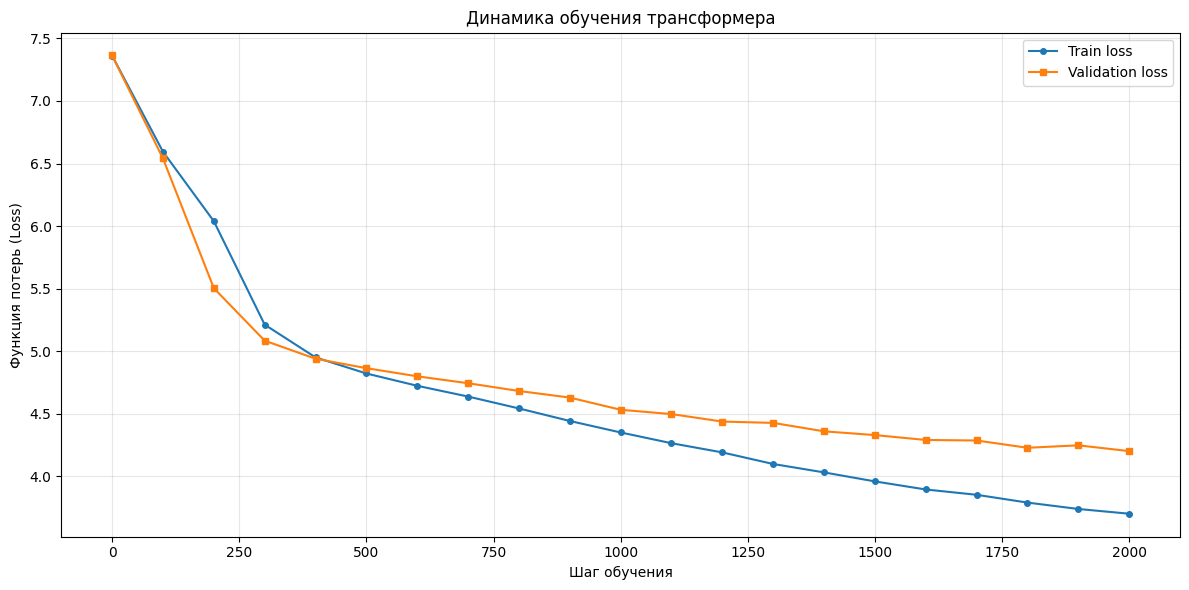


СОХРАНЕНИЕ РЕЗУЛЬТАТОВ
samples.json существует: True
train_curve.csv существует: True
График сохранён: True
Путь: /content/drive/MyDrive/Лабораторная2_Попова_МТИ2532/artifacts/train_curve.png

ЗАДАНИЕ №4. ОБРАЗЦЫ ПО ШАГАМ — ВЫПОЛНЕНО


In [6]:
# Проверка образцов и построение графика обучения

import json
import csv
import matplotlib.pyplot as plt
from pathlib import Path

artifacts_path = Path(
    "/content/drive/MyDrive/"
    "Лабораторная2_Попова_МТИ2532/artifacts"
)

samples_path = artifacts_path / "samples.json"
curve_path = artifacts_path / "train_curve.csv"

with open(samples_path, encoding="utf-8") as f:
    samples_data = json.load(f)

prompt = samples_data["prompt"]
temperature = samples_data["temperature"]
samples = samples_data["samples"]

print("ОБРАЗЦЫ ГЕНЕРАЦИИ ПО ШАГАМ")
print("=" * 60)

print("Затравка:", prompt)
print("Температура:", temperature)
print("Количество образцов:", len(samples))

for sample in samples:
    print("\n" + "=" * 60)
    print("Шаг обучения:", sample["step"])
    print("Сгенерированный текст:")
    print(sample["text"])

# Проверка образцов

steps_correct = (
    [s["step"] for s in samples] == [0, 100, 500, 2000]
)

prompt_correct = prompt == "князь андрей"

temperature_correct = temperature == 0.8

all_start_correct = all(
    s["text"].startswith(prompt)
    for s in samples
)

all_nonempty = all(
    s["text"][len(prompt):].strip()
    for s in samples
)

samples_different = (
    samples[0]["text"] != samples[-1]["text"]
)

print("\nИТОГОВАЯ ПРОВЕРКА ОБРАЗЦОВ")
print("=" * 60)

print("Количество образцов корректно:", len(samples) == 4)
print("Шаги корректны:", steps_correct)
print("Затравка корректна:", prompt_correct)
print("Температура корректна:", temperature_correct)
print("Все образцы начинаются с затравки:", all_start_correct)
print("Все продолжения непустые:", all_nonempty)
print("Последний образец отличается от первого:",
      samples_different)

assert len(samples) == 4
assert steps_correct
assert prompt_correct
assert temperature_correct
assert all_start_correct
assert all_nonempty
assert samples_different

# Загрузка истории обучения

with open(curve_path, encoding="utf-8") as f:
    history = list(csv.DictReader(f))

steps = [int(row["step"]) for row in history]
train_losses = [float(row["train_loss"]) for row in history]
val_losses = [float(row["val_loss"]) for row in history]

# Построение графика

plt.figure(figsize=(12, 6))

plt.plot(
    steps,
    train_losses,
    marker="o",
    markersize=4,
    label="Train loss"
)

plt.plot(
    steps,
    val_losses,
    marker="s",
    markersize=4,
    label="Validation loss"
)

plt.xlabel("Шаг обучения")
plt.ylabel("Функция потерь (Loss)")
plt.title("Динамика обучения трансформера")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

graph_path = artifacts_path / "train_curve.png"

plt.savefig(graph_path, dpi=200)
plt.show()

print("\nСОХРАНЕНИЕ РЕЗУЛЬТАТОВ")
print("=" * 60)

print("samples.json существует:", samples_path.is_file())
print("train_curve.csv существует:", curve_path.is_file())
print("График сохранён:", graph_path.is_file())
print("Путь:", graph_path)

print("\nЗАДАНИЕ №4. ОБРАЗЦЫ ПО ШАГАМ — ВЫПОЛНЕНО")

5. Генерация руками.

In [7]:
# Генерация в четырёх режимах и поиск зацикливания

import json
import torch
import torch.nn.functional as F
from pathlib import Path

BASE_DIR = Path(
    "/content/drive/MyDrive/"
    "Лабораторная2_Попова_МТИ2532"
)

ARTIFACTS_DIR = BASE_DIR / "artifacts"
DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Восстановление конфигурации модели

with open(
    BASE_DIR / "scripts/model_config.json",
    encoding="utf-8"
) as f:
    cfg = json.load(f)

trained_model = TinyTransformer(
    vocab_size=cfg["vocab_size"],
    d_model=cfg["d_model"],
    n_layers=cfg["n_layers"],
    n_heads=cfg["n_heads"],
    d_ff=cfg["d_ff"],
    context=cfg["context"]
).to(DEVICE)

# Загрузка весов после полного обучения

checkpoint_path = BASE_DIR / "checkpoints/full/latest.pt"

checkpoint = torch.load(
    checkpoint_path,
    map_location=DEVICE,
    weights_only=False
)

# Поиск сохранённого словаря весов

expected_keys = set(trained_model.state_dict())

candidates = [checkpoint]

if isinstance(checkpoint, dict):
    candidates.extend(checkpoint.values())

state_dict = next(
    (
        item for item in candidates
        if isinstance(item, dict)
        and set(item) == expected_keys
    ),
    None
)

assert state_dict is not None, "Веса модели не найдены"

trained_model.load_state_dict(state_dict)
trained_model.eval()

print("ВОССТАНОВЛЕНИЕ ОБУЧЕННОЙ МОДЕЛИ")
print("=" * 60)
print("Устройство:", DEVICE)
print("Количество параметров:",
      sum(p.numel() for p in trained_model.parameters()))
print("Контрольная точка:", checkpoint_path)
print("Модель успешно восстановлена")

# Самостоятельная реализация генерации

@torch.no_grad()
def generate(
    prompt,
    max_new_tokens,
    temperature=1.0,
    top_p=None,
    seed=42
):
    prompt_ids = list(encode_text(prompt))

    assert len(prompt_ids) > 0
    assert temperature >= 0

    if top_p is not None:
        assert 0 < top_p <= 1

    ids = torch.tensor(
        [prompt_ids],
        dtype=torch.long,
        device=DEVICE
    )

    generator = torch.Generator(device=DEVICE)
    generator.manual_seed(seed)

    new_ids = []

    for _ in range(max_new_tokens):

        # Ограничиваем длину контекста

        x = ids[:, -cfg["context"]:]

        output = trained_model(x)

        if isinstance(output, tuple):
            output = output[0]

        logits = output[:, -1, :]

        # Жадный выбор

        if temperature == 0:

            next_id = torch.argmax(
                logits,
                dim=-1,
                keepdim=True
            )

        else:

            # Применение температуры

            logits = logits / temperature

            # Фильтрация top-p

            if top_p is not None:

                sorted_logits, sorted_indices = torch.sort(
                    logits,
                    descending=True,
                    dim=-1
                )

                sorted_probs = F.softmax(
                    sorted_logits,
                    dim=-1
                )

                cumulative_probs = torch.cumsum(
                    sorted_probs,
                    dim=-1
                )

                remove = cumulative_probs > top_p

                remove[..., 1:] = remove[..., :-1].clone()
                remove[..., 0] = False

                sorted_logits = sorted_logits.masked_fill(
                    remove,
                    float("-inf")
                )

                probs = F.softmax(
                    sorted_logits,
                    dim=-1
                )

                selected = torch.multinomial(
                    probs,
                    num_samples=1,
                    generator=generator
                )

                next_id = sorted_indices.gather(
                    -1,
                    selected
                )

            else:

                probs = F.softmax(logits, dim=-1)

                next_id = torch.multinomial(
                    probs,
                    num_samples=1,
                    generator=generator
                )

        new_ids.append(int(next_id.item()))

        ids = torch.cat(
            [ids, next_id],
            dim=1
        )

    text = decode_ids(prompt_ids + new_ids)

    return text, new_ids

# Поиск первой повторяющейся четвёрки токенов

def find_loop_start(ids):

    seen = set()

    for i in range(len(ids) - 3):

        fragment = tuple(ids[i:i + 4])

        if fragment in seen:
            return i

        seen.add(fragment)

    return None

# Проверка функции поиска зацикливания

assert find_loop_start(
    [1, 2, 3, 4, 1, 2, 3, 4]
) == 4

assert find_loop_start(
    [1, 2, 3, 4, 5, 6, 7, 8]
) is None

# Параметры эксперимента

prompt = "князь андрей"
max_new_tokens = 80

modes = [
    ("greedy", 0.0, None),
    ("t0.7", 0.7, None),
    ("t1.5", 1.5, None),
    ("top_p0.9", 1.0, 0.9)
]

runs = []

print("\nГЕНЕРАЦИЯ В ЧЕТЫРЁХ РЕЖИМАХ")
print("=" * 60)

for name, temperature, top_p in modes:

    text, ids = generate(
        prompt,
        max_new_tokens,
        temperature=temperature,
        top_p=top_p,
        seed=42
    )

    loop_start = (
        find_loop_start(ids)
        if name == "greedy"
        else None
    )

    result = {
        "name": name,
        "temperature": temperature,
        "top_p": top_p,
        "text": text,
        "ids": ids,
        "n_tokens": len(ids),
        "loop_start": loop_start
    }

    runs.append(result)

    print("\n" + "=" * 60)
    print("Режим:", name)
    print("Температура:", temperature)
    print("Top-p:", top_p)
    print("Количество новых токенов:", len(ids))

    print("\nСгенерированный текст:")
    print(text)

    print("\nИдентификаторы токенов:")
    print(ids)

    if name == "greedy":

        print("\nНачало зацикливания:", loop_start)

        if loop_start is not None:
            fragment = ids[loop_start:loop_start + 4]

            print("Повторяющиеся токены:", fragment)
            print("Повторяющийся фрагмент:",
                  decode_ids(fragment))
        else:
            print("Зацикливание не обнаружено")

# Формирование итогового артефакта

generation_data = {
    "model": "tiny",
    "prompt": prompt,
    "max_new_tokens": max_new_tokens,
    "runs": runs
}

# Проверка результатов

modes_correct = (
    [r["name"] for r in runs] ==
    ["greedy", "t0.7", "t1.5", "top_p0.9"]
)

length_correct = all(
    r["n_tokens"] == len(r["ids"]) == 80
    for r in runs
)

ids_correct = all(
    0 <= token_id < cfg["vocab_size"]
    for r in runs
    for token_id in r["ids"]
)

prompts_correct = all(
    r["text"].startswith(prompt)
    for r in runs
)

loops_correct = (
    runs[0]["loop_start"] ==
    find_loop_start(runs[0]["ids"])
)

greedy_text, greedy_ids = generate(
    prompt,
    max_new_tokens,
    temperature=0
)

greedy_reproducible = (
    greedy_ids == runs[0]["ids"]
)

print("\nИТОГОВАЯ ПРОВЕРКА")
print("=" * 60)

print("Количество режимов корректно:", len(runs) == 4)
print("Названия режимов корректны:", modes_correct)
print("Количество токенов корректно:", length_correct)
print("Идентификаторы корректны:", ids_correct)
print("Затравка сохранена:", prompts_correct)
print("Поиск зацикливания корректен:", loops_correct)
print("Жадная генерация воспроизводима:",
      greedy_reproducible)

assert len(runs) == 4
assert modes_correct
assert length_correct
assert ids_correct
assert prompts_correct
assert loops_correct
assert greedy_reproducible

# Сохранение на Google Диск

ARTIFACTS_DIR.mkdir(parents=True, exist_ok=True)

generation_path = ARTIFACTS_DIR / "generation.json"

with open(generation_path, "w", encoding="utf-8") as f:
    json.dump(
        generation_data,
        f,
        ensure_ascii=False,
        indent=2
    )

with open(generation_path, encoding="utf-8") as f:
    restored_generation = json.load(f)

assert restored_generation == generation_data

print("\nСОХРАНЕНИЕ")
print("=" * 60)
print("generation.json сохранён:", generation_path.is_file())
print("Размер файла:", generation_path.stat().st_size, "байт")
print("Проверка восстановления:",
      restored_generation == generation_data)
print("Путь:", generation_path)

print("\nЗАДАНИЕ №5. ГЕНЕРАЦИЯ РУКАМИ — ВЫПОЛНЕНО")

ВОССТАНОВЛЕНИЕ ОБУЧЕННОЙ МОДЕЛИ
Устройство: cuda
Количество параметров: 1203966
Контрольная точка: /content/drive/MyDrive/Лабораторная2_Попова_МТИ2532/checkpoints/full/latest.pt
Модель успешно восстановлена

ГЕНЕРАЦИЯ В ЧЕТЫРЁХ РЕЖИМАХ

Режим: greedy
Температура: 0.0
Top-p: None
Количество новых токенов: 80

Сгенерированный текст:
князь андрей был в том что он был в том что он не мог уехать в москву в москве не было в силах кампании и что он не мог уехать в москву ему надо было уехать но он не мог уехать но ему было в москве но он не мог уехать в москву ему было в силах было бы он ни разве не мог уехать но он не мог не

Идентификаторы токенов:
[97, 105, 1336, 1450, 914, 97, 105, 1336, 1450, 914, 811, 752, 1363, 453, 105, 769, 105, 768, 811, 100, 105, 1152, 45, 572, 712, 953, 833, 517, 1450, 914, 811, 752, 1363, 453, 105, 769, 431, 786, 100, 1363, 453, 850, 914, 811, 752, 1363, 453, 850, 431, 100, 105, 768, 850, 914, 811, 752, 1363, 453, 105, 769, 431, 100, 105, 1152, 45, 100, 95, 914, 

6. Счётчики против трансформера.

Подготовка проверочного текста и модели из лабораторной №1.

In [8]:
# Подготовка данных для сравнения моделей

import re
import ast
import torch
from pathlib import Path

BASE_DIR = Path(
    "/content/drive/MyDrive/"
    "Лабораторная2_Попова_МТИ2532"
)

# Восстановление корпуса

corpus = (BASE_DIR / "data/corpus.txt").read_text(
    encoding="utf-8"
)

words = re.findall(
    r"[а-я]+(?:-[а-я]+)*",
    corpus.lower().replace("ё", "е")
)

split = int(len(words) * 0.9)

train_words = words[:split]
val_words = words[split:]

# Первые 2000 проверочных слов

eval_words = val_words[:2000]
eval_text = " ".join(eval_words)
eval_ids = list(encode_text(eval_text))

# Проверка соответствия сохранённым данным

saved_val_ids = torch.load(
    BASE_DIR / "data/val_ids.pt",
    map_location="cpu",
    weights_only=True
)

tokens_match = (
    eval_ids ==
    saved_val_ids[:len(eval_ids)].tolist()
)

print("ДАННЫЕ ДЛЯ СРАВНЕНИЯ")
print("=" * 60)

print("Обучающих слов:", len(train_words))
print("Проверочных слов:", len(val_words))
print("Слов для сравнения:", len(eval_words))
print("BPE-токенов для сравнения:", len(eval_ids))
print("Коэффициент сглаживания:", 0.01)

print("\nНачало проверочного текста:")
print(" ".join(eval_words[:30]))

print("\nПРОВЕРКА")
print("=" * 60)

print("Количество слов корректно:",
      len(eval_words) == 2000)

print("Токены совпадают:", tokens_match)

assert len(train_words) == 389773
assert len(val_words) == 43309
assert len(eval_words) == 2000
assert tokens_match

# Поиск репозитория с первой лабораторной

candidates = (
    list(Path("/content").glob("*/pt01/run.py"))
    + list(Path("/content").glob("*/*/pt01/run.py"))
    + [Path("/content/pt01/run.py")]
)

bigram_path = next(
    (p for p in candidates if p.is_file()),
    None
)

print("\nМОДЕЛЬ ИЗ ЛАБОРАТОРНОЙ №1")
print("=" * 60)

if bigram_path is not None:

    print("Файл найден:", bigram_path)

    source = bigram_path.read_text(encoding="utf-8")
    tree = ast.parse(source)

    for node in tree.body:

        if isinstance(node, ast.ClassDef):
            if "bigram" in node.name.lower():
                print(ast.get_source_segment(source, node))

        elif isinstance(node, ast.FunctionDef):
            if any(
                key in node.name.lower()
                for key in [
                    "bigram",
                    "likelihood",
                    "perplexity",
                    "probability"
                ]
            ):
                print(ast.get_source_segment(source, node))

    # Проверка требований автотестов

    test_path = (
        bigram_path.parent.parent
        / "tests/test_pt02.py"
    )

    print("\nТРЕБОВАНИЯ АВТОТЕСТОВ")
    print("=" * 60)

    if test_path.is_file():

        test_source = test_path.read_text(
            encoding="utf-8"
        )

        for node in ast.parse(test_source).body:

            if isinstance(node, ast.FunctionDef):

                code = ast.get_source_segment(
                    test_source, node
                )

                if (
                    "eval" in node.name.lower()
                    or "nats_per_word" in code
                ):
                    print(code)

else:
    print("Репозиторий необходимо восстановить")

print("\nПодготовка данных для сравнения завершена")

ДАННЫЕ ДЛЯ СРАВНЕНИЯ
Обучающих слов: 389773
Проверочных слов: 43309
Слов для сравнения: 2000
BPE-токенов для сравнения: 3666
Коэффициент сглаживания: 0.01

Начало проверочного текста:
это был георгий й степени на другой день были у фельдмаршала обед и бал которые государь удостоил своим присутствием кутузову пожалован георгий й степени государь оказывал ему высочайшие почести но

ПРОВЕРКА
Количество слов корректно: True
Токены совпадают: True

МОДЕЛЬ ИЗ ЛАБОРАТОРНОЙ №1
Репозиторий необходимо восстановить

Подготовка данных для сравнения завершена


Восстановление репозитория.

In [9]:
# Восстановление репозитория

import subprocess
from pathlib import Path

REPO_URL = (
    "https://github.com/Vitalina6848/"
    "tgo-course_Popova_MTI2532.git"
)

REPO_DIR = Path("/content/tgo-course_Popova_MTI2532")

if not REPO_DIR.exists():
    subprocess.run(
        ["git", "clone", REPO_URL, str(REPO_DIR)],
        check=True
    )

bigram_path = REPO_DIR / "pt01/run.py"
test_path = REPO_DIR / "tests/test_pt02.py"

print("ВОССТАНОВЛЕНИЕ РЕПОЗИТОРИЯ")
print("=" * 60)

print("Репозиторий доступен:", REPO_DIR.is_dir())
print("Код первой лабораторной:", bigram_path.is_file())
print("Автотесты второй лабораторной:", test_path.is_file())

assert bigram_path.is_file()
assert test_path.is_file()

print("\nРЕАЛИЗАЦИЯ БИГРАММНОЙ МОДЕЛИ")
print("=" * 60)

import ast

source = bigram_path.read_text(encoding="utf-8")

for node in ast.parse(source).body:
    if isinstance(node, (ast.ClassDef, ast.FunctionDef)):
        if any(key in node.name.lower() for key in [
            "bigram",
            "likelihood",
            "perplexity",
            "probability"
        ]):
            print(ast.get_source_segment(source, node))

print("\nТРЕБОВАНИЯ АВТОТЕСТОВ")
print("=" * 60)

test_source = test_path.read_text(encoding="utf-8")

for node in ast.parse(test_source).body:
    if isinstance(node, ast.FunctionDef):
        code = ast.get_source_segment(test_source, node)

        if "eval" in node.name.lower() or "nats_per_word" in code:
            print(code)

print("\nРепозиторий успешно восстановлен")

ВОССТАНОВЛЕНИЕ РЕПОЗИТОРИЯ
Репозиторий доступен: True
Код первой лабораторной: True
Автотесты второй лабораторной: True

РЕАЛИЗАЦИЯ БИГРАММНОЙ МОДЕЛИ
class BigramModel:
    # Инициализация модели
    def __init__(self, alpha=0.01):
        self.alpha = alpha
    # Обучение модели
    def fit(self, words):
        self.word_counts = Counter(words)
        self.bigram_counts = Counter(zip(words, words[1:]))
        self.context_counts = Counter(words[:-1])

        self.vocab = sorted(self.word_counts)
        self.vocab_size = len(self.vocab)

        # Возможные продолжения каждого слова
        self.followers = defaultdict(Counter)

        for (v, w), count in self.bigram_counts.items():
            self.followers[v][w] = count

        return self

    # Вероятность со сглаживанием Лапласа
    def prob(self, v, w):
        pair_count = self.bigram_counts.get((v, w), 0)
        context_count = self.context_counts.get(v, 0)

        # Дополнительная категория для неизвестных слов
    

Расчёт метрик биграммной модели.

In [10]:
# Расчёт метрик биграммной модели

import importlib.util
import math
import json
import re
import time
from pathlib import Path

# Загрузка модели из лабораторной №1
spec = importlib.util.spec_from_file_location(
    "pt01_model",
    REPO_DIR / "pt01/run.py"
)

pt01_model = importlib.util.module_from_spec(spec)
spec.loader.exec_module(pt01_model)

# Восстановление исходного корпуса
work_dir = Path(
    "/content/drive/MyDrive/Лабораторная2_Попова_МТИ2532"
)

raw_text = (work_dir / "data/corpus.txt").read_text(
    encoding="utf-8"
)

all_words = re.findall(
    r"[а-я]+(?:-[а-я]+)*",
    raw_text.lower().replace("ё", "е")
)

split_idx = int(len(all_words) * 0.9)

train_words = all_words[:split_idx]
val_words = all_words[split_idx:]
eval_words = val_words[:2000]

assert len(train_words) == 389773
assert len(val_words) == 43309
assert len(eval_words) == 2000

# Обучение биграммной модели
alpha = 0.01

start_time = time.perf_counter()

bigram_model = pt01_model.BigramModel(
    alpha=alpha
).fit(train_words)

elapsed = time.perf_counter() - start_time

print("БИГРАММНАЯ МОДЕЛЬ")
print("=" * 60)

print("Обучающих слов:", len(train_words))
print("Размер словаря:", bigram_model.vocab_size)
print("Уникальных биграмм:",
      len(bigram_model.bigram_counts))
print("Коэффициент сглаживания:", alpha)
print("Время обучения (сек.):", round(elapsed, 4))

# Расчёт метрик
bigram_logprob = bigram_model.logprob(eval_words)

bigram_nats_total = -bigram_logprob
bigram_nats_per_word = (
    bigram_nats_total / len(eval_words)
)

bigram_ppl_per_word = math.exp(
    bigram_nats_per_word
)

bigram_result = {
    "tokens": len(eval_words) - 1,
    "nats_total": bigram_nats_total,
    "nats_per_word": bigram_nats_per_word,
    "ppl_per_word": bigram_ppl_per_word,
    "alpha": alpha
}

print("\nРЕЗУЛЬТАТЫ ОЦЕНКИ")
print("=" * 60)

print("Слов для сравнения:", len(eval_words))
print("Оценённых слов:", bigram_result["tokens"])
print("Log probability:", round(bigram_logprob, 6))
print("Nats total:", round(bigram_nats_total, 6))
print("Nats per word:", round(bigram_nats_per_word, 6))
print("Perplexity per word:", round(bigram_ppl_per_word, 6))

# Проверка результатов
nats_correct = math.isclose(
    bigram_result["nats_per_word"],
    bigram_result["nats_total"] / len(eval_words)
)

ppl_correct = math.isclose(
    bigram_result["ppl_per_word"],
    math.exp(bigram_result["nats_per_word"])
)

finite_correct = all(
    math.isfinite(value)
    for value in bigram_result.values()
)

print("\nИТОГОВАЯ ПРОВЕРКА")
print("=" * 60)

print("Количество слов корректно:",
      len(eval_words) == 2000)
print("Коэффициент сглаживания корректен:",
      alpha == 0.01)
print("Размер словаря совпадает с ЛР №1:",
      bigram_model.vocab_size == 45309)
print("Nats per word рассчитан корректно:",
      nats_correct)
print("Перплексия рассчитана корректно:",
      ppl_correct)
print("Нет NaN и Inf:", finite_correct)

assert nats_correct
assert ppl_correct
assert finite_correct

# Сохранение промежуточного результата
save_path = work_dir / "checkpoints/bigram_eval.json"

with open(save_path, "w", encoding="utf-8") as f:
    json.dump(
        bigram_result,
        f,
        ensure_ascii=False,
        indent=2
    )

print("\nСОХРАНЕНИЕ")
print("=" * 60)
print("Результат сохранён:", save_path.is_file())
print("Путь:", save_path)

print("\nОценка биграммной модели завершена")

БИГРАММНАЯ МОДЕЛЬ
Обучающих слов: 389773
Размер словаря: 45309
Уникальных биграмм: 236820
Коэффициент сглаживания: 0.01
Время обучения (сек.): 0.5635

РЕЗУЛЬТАТЫ ОЦЕНКИ
Слов для сравнения: 2000
Оценённых слов: 1999
Log probability: -16308.247168
Nats total: 16308.247168
Nats per word: 8.154124
Perplexity per word: 3477.690087

ИТОГОВАЯ ПРОВЕРКА
Количество слов корректно: True
Коэффициент сглаживания корректен: True
Размер словаря совпадает с ЛР №1: True
Nats per word рассчитан корректно: True
Перплексия рассчитана корректно: True
Нет NaN и Inf: True

СОХРАНЕНИЕ
Результат сохранён: True
Путь: /content/drive/MyDrive/Лабораторная2_Попова_МТИ2532/checkpoints/bigram_eval.json

Оценка биграммной модели завершена


Расчёт метрик собственного трансформера.

In [11]:
# Расчёт метрик собственного трансформера

import torch
import torch.nn.functional as F
import math
import json
import time
import importlib.util
from pathlib import Path

work_dir = Path(
    "/content/drive/MyDrive/Лабораторная2_Попова_МТИ2532"
)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Загрузка конфигурации модели
with open(
    work_dir / "scripts/model_config.json",
    encoding="utf-8"
) as f:
    cfg = json.load(f)

# Восстановление архитектуры
spec = importlib.util.spec_from_file_location(
    "tiny_model_module",
    work_dir / "scripts/model.py"
)

model_module = importlib.util.module_from_spec(spec)
spec.loader.exec_module(model_module)

tiny_eval_model = model_module.TinyTransformer(
    vocab_size=cfg["vocab_size"],
    d_model=cfg["d_model"],
    n_layers=cfg["n_layers"],
    n_heads=cfg["n_heads"],
    d_ff=cfg["d_ff"],
    context=cfg["context"]
)

# Восстановление обученных весов
checkpoint_path = (
    work_dir / "checkpoints/full/latest.pt"
)

# Загружаем собственную контрольную точку
checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=False
)

expected_keys = set(
    tiny_eval_model.state_dict().keys()
)

state_dict = None

for candidate in [checkpoint, *checkpoint.values()]:
    if isinstance(candidate, dict):
        if expected_keys.issubset(candidate.keys()):
            state_dict = candidate
            break

assert state_dict is not None, (
    "Веса модели не найдены"
)

tiny_eval_model.load_state_dict(state_dict)
tiny_eval_model.to(device)
tiny_eval_model.eval()

print("ВОССТАНОВЛЕНИЕ ТРАНСФОРМЕРА")
print("=" * 60)

print("Устройство:", device)
print("Контрольная точка:", checkpoint_path)

print("Количество параметров:",
      sum(p.numel()
          for p in tiny_eval_model.parameters()))

print("Модель успешно восстановлена")

# Загрузка проверочной выборки
validation_ids = torch.load(
    work_dir / "data/val_ids.pt",
    map_location="cpu",
    weights_only=True
)

# Первые 2000 слов содержат 3666 BPE-токенов
words_count = 2000
eval_token_count = 3666

eval_ids = validation_ids[
    :eval_token_count
].to(device)

context = cfg["context"]

assert len(eval_ids) == 3666

# Получение логитов модели
def get_logits(x):
    result = tiny_eval_model(x)

    if isinstance(result, tuple):
        return result[0]

    return result

print("\nДАННЫЕ ДЛЯ ОЦЕНКИ")
print("=" * 60)

print("Количество слов:", words_count)
print("Количество BPE-токенов:", len(eval_ids))
print("Длина контекста:", context)

# Расчёт отрицательного логарифма вероятностей
start_time = time.perf_counter()

loss_parts = []
evaluated_tokens = 0

with torch.inference_mode():

    # Первое окно: оцениваем все следующие токены
    first_n = min(context, len(eval_ids) - 1)

    x = eval_ids[:first_n].unsqueeze(0)
    y = eval_ids[1:first_n + 1]

    logits = get_logits(x)

    loss = F.cross_entropy(
        logits[0].float(),
        y,
        reduction="sum"
    )

    loss_parts.append(loss.item())
    evaluated_tokens += first_n

    # Последующие токены:
    # используем до 128 предыдущих токенов
    batch_size = 32

    positions = torch.arange(
        first_n + 1,
        len(eval_ids),
        device=device
    )

    offsets = torch.arange(
        -context, 0,
        device=device
    )

    for batch_positions in positions.split(batch_size):

        indices = (
            batch_positions[:, None]
            + offsets[None, :]
        )

        x = eval_ids[indices]
        y = eval_ids[batch_positions]

        logits = get_logits(x)[:, -1, :]

        loss = F.cross_entropy(
            logits.float(),
            y,
            reduction="sum"
        )

        loss_parts.append(loss.item())
        evaluated_tokens += len(y)

# Итоговые метрики
tiny_nats_total = math.fsum(loss_parts)

tiny_nats_per_word = (
    tiny_nats_total / words_count
)

tiny_ppl_per_word = math.exp(
    tiny_nats_per_word
)

elapsed = time.perf_counter() - start_time

tiny_result = {
    "tokens": evaluated_tokens,
    "nats_total": tiny_nats_total,
    "nats_per_word": tiny_nats_per_word,
    "ppl_per_word": tiny_ppl_per_word
}

# Равновероятный выбор для сравнения
uniform_nats_per_word = (
    math.log(cfg["vocab_size"])
    * evaluated_tokens / words_count
)

print("\nРЕЗУЛЬТАТЫ ОЦЕНКИ ТРАНСФОРМЕРА")
print("=" * 60)

print("Слов для сравнения:", words_count)
print("Оценённых токенов:", evaluated_tokens)

print("Nats total:",
      round(tiny_nats_total, 6))

print("Nats per word:",
      round(tiny_nats_per_word, 6))

print("Perplexity per word:",
      round(tiny_ppl_per_word, 6))

print("Nats per word при равновероятном выборе:",
      round(uniform_nats_per_word, 6))

print("Время оценки (сек.):",
      round(elapsed, 4))

# Проверка результатов
tokens_correct = (
    evaluated_tokens == eval_token_count - 1
)

nats_correct = math.isclose(
    tiny_nats_per_word,
    tiny_nats_total / words_count
)

ppl_correct = math.isclose(
    tiny_ppl_per_word,
    math.exp(tiny_nats_per_word)
)

better_than_uniform = (
    tiny_nats_per_word < uniform_nats_per_word
)

finite_correct = all(
    math.isfinite(value)
    for value in tiny_result.values()
)

print("\nИТОГОВАЯ ПРОВЕРКА")
print("=" * 60)

print("Количество слов корректно:",
      words_count == 2000)

print("Количество оценённых токенов корректно:",
      tokens_correct)

print("Nats per word рассчитан корректно:",
      nats_correct)

print("Перплексия рассчитана корректно:",
      ppl_correct)

print("Трансформер лучше равновероятного выбора:",
      better_than_uniform)

print("Нет NaN и Inf:", finite_correct)

assert tokens_correct
assert nats_correct
assert ppl_correct
assert better_than_uniform
assert finite_correct

# Сохранение промежуточных результатов
save_path = (
    work_dir / "checkpoints/tiny_eval.json"
)

with open(save_path, "w", encoding="utf-8") as f:
    json.dump(
        tiny_result,
        f,
        ensure_ascii=False,
        indent=2
    )

print("\nСОХРАНЕНИЕ")
print("=" * 60)

print("Результат сохранён:", save_path.is_file())
print("Путь:", save_path)

print("\nОценка трансформера завершена")

ВОССТАНОВЛЕНИЕ ТРАНСФОРМЕРА
Устройство: cuda
Контрольная точка: /content/drive/MyDrive/Лабораторная2_Попова_МТИ2532/checkpoints/full/latest.pt
Количество параметров: 1203966
Модель успешно восстановлена

ДАННЫЕ ДЛЯ ОЦЕНКИ
Количество слов: 2000
Количество BPE-токенов: 3666
Длина контекста: 128

РЕЗУЛЬТАТЫ ОЦЕНКИ ТРАНСФОРМЕРА
Слов для сравнения: 2000
Оценённых токенов: 3665
Nats total: 15046.00465
Nats per word: 7.523002
Perplexity per word: 1850.113606
Nats per word при равновероятном выборе: 13.442549
Время оценки (сек.): 0.8141

ИТОГОВАЯ ПРОВЕРКА
Количество слов корректно: True
Количество оценённых токенов корректно: True
Nats per word рассчитан корректно: True
Перплексия рассчитана корректно: True
Трансформер лучше равновероятного выбора: True
Нет NaN и Inf: True

СОХРАНЕНИЕ
Результат сохранён: True
Путь: /content/drive/MyDrive/Лабораторная2_Попова_МТИ2532/checkpoints/tiny_eval.json

Оценка трансформера завершена


Сравнение моделей и сохранение eval.json

СРАВНЕНИЕ МОДЕЛЕЙ
Количество слов: 2000

Биграммная модель:
Nats per word: 8.154124
Perplexity per word: 3477.690087

Трансформер:
Nats per word: 7.523002
Perplexity per word: 1850.113606

Равновероятный выбор:
Nats per word: 13.442549

ИТОГ СРАВНЕНИЯ
Лучшая модель: Трансформер
Снижение Nats per word (%): 7.74
Снижение перплексии (%): 46.8

ПРОВЕРКА МЕТРИК

Модель: bigram
Количество токенов корректно: True
Nats per word корректен: True
Перплексия корректна: True
Нет NaN и Inf: True

Модель: tiny
Количество токенов корректно: True
Nats per word корректен: True
Перплексия корректна: True
Нет NaN и Inf: True

Коэффициент сглаживания корректен: True
Трансформер лучше равновероятного выбора: True


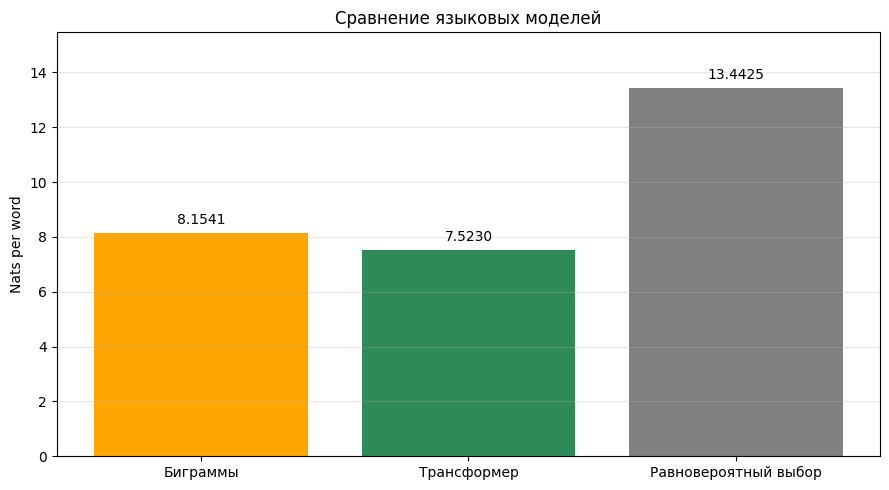

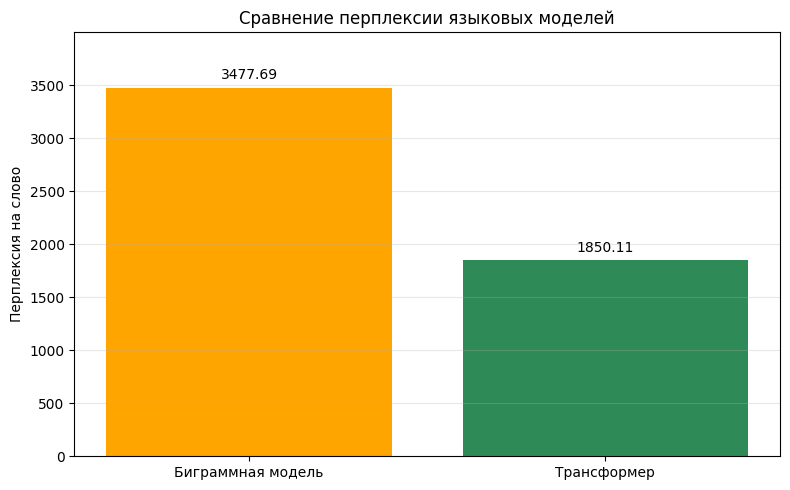


СОДЕРЖИМОЕ eval.json
{
  "words": 2000,
  "bigram": {
    "tokens": 1999,
    "nats_total": 16308.247168449458,
    "nats_per_word": 8.15412358422473,
    "ppl_per_word": 3477.6900868304156,
    "alpha": 0.01
  },
  "tiny": {
    "tokens": 3665,
    "nats_total": 15046.004650115967,
    "nats_per_word": 7.523002325057983,
    "ppl_per_word": 1850.1136064114614
  }
}

СОХРАНЕНИЕ РЕЗУЛЬТАТОВ
eval.json сохранён: True
График Nats сохранён: True
График перплексии сохранён: True
Проверка восстановления: True

Путь: /content/drive/MyDrive/Лабораторная2_Попова_МТИ2532/artifacts

ЗАДАНИЕ №6. СЧЁТЧИКИ ПРОТИВ ТРАНСФОРМЕРА — ВЫПОЛНЕНО


In [12]:
# Сравнение моделей и сохранение eval.json

import json
import math
from pathlib import Path
import matplotlib.pyplot as plt

work_dir = Path(
    "/content/drive/MyDrive/Лабораторная2_Попова_МТИ2532"
)

artifacts_dir = work_dir / "artifacts"
artifacts_dir.mkdir(parents=True, exist_ok=True)

# Загрузка сохранённых результатов
with open(
    work_dir / "checkpoints/bigram_eval.json",
    encoding="utf-8"
) as f:
    bigram = json.load(f)

with open(
    work_dir / "checkpoints/tiny_eval.json",
    encoding="utf-8"
) as f:
    tiny = json.load(f)

# Извлечение метрик, если они вложены в словарь
bigram = bigram.get("bigram", bigram)
tiny = tiny.get("tiny", tiny)

words_count = 2000

# Формирование итогового файла
evaluation = {
    "words": words_count,
    "bigram": {
        "tokens": int(bigram["tokens"]),
        "nats_total": bigram["nats_total"],
        "nats_per_word": bigram["nats_per_word"],
        "ppl_per_word": bigram["ppl_per_word"],
        "alpha": 0.01
    },
    "tiny": {
        "tokens": int(tiny["tokens"]),
        "nats_total": tiny["nats_total"],
        "nats_per_word": tiny["nats_per_word"],
        "ppl_per_word": tiny["ppl_per_word"]
    }
}

# Сравнение результатов
bigram_nats = evaluation["bigram"]["nats_per_word"]
tiny_nats = evaluation["tiny"]["nats_per_word"]

bigram_ppl = evaluation["bigram"]["ppl_per_word"]
tiny_ppl = evaluation["tiny"]["ppl_per_word"]

nats_improvement = (
    (bigram_nats - tiny_nats) / bigram_nats * 100
)

ppl_improvement = (
    (bigram_ppl - tiny_ppl) / bigram_ppl * 100
)

uniform_nats = (
    math.log(1534)
    * evaluation["tiny"]["tokens"]
    / words_count
)

winner = (
    "Трансформер"
    if tiny_nats < bigram_nats
    else "Биграммная модель"
    if bigram_nats < tiny_nats
    else "Одинаковый результат"
)

print("СРАВНЕНИЕ МОДЕЛЕЙ")
print("=" * 60)

print("Количество слов:", words_count)

print("\nБиграммная модель:")
print("Nats per word:", round(bigram_nats, 6))
print("Perplexity per word:", round(bigram_ppl, 6))

print("\nТрансформер:")
print("Nats per word:", round(tiny_nats, 6))
print("Perplexity per word:", round(tiny_ppl, 6))

print("\nРавновероятный выбор:")
print("Nats per word:", round(uniform_nats, 6))

print("\nИТОГ СРАВНЕНИЯ")
print("=" * 60)

print("Лучшая модель:", winner)
print("Снижение Nats per word (%):",
      round(nats_improvement, 2))

print("Снижение перплексии (%):",
      round(ppl_improvement, 2))

# Проверки согласно требованиям автотестов
print("\nПРОВЕРКА МЕТРИК")
print("=" * 60)

assert evaluation["words"] == 2000

for name in ["bigram", "tiny"]:

    result = evaluation[name]

    tokens_correct = result["tokens"] > 0

    nats_correct = math.isclose(
        result["nats_per_word"],
        result["nats_total"] / words_count,
        rel_tol=1e-3
    )

    ppl_correct = math.isclose(
        result["ppl_per_word"],
        math.exp(result["nats_per_word"]),
        rel_tol=1e-2
    )

    finite_correct = all(
        math.isfinite(value)
        for value in result.values()
    )

    print("\nМодель:", name)
    print("Количество токенов корректно:", tokens_correct)
    print("Nats per word корректен:", nats_correct)
    print("Перплексия корректна:", ppl_correct)
    print("Нет NaN и Inf:", finite_correct)

    assert tokens_correct
    assert nats_correct
    assert ppl_correct
    assert finite_correct

alpha_correct = math.isclose(
    evaluation["bigram"]["alpha"], 0.01
)

better_than_uniform = tiny_nats < uniform_nats

print("\nКоэффициент сглаживания корректен:",
      alpha_correct)

print("Трансформер лучше равновероятного выбора:",
      better_than_uniform)

assert alpha_correct
assert better_than_uniform

# Сохранение обязательного артефакта
eval_path = artifacts_dir / "eval.json"

with open(eval_path, "w", encoding="utf-8") as f:
    json.dump(
        evaluation,
        f,
        ensure_ascii=False,
        indent=2
    )

# График сравнения Nats per word
plt.figure(figsize=(9, 5))

bars = plt.bar(
    ["Биграммы", "Трансформер", "Равновероятный выбор"],
    [bigram_nats, tiny_nats, uniform_nats],
    color=["orange", "seagreen", "gray"]
)

plt.bar_label(bars, fmt="%.4f", padding=4)

plt.ylabel("Nats per word")
plt.title("Сравнение языковых моделей")
plt.ylim(0, uniform_nats * 1.15)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

nats_graph = artifacts_dir / "eval_nats.png"

plt.savefig(nats_graph, dpi=150)
plt.show()
plt.close()

# График сравнения перплексии
plt.figure(figsize=(8, 5))

bars = plt.bar(
    ["Биграммная модель", "Трансформер"],
    [bigram_ppl, tiny_ppl],
    color=["orange", "seagreen"]
)

plt.bar_label(bars, fmt="%.2f", padding=4)

plt.ylabel("Перплексия на слово")
plt.title("Сравнение перплексии языковых моделей")
plt.ylim(0, max(bigram_ppl, tiny_ppl) * 1.15)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

ppl_graph = artifacts_dir / "eval_perplexity.png"

plt.savefig(ppl_graph, dpi=150)
plt.show()
plt.close()

# Проверка сохранения
with open(eval_path, encoding="utf-8") as f:
    restored = json.load(f)

assert restored == evaluation

print("\nСОДЕРЖИМОЕ eval.json")
print("=" * 60)

print(json.dumps(
    evaluation,
    ensure_ascii=False,
    indent=2
))

print("\nСОХРАНЕНИЕ РЕЗУЛЬТАТОВ")
print("=" * 60)

print("eval.json сохранён:", eval_path.is_file())
print("График Nats сохранён:", nats_graph.is_file())
print("График перплексии сохранён:", ppl_graph.is_file())
print("Проверка восстановления:", restored == evaluation)

print("\nПуть:", artifacts_dir)

print("\nЗАДАНИЕ №6. СЧЁТЧИКИ ПРОТИВ ТРАНСФОРМЕРА — ВЫПОЛНЕНО")

Бонус №1. Третья точка.

Загрузка модели Qwen.

In [13]:
# Загрузка предобученной модели Qwen

import torch
import transformers
from pathlib import Path
from huggingface_hub import snapshot_download
from transformers import AutoTokenizer, AutoModelForCausalLM

WORK_DIR = Path(
    "/content/drive/MyDrive/Лабораторная2_Попова_МТИ2532"
)

QWEN_NAME = "Qwen/Qwen3-0.6B-Base"
QWEN_DIR = WORK_DIR / "checkpoints" / "qwen_model"

QWEN_DIR.mkdir(parents=True, exist_ok=True)

print("ПРОВЕРКА СРЕДЫ")
print("=" * 60)

print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("CUDA доступна:", torch.cuda.is_available())

qwen_device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

qwen_dtype = (
    torch.float16
    if qwen_device.type == "cuda"
    else torch.float32
)

if torch.cuda.is_available():
    torch.cuda.empty_cache()
    print("Видеокарта:", torch.cuda.get_device_name(0))

print("\nЗАГРУЗКА МОДЕЛИ")
print("=" * 60)

print("Модель:", QWEN_NAME)
print("Папка сохранения:", QWEN_DIR)

snapshot_download(
    repo_id=QWEN_NAME,
    local_dir=str(QWEN_DIR),
    allow_patterns=[
        "*.json",
        "*.safetensors",
        "*.txt",
        "*.model",
        "*.jinja"
    ]
)

print("\nФайлы модели сохранены на Google Диске")

# Загрузка собственного токенизатора Qwen
qwen_tokenizer = AutoTokenizer.from_pretrained(
    str(QWEN_DIR),
    local_files_only=True
)

# Загрузка предобученной модели
qwen_model = AutoModelForCausalLM.from_pretrained(
    str(QWEN_DIR),
    torch_dtype=qwen_dtype,
    local_files_only=True
).to(qwen_device)

qwen_model.eval()

qwen_params = sum(
    p.numel() for p in qwen_model.parameters()
)

print("\nПАРАМЕТРЫ МОДЕЛИ")
print("=" * 60)

print("Название:", QWEN_NAME)
print("Устройство:", next(qwen_model.parameters()).device)
print("Тип данных:", next(qwen_model.parameters()).dtype)
print("Количество параметров:", qwen_params)
print("Размер словаря:", qwen_model.config.vocab_size)
print("Количество слоёв:", qwen_model.config.num_hidden_layers)
print("Ширина модели:", qwen_model.config.hidden_size)
print("Количество голов внимания:",
      qwen_model.config.num_attention_heads)

# Проверка токенизации
test_text = "князь андрей вошел в комнату"

qwen_test_ids = qwen_tokenizer.encode(
    test_text,
    add_special_tokens=False
)

restored_text = qwen_tokenizer.decode(qwen_test_ids)

print("\nПРОВЕРКА ТОКЕНИЗАТОРА")
print("=" * 60)

print("Исходный текст:", test_text)
print("Идентификаторы:", qwen_test_ids)
print("Количество токенов:", len(qwen_test_ids))
print("Восстановленный текст:", restored_text)

# Проверка прямого прохода
qwen_input = torch.tensor(
    [qwen_test_ids],
    dtype=torch.long,
    device=qwen_device
)

with torch.inference_mode():
    qwen_logits = qwen_model(
        input_ids=qwen_input,
        use_cache=False
    ).logits

finite_correct = bool(
    torch.isfinite(qwen_logits).all().item()
)

print("\nПРОВЕРКА МОДЕЛИ")
print("=" * 60)

print("Размер входа:", qwen_input.shape)
print("Размер логитов:", qwen_logits.shape)
print("Модель загружена:", True)
print("Токенизатор работает:",
      restored_text == test_text)
print("Нет NaN и Inf:", finite_correct)
print("Веса сохранены на Google Диске:",
      any(QWEN_DIR.glob("*.safetensors")))

assert restored_text == test_text
assert finite_correct
assert qwen_logits.shape[-1] == qwen_model.config.vocab_size

del qwen_logits

if torch.cuda.is_available():
    print("\nИспользуется видеопамяти (ГБ):",
          round(torch.cuda.memory_allocated() / 1024**3, 3))

print("\nЗагрузка Qwen успешно завершена")

ПРОВЕРКА СРЕДЫ
PyTorch: 2.11.0+cu130
Transformers: 5.20.2
CUDA доступна: True
Видеокарта: Tesla T4

ЗАГРУЗКА МОДЕЛИ
Модель: Qwen/Qwen3-0.6B-Base
Папка сохранения: /content/drive/MyDrive/Лабораторная2_Попова_МТИ2532/checkpoints/qwen_model


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 7 files:   0%|          | 0/7 [00:00<?, ?it/s]


Файлы модели сохранены на Google Диске


[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]


ПАРАМЕТРЫ МОДЕЛИ
Название: Qwen/Qwen3-0.6B-Base
Устройство: cuda:0
Тип данных: torch.float16
Количество параметров: 596049920
Размер словаря: 151936
Количество слоёв: 28
Ширина модели: 1024
Количество голов внимания: 16

ПРОВЕРКА ТОКЕНИЗАТОРА
Исходный текст: князь андрей вошел в комнату
Идентификаторы: [4793, 39151, 8959, 4824, 127704, 62773, 21032, 126231, 131551, 5805, 135040, 3780]
Количество токенов: 12
Восстановленный текст: князь андрей вошел в комнату

ПРОВЕРКА МОДЕЛИ
Размер входа: torch.Size([1, 12])
Размер логитов: torch.Size([1, 12, 151936])
Модель загружена: True
Токенизатор работает: True
Нет NaN и Inf: True
Веса сохранены на Google Диске: True

Используется видеопамяти (ГБ): 1.196

Загрузка Qwen успешно завершена


Оценка модели Qwen на проверочной выборке.

In [14]:
# Оценка модели Qwen

import json
import math
import re
import time
import torch
import torch.nn.functional as F
from pathlib import Path

WORK_DIR = Path(
    "/content/drive/MyDrive/Лабораторная2_Попова_МТИ2532"
)

ARTIFACTS_DIR = WORK_DIR / "artifacts"

# Восстановление исходного корпуса

corpus_text = (
    WORK_DIR / "data" / "corpus.txt"
).read_text(encoding="utf-8")

words = re.findall(
    r"[а-я]+(?:-[а-я]+)*",
    corpus_text.lower().replace("ё", "е")
)

split_index = int(len(words) * 0.9)

evaluation_words = words[split_index:split_index + 2000]

evaluation_text = " ".join(evaluation_words)

assert len(words) == 433082
assert split_index == 389773
assert len(evaluation_words) == 2000

# Загрузка результатов предыдущих моделей

eval_path = ARTIFACTS_DIR / "eval.json"

with open(eval_path, encoding="utf-8") as f:
    evaluation = json.load(f)

assert evaluation["words"] == len(evaluation_words)

print("ДАННЫЕ ДЛЯ ОЦЕНКИ QWEN")
print("=" * 60)

print("Модель:", QWEN_NAME)
print("Количество слов:", len(evaluation_words))
print("Количество символов:", len(evaluation_text))

print("\nНачало проверочного текста:")
print(" ".join(evaluation_words[:30]))

# Токенизация собственным токенизатором Qwen

qwen_ids = qwen_tokenizer.encode(
    evaluation_text,
    add_special_tokens=False
)

input_ids = torch.tensor(
    [qwen_ids],
    dtype=torch.long,
    device=qwen_device
)

print("\nТОКЕНИЗАЦИЯ")
print("=" * 60)

print("Всего токенов:", len(qwen_ids))
print("Размер входа:", input_ids.shape)

print(
    "Токенов на слово:",
    round(len(qwen_ids) / len(evaluation_words), 4)
)

# Оценка предобученной модели

qwen_model.eval()

if qwen_device.type == "cuda":
    torch.cuda.empty_cache()
    torch.cuda.synchronize()

start_time = time.perf_counter()

print("\nОЦЕНКА МОДЕЛИ")
print("=" * 60)

with torch.inference_mode():

    outputs = qwen_model(
        input_ids=input_ids,
        use_cache=False
    )

    logits = outputs.logits

    nats_total = 0.0
    scored_tokens = 0

    # Вычисляем кросс-энтропию частями,
    # чтобы не расходовать лишнюю видеопамять

    chunk_size = 128

    for start in range(0, len(qwen_ids) - 1, chunk_size):

        end = min(
            start + chunk_size,
            len(qwen_ids) - 1
        )

        chunk_logits = logits[0, start:end].float()

        chunk_targets = input_ids[
            0, start + 1:end + 1
        ]

        chunk_loss = F.cross_entropy(
            chunk_logits,
            chunk_targets,
            reduction="sum"
        )

        nats_total += chunk_loss.item()
        scored_tokens += chunk_targets.numel()

        del chunk_logits, chunk_targets, chunk_loss

    del logits, outputs

if qwen_device.type == "cuda":
    torch.cuda.synchronize()

evaluation_seconds = time.perf_counter() - start_time

# Общая мера для сравнения моделей

nats_per_word = nats_total / len(evaluation_words)
ppl_per_word = math.exp(nats_per_word)

qwen_result = {
    "model": QWEN_NAME,
    "tokens": scored_tokens,
    "nats_total": nats_total,
    "nats_per_word": nats_per_word,
    "ppl_per_word": ppl_per_word
}

print("\nРЕЗУЛЬТАТЫ ОЦЕНКИ QWEN")
print("=" * 60)

print("Слов для сравнения:", len(evaluation_words))
print("Оценённых токенов:", scored_tokens)
print("Nats total:", round(nats_total, 6))
print("Nats per word:", round(nats_per_word, 6))
print("Perplexity per word:", round(ppl_per_word, 6))
print("Время оценки (сек.):", round(evaluation_seconds, 4))

# Проверка корректности

print("\nИТОГОВАЯ ПРОВЕРКА")
print("=" * 60)

tokens_correct = scored_tokens == len(qwen_ids) - 1

nats_correct = math.isclose(
    nats_per_word,
    nats_total / evaluation["words"]
)

ppl_correct = math.isclose(
    ppl_per_word,
    math.exp(nats_per_word)
)

finite_correct = all(
    math.isfinite(value)
    for value in [
        nats_total,
        nats_per_word,
        ppl_per_word
    ]
)

print("Количество токенов корректно:", tokens_correct)
print("Nats per word корректен:", nats_correct)
print("Перплексия корректна:", ppl_correct)
print("Нет NaN и Inf:", finite_correct)

assert tokens_correct
assert nats_correct
assert ppl_correct
assert finite_correct

# Добавление третьей модели в eval.json

evaluation["qwen"] = qwen_result

with open(eval_path, "w", encoding="utf-8") as f:
    json.dump(
        evaluation,
        f,
        ensure_ascii=False,
        indent=2
    )

# Сравнение трёх моделей

print("\nСРАВНЕНИЕ ТРЁХ МОДЕЛЕЙ")
print("=" * 60)

for name in ["bigram", "tiny", "qwen"]:

    result = evaluation[name]

    print("\nМодель:", name)

    print(
        "Nats per word:",
        round(result["nats_per_word"], 6)
    )

    print(
        "Perplexity per word:",
        round(result["ppl_per_word"], 6)
    )

ranking = sorted(
    ["bigram", "tiny", "qwen"],
    key=lambda name: evaluation[name]["nats_per_word"]
)

print("\nРЕЙТИНГ МОДЕЛЕЙ")
print("=" * 60)

for i, name in enumerate(ranking, 1):
    print(i, name)

print(
    "\nQwen лучше нашего трансформера:",
    evaluation["qwen"]["nats_per_word"]
    < evaluation["tiny"]["nats_per_word"]
)

# Проверка сохранения

with open(eval_path, encoding="utf-8") as f:
    restored_eval = json.load(f)

print("\nСОХРАНЕНИЕ")
print("=" * 60)

print("eval.json сохранён:", eval_path.is_file())
print("Проверка восстановления:", restored_eval == evaluation)
print("Количество моделей:", len(ranking))
print("Путь:", eval_path)

print("\nСОДЕРЖИМОЕ eval.json")
print("=" * 60)

print(json.dumps(
    restored_eval,
    ensure_ascii=False,
    indent=2
))

if qwen_device.type == "cuda":
    torch.cuda.empty_cache()

print("\nОценка Qwen завершена")

ДАННЫЕ ДЛЯ ОЦЕНКИ QWEN
Модель: Qwen/Qwen3-0.6B-Base
Количество слов: 2000
Количество символов: 12244

Начало проверочного текста:
это был георгий й степени на другой день были у фельдмаршала обед и бал которые государь удостоил своим присутствием кутузову пожалован георгий й степени государь оказывал ему высочайшие почести но

ТОКЕНИЗАЦИЯ
Всего токенов: 3871
Размер входа: torch.Size([1, 3871])
Токенов на слово: 1.9355

ОЦЕНКА МОДЕЛИ

РЕЗУЛЬТАТЫ ОЦЕНКИ QWEN
Слов для сравнения: 2000
Оценённых токенов: 3870
Nats total: 11243.545486
Nats per word: 5.621773
Perplexity per word: 276.378898
Время оценки (сек.): 2.7088

ИТОГОВАЯ ПРОВЕРКА
Количество токенов корректно: True
Nats per word корректен: True
Перплексия корректна: True
Нет NaN и Inf: True

СРАВНЕНИЕ ТРЁХ МОДЕЛЕЙ

Модель: bigram
Nats per word: 8.154124
Perplexity per word: 3477.690087

Модель: tiny
Nats per word: 7.523002
Perplexity per word: 1850.113606

Модель: qwen
Nats per word: 5.621773
Perplexity per word: 276.378898

РЕЙТИНГ МОД

Построение графиков и сохранение результатов.

СРАВНЕНИЕ ТРЁХ МОДЕЛЕЙ

Модель: Биграммы
Nats per word: 8.154124
Перплексия: 3477.690087

Модель: Свой трансформер
Nats per word: 7.523002
Перплексия: 1850.113606

Модель: Qwen3-0.6B-Base
Nats per word: 5.621773
Перплексия: 276.378898


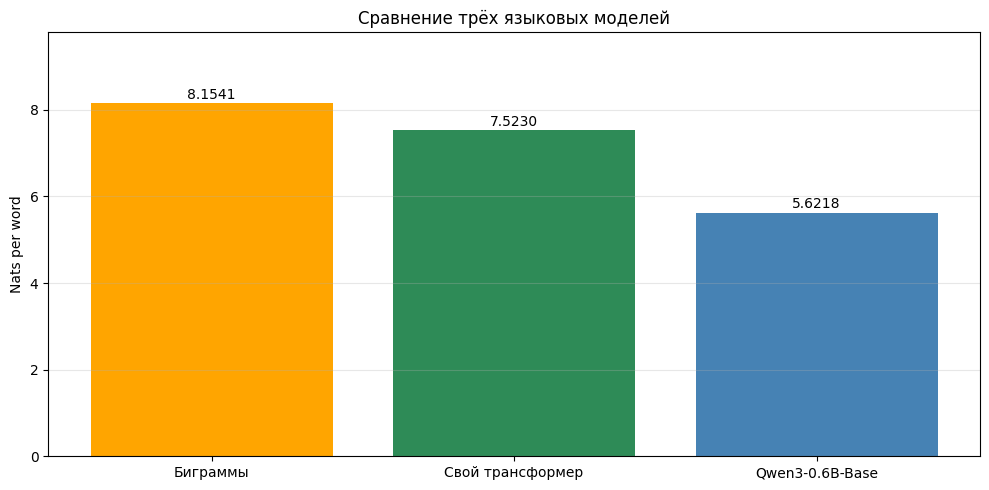

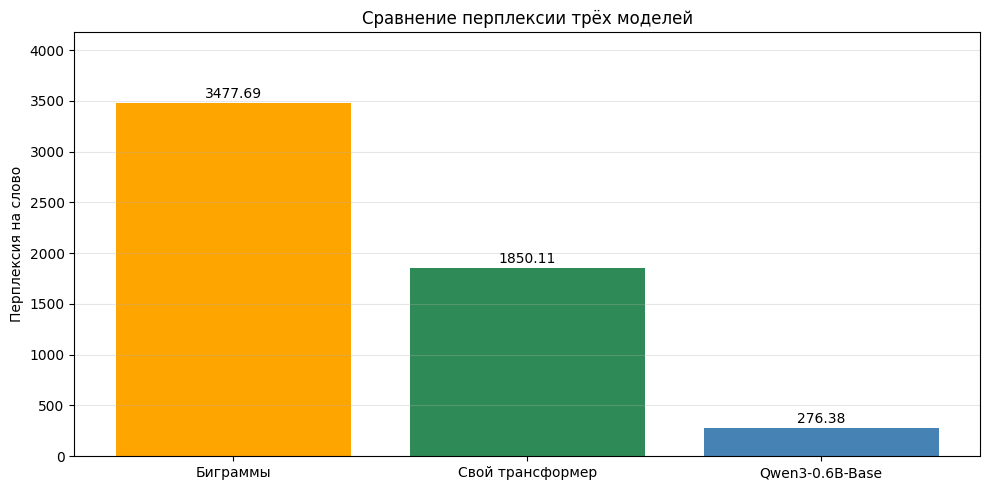


ПРЕИМУЩЕСТВО QWEN

По сравнению с: Свой трансформер
Снижение Nats per word (%): 25.27
Снижение перплексии (%): 85.06

По сравнению с: Биграммная модель
Снижение Nats per word (%): 31.06
Снижение перплексии (%): 92.05

ИТОГОВАЯ ПРОВЕРКА
Количество слов корректно: True
Название модели корректно: True
Количество токенов корректно: True
Nats per word корректен: True
Перплексия корректна: True
Qwen лучше трансформера: True
График Nats сохранён: True
График перплексии сохранён: True
eval.json существует: True

СОХРАНЁННЫЕ ФАЙЛЫ
/content/drive/MyDrive/Лабораторная2_Попова_МТИ2532/artifacts/eval.json
/content/drive/MyDrive/Лабораторная2_Попова_МТИ2532/bonus/qwen_nats.png
/content/drive/MyDrive/Лабораторная2_Попова_МТИ2532/bonus/qwen_perplexity.png

БОНУС №1. ТРЕТЬЯ ТОЧКА — ВЫПОЛНЕНО


In [15]:
# Сравнение трёх языковых моделей

import json
import math
import matplotlib.pyplot as plt
from pathlib import Path

WORK_DIR = Path(
    "/content/drive/MyDrive/Лабораторная2_Попова_МТИ2532"
)

ARTIFACTS_DIR = WORK_DIR / "artifacts"
BONUS_DIR = WORK_DIR / "bonus"

BONUS_DIR.mkdir(parents=True, exist_ok=True)

# Загрузка результатов

eval_path = ARTIFACTS_DIR / "eval.json"

with open(eval_path, encoding="utf-8") as f:
    evaluation = json.load(f)

model_keys = ["bigram", "tiny", "qwen"]

model_names = [
    "Биграммы",
    "Свой трансформер",
    "Qwen3-0.6B-Base"
]

colors = ["orange", "seagreen", "steelblue"]

nats_values = [
    evaluation[key]["nats_per_word"]
    for key in model_keys
]

ppl_values = [
    evaluation[key]["ppl_per_word"]
    for key in model_keys
]

print("СРАВНЕНИЕ ТРЁХ МОДЕЛЕЙ")
print("=" * 60)

for name, nats, ppl in zip(
    model_names, nats_values, ppl_values
):
    print("\nМодель:", name)
    print("Nats per word:", round(nats, 6))
    print("Перплексия:", round(ppl, 6))

# График 1. Nats per word

plt.figure(figsize=(10, 5))

bars = plt.bar(
    model_names,
    nats_values,
    color=colors
)

for bar, value in zip(bars, nats_values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.1,
        f"{value:.4f}",
        ha="center"
    )

plt.title("Сравнение трёх языковых моделей")
plt.ylabel("Nats per word")
plt.ylim(0, max(nats_values) * 1.2)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

nats_graph = BONUS_DIR / "qwen_nats.png"

plt.savefig(
    nats_graph,
    dpi=150,
    bbox_inches="tight"
)

plt.show()
plt.close()

# График 2. Перплексия

plt.figure(figsize=(10, 5))

bars = plt.bar(
    model_names,
    ppl_values,
    color=colors
)

for bar, value in zip(bars, ppl_values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 50,
        f"{value:.2f}",
        ha="center"
    )

plt.title("Сравнение перплексии трёх моделей")
plt.ylabel("Перплексия на слово")
plt.ylim(0, max(ppl_values) * 1.2)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

ppl_graph = BONUS_DIR / "qwen_perplexity.png"

plt.savefig(
    ppl_graph,
    dpi=150,
    bbox_inches="tight"
)

plt.show()
plt.close()

# Расчёт улучшения качества

tiny = evaluation["tiny"]
qwen = evaluation["qwen"]
bigram = evaluation["bigram"]

print("\nПРЕИМУЩЕСТВО QWEN")
print("=" * 60)

for name, baseline in [
    ("Свой трансформер", tiny),
    ("Биграммная модель", bigram)
]:

    nats_improvement = 100 * (
        1 - qwen["nats_per_word"]
        / baseline["nats_per_word"]
    )

    ppl_improvement = 100 * (
        1 - qwen["ppl_per_word"]
        / baseline["ppl_per_word"]
    )

    print("\nПо сравнению с:", name)
    print(
        "Снижение Nats per word (%):",
        round(nats_improvement, 2)
    )
    print(
        "Снижение перплексии (%):",
        round(ppl_improvement, 2)
    )

# Проверка требований преподавателя

model_correct = (
    qwen["model"] == "Qwen/Qwen3-0.6B-Base"
)

tokens_correct = qwen["tokens"] > 0

nats_correct = math.isclose(
    qwen["nats_per_word"],
    qwen["nats_total"] / evaluation["words"],
    rel_tol=1e-3
)

ppl_correct = math.isclose(
    qwen["ppl_per_word"],
    math.exp(qwen["nats_per_word"]),
    rel_tol=1e-2
)

qwen_better = (
    qwen["nats_per_word"]
    < tiny["nats_per_word"]
)

print("\nИТОГОВАЯ ПРОВЕРКА")
print("=" * 60)

print("Количество слов корректно:",
      evaluation["words"] == 2000)

print("Название модели корректно:", model_correct)
print("Количество токенов корректно:", tokens_correct)
print("Nats per word корректен:", nats_correct)
print("Перплексия корректна:", ppl_correct)
print("Qwen лучше трансформера:", qwen_better)
print("График Nats сохранён:", nats_graph.is_file())
print("График перплексии сохранён:", ppl_graph.is_file())
print("eval.json существует:", eval_path.is_file())

assert evaluation["words"] == 2000
assert model_correct
assert tokens_correct
assert nats_correct
assert ppl_correct
assert qwen_better
assert nats_graph.is_file()
assert ppl_graph.is_file()

print("\nСОХРАНЁННЫЕ ФАЙЛЫ")
print("=" * 60)

print(eval_path)
print(nats_graph)
print(ppl_graph)

print("\nБОНУС №1. ТРЕТЬЯ ТОЧКА — ВЫПОЛНЕНО")

Бонус №2. Та же generate, но для настоящей модели.

Реализация генерации с KV-кэшем.

In [16]:
# Самостоятельная генерация Qwen

import torch
import json
from pathlib import Path
from transformers import AutoTokenizer, AutoModelForCausalLM

WORK_DIR = Path(
    "/content/drive/MyDrive/Лабораторная2_Попова_МТИ2532"
)

ARTIFACTS_DIR = WORK_DIR / "artifacts"
BONUS_DIR = WORK_DIR / "bonus"
QWEN_DIR = WORK_DIR / "checkpoints" / "qwen_model"

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

MODEL_NAME = "Qwen/Qwen3-0.6B-Base"

# Восстановление модели

print("ВОССТАНОВЛЕНИЕ QWEN")
print("=" * 60)

qwen_tokenizer = AutoTokenizer.from_pretrained(
    str(QWEN_DIR),
    local_files_only=True
)

qwen_model = AutoModelForCausalLM.from_pretrained(
    str(QWEN_DIR),
    dtype=torch.float16 if DEVICE.type == "cuda"
    else torch.float32,
    local_files_only=True
).to(DEVICE)

qwen_model.eval()

print("Модель:", MODEL_NAME)
print("Устройство:", DEVICE)
print("Модель успешно восстановлена")

# Самостоятельная функция генерации

@torch.inference_mode()
def generate_qwen(
    prompt,
    max_new_tokens=30,
    temperature=1.0,
    top_p=None,
    use_cache=True
):

    if temperature < 0:
        raise ValueError("Некорректная температура")

    if top_p is not None and not 0 < top_p <= 1:
        raise ValueError("Некорректное значение top_p")

    encoded = qwen_tokenizer(
        prompt,
        return_tensors="pt",
        add_special_tokens=False
    )

    input_ids = encoded["input_ids"].to(DEVICE)
    all_ids = input_ids.clone()

    attention_mask = torch.ones_like(input_ids)

    past_key_values = None
    new_ids = []

    eos_ids = qwen_model.generation_config.eos_token_id

    if eos_ids is None:
        eos_ids = []
    elif isinstance(eos_ids, int):
        eos_ids = [eos_ids]

    for step in range(max_new_tokens):

        # При наличии кэша подаём только последний токен

        if use_cache and past_key_values is not None:
            current_ids = all_ids[:, -1:]
        else:
            current_ids = all_ids

        outputs = qwen_model(
            input_ids=current_ids,
            attention_mask=attention_mask,
            past_key_values=past_key_values,
            use_cache=use_cache
        )

        logits = outputs.logits[:, -1, :].float()

        if use_cache:
            past_key_values = outputs.past_key_values

        # Жадная генерация

        if temperature == 0:

            next_token = torch.argmax(
                logits,
                dim=-1,
                keepdim=True
            )

        else:

            logits = logits / temperature

            # Фильтрация top-p

            if top_p is not None:

                sorted_logits, sorted_indices = torch.sort(
                    logits,
                    descending=True,
                    dim=-1
                )

                sorted_probs = torch.softmax(
                    sorted_logits,
                    dim=-1
                )

                cumulative_probs = torch.cumsum(
                    sorted_probs,
                    dim=-1
                )

                remove = cumulative_probs > top_p

                remove[..., 1:] = (
                    remove[..., :-1].clone()
                )

                remove[..., 0] = False

                sorted_logits = sorted_logits.masked_fill(
                    remove,
                    float("-inf")
                )

                logits = torch.full_like(
                    logits,
                    float("-inf")
                ).scatter(
                    -1,
                    sorted_indices,
                    sorted_logits
                )

            probabilities = torch.softmax(
                logits,
                dim=-1
            )

            next_token = torch.multinomial(
                probabilities,
                num_samples=1
            )

        token_id = next_token.item()

        new_ids.append(token_id)

        all_ids = torch.cat(
            [all_ids, next_token],
            dim=1
        )

        attention_mask = torch.cat(
            [
                attention_mask,
                torch.ones_like(next_token)
            ],
            dim=1
        )

        if token_id in eos_ids:
            break

    text = qwen_tokenizer.decode(
        all_ids[0].tolist(),
        skip_special_tokens=True
    )

    return text, new_ids

# Проверка жадной генерации

PROMPT = "Князь Андрей вошел в комнату и"
MAX_NEW_TOKENS = 30

print("\nСАМОСТОЯТЕЛЬНАЯ ГЕНЕРАЦИЯ")
print("=" * 60)

ours_text, ours_ids = generate_qwen(
    prompt=PROMPT,
    max_new_tokens=MAX_NEW_TOKENS,
    temperature=0,
    use_cache=True
)

print("Затравка:", PROMPT)
print("Количество новых токенов:", len(ours_ids))

print("\nСгенерированный текст:")
print(ours_text)

print("\nИдентификаторы:")
print(ours_ids)

# Генерация средствами Hugging Face

print("\nГЕНЕРАЦИЯ HUGGING FACE")
print("=" * 60)

hf_inputs = qwen_tokenizer(
    PROMPT,
    return_tensors="pt",
    add_special_tokens=False
).to(DEVICE)

prompt_ids = hf_inputs["input_ids"][0].tolist()

with torch.inference_mode():

    hf_output = qwen_model.generate(
        **hf_inputs,
        max_new_tokens=MAX_NEW_TOKENS,
        do_sample=False,
        use_cache=True
    )

hf_ids = hf_output[
    0, len(prompt_ids):
].tolist()

hf_text = qwen_tokenizer.decode(
    hf_output[0].tolist(),
    skip_special_tokens=True
)

print("Количество новых токенов:", len(hf_ids))

print("\nСгенерированный текст:")
print(hf_text)

print("\nИдентификаторы:")
print(hf_ids)

# Сравнение результатов

match = ours_ids == hf_ids

print("\nСРАВНЕНИЕ РЕЗУЛЬТАТОВ")
print("=" * 60)

print("Идентификаторы затравки:", prompt_ids)
print("Наша генерация:", len(ours_ids))
print("Генерация Hugging Face:", len(hf_ids))
print("Совпадение токенов:", match)
print("Совпадение текста:", ours_text == hf_text)

print(
    "Количество токенов корректно:",
    len(ours_ids) == len(hf_ids) == 30
)

assert match, "Последовательности токенов различаются"
assert len(ours_ids) == 30
assert len(hf_ids) == 30

# Сохранение результатов

greedy_result = {
    "model": MODEL_NAME,
    "prompt": PROMPT,
    "prompt_ids": prompt_ids,
    "ours_ids": ours_ids,
    "hf_ids": hf_ids,
    "match": match
}

save_path = ARTIFACTS_DIR / "greedy_check.json"

with open(save_path, "w", encoding="utf-8") as f:
    json.dump(
        greedy_result,
        f,
        ensure_ascii=False,
        indent=2
    )

with open(save_path, encoding="utf-8") as f:
    restored_result = json.load(f)

print("\nСОХРАНЕНИЕ")
print("=" * 60)

print("greedy_check.json сохранён:", save_path.is_file())

print(
    "Проверка восстановления:",
    restored_result == greedy_result
)

print("Путь:", save_path)

print("\nСОДЕРЖИМОЕ greedy_check.json")
print("=" * 60)

print(json.dumps(
    greedy_result,
    ensure_ascii=False,
    indent=2
))

print("\nСамостоятельная генерация Qwen проверена")

ВОССТАНОВЛЕНИЕ QWEN


Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

Модель: Qwen/Qwen3-0.6B-Base
Устройство: cuda
Модель успешно восстановлена

САМОСТОЯТЕЛЬНАЯ ГЕНЕРАЦИЯ
Затравка: Князь Андрей вошел в комнату и
Количество новых токенов: 30

Сгенерированный текст:
Князь Андрей вошел в комнату и сказал: "Вот, пожалуйста, выслушайте меня. Я хочу, чтобы вы меня поняли. Я хочу,

Идентификаторы:
[133260, 25, 330, 16206, 13039, 11, 5063, 21259, 15952, 82580, 126309, 11, 20811, 137476, 131646, 129052, 13, 128557, 143612, 11, 81150, 20811, 129052, 141688, 4235, 11073, 13, 128557, 143612, 11]

ГЕНЕРАЦИЯ HUGGING FACE
Количество новых токенов: 30

Сгенерированный текст:
Князь Андрей вошел в комнату и сказал: "Вот, пожалуйста, выслушайте меня. Я хочу, чтобы вы меня поняли. Я хочу,

Идентификаторы:
[133260, 25, 330, 16206, 13039, 11, 5063, 21259, 15952, 82580, 126309, 11, 20811, 137476, 131646, 129052, 13, 128557, 143612, 11, 81150, 20811, 129052, 141688, 4235, 11073, 13, 128557, 143612, 11]

СРАВНЕНИЕ РЕЗУЛЬТАТОВ
Идентификаторы затравки: [26338, 39151, 8959, 4824, 

Измерение скорости генерации с KV-кэшем и без него.

ПАРАМЕТРЫ ЭКСПЕРИМЕНТА
Модель: Qwen/Qwen3-0.6B-Base
Устройство: cuda
Затравка: Князь Андрей вошел в комнату и
Новых токенов: 30
Повторов для каждого режима: 3

ПРОГРЕВ МОДЕЛИ
Прогрев завершён: с кэшем
Прогрев завершён: без кэша

ИЗМЕРЕНИЕ СКОРОСТИ

Режим: cache
Повтор 1: 1.3728 сек., 21.8527 токенов/сек.
Повтор 2: 1.5768 сек., 19.0256 токенов/сек.
Повтор 3: 1.8107 сек., 16.5680 токенов/сек.
Среднее время: 1.5868 сек.
Средняя скорость: 18.9061 токенов/сек.

Режим: no_cache
Повтор 1: 1.9617 сек., 15.2929 токенов/сек.
Повтор 2: 1.4760 сек., 20.3254 токенов/сек.
Повтор 3: 1.5025 сек., 19.9661 токенов/сек.
Среднее время: 1.6467 сек.
Средняя скорость: 18.2178 токенов/сек.

СРАВНЕНИЕ РЕЗУЛЬТАТОВ
Скорость с кэшем: 18.9061
Скорость без кэша: 18.2178
Коэффициент ускорения: 1.0378
Сокращение времени (%): 3.64
Совпадение токенов: True

СОДЕРЖИМОЕ speed.csv
mode,new_tokens,seconds,tokens_per_second
cache,30,1.586790055000165,18.906092778604464
no_cache,30,1.6467435866666165,18.21777248316286



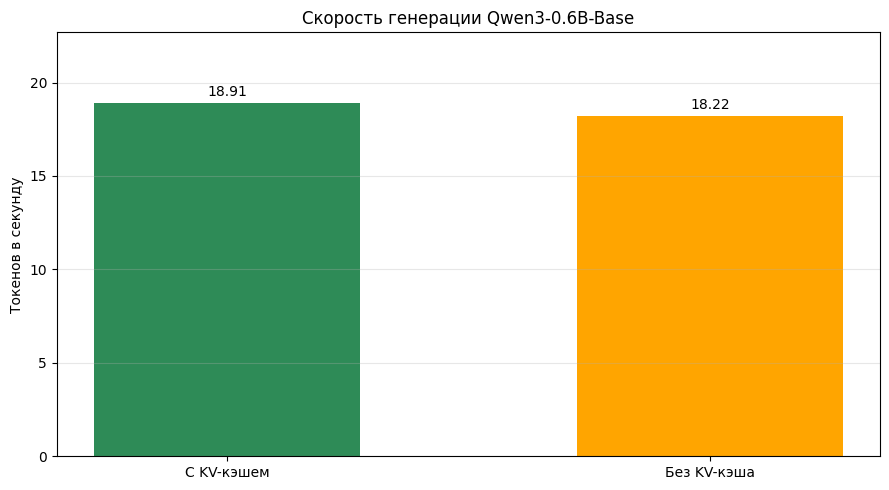

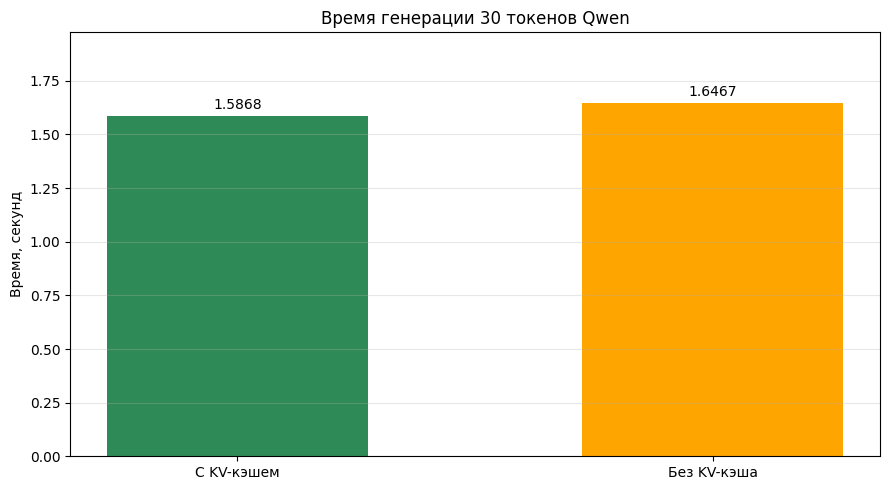


ИТОГОВАЯ ПРОВЕРКА
Количество режимов корректно: True
Количество токенов корректно: True
Время положительное: True
Скорость рассчитана корректно: True
Токены с кэшем и без совпадают: True
Генерация с кэшем быстрее: True
speed.csv сохранён: True
Количество строк корректно: True
greedy_check.json существует: True
График скорости сохранён: True
График времени сохранён: True

СОХРАНЁННЫЕ ФАЙЛЫ
/content/drive/MyDrive/Лабораторная2_Попова_МТИ2532/artifacts/speed.csv
/content/drive/MyDrive/Лабораторная2_Попова_МТИ2532/bonus/qwen_speed.png
/content/drive/MyDrive/Лабораторная2_Попова_МТИ2532/bonus/qwen_time.png

Измерение скорости генерации завершено


In [17]:
# Измерение скорости генерации

import time
import csv
import statistics
import torch
import matplotlib.pyplot as plt

PROMPT = "Князь Андрей вошел в комнату и"
MAX_NEW_TOKENS = 30
REPEATS = 3

qwen_model.eval()

# Синхронизация GPU

def synchronize_device():
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()

print("ПАРАМЕТРЫ ЭКСПЕРИМЕНТА")
print("=" * 60)

print("Модель:", MODEL_NAME)
print("Устройство:", DEVICE)
print("Затравка:", PROMPT)
print("Новых токенов:", MAX_NEW_TOKENS)
print("Повторов для каждого режима:", REPEATS)

# Прогрев модели

print("\nПРОГРЕВ МОДЕЛИ")
print("=" * 60)

for cache_enabled in [True, False]:

    generate_qwen(
        prompt=PROMPT,
        max_new_tokens=MAX_NEW_TOKENS,
        temperature=0,
        use_cache=cache_enabled
    )

    synchronize_device()

    print(
        "Прогрев завершён:",
        "с кэшем" if cache_enabled else "без кэша"
    )

# Измерение скорости

speed_results = []
generated_sequences = {}

print("\nИЗМЕРЕНИЕ СКОРОСТИ")
print("=" * 60)

for mode, cache_enabled in [
    ("cache", True),
    ("no_cache", False)
]:

    times = []
    sequences = []

    print("\nРежим:", mode)

    for repeat in range(REPEATS):

        synchronize_device()

        start_time = time.perf_counter()

        text, token_ids = generate_qwen(
            prompt=PROMPT,
            max_new_tokens=MAX_NEW_TOKENS,
            temperature=0,
            use_cache=cache_enabled
        )

        synchronize_device()

        elapsed = time.perf_counter() - start_time

        times.append(elapsed)
        sequences.append(token_ids)

        print(
            f"Повтор {repeat + 1}: "
            f"{elapsed:.4f} сек., "
            f"{len(token_ids) / elapsed:.4f} токенов/сек."
        )

    assert all(
        len(ids) == MAX_NEW_TOKENS
        for ids in sequences
    )

    assert all(
        ids == sequences[0]
        for ids in sequences
    )

    mean_seconds = statistics.mean(times)

    tokens_per_second = (
        MAX_NEW_TOKENS / mean_seconds
    )

    generated_sequences[mode] = sequences[0]

    speed_results.append({
        "mode": mode,
        "new_tokens": MAX_NEW_TOKENS,
        "seconds": mean_seconds,
        "tokens_per_second": tokens_per_second
    })

    print(f"Среднее время: {mean_seconds:.4f} сек.")
    print(f"Средняя скорость: {tokens_per_second:.4f} токенов/сек.")

# Сравнение результатов

cache_result = speed_results[0]
no_cache_result = speed_results[1]

speedup = (
    cache_result["tokens_per_second"]
    / no_cache_result["tokens_per_second"]
)

time_reduction = (
    1 - cache_result["seconds"]
    / no_cache_result["seconds"]
) * 100

same_tokens = (
    generated_sequences["cache"]
    == generated_sequences["no_cache"]
)

print("\nСРАВНЕНИЕ РЕЗУЛЬТАТОВ")
print("=" * 60)

print(
    "Скорость с кэшем:",
    round(cache_result["tokens_per_second"], 4)
)

print(
    "Скорость без кэша:",
    round(no_cache_result["tokens_per_second"], 4)
)

print("Коэффициент ускорения:", round(speedup, 4))

print(
    "Сокращение времени (%):",
    round(time_reduction, 2)
)

print("Совпадение токенов:", same_tokens)

# Сохранение speed.csv

speed_path = ARTIFACTS_DIR / "speed.csv"

with open(
    speed_path,
    "w",
    encoding="utf-8",
    newline=""
) as f:

    writer = csv.DictWriter(
        f,
        fieldnames=[
            "mode",
            "new_tokens",
            "seconds",
            "tokens_per_second"
        ]
    )

    writer.writeheader()
    writer.writerows(speed_results)

# Проверка сохранённого файла

with open(speed_path, encoding="utf-8") as f:
    restored_rows = list(csv.DictReader(f))

print("\nСОДЕРЖИМОЕ speed.csv")
print("=" * 60)

print(speed_path.read_text(encoding="utf-8"))

# Построение графика скорости

labels = ["С KV-кэшем", "Без KV-кэша"]

speeds = [
    cache_result["tokens_per_second"],
    no_cache_result["tokens_per_second"]
]

plt.figure(figsize=(9, 5))

bars = plt.bar(
    labels,
    speeds,
    color=["seagreen", "orange"],
    width=0.55
)

plt.title("Скорость генерации Qwen3-0.6B-Base")
plt.ylabel("Токенов в секунду")
plt.grid(axis="y", alpha=0.3)
plt.ylim(0, max(speeds) * 1.2)

for bar, value in zip(bars, speeds):

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + max(speeds) * 0.02,
        f"{value:.2f}",
        ha="center"
    )

plt.tight_layout()

speed_graph = BONUS_DIR / "qwen_speed.png"

plt.savefig(
    speed_graph,
    dpi=150,
    bbox_inches="tight"
)

plt.show()
plt.close()

# График времени генерации

seconds = [
    cache_result["seconds"],
    no_cache_result["seconds"]
]

plt.figure(figsize=(9, 5))

bars = plt.bar(
    labels,
    seconds,
    color=["seagreen", "orange"],
    width=0.55
)

plt.title("Время генерации 30 токенов Qwen")
plt.ylabel("Время, секунд")
plt.grid(axis="y", alpha=0.3)
plt.ylim(0, max(seconds) * 1.2)

for bar, value in zip(bars, seconds):

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + max(seconds) * 0.02,
        f"{value:.4f}",
        ha="center"
    )

plt.tight_layout()

time_graph = BONUS_DIR / "qwen_time.png"

plt.savefig(
    time_graph,
    dpi=150,
    bbox_inches="tight"
)

plt.show()
plt.close()

# Итоговая проверка

metrics_correct = all(
    abs(
        row["tokens_per_second"]
        - row["new_tokens"] / row["seconds"]
    ) < 1e-6
    for row in speed_results
)

print("\nИТОГОВАЯ ПРОВЕРКА")
print("=" * 60)

print("Количество режимов корректно:", len(speed_results) == 2)
print("Количество токенов корректно:", all(
    row["new_tokens"] == 30
    for row in speed_results
))
print("Время положительное:", all(
    row["seconds"] > 0
    for row in speed_results
))
print("Скорость рассчитана корректно:", metrics_correct)
print("Токены с кэшем и без совпадают:", same_tokens)
print("Генерация с кэшем быстрее:", speedup > 1)
print("speed.csv сохранён:", speed_path.is_file())
print("Количество строк корректно:", len(restored_rows) == 2)
print("greedy_check.json существует:", (
    ARTIFACTS_DIR / "greedy_check.json"
).is_file())
print("График скорости сохранён:", speed_graph.is_file())
print("График времени сохранён:", time_graph.is_file())

print("\nСОХРАНЁННЫЕ ФАЙЛЫ")
print("=" * 60)

print(speed_path)
print(speed_graph)
print(time_graph)

print("\nИзмерение скорости генерации завершено")

Бонус №3. Закон масштабирования руками.

In [18]:
# Закон масштабирования руками

import torch
import torch.nn.functional as F
import json
import csv
import math
import time
import runpy

from pathlib import Path

BASE_DIR = Path(
    "/content/drive/MyDrive/Лабораторная2_Попова_МТИ2532"
)

SCALE_DIR = BASE_DIR / "checkpoints" / "scaling"
SCALE_DIR.mkdir(parents=True, exist_ok=True)

BONUS_DIR = BASE_DIR / "bonus"
BONUS_DIR.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Восстановление архитектуры

model_module = runpy.run_path(
    str(BASE_DIR / "scripts" / "model.py")
)

TinyTransformer = model_module["TinyTransformer"]

# Восстановление данных

scale_train_ids = torch.load(
    BASE_DIR / "data" / "train_ids.pt",
    map_location="cpu",
    weights_only=True
).to(DEVICE)

scale_val_ids = torch.load(
    BASE_DIR / "data" / "val_ids.pt",
    map_location="cpu",
    weights_only=True
).to(DEVICE)

# Общие параметры эксперимента

WIDTHS = [64, 128, 256]

VOCAB_SIZE = 1534
N_LAYERS = 4
N_HEADS = 4
CONTEXT = 128

STEPS = 2000
BATCH = 32
LR = 0.001
SEED = 42
EVAL_INTERVAL = 100
VAL_WINDOWS = 20

# Формирование батчей

def scale_get_batch(data, batch_size, generator):

    starts = torch.randint(
        0,
        len(data) - CONTEXT,
        (batch_size,),
        generator=generator
    ).to(DEVICE)

    positions = (
        starts[:, None]
        + torch.arange(CONTEXT, device=DEVICE)[None, :]
    )

    x = data[positions]
    y = data[positions + 1]

    return x, y

# Одинаковые проверочные окна для всех моделей

val_generator = torch.Generator()
val_generator.manual_seed(SEED + 1)

scale_val_x, scale_val_y = scale_get_batch(
    scale_val_ids,
    VAL_WINDOWS,
    val_generator
)

# Расчёт функции потерь

def scale_loss(model, x, y):

    logits = model(x)

    if isinstance(logits, (tuple, list)):
        logits = logits[0]

    return F.cross_entropy(
        logits.reshape(-1, VOCAB_SIZE),
        y.reshape(-1)
    )


@torch.no_grad()
def scale_validation_loss(model):

    model.eval()

    loss = scale_loss(
        model,
        scale_val_x,
        scale_val_y
    ).item()

    model.train()

    return loss


print("ПАРАМЕТРЫ ЭКСПЕРИМЕНТА")
print("=" * 60)

print("Устройство:", DEVICE)
print("Ширины моделей:", WIDTHS)
print("Количество шагов:", STEPS)
print("Размер батча:", BATCH)
print("Длина контекста:", CONTEXT)
print("Скорость обучения:", LR)
print("Seed:", SEED)

print("Обучающих токенов:", len(scale_train_ids))
print("Проверочных токенов:", len(scale_val_ids))
print("Проверочных окон:", VAL_WINDOWS)

scaling_results = []

# Последовательное обучение трёх моделей

for width in WIDTHS:

    print("\n" + "=" * 60)
    print("ОБУЧЕНИЕ МОДЕЛИ ШИРИНОЙ", width)
    print("=" * 60)

    torch.manual_seed(SEED)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)

    # Одинаковая последовательность обучающих окон

    train_generator = torch.Generator()
    train_generator.manual_seed(SEED)

    scale_model = TinyTransformer(
        vocab_size=VOCAB_SIZE,
        d_model=width,
        n_layers=N_LAYERS,
        n_heads=N_HEADS,
        d_ff=width * 4,
        context=CONTEXT
    ).to(DEVICE)

    scale_optimizer = torch.optim.AdamW(
        scale_model.parameters(),
        lr=LR
    )

    n_params = sum(
        p.numel()
        for p in scale_model.parameters()
    )

    print("Количество параметров:", n_params)

    checkpoint_path = SCALE_DIR / f"width_{width}.pt"

    history = []
    start_step = 0
    previous_seconds = 0.0

    # Восстановление контрольной точки

    if checkpoint_path.is_file():

        checkpoint = torch.load(
            checkpoint_path,
            map_location="cpu",
            weights_only=True
        )

        assert checkpoint["width"] == width
        assert checkpoint["steps"] == STEPS
        assert checkpoint["batch"] == BATCH

        scale_model.load_state_dict(
            checkpoint["model_state"]
        )

        scale_optimizer.load_state_dict(
            checkpoint["optimizer_state"]
        )

        train_generator.set_state(
            checkpoint["generator_state"]
        )

        torch.set_rng_state(
            checkpoint["torch_rng_state"]
        )

        if DEVICE.type == "cuda" and checkpoint.get(
            "cuda_rng_state"
        ) is not None:

            torch.cuda.set_rng_state(
                checkpoint["cuda_rng_state"]
            )

        history = checkpoint["history"]
        start_step = checkpoint["step"]
        previous_seconds = checkpoint["seconds"]

        del checkpoint

        print("Восстановлен шаг:", start_step)

    else:

        # Начальные потери до обучения

        initial_generator = torch.Generator()
        initial_generator.manual_seed(SEED + 2)

        initial_x, initial_y = scale_get_batch(
            scale_train_ids,
            BATCH,
            initial_generator
        )

        scale_model.eval()

        with torch.no_grad():

            initial_train_loss = scale_loss(
                scale_model,
                initial_x,
                initial_y
            ).item()

        initial_val_loss = scale_validation_loss(
            scale_model
        )

        history.append({
            "step": 0,
            "train_loss": initial_train_loss,
            "val_loss": initial_val_loss
        })

        print(
            f"Шаг 0 | "
            f"Train loss: {initial_train_loss:.4f} | "
            f"Val loss: {initial_val_loss:.4f}"
        )

    scale_model.train()

    start_time = time.perf_counter()

    accumulated_loss = 0.0
    interval_count = 0

    # Основной цикл обучения

    for step in range(start_step + 1, STEPS + 1):

        x, y = scale_get_batch(
            scale_train_ids,
            BATCH,
            train_generator
        )

        scale_optimizer.zero_grad(set_to_none=True)

        loss = scale_loss(scale_model, x, y)

        loss.backward()

        scale_optimizer.step()

        accumulated_loss += loss.detach().item()
        interval_count += 1

        if step % EVAL_INTERVAL == 0:

            train_loss = (
                accumulated_loss / interval_count
            )

            val_loss = scale_validation_loss(
                scale_model
            )

            assert math.isfinite(train_loss)
            assert math.isfinite(val_loss)

            history.append({
                "step": step,
                "train_loss": train_loss,
                "val_loss": val_loss
            })

            print(
                f"Ширина {width} | "
                f"Шаг {step:4d}/{STEPS} | "
                f"Train loss: {train_loss:.4f} | "
                f"Val loss: {val_loss:.4f}"
            )

            accumulated_loss = 0.0
            interval_count = 0

            # Сохранение контрольной точки

            checkpoint_data = {
                "width": width,
                "steps": STEPS,
                "batch": BATCH,
                "step": step,
                "model_state": scale_model.state_dict(),
                "optimizer_state": scale_optimizer.state_dict(),
                "generator_state": train_generator.get_state(),
                "torch_rng_state": torch.get_rng_state(),
                "cuda_rng_state": (
                    torch.cuda.get_rng_state()
                    if DEVICE.type == "cuda"
                    else None
                ),
                "history": history,
                "seconds": (
                    previous_seconds
                    + time.perf_counter()
                    - start_time
                )
            }

            temp_path = checkpoint_path.with_suffix(".tmp")

            torch.save(checkpoint_data, temp_path)

            temp_path.replace(checkpoint_path)

            del checkpoint_data

    elapsed = previous_seconds

    if start_step < STEPS:

        elapsed += time.perf_counter() - start_time

    # Сохранение кривой обучения

    curve_path = BONUS_DIR / f"scaling_{width}.csv"

    with open(
        curve_path,
        "w",
        encoding="utf-8",
        newline=""
    ) as f:

        writer = csv.DictWriter(
            f,
            fieldnames=[
                "step",
                "train_loss",
                "val_loss"
            ]
        )

        writer.writeheader()
        writer.writerows(history)

    result = {
        "d_model": width,
        "n_params": n_params,
        "n_layers": N_LAYERS,
        "n_heads": N_HEADS,
        "d_ff": width * 4,
        "context": CONTEXT,
        "steps": STEPS,
        "batch": BATCH,
        "lr": LR,
        "seed": SEED,
        "train_tokens": len(scale_train_ids),
        "val_tokens": len(scale_val_ids),
        "initial_train_loss": history[0]["train_loss"],
        "final_train_loss": history[-1]["train_loss"],
        "initial_val_loss": history[0]["val_loss"],
        "final_val_loss": history[-1]["val_loss"],
        "best_val_loss": min(
            row["val_loss"] for row in history
        ),
        "train_minutes": elapsed / 60,
        "history": history
    }

    scaling_results.append(result)

    # Сохранение промежуточных результатов

    summary_path = BONUS_DIR / "scaling_results.json"

    summary_path.write_text(
        json.dumps(
            scaling_results,
            ensure_ascii=False,
            indent=2
        ),
        encoding="utf-8"
    )

    print("\nРЕЗУЛЬТАТЫ МОДЕЛИ")
    print("=" * 60)

    print("Ширина:", width)
    print("Параметров:", n_params)
    print("Начальный val loss:", history[0]["val_loss"])
    print("Конечный val loss:", history[-1]["val_loss"])
    print("Время обучения (мин.):", round(elapsed / 60, 4))
    print("Контрольная точка сохранена:", checkpoint_path.is_file())
    print("Кривая обучения сохранена:", curve_path.is_file())

    # Освобождение видеопамяти

    del scale_model
    del scale_optimizer
    del loss

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


print("\nИТОГОВЫЕ РЕЗУЛЬТАТЫ")
print("=" * 60)

for result in scaling_results:

    print(
        f"Ширина: {result['d_model']} | "
        f"Параметров: {result['n_params']} | "
        f"Train loss: {result['final_train_loss']:.4f} | "
        f"Val loss: {result['final_val_loss']:.4f}"
    )

print("\nИТОГОВАЯ ПРОВЕРКА")
print("=" * 60)

print("Обучено три модели:", len(scaling_results) == 3)

print("Количество шагов одинаковое:", all(
    r["history"][-1]["step"] == STEPS
    for r in scaling_results
))

print("Данные одинаковые:", all(
    r["train_tokens"] == len(scale_train_ids)
    and r["val_tokens"] == len(scale_val_ids)
    for r in scaling_results
))

print("Val loss уменьшился у всех моделей:", all(
    r["final_val_loss"] < r["initial_val_loss"]
    for r in scaling_results
))

print("Результаты сохранены:", summary_path.is_file())

print("\nОбучение трёх моделей завершено")

ПАРАМЕТРЫ ЭКСПЕРИМЕНТА
Устройство: cuda
Ширины моделей: [64, 128, 256]
Количество шагов: 2000
Размер батча: 32
Длина контекста: 128
Скорость обучения: 0.001
Seed: 42
Обучающих токенов: 753537
Проверочных токенов: 83461
Проверочных окон: 20

ОБУЧЕНИЕ МОДЕЛИ ШИРИНОЙ 64
Количество параметров: 406142
Шаг 0 | Train loss: 7.3499 | Val loss: 7.3451
Ширина 64 | Шаг  100/2000 | Train loss: 6.5077 | Val loss: 6.0316
Ширина 64 | Шаг  200/2000 | Train loss: 5.7095 | Val loss: 5.4826
Ширина 64 | Шаг  300/2000 | Train loss: 5.2769 | Val loss: 5.1719
Ширина 64 | Шаг  400/2000 | Train loss: 5.0608 | Val loss: 5.0370
Ширина 64 | Шаг  500/2000 | Train loss: 4.9376 | Val loss: 4.9697
Ширина 64 | Шаг  600/2000 | Train loss: 4.8530 | Val loss: 4.9189
Ширина 64 | Шаг  700/2000 | Train loss: 4.7946 | Val loss: 4.8838
Ширина 64 | Шаг  800/2000 | Train loss: 4.7423 | Val loss: 4.8558
Ширина 64 | Шаг  900/2000 | Train loss: 4.7038 | Val loss: 4.8230
Ширина 64 | Шаг 1000/2000 | Train loss: 4.6672 | Val loss: 4.7

Построение графиков и анализ результатов.

РЕЗУЛЬТАТЫ МАСШТАБИРОВАНИЯ

Ширина модели: 64
Количество параметров: 406142
Начальный val loss: 7.3451
Конечный train loss: 4.2655
Конечный val loss: 4.506
Снижение val loss: 2.8391
Время обучения (мин.): 0.6459

Ширина модели: 128
Количество параметров: 1203966
Начальный val loss: 7.3637
Конечный train loss: 3.7023
Конечный val loss: 4.2027
Снижение val loss: 3.161
Время обучения (мин.): 0.68

Ширина модели: 256
Количество параметров: 3979262
Начальный val loss: 7.3989
Конечный train loss: 3.5495
Конечный val loss: 4.0998
Снижение val loss: 3.2992
Время обучения (мин.): 1.423


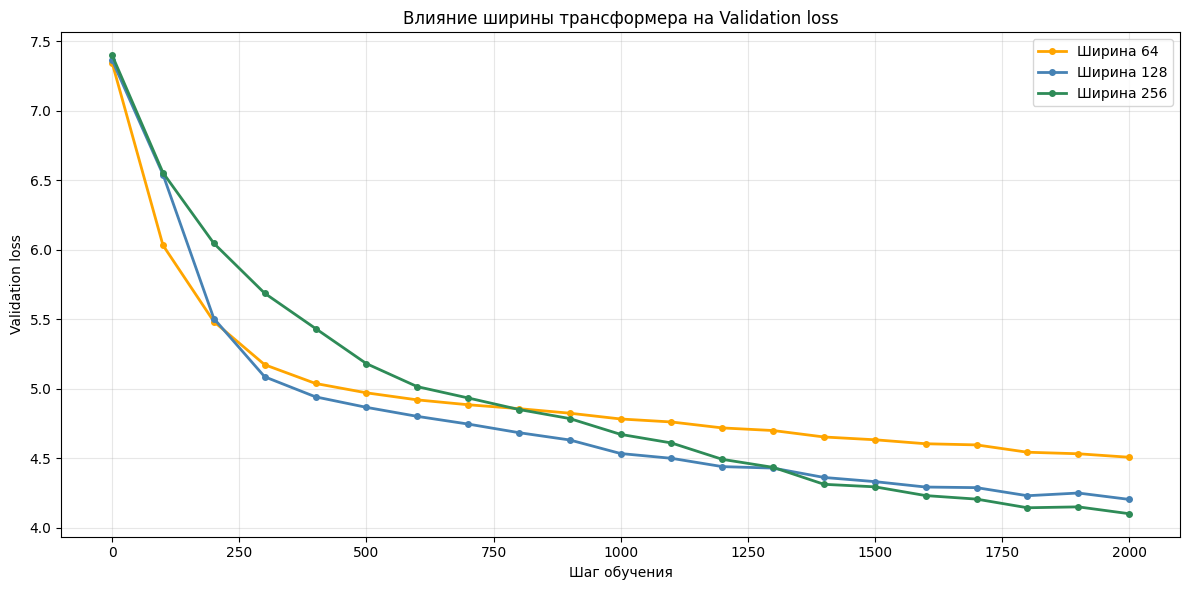

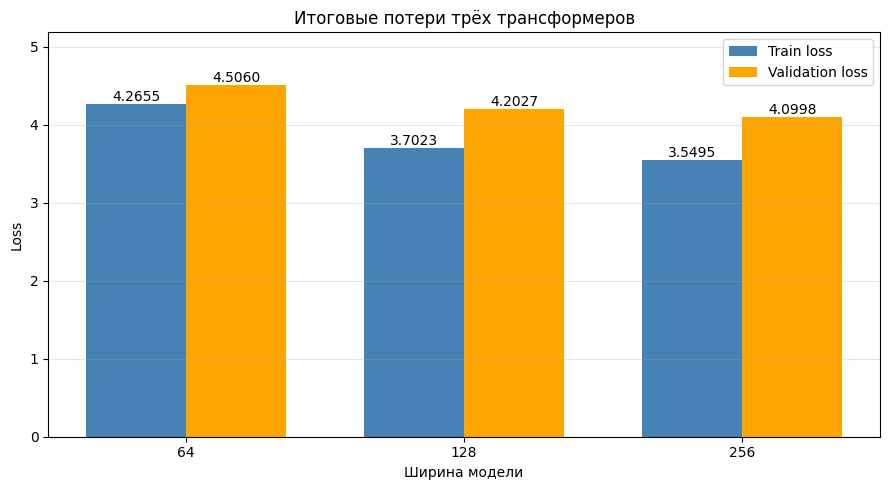

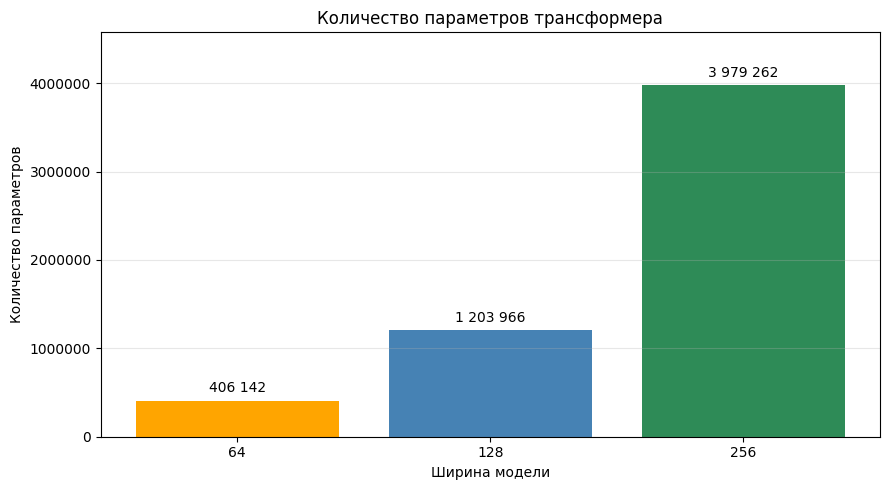

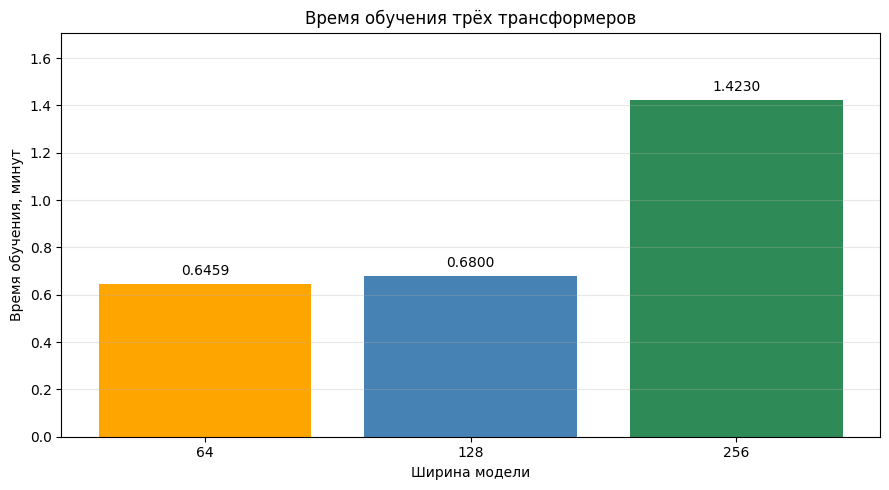


СРАВНЕНИЕ КРИВЫХ
128 обгоняет 64 на шаге: 300
256 обгоняет 64 на шаге: 800
256 обгоняет 128 на шаге: 1400

СРАВНЕНИЕ ИТОГОВЫХ ПОКАЗАТЕЛЕЙ
Лучшая ширина: 256
Лучший val loss: 4.099751949310303

Ширина 64 -> 128
Снижение val loss (%): 6.7319
Рост количества параметров (раз): 2.9644

Ширина 128 -> 256
Снижение val loss (%): 2.4493
Рост количества параметров (раз): 3.3051

Ширина 64 -> 256
Снижение val loss (%): 9.0163
Рост количества параметров (раз): 9.7977

АНАЛИЗ ОБОБЩАЮЩЕЙ СПОСОБНОСТИ
Ширина 64 | Val loss - Train loss: 0.2406
Ширина 128 | Val loss - Train loss: 0.5004
Ширина 256 | Val loss - Train loss: 0.5503

ИТОГОВАЯ ПРОВЕРКА
Обучены модели 64, 128, 256: True
Количество шагов одинаковое: True
Настройки эксперимента совпадают: True
Все значения loss корректны: True
Кривые CSV совпадают с JSON: True
Val loss уменьшился у всех моделей: True
График трёх кривых сохранён: True
График итоговых потерь сохранён: True
График параметров сохранён: True
График времени сохранён: True
Сводная та

In [19]:
# Построение графиков и анализ масштабирования

import json
import csv
import math
import matplotlib.pyplot as plt

from pathlib import Path

BASE_DIR = Path(
    "/content/drive/MyDrive/Лабораторная2_Попова_МТИ2532"
)

BONUS_DIR = BASE_DIR / "bonus"

# Загрузка сохранённых результатов

results_path = BONUS_DIR / "scaling_results.json"

with open(results_path, encoding="utf-8") as f:
    scaling_results = json.load(f)

scaling_results.sort(key=lambda r: r["d_model"])

widths = [r["d_model"] for r in scaling_results]

params = [r["n_params"] for r in scaling_results]

final_train = [
    r["final_train_loss"]
    for r in scaling_results
]

final_val = [
    r["final_val_loss"]
    for r in scaling_results
]

train_minutes = [
    r["train_minutes"]
    for r in scaling_results
]

colors = ["orange", "steelblue", "seagreen"]

print("РЕЗУЛЬТАТЫ МАСШТАБИРОВАНИЯ")
print("=" * 60)

for r in scaling_results:

    reduction = (
        r["initial_val_loss"] - r["final_val_loss"]
    )

    print("\nШирина модели:", r["d_model"])
    print("Количество параметров:", r["n_params"])
    print("Начальный val loss:", round(
        r["initial_val_loss"], 4
    ))
    print("Конечный train loss:", round(
        r["final_train_loss"], 4
    ))
    print("Конечный val loss:", round(
        r["final_val_loss"], 4
    ))
    print("Снижение val loss:", round(reduction, 4))
    print("Время обучения (мин.):", round(
        r["train_minutes"], 4
    ))

# ГРАФИК №1
# Три кривые Validation loss

plt.figure(figsize=(12, 6))

for r, color in zip(scaling_results, colors):

    steps = [
        row["step"]
        for row in r["history"]
    ]

    losses = [
        row["val_loss"]
        for row in r["history"]
    ]

    plt.plot(
        steps,
        losses,
        marker="o",
        markersize=4,
        linewidth=2,
        color=color,
        label=f"Ширина {r['d_model']}"
    )

plt.title(
    "Влияние ширины трансформера на Validation loss"
)

plt.xlabel("Шаг обучения")
plt.ylabel("Validation loss")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()

curve_graph = BONUS_DIR / "scaling_val_loss.png"

plt.savefig(curve_graph, dpi=150)
plt.show()
plt.close()

# ГРАФИК №2
# Итоговые функции потерь

plt.figure(figsize=(9, 5))

positions = list(range(len(widths)))

plt.bar(
    [x - 0.18 for x in positions],
    final_train,
    width=0.36,
    label="Train loss",
    color="steelblue"
)

plt.bar(
    [x + 0.18 for x in positions],
    final_val,
    width=0.36,
    label="Validation loss",
    color="orange"
)

for x, train, val in zip(
    positions, final_train, final_val
):

    plt.text(
        x - 0.18,
        train + 0.04,
        f"{train:.4f}",
        ha="center"
    )

    plt.text(
        x + 0.18,
        val + 0.04,
        f"{val:.4f}",
        ha="center"
    )

plt.xticks(
    positions,
    [str(w) for w in widths]
)

plt.title("Итоговые потери трёх трансформеров")
plt.xlabel("Ширина модели")
plt.ylabel("Loss")
plt.ylim(0, max(final_val) * 1.15)
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

final_graph = BONUS_DIR / "scaling_final_loss.png"

plt.savefig(final_graph, dpi=150)
plt.show()
plt.close()

# ГРАФИК №3
# Количество параметров

plt.figure(figsize=(9, 5))

bars = plt.bar(
    [str(w) for w in widths],
    params,
    color=colors
)

plt.bar_label(
    bars,
    labels=[f"{p:,}".replace(",", " ") for p in params],
    padding=4
)

plt.title("Количество параметров трансформера")
plt.xlabel("Ширина модели")
plt.ylabel("Количество параметров")
plt.ticklabel_format(
    style="plain",
    axis="y"
)

plt.ylim(0, max(params) * 1.15)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

params_graph = BONUS_DIR / "scaling_parameters.png"

plt.savefig(params_graph, dpi=150)
plt.show()
plt.close()

# ГРАФИК №4
# Время обучения

plt.figure(figsize=(9, 5))

bars = plt.bar(
    [str(w) for w in widths],
    train_minutes,
    color=colors
)

plt.bar_label(
    bars,
    fmt="%.4f",
    padding=4
)

plt.title("Время обучения трёх трансформеров")
plt.xlabel("Ширина модели")
plt.ylabel("Время обучения, минут")
plt.ylim(0, max(train_minutes) * 1.2)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

time_graph = BONUS_DIR / "scaling_time.png"

plt.savefig(time_graph, dpi=150)
plt.show()
plt.close()

# Анализ пересечения кривых

def first_better(result_a, result_b):

    history_a = result_a["history"]
    history_b = result_b["history"]

    assert [
        r["step"] for r in history_a
    ] == [
        r["step"] for r in history_b
    ]

    for a, b in zip(history_a, history_b):

        if (
            a["step"] > 0
            and a["val_loss"] < b["val_loss"]
        ):
            return a["step"]

    return None


step_128_64 = first_better(
    scaling_results[1],
    scaling_results[0]
)

step_256_64 = first_better(
    scaling_results[2],
    scaling_results[0]
)

step_256_128 = first_better(
    scaling_results[2],
    scaling_results[1]
)

print("\nСРАВНЕНИЕ КРИВЫХ")
print("=" * 60)

print("128 обгоняет 64 на шаге:", step_128_64)
print("256 обгоняет 64 на шаге:", step_256_64)
print("256 обгоняет 128 на шаге:", step_256_128)

# Сравнение итоговых результатов

best_model = min(
    scaling_results,
    key=lambda r: r["final_val_loss"]
)

print("\nСРАВНЕНИЕ ИТОГОВЫХ ПОКАЗАТЕЛЕЙ")
print("=" * 60)

print("Лучшая ширина:", best_model["d_model"])
print("Лучший val loss:", best_model["final_val_loss"])

for i, j in [(0, 1), (1, 2), (0, 2)]:

    improvement = (
        (final_val[i] - final_val[j])
        / final_val[i]
        * 100
    )

    growth = params[j] / params[i]

    print(
        f"\nШирина {widths[i]} -> {widths[j]}"
    )

    print(
        "Снижение val loss (%):",
        round(improvement, 4)
    )

    print(
        "Рост количества параметров (раз):",
        round(growth, 4)
    )

# Анализ разрыва между train и validation

print("\nАНАЛИЗ ОБОБЩАЮЩЕЙ СПОСОБНОСТИ")
print("=" * 60)

for r in scaling_results:

    gap = (
        r["final_val_loss"]
        - r["final_train_loss"]
    )

    print(
        f"Ширина {r['d_model']} | "
        f"Val loss - Train loss: {gap:.4f}"
    )

# Сохранение сводной таблицы

summary_path = BONUS_DIR / "scaling_summary.csv"

with open(
    summary_path,
    "w",
    encoding="utf-8",
    newline=""
) as f:

    writer = csv.writer(f)

    writer.writerow([
        "d_model",
        "n_params",
        "steps",
        "initial_train_loss",
        "initial_val_loss",
        "final_train_loss",
        "final_val_loss",
        "best_val_loss",
        "train_minutes",
        "generalization_gap"
    ])

    for r in scaling_results:

        writer.writerow([
            r["d_model"],
            r["n_params"],
            r["steps"],
            r["initial_train_loss"],
            r["initial_val_loss"],
            r["final_train_loss"],
            r["final_val_loss"],
            r["best_val_loss"],
            r["train_minutes"],
            r["final_val_loss"] - r["final_train_loss"]
        ])

# Итоговые проверки

expected_steps = list(range(0, 2001, 100))

same_steps = all(
    [row["step"] for row in r["history"]]
    == expected_steps
    for r in scaling_results
)

same_settings = all(
    len({r[key] for r in scaling_results}) == 1
    for key in [
        "steps",
        "batch",
        "context",
        "lr",
        "seed",
        "n_layers",
        "n_heads",
        "train_tokens",
        "val_tokens"
    ]
)

finite_losses = all(
    math.isfinite(row["train_loss"])
    and math.isfinite(row["val_loss"])
    for r in scaling_results
    for row in r["history"]
)

csv_matches = True

for r in scaling_results:

    path = BONUS_DIR / (
        f"scaling_{r['d_model']}.csv"
    )

    with open(path, encoding="utf-8") as f:

        rows = [
            {
                "step": int(row["step"]),
                "train_loss": float(row["train_loss"]),
                "val_loss": float(row["val_loss"])
            }
            for row in csv.DictReader(f)
        ]

    csv_matches = (
        csv_matches and rows == r["history"]
    )

loss_decreased = all(
    r["final_val_loss"] < r["initial_val_loss"]
    for r in scaling_results
)

checks = {
    "Обучены модели 64, 128, 256":
        widths == [64, 128, 256],

    "Количество шагов одинаковое":
        same_steps,

    "Настройки эксперимента совпадают":
        same_settings,

    "Все значения loss корректны":
        finite_losses,

    "Кривые CSV совпадают с JSON":
        csv_matches,

    "Val loss уменьшился у всех моделей":
        loss_decreased,

    "График трёх кривых сохранён":
        curve_graph.is_file(),

    "График итоговых потерь сохранён":
        final_graph.is_file(),

    "График параметров сохранён":
        params_graph.is_file(),

    "График времени сохранён":
        time_graph.is_file(),

    "Сводная таблица сохранена":
        summary_path.is_file()
}

print("\nИТОГОВАЯ ПРОВЕРКА")
print("=" * 60)

for name, value in checks.items():
    print(f"{name}: {value}")

assert all(checks.values())

print("\nСОХРАНЁННЫЕ ФАЙЛЫ")
print("=" * 60)

for path in [
    results_path,
    summary_path,
    curve_graph,
    final_graph,
    params_graph,
    time_graph
]:
    print(path)

print("\nБОНУС №3. ЗАКОН МАСШТАБИРОВАНИЯ РУКАМИ — ВЫПОЛНЕНО")

Бонус №4. Другой корпус.

Загрузка и подготовка корпуса Python.

In [20]:
# Загрузка и подготовка корпуса Python

from pathlib import Path

import subprocess
import json
import hashlib
import random

BASE_DIR = Path(
    "/content/drive/MyDrive/Лабораторная2_Попова_МТИ2532"
)

PYTHON_DIR = BASE_DIR / "bonus" / "python_corpus"

PYTHON_CHECKPOINTS = (
    BASE_DIR / "checkpoints" / "python_corpus"
)

PYTHON_DIR.mkdir(parents=True, exist_ok=True)
PYTHON_CHECKPOINTS.mkdir(parents=True, exist_ok=True)

REPO_URL = "https://github.com/django/django.git"
REPO_VERSION = "5.2"

REPO_PATH = Path("/content/django_source")

SEED = 42
TARGET_SIZE = 3_000_000

# Загрузка репозитория

print("ЗАГРУЗКА РЕПОЗИТОРИЯ")
print("=" * 60)

if not REPO_PATH.exists():

    subprocess.run(
        [
            "git",
            "clone",
            "--depth", "1",
            "--branch", REPO_VERSION,
            REPO_URL,
            str(REPO_PATH)
        ],
        check=True
    )

commit = subprocess.check_output(
    ["git", "-C", str(REPO_PATH), "rev-parse", "HEAD"],
    text=True
).strip()

print("Репозиторий:", REPO_URL)
print("Версия:", REPO_VERSION)
print("Commit:", commit)
print("Репозиторий загружен:", REPO_PATH.is_dir())

# Поиск файлов Python

source_files = sorted(
    (REPO_PATH / "django").rglob("*.py")
)

print("\nПОИСК ИСХОДНЫХ ФАЙЛОВ")
print("=" * 60)

print("Найдено файлов Python:", len(source_files))

# Воспроизводимый порядок файлов

rng = random.Random(SEED)
rng.shuffle(source_files)

selected_files = []
parts = []

total_bytes = 0

# Формирование корпуса объёмом около 3 МБ

for path in source_files:

    try:
        text = path.read_text(encoding="utf-8")

    except UnicodeDecodeError:
        continue

    if not text.strip():
        continue

    # Сохраняем регистр, отступы,
    # знаки препинания и переносы строк

    if not text.endswith("\n"):
        text += "\n"

    text += "\n"

    size = len(text.encode("utf-8"))

    if total_bytes + size > 5_000_000:
        continue

    selected_files.append({
        "file": str(path.relative_to(REPO_PATH)),
        "bytes": size
    })

    parts.append(text)

    total_bytes += size

    if total_bytes >= TARGET_SIZE:
        break

corpus = "".join(parts)

corpus_path = PYTHON_DIR / "corpus_python.txt"

corpus_path.write_text(
    corpus,
    encoding="utf-8"
)

# Разделение по границам файлов

split_index = int(len(parts) * 0.9)

python_train_text = "".join(
    parts[:split_index]
)

python_val_text = "".join(
    parts[split_index:]
)

train_path = PYTHON_DIR / "train_python.txt"
val_path = PYTHON_DIR / "val_python.txt"

train_path.write_text(
    python_train_text,
    encoding="utf-8"
)

val_path.write_text(
    python_val_text,
    encoding="utf-8"
)

# Статистика корпуса

stats = {
    "repository": REPO_URL,
    "version": REPO_VERSION,
    "commit": commit,
    "seed": SEED,
    "files": len(selected_files),
    "train_files": split_index,
    "val_files": len(parts) - split_index,
    "bytes": corpus_path.stat().st_size,
    "characters": len(corpus),
    "lines": len(corpus.splitlines()),
    "unique_characters": len(set(corpus)),
    "spaces": corpus.count(" "),
    "newlines": corpus.count("\n"),
    "tabs": corpus.count("\t"),
    "train_characters": len(python_train_text),
    "val_characters": len(python_val_text),
    "sha256": hashlib.sha256(
        corpus.encode("utf-8")
    ).hexdigest()
}

stats_path = PYTHON_DIR / "python_corpus_stats.json"

with open(stats_path, "w", encoding="utf-8") as f:

    json.dump(
        stats,
        f,
        ensure_ascii=False,
        indent=2
    )

manifest_path = PYTHON_DIR / "source_files.json"

with open(manifest_path, "w", encoding="utf-8") as f:

    json.dump(
        selected_files,
        f,
        ensure_ascii=False,
        indent=2
    )

# Вывод результатов

print("\nСТАТИСТИКА КОРПУСА PYTHON")
print("=" * 60)

print("Количество файлов:", stats["files"])
print("Размер корпуса (байт):", stats["bytes"])
print("Размер корпуса (МБ):", round(
    stats["bytes"] / 1_000_000, 4
))
print("Количество символов:", stats["characters"])
print("Количество строк:", stats["lines"])
print("Уникальных символов:", stats["unique_characters"])
print("Пробелов:", stats["spaces"])
print("Переносов строк:", stats["newlines"])
print("Табуляций:", stats["tabs"])

print("\nОБУЧАЮЩАЯ ВЫБОРКА")
print("=" * 60)

print("Файлов:", stats["train_files"])
print("Символов:", len(python_train_text))

print("\nПРОВЕРОЧНАЯ ВЫБОРКА")
print("=" * 60)

print("Файлов:", stats["val_files"])
print("Символов:", len(python_val_text))

print("\nПРИМЕР ИСХОДНОГО КОДА")
print("=" * 60)

print(corpus[:1500])

# Итоговые проверки

checks = {
    "Размер корпуса от 2 до 5 МБ":
        2_000_000 <= stats["bytes"] <= 5_000_000,

    "Отступы сохранены":
        "\n    " in corpus,

    "Переносы строк сохранены":
        "\n" in corpus,

    "Регистр сохранён":
        any(c.isupper() for c in corpus),

    "Обучающая выборка непустая":
        len(python_train_text) > 0,

    "Проверочная выборка непустая":
        len(python_val_text) > 0,

    "Разделение корпуса корректно":
        python_train_text + python_val_text == corpus,

    "Корпус восстановлен без изменений":
        corpus_path.read_text(encoding="utf-8") == corpus,

    "Статистика сохранена":
        stats_path.is_file(),

    "Список исходных файлов сохранён":
        manifest_path.is_file()
}

print("\nИТОГОВАЯ ПРОВЕРКА")
print("=" * 60)

for name, result in checks.items():
    print(f"{name}: {result}")

assert all(checks.values())

print("\nСОХРАНЁННЫЕ ФАЙЛЫ")
print("=" * 60)

for path in PYTHON_DIR.iterdir():
    if path.is_file():
        print(path.name, "-", path.stat().st_size, "байт")

print("\nПуть:", PYTHON_DIR)

print("\nПодготовка корпуса Python завершена")

ЗАГРУЗКА РЕПОЗИТОРИЯ
Репозиторий: https://github.com/django/django.git
Версия: 5.2
Commit: 9e7cc2b628fe8fd3895986af9b7fc9525034c1b0
Репозиторий загружен: True

ПОИСК ИСХОДНЫХ ФАЙЛОВ
Найдено файлов Python: 883

СТАТИСТИКА КОРПУСА PYTHON
Количество файлов: 400
Размер корпуса (байт): 3002801
Размер корпуса (МБ): 3.0028
Количество символов: 3002313
Количество строк: 84767
Уникальных символов: 135
Пробелов: 861736
Переносов строк: 84767
Табуляций: 0

ОБУЧАЮЩАЯ ВЫБОРКА
Файлов: 360
Символов: 2666529

ПРОВЕРОЧНАЯ ВЫБОРКА
Файлов: 40
Символов: 335784

ПРИМЕР ИСХОДНОГО КОДА
import string

from django.core.exceptions import ImproperlyConfigured, ValidationError
from django.db import models
from django.db.models.signals import pre_delete, pre_save
from django.http.request import split_domain_port
from django.utils.translation import gettext_lazy as _

SITE_CACHE = {}


def _simple_domain_name_validator(value):
    """
    Validate that the given value contains no whitespaces to prevent common
    t

Обучение собственного BPE на исходном коде Python.

In [21]:
# Обучение собственного BPE

from pathlib import Path
from collections import Counter, defaultdict
from functools import lru_cache

import re
import json
import time

BASE_DIR = Path(
    "/content/drive/MyDrive/Лабораторная2_Попова_МТИ2532"
)

PYTHON_DIR = BASE_DIR / "bonus" / "python_corpus"

NUM_MERGES = 1500
BASE_VOCAB_SIZE = 256

# Восстановление корпуса

python_train_text = (
    PYTHON_DIR / "train_python.txt"
).read_text(encoding="utf-8")

python_val_text = (
    PYTHON_DIR / "val_python.txt"
).read_text(encoding="utf-8")

print("ИСХОДНЫЕ ДАННЫЕ")
print("=" * 60)

print("Обучающих символов:", len(python_train_text))
print("Проверочных символов:", len(python_val_text))
print("Количество слияний:", NUM_MERGES)

# Предварительное разбиение текста
# Сохраняем все символы исходного кода

PYTHON_PATTERN = (
    r"[^\W\d]\w*|\d+|[ \t]+|\r\n|\n|\r|[^\w\s]+|."
)

python_regex = re.compile(
    PYTHON_PATTERN,
    flags=re.DOTALL
)

def split_python(text):
    return python_regex.findall(text)

train_parts = split_python(python_train_text)

assert "".join(train_parts) == python_train_text

# Частоты последовательностей байтов

frequencies = Counter(
    tuple(part.encode("utf-8"))
    for part in train_parts
)

del train_parts

sequences = list(frequencies.keys())
weights = list(frequencies.values())

print("\nПОДГОТОВКА BPE")
print("=" * 60)

print("Исходный словарь:", BASE_VOCAB_SIZE)
print("Уникальных фрагментов:", len(sequences))
print("Фрагментов всего:", sum(weights))

# Замена соседних пар

def merge_python_pair(sequence, pair, new_id):

    result = []
    i = 0

    while i < len(sequence):

        if (
            i + 1 < len(sequence)
            and (sequence[i], sequence[i + 1]) == pair
        ):

            result.append(new_id)
            i += 2

        else:

            result.append(sequence[i])
            i += 1

    return tuple(result)

# Подсчёт частот пар

pair_counts = Counter()
pair_locations = defaultdict(set)

for index, sequence in enumerate(sequences):

    local_counts = Counter(
        zip(sequence, sequence[1:])
    )

    for pair, count in local_counts.items():

        pair_counts[pair] += count * weights[index]
        pair_locations[pair].add(index)

# Обучение BPE

python_merges = []

start_time = time.perf_counter()

print("\nОБУЧЕНИЕ BPE")
print("=" * 60)

for step in range(NUM_MERGES):

    if not pair_counts:
        break

    # Наиболее частая пара
    # При равенстве частот — фиксированный порядок

    best_pair = min(
        pair_counts,
        key=lambda pair: (
            -pair_counts[pair],
            pair
        )
    )

    best_count = pair_counts[best_pair]

    new_id = BASE_VOCAB_SIZE + step

    affected = list(
        pair_locations[best_pair]
    )

    for index in affected:

        old_sequence = sequences[index]
        weight = weights[index]

        old_pairs = Counter(
            zip(old_sequence, old_sequence[1:])
        )

        # Удаляем прежние частоты

        for pair, count in old_pairs.items():

            pair_counts[pair] -= count * weight
            pair_locations[pair].discard(index)

            if pair_counts[pair] == 0:

                del pair_counts[pair]
                del pair_locations[pair]

        # Выполняем слияние

        new_sequence = merge_python_pair(
            old_sequence,
            best_pair,
            new_id
        )

        sequences[index] = new_sequence

        # Добавляем обновлённые частоты

        new_pairs = Counter(
            zip(new_sequence, new_sequence[1:])
        )

        for pair, count in new_pairs.items():

            pair_counts[pair] += count * weight
            pair_locations[pair].add(index)

    python_merges.append(best_pair)

    if (step + 1) % 100 == 0:

        print(
            f"Слияние {step + 1:4d}/{NUM_MERGES}"
            f" | Частота пары: {best_count}"
            f" | Словарь: {new_id + 1}"
        )

python_bpe_seconds = (
    time.perf_counter() - start_time
)

python_vocab_size = (
    BASE_VOCAB_SIZE + len(python_merges)
)

# Восстановление словаря байтов

python_id_to_bytes = {
    i: bytes([i])
    for i in range(BASE_VOCAB_SIZE)
}

python_merge_ranks = {}

for rank, pair in enumerate(python_merges):

    new_id = BASE_VOCAB_SIZE + rank

    python_merge_ranks[pair] = rank

    python_id_to_bytes[new_id] = (
        python_id_to_bytes[pair[0]]
        + python_id_to_bytes[pair[1]]
    )

# Кодирование фрагментов по рангам слияний

@lru_cache(maxsize=100000)
def encode_python_part(part):

    sequence = tuple(
        part.encode("utf-8")
    )

    while len(sequence) > 1:

        pairs = list(
            zip(sequence, sequence[1:])
        )

        best_pair = min(
            pairs,
            key=lambda pair:
                python_merge_ranks.get(
                    pair,
                    float("inf")
                )
        )

        if best_pair not in python_merge_ranks:
            break

        new_id = (
            BASE_VOCAB_SIZE
            + python_merge_ranks[best_pair]
        )

        sequence = merge_python_pair(
            sequence,
            best_pair,
            new_id
        )

    return sequence

def encode_python(text):

    return [
        token_id
        for part in split_python(text)
        for token_id in encode_python_part(part)
    ]

def decode_python(ids, errors="strict"):

    return b"".join(
        python_id_to_bytes[int(token_id)]
        for token_id in ids
    ).decode("utf-8", errors=errors)

# Результаты обучения

print("\nРЕЗУЛЬТАТЫ ОБУЧЕНИЯ BPE")
print("=" * 60)

print("Исходный словарь:", BASE_VOCAB_SIZE)
print("Количество слияний:", len(python_merges))
print("Итоговый размер словаря:", python_vocab_size)

print(
    "Время обучения (сек.):",
    round(python_bpe_seconds, 4)
)

print("\nПЕРВЫЕ 20 СЛИЯНИЙ")
print("=" * 60)

for rank, pair in enumerate(python_merges[:20]):

    new_id = BASE_VOCAB_SIZE + rank

    token = python_id_to_bytes[new_id].decode(
        "utf-8",
        errors="replace"
    )

    print(
        rank + 1,
        "| ID:", new_id,
        "| Токен:", repr(token)
    )

# Проверка токенизации

examples = [
    "def calculate_sum(a, b):\n    return a + b\n",
    "class Transformer(nn.Module):\n",
    "    self.model = model\n",
    "        if value is None:\n",
    "import torch\n",
    "result = [x ** 2 for x in values]\n",
    "def __init__(self):\n",
    python_train_text[:1000],
    python_val_text[:1000]
]

all_restored = True
all_ids_correct = True

print("\nПРИМЕРЫ ТОКЕНИЗАЦИИ")
print("=" * 60)

for example in examples:

    ids = encode_python(example)
    restored = decode_python(ids)

    correct = restored == example

    all_restored &= correct

    all_ids_correct &= all(
        0 <= token_id < python_vocab_size
        for token_id in ids
    )

    print("\nИсходный текст:", repr(example[:100]))

    print(
        "Токены:",
        [
            python_id_to_bytes[i].decode(
                "utf-8",
                errors="replace"
            )
            for i in ids[:30]
        ]
    )

    print("Идентификаторы:", ids[:30])
    print("Количество токенов:", len(ids))
    print("Точное восстановление:", correct)

# Сохранение токенизатора

python_bpe_data = {
    "algorithm": "byte_level_bpe",
    "base_vocab_size": BASE_VOCAB_SIZE,
    "num_merges": len(python_merges),
    "vocab_size": python_vocab_size,
    "pretoken_pattern": PYTHON_PATTERN,
    "merges": [
        list(pair)
        for pair in python_merges
    ],
    "train_seconds": python_bpe_seconds
}

python_bpe_path = (
    PYTHON_DIR / "python_bpe.json"
)

with open(
    python_bpe_path,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        python_bpe_data,
        f,
        ensure_ascii=False,
        indent=2
    )

# Проверка сохранения

with open(
    python_bpe_path,
    encoding="utf-8"
) as f:

    restored_bpe = json.load(f)

checks = {
    "Выполнено 1500 слияний":
        len(python_merges) == NUM_MERGES,

    "Размер словаря корректен":
        python_vocab_size == 1756,

    "Все пары слияний уникальны":
        len(set(python_merges)) == NUM_MERGES,

    "Все примеры восстановлены точно":
        all_restored,

    "Идентификаторы корректны":
        all_ids_correct,

    "Отступы и переносы сохранены":
        decode_python(
            encode_python(examples[0])
        ) == examples[0],

    "Токенизатор сохранён":
        python_bpe_path.is_file(),

    "Проверка восстановления JSON":
        restored_bpe == python_bpe_data
}

print("\nИТОГОВАЯ ПРОВЕРКА")
print("=" * 60)

for name, result in checks.items():

    print(f"{name}: {result}")

assert all(checks.values())

print("\nСОХРАНЕНИЕ")
print("=" * 60)

print("Файл:", python_bpe_path)
print("Размер файла:", python_bpe_path.stat().st_size)

print("\nОбучение BPE для Python завершено")

ИСХОДНЫЕ ДАННЫЕ
Обучающих символов: 2666529
Проверочных символов: 335784
Количество слияний: 1500

ПОДГОТОВКА BPE
Исходный словарь: 256
Уникальных фрагментов: 17627
Фрагментов всего: 740418

ОБУЧЕНИЕ BPE
Слияние  100/1500 | Частота пары: 2572 | Словарь: 356
Слияние  200/1500 | Частота пары: 1155 | Словарь: 456
Слияние  300/1500 | Частота пары: 730 | Словарь: 556
Слияние  400/1500 | Частота пары: 499 | Словарь: 656
Слияние  500/1500 | Частота пары: 382 | Словарь: 756
Слияние  600/1500 | Частота пары: 314 | Словарь: 856
Слияние  700/1500 | Частота пары: 252 | Словарь: 956
Слияние  800/1500 | Частота пары: 215 | Словарь: 1056
Слияние  900/1500 | Частота пары: 184 | Словарь: 1156
Слияние 1000/1500 | Частота пары: 163 | Словарь: 1256
Слияние 1100/1500 | Частота пары: 145 | Словарь: 1356
Слияние 1200/1500 | Частота пары: 129 | Словарь: 1456
Слияние 1300/1500 | Частота пары: 113 | Словарь: 1556
Слияние 1400/1500 | Частота пары: 103 | Словарь: 1656
Слияние 1500/1500 | Частота пары: 94 | Словар

Токенизация корпуса Python.

In [22]:
# Токенизация корпуса Python

import torch
import json
import time

from pathlib import Path

BASE_DIR = Path(
    "/content/drive/MyDrive/Лабораторная2_Попова_МТИ2532"
)

PYTHON_DIR = BASE_DIR / "bonus" / "python_corpus"

print("ТОКЕНИЗАЦИЯ КОРПУСА PYTHON")
print("=" * 60)

start_time = time.perf_counter()

# Токенизация обучающей выборки

print("Обработка обучающей выборки...")

python_train_ids = torch.tensor(
    encode_python(python_train_text),
    dtype=torch.long
)

print("Обучающая выборка обработана")

# Токенизация проверочной выборки

print("\nОбработка проверочной выборки...")

python_val_ids = torch.tensor(
    encode_python(python_val_text),
    dtype=torch.long
)

print("Проверочная выборка обработана")

tokenization_seconds = (
    time.perf_counter() - start_time
)

# Статистика

train_chars = len(python_train_text)
val_chars = len(python_val_text)

train_tokens = python_train_ids.numel()
val_tokens = python_val_ids.numel()

total_chars = train_chars + val_chars
total_tokens = train_tokens + val_tokens

train_compression = train_chars / train_tokens
val_compression = val_chars / val_tokens

total_compression = total_chars / total_tokens

print("\nСТАТИСТИКА ТОКЕНИЗАЦИИ")
print("=" * 60)

print("Всего символов:", total_chars)
print("Всего токенов:", total_tokens)
print("Размер словаря:", python_vocab_size)

print("\nОбучающая выборка:")

print("Количество символов:", train_chars)
print("Количество токенов:", train_tokens)
print("Размерность тензора:", python_train_ids.shape)

print(
    "Символов на токен:",
    round(train_compression, 4)
)

print("\nПроверочная выборка:")

print("Количество символов:", val_chars)
print("Количество токенов:", val_tokens)
print("Размерность тензора:", python_val_ids.shape)

print(
    "Символов на токен:",
    round(val_compression, 4)
)

print(
    "\nСреднее количество символов на токен:",
    round(total_compression, 4)
)

print("Тип данных:", python_train_ids.dtype)

print(
    "Время токенизации (сек.):",
    round(tokenization_seconds, 4)
)

# Проверка полного восстановления корпуса

print("\nПРОВЕРКА ВОССТАНОВЛЕНИЯ КОРПУСА")
print("=" * 60)

restored_train = decode_python(
    python_train_ids.tolist()
)

restored_val = decode_python(
    python_val_ids.tolist()
)

train_restored_correct = (
    restored_train == python_train_text
)

val_restored_correct = (
    restored_val == python_val_text
)

print(
    "Обучающий корпус восстановлен точно:",
    train_restored_correct
)

print(
    "Проверочный корпус восстановлен точно:",
    val_restored_correct
)

# Пример токенизации

print("\nПРИМЕР ТОКЕНИЗАЦИИ")
print("=" * 60)

print("Первые 60 обучающих токенов:")

print(python_train_ids[:60].tolist())

print("\nВосстановленный исходный код:")

print(
    decode_python(
        python_train_ids[:60].tolist(),
        errors="replace"
    )
)

# Анализ токенов форматирования

print("\nТОКЕНЫ ФОРМАТИРОВАНИЯ")
print("=" * 60)

for fragment in [" ", "  ", "    ", "        ", "\n"]:

    fragment_ids = encode_python(fragment)

    print(
        repr(fragment),
        "->",
        fragment_ids
    )

# Сохранение тензоров

python_train_path = (
    PYTHON_DIR / "train_ids.pt"
)

python_val_path = (
    PYTHON_DIR / "val_ids.pt"
)

torch.save(
    python_train_ids,
    python_train_path
)

torch.save(
    python_val_ids,
    python_val_path
)

# Сохранение статистики

python_token_stats = {
    "vocab_size": python_vocab_size,
    "bpe_merges": len(python_merges),
    "train_chars": train_chars,
    "val_chars": val_chars,
    "total_chars": total_chars,
    "train_tokens": train_tokens,
    "val_tokens": val_tokens,
    "total_tokens": total_tokens,
    "train_chars_per_token": train_compression,
    "val_chars_per_token": val_compression,
    "chars_per_token": total_compression,
    "tokenization_seconds": tokenization_seconds
}

python_stats_path = (
    PYTHON_DIR / "tokenization_stats.json"
)

with open(
    python_stats_path,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        python_token_stats,
        f,
        ensure_ascii=False,
        indent=2
    )

# Восстановление сохранённых тензоров

loaded_python_train = torch.load(
    python_train_path,
    map_location="cpu",
    weights_only=True
)

loaded_python_val = torch.load(
    python_val_path,
    map_location="cpu",
    weights_only=True
)

# Итоговые проверки

checks = {

    "Обучающий корпус восстановлен точно":
        train_restored_correct,

    "Проверочный корпус восстановлен точно":
        val_restored_correct,

    "Обучающие идентификаторы корректны":
        bool(
            (python_train_ids >= 0).all()
            and
            (python_train_ids < python_vocab_size).all()
        ),

    "Проверочные идентификаторы корректны":
        bool(
            (python_val_ids >= 0).all()
            and
            (python_val_ids < python_vocab_size).all()
        ),

    "Обучающая выборка одномерная":
        python_train_ids.ndim == 1,

    "Проверочная выборка одномерная":
        python_val_ids.ndim == 1,

    "Обучающих токенов достаточно":
        train_tokens > 128,

    "Проверочных токенов достаточно":
        val_tokens > 128,

    "Обучающая выборка сохранена корректно":
        torch.equal(
            python_train_ids,
            loaded_python_train
        ),

    "Проверочная выборка сохранена корректно":
        torch.equal(
            python_val_ids,
            loaded_python_val
        ),

    "Статистика сохранена":
        python_stats_path.is_file()
}

print("\nИТОГОВАЯ ПРОВЕРКА")
print("=" * 60)

for name, result in checks.items():

    print(f"{name}: {result}")

assert all(checks.values())

# Сохранённые файлы

print("\nСОХРАНЁННЫЕ ФАЙЛЫ")
print("=" * 60)

for path in [
    python_train_path,
    python_val_path,
    python_stats_path
]:

    print(
        path.name,
        "-",
        path.stat().st_size,
        "байт"
    )

print("\nПуть:", PYTHON_DIR)

print("\nТокенизация корпуса Python завершена")

ТОКЕНИЗАЦИЯ КОРПУСА PYTHON
Обработка обучающей выборки...
Обучающая выборка обработана

Обработка проверочной выборки...
Проверочная выборка обработана

СТАТИСТИКА ТОКЕНИЗАЦИИ
Всего символов: 3002313
Всего токенов: 1073539
Размер словаря: 1756

Обучающая выборка:
Количество символов: 2666529
Количество токенов: 949846
Размерность тензора: torch.Size([949846])
Символов на токен: 2.8073

Проверочная выборка:
Количество символов: 335784
Количество токенов: 123693
Размерность тензора: torch.Size([123693])
Символов на токен: 2.7147

Среднее количество символов на токен: 2.7967
Тип данных: torch.int64
Время токенизации (сек.): 3.1459

ПРОВЕРКА ВОССТАНОВЛЕНИЯ КОРПУСА
Обучающий корпус восстановлен точно: True
Проверочный корпус восстановлен точно: True

ПРИМЕР ТОКЕНИЗАЦИИ
Первые 60 обучающих токенов:
[373, 32, 568, 10, 10, 350, 32, 390, 46, 1054, 46, 1372, 32, 373, 32, 1524, 44, 32, 1449, 10, 350, 32, 390, 46, 426, 32, 373, 32, 504, 10, 350, 32, 390, 46, 426, 46, 504, 46, 1658, 115, 32, 373, 3

Обучение трансформера на Python.

In [23]:
# Обучение трансформера на Python

import torch
import torch.nn.functional as F
import json
import csv
import math
import time
import os
import sys

from pathlib import Path

# 1. Рабочие папки

BASE_DIR = Path(
    "/content/drive/MyDrive/Лабораторная2_Попова_МТИ2532"
)

PYTHON_DIR = BASE_DIR / "bonus" / "python_corpus"

PYTHON_RESULTS = PYTHON_DIR / "results"
PYTHON_CHECKPOINTS = PYTHON_DIR / "checkpoints"

PYTHON_RESULTS.mkdir(parents=True, exist_ok=True)
PYTHON_CHECKPOINTS.mkdir(parents=True, exist_ok=True)

# 2. Загрузка архитектуры из основной части

sys.path.insert(0, str(BASE_DIR / "scripts"))

from model import TinyTransformer

# 3. Параметры эксперимента

PY_SEED = 42
PY_VOCAB_SIZE = 1756
PY_D_MODEL = 128
PY_N_LAYERS = 4
PY_N_HEADS = 4
PY_D_FF = 512
PY_CONTEXT = 128

PY_STEPS = 2000
PY_BATCH = 32
PY_LR = 0.001
PY_EVAL_WINDOWS = 20
PY_EVAL_EVERY = 100

PY_SAMPLE_STEPS = [0, 100, 500, 2000]

python_device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

torch.manual_seed(PY_SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(PY_SEED)

# 4. Восстановление подготовленных данных

python_train_ids = torch.load(
    PYTHON_DIR / "train_ids.pt",
    map_location="cpu",
    weights_only=True
)

python_val_ids = torch.load(
    PYTHON_DIR / "val_ids.pt",
    map_location="cpu",
    weights_only=True
)

# 5. Создание новой модели

python_model = TinyTransformer(
    vocab_size=PY_VOCAB_SIZE,
    d_model=PY_D_MODEL,
    n_layers=PY_N_LAYERS,
    n_heads=PY_N_HEADS,
    d_ff=PY_D_FF,
    context=PY_CONTEXT
).to(python_device)

python_n_params = sum(
    p.numel()
    for p in python_model.parameters()
)

python_optimizer = torch.optim.AdamW(
    python_model.parameters(),
    lr=PY_LR
)

print("ПАРАМЕТРЫ ЭКСПЕРИМЕНТА")
print("=" * 60)

print("Устройство:", python_device)

if torch.cuda.is_available():
    print(
        "Видеокарта:",
        torch.cuda.get_device_name(0)
    )

print("Размер словаря:", PY_VOCAB_SIZE)
print("Количество параметров:", python_n_params)
print("Ширина модели:", PY_D_MODEL)
print("Количество слоёв:", PY_N_LAYERS)
print("Количество голов:", PY_N_HEADS)
print("Длина контекста:", PY_CONTEXT)
print("Количество шагов:", PY_STEPS)
print("Размер батча:", PY_BATCH)
print("Оптимизатор: AdamW")
print("Скорость обучения:", PY_LR)
print("Seed:", PY_SEED)
print("Обучающих токенов:", len(python_train_ids))
print("Проверочных токенов:", len(python_val_ids))

# 6. Генераторы случайных чисел

python_train_rng = torch.Generator(
    device="cpu"
).manual_seed(PY_SEED)

python_val_rng = torch.Generator(
    device="cpu"
).manual_seed(PY_SEED + 1)

# 7. Формирование батчей

def python_get_batch(data, batch_size, generator):

    starts = torch.randint(
        0,
        len(data) - PY_CONTEXT,
        (batch_size,),
        generator=generator
    )

    x = torch.stack([
        data[i:i + PY_CONTEXT]
        for i in starts.tolist()
    ])

    y = torch.stack([
        data[i + 1:i + PY_CONTEXT + 1]
        for i in starts.tolist()
    ])

    return (
        x.to(python_device),
        y.to(python_device)
    )

# Фиксированные проверочные окна

python_val_x, python_val_y = python_get_batch(
    python_val_ids,
    PY_EVAL_WINDOWS,
    python_val_rng
)

# 8. Получение логитов

def python_get_logits(x):

    output = python_model(x)

    if isinstance(output, (tuple, list)):
        return output[0]

    return output

# 9. Вычисление функции потерь

def python_loss(x, y):

    logits = python_get_logits(x)

    return F.cross_entropy(
        logits.reshape(-1, PY_VOCAB_SIZE),
        y.reshape(-1)
    )

# 10. Оценка на проверочной выборке

@torch.no_grad()
def python_evaluate():

    previous_mode = python_model.training

    python_model.eval()

    loss = python_loss(
        python_val_x,
        python_val_y
    ).item()

    python_model.train(previous_mode)

    return loss

# 11. Генерация исходного кода

@torch.no_grad()
def python_generate(
    prompt,
    max_new_tokens=100,
    temperature=0.8,
    seed=42
):

    previous_mode = python_model.training

    python_model.eval()

    ids = list(encode_python(prompt))

    generator = torch.Generator(
        device="cpu"
    ).manual_seed(seed)

    for _ in range(max_new_tokens):

        x = torch.tensor(
            [ids[-PY_CONTEXT:]],
            dtype=torch.long,
            device=python_device
        )

        logits = python_get_logits(x)[0, -1]

        if temperature == 0:

            next_id = logits.argmax().item()

        else:

            probabilities = F.softmax(
                logits.float() / temperature,
                dim=-1
            ).cpu()

            next_id = torch.multinomial(
                probabilities,
                num_samples=1,
                generator=generator
            ).item()

        ids.append(next_id)

    text = decode_python(
        ids,
        errors="replace"
    )

    python_model.train(previous_mode)

    return text

# 12. Затравки для наблюдения за обучением

python_prompts = [
    "def ",
    "class ",
    "def calculate_sum(a, b):\n    "
]


def collect_python_samples(step):

    result = []

    print("\nОБРАЗЦЫ НА ШАГЕ", step)
    print("=" * 60)

    for prompt in python_prompts:

        text = python_generate(
            prompt=prompt,
            max_new_tokens=100,
            temperature=0.8,
            seed=PY_SEED
        )

        result.append({
            "step": step,
            "prompt": prompt,
            "text": text
        })

        print("\nЗатравка:", repr(prompt))
        print("Сгенерированный код:")
        print(text)

    return result

# 13. Контрольные точки

python_checkpoint_path = (
    PYTHON_CHECKPOINTS / "latest.pt"
)

python_history = []
python_samples = []

start_step = 0
elapsed_before = 0.0

# Восстановление при прерывании обучения

if python_checkpoint_path.is_file():

    checkpoint = torch.load(
        python_checkpoint_path,
        map_location="cpu",
        weights_only=True
    )

    python_model.load_state_dict(
        checkpoint["model_state_dict"]
    )

    python_optimizer.load_state_dict(
        checkpoint["optimizer_state_dict"]
    )

    python_train_rng.set_state(
        checkpoint["train_rng_state"]
    )

    python_history = checkpoint["history"]
    python_samples = checkpoint["samples"]

    start_step = checkpoint["step"]
    elapsed_before = checkpoint["elapsed_seconds"]

    print("\nКОНТРОЛЬНАЯ ТОЧКА ВОССТАНОВЛЕНА")
    print("Последний сохранённый шаг:", start_step)

else:

    print("\nОбучение начинается с нуля")

# 14. Функция сохранения контрольной точки

training_start = time.perf_counter()


def save_python_checkpoint(step):

    elapsed = (
        elapsed_before
        + time.perf_counter()
        - training_start
    )

    checkpoint = {
        "step": step,
        "model_state_dict":
            python_model.state_dict(),
        "optimizer_state_dict":
            python_optimizer.state_dict(),
        "train_rng_state":
            python_train_rng.get_state(),
        "history": python_history,
        "samples": python_samples,
        "elapsed_seconds": elapsed
    }

    temporary_path = (
        PYTHON_CHECKPOINTS / "latest.tmp"
    )

    torch.save(
        checkpoint,
        temporary_path
    )

    os.replace(
        temporary_path,
        python_checkpoint_path
    )

    print(
        "Контрольная точка",
        step,
        "сохранена"
    )

# 15. Начальная оценка

if start_step == 0:

    python_model.eval()

    with torch.no_grad():

        x0, y0 = python_get_batch(
            python_train_ids,
            PY_BATCH,
            torch.Generator().manual_seed(PY_SEED)
        )

        initial_train_loss = python_loss(
            x0, y0
        ).item()

    initial_val_loss = python_evaluate()

    python_history = [{
        "step": 0,
        "train_loss": initial_train_loss,
        "val_loss": initial_val_loss
    }]

    print("\nНАЧАЛЬНЫЕ ПОКАЗАТЕЛИ")
    print("=" * 60)

    print("Train loss:", initial_train_loss)
    print("Val loss:", initial_val_loss)

    print(
        "Теоретический loss:",
        math.log(PY_VOCAB_SIZE)
    )

    python_samples = collect_python_samples(0)

    save_python_checkpoint(0)

# 16. Обучение трансформера

python_model.train()

interval_losses = []

print("\nОБУЧЕНИЕ ТРАНСФОРМЕРА НА PYTHON")
print("=" * 60)

for step in range(start_step + 1, PY_STEPS + 1):

    x, y = python_get_batch(
        python_train_ids,
        PY_BATCH,
        python_train_rng
    )

    python_optimizer.zero_grad(
        set_to_none=True
    )

    loss = python_loss(x, y)

    if not torch.isfinite(loss):

        raise RuntimeError(
            "Обнаружен некорректный loss"
        )

    loss.backward()

    python_optimizer.step()

    interval_losses.append(loss.item())

    if (
        step % PY_EVAL_EVERY == 0
        or step == PY_STEPS
    ):

        train_loss = (
            sum(interval_losses)
            / len(interval_losses)
        )

        val_loss = python_evaluate()

        python_history.append({
            "step": step,
            "train_loss": train_loss,
            "val_loss": val_loss
        })

        print(
            f"Шаг {step:4d}/{PY_STEPS} | "
            f"Train loss: {train_loss:.4f} | "
            f"Val loss: {val_loss:.4f}"
        )

        interval_losses = []

        if step in PY_SAMPLE_STEPS:

            python_samples.extend(
                collect_python_samples(step)
            )

        save_python_checkpoint(step)

# 17. Время обучения

if start_step < PY_STEPS:

    if torch.cuda.is_available():
        torch.cuda.synchronize()

    python_train_minutes = (
        elapsed_before
        + time.perf_counter()
        - training_start
    ) / 60

else:

    python_train_minutes = elapsed_before / 60

# 18. Сохранение кривой обучения

python_curve_path = (
    PYTHON_RESULTS / "train_curve.csv"
)

with open(
    python_curve_path,
    "w",
    encoding="utf-8",
    newline=""
) as f:

    writer = csv.DictWriter(
        f,
        fieldnames=[
            "step",
            "train_loss",
            "val_loss"
        ]
    )

    writer.writeheader()
    writer.writerows(python_history)

# 19. Сохранение образцов генерации

python_samples_path = (
    PYTHON_RESULTS / "samples.json"
)

with open(
    python_samples_path,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        {
            "temperature": 0.8,
            "max_new_tokens": 100,
            "prompts": python_prompts,
            "samples": python_samples
        },
        f,
        ensure_ascii=False,
        indent=2
    )

# 20. Сохранение конфигурации

python_config = {
    "corpus": "Django 5.2",
    "vocab_size": PY_VOCAB_SIZE,
    "d_model": PY_D_MODEL,
    "n_layers": PY_N_LAYERS,
    "n_heads": PY_N_HEADS,
    "d_ff": PY_D_FF,
    "context": PY_CONTEXT,
    "n_params": python_n_params,
    "steps": PY_STEPS,
    "batch": PY_BATCH,
    "lr": PY_LR,
    "seed": PY_SEED,
    "train_tokens": len(python_train_ids),
    "val_tokens": len(python_val_ids),
    "bpe_merges": 1500,
    "train_minutes": python_train_minutes,
    "device": str(python_device)
}

python_config_path = (
    PYTHON_RESULTS / "tiny_config.json"
)

with open(
    python_config_path,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        python_config,
        f,
        ensure_ascii=False,
        indent=2
    )

# 21. Итоговые результаты

first = python_history[0]
last = python_history[-1]

print("\nРЕЗУЛЬТАТЫ ОБУЧЕНИЯ")
print("=" * 60)

print("Корпус: исходный код Python")
print("Выполнено шагов:", last["step"])
print("Количество параметров:", python_n_params)

print(
    "Начальный train loss:",
    round(first["train_loss"], 4)
)

print(
    "Конечный train loss:",
    round(last["train_loss"], 4)
)

print(
    "Начальный val loss:",
    round(first["val_loss"], 4)
)

print(
    "Конечный val loss:",
    round(last["val_loss"], 4)
)

print(
    "Снижение val loss:",
    round(
        first["val_loss"] - last["val_loss"],
        4
    )
)

print(
    "Время обучения (мин.):",
    round(python_train_minutes, 4)
)

print(
    "Количество образцов:",
    len(python_samples)
)

# 22. Итоговая проверка

checks = {
    "Все 2000 шагов выполнены":
        last["step"] == PY_STEPS,

    "Train loss уменьшился":
        last["train_loss"] < first["train_loss"],

    "Val loss уменьшился":
        last["val_loss"] < first["val_loss"],

    "Начальный loss близок к log(V)":
        abs(
            first["train_loss"]
            - math.log(PY_VOCAB_SIZE)
        ) < 0.5,

    "Количество образцов корректно":
        len(python_samples) == 12,

    "Шаги генерации корректны":
        sorted({
            s["step"]
            for s in python_samples
        }) == PY_SAMPLE_STEPS,

    "Все образцы начинаются с затравки":
        all(
            s["text"].startswith(s["prompt"])
            for s in python_samples
        ),

    "Все значения loss корректны":
        all(
            math.isfinite(row["train_loss"])
            and math.isfinite(row["val_loss"])
            for row in python_history
        ),

    "Контрольная точка сохранена":
        python_checkpoint_path.is_file(),

    "Кривая обучения сохранена":
        python_curve_path.is_file(),

    "Образцы сохранены":
        python_samples_path.is_file(),

    "Конфигурация сохранена":
        python_config_path.is_file()
}

print("\nИТОГОВАЯ ПРОВЕРКА")
print("=" * 60)

for name, result in checks.items():

    print(f"{name}: {result}")

assert all(checks.values())

print("\nСОХРАНЁННЫЕ ФАЙЛЫ")
print("=" * 60)

print(python_curve_path)
print(python_samples_path)
print(python_config_path)
print(python_checkpoint_path)

print("\nОбучение трансформера на Python завершено")

ПАРАМЕТРЫ ЭКСПЕРИМЕНТА
Устройство: cuda
Видеокарта: Tesla T4
Размер словаря: 1756
Количество параметров: 1261020
Ширина модели: 128
Количество слоёв: 4
Количество голов: 4
Длина контекста: 128
Количество шагов: 2000
Размер батча: 32
Оптимизатор: AdamW
Скорость обучения: 0.001
Seed: 42
Обучающих токенов: 949846
Проверочных токенов: 123693

Обучение начинается с нуля

НАЧАЛЬНЫЕ ПОКАЗАТЕЛИ
Train loss: 7.5020341873168945
Val loss: 7.503510475158691
Теоретический loss: 7.470793774195062

ОБРАЗЦЫ НА ШАГЕ 0

Затравка: 'def '
Сгенерированный код:
def �Djangoiddle25  relT_outCHText-UPStreceivers%(ativeacmailourforce_awaitfilter�que()requiredtransactionTYueoffturboxfilecontinspacestyleerDATcimalextConfiguredilsplarorectedhelpmentsostreamJSON+=)�mediMigrationz_lowerrentReabletrfolloNotImplemented[]?existas_cessINPUrorwarcached_propertymustshoightled                                exceptQuery<areobjectemailsettings�exceptSQLtheyUatomerror_messageremote_fieldance__actY_check_inehas_

Затравка: 'cla

Генерация исходного кода.

In [24]:
# Генерация исходного кода Python

import ast
import json
import torch
from pathlib import Path

# 1. Рабочие папки

BASE_DIR = Path(
    "/content/drive/MyDrive/Лабораторная2_Попова_МТИ2532"
)

PYTHON_DIR = BASE_DIR / "bonus" / "python_corpus"
PYTHON_RESULTS = PYTHON_DIR / "results"

PYTHON_RESULTS.mkdir(
    parents=True,
    exist_ok=True
)

# 2. Восстановление обученной модели

checkpoint_path = (
    PYTHON_DIR / "checkpoints" / "latest.pt"
)

checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=True
)

assert checkpoint["step"] == 2000

python_model.load_state_dict(
    checkpoint["model_state_dict"]
)

python_model.to(python_device)
python_model.eval()

print("ВОССТАНОВЛЕНИЕ МОДЕЛИ")
print("=" * 60)

print("Устройство:", python_device)
print("Шаг обучения:", checkpoint["step"])

print(
    "Количество параметров:",
    sum(p.numel() for p in python_model.parameters())
)

print("Модель успешно восстановлена")

# 3. Затравки для генерации

prompts = [
    "def ",
    "class ",
    "def calculate_sum(a, b):\n    ",
    "import "
]

# 4. Режимы генерации

modes = [
    {
        "name": "greedy",
        "temperature": 0.0
    },
    {
        "name": "temperature_0.8",
        "temperature": 0.8
    }
]

MAX_NEW_TOKENS = 100

generation_results = []

# 5. Проверка синтаксиса

def check_python_syntax(text):

    try:
        ast.parse(text)

        return True, None

    except (SyntaxError, ValueError) as error:

        return False, str(error)

# 6. Генерация исходного кода

print("\nГЕНЕРАЦИЯ ИСХОДНОГО КОДА")
print("=" * 60)

for prompt in prompts:

    for mode in modes:

        text = python_generate(
            prompt=prompt,
            max_new_tokens=MAX_NEW_TOKENS,
            temperature=mode["temperature"],
            seed=42
        )

        syntax_correct, syntax_error = (
            check_python_syntax(text)
        )

        continuation = text[len(prompt):]

        lines = continuation.splitlines()

        indented_lines = sum(
            line.startswith(" ")
            and bool(line.strip())
            for line in lines
        )

        result = {
            "prompt": prompt,
            "mode": mode["name"],
            "temperature": mode["temperature"],
            "max_new_tokens": MAX_NEW_TOKENS,
            "text": text,
            "syntax_correct": syntax_correct,
            "syntax_error": syntax_error,
            "newlines": continuation.count("\n"),
            "indented_lines": indented_lines,
            "replacement_characters":
                continuation.count("\ufffd")
        }

        generation_results.append(result)

        print("\n" + "=" * 60)

        print("Затравка:", repr(prompt))
        print("Режим:", mode["name"])
        print("Температура:", mode["temperature"])

        print("\nСгенерированный код:")
        print(text)

        print("\nАНАЛИЗ")

        print(
            "Синтаксис корректен:",
            syntax_correct
        )

        print(
            "Переносов строк:",
            result["newlines"]
        )

        print(
            "Строк с отступами:",
            indented_lines
        )

        print(
            "Некорректных символов:",
            result["replacement_characters"]
        )

        if syntax_error:

            print(
                "Ошибка синтаксиса:",
                syntax_error
            )

# 7. Сравнение режимов

print("\nСРАВНЕНИЕ РЕЖИМОВ")
print("=" * 60)

summary = []

for mode in modes:

    records = [
        r for r in generation_results
        if r["mode"] == mode["name"]
    ]

    valid_count = sum(
        r["syntax_correct"]
        for r in records
    )

    mode_summary = {
        "mode": mode["name"],
        "samples": len(records),
        "valid_syntax": valid_count,
        "invalid_syntax":
            len(records) - valid_count,
        "newlines": sum(
            r["newlines"] for r in records
        ),
        "indented_lines": sum(
            r["indented_lines"] for r in records
        )
    }

    summary.append(mode_summary)

    print("\nРежим:", mode["name"])
    print("Количество образцов:", len(records))
    print("Корректный синтаксис:", valid_count)

    print(
        "Некорректный синтаксис:",
        len(records) - valid_count
    )

    print(
        "Всего переносов строк:",
        mode_summary["newlines"]
    )

    print(
        "Всего строк с отступами:",
        mode_summary["indented_lines"]
    )

# 8. Сохранение результатов

generation_path = (
    PYTHON_RESULTS / "python_generation.json"
)

generation_data = {
    "corpus": "Django 5.2",
    "model": "TinyTransformer",
    "training_steps": 2000,
    "seed": 42,
    "max_new_tokens": MAX_NEW_TOKENS,
    "runs": generation_results,
    "summary": summary
}

with open(
    generation_path,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        generation_data,
        f,
        ensure_ascii=False,
        indent=2
    )

# 9. Проверка восстановления

with open(
    generation_path,
    encoding="utf-8"
) as f:

    restored = json.load(f)

# 10. Итоговая проверка

checks = {
    "Модель обучена 2000 шагов":
        checkpoint["step"] == 2000,

    "Количество затравок корректно":
        len(prompts) == 4,

    "Количество режимов корректно":
        len(modes) == 2,

    "Получено 8 образцов":
        len(generation_results) == 8,

    "Все образцы начинаются с затравки":
        all(
            r["text"].startswith(r["prompt"])
            for r in generation_results
        ),

    "Все продолжения непустые":
        all(
            len(r["text"]) > len(r["prompt"])
            for r in generation_results
        ),

    "Синтаксис всех образцов проверен":
        all(
            isinstance(r["syntax_correct"], bool)
            for r in generation_results
        ),

    "Результаты сохранены":
        generation_path.is_file(),

    "Проверка восстановления JSON":
        restored == generation_data
}

print("\nИТОГОВАЯ ПРОВЕРКА")
print("=" * 60)

for name, result in checks.items():

    print(f"{name}: {result}")

assert all(checks.values())

print("\nСОХРАНЁННЫЙ ФАЙЛ")
print("=" * 60)

print(generation_path)

print("\nГенерация исходного кода завершена")

ВОССТАНОВЛЕНИЕ МОДЕЛИ
Устройство: cuda
Шаг обучения: 2000
Количество параметров: 1261020
Модель успешно восстановлена

ГЕНЕРАЦИЯ ИСХОДНОГО КОДА

Затравка: 'def '
Режим: greedy
Температура: 0.0

Сгенерированный код:
def get_db_prep_value(self, connection):
        if not self.connection.mysql_is_mariadb:
            return self.connection.mysql_is_mariadb
        return self.connection.mysql_version >= (8, 3, 3 3 and (3, 3)

    def get_db_prep_value(self, value):
        return value

    def

АНАЛИЗ
Синтаксис корректен: False
Переносов строк: 8
Строк с отступами: 6
Некорректных символов: 0
Ошибка синтаксиса: '(' was never closed (<unknown>, line 4)

Затравка: 'def '
Режим: temperature_0.8
Температура: 0.8

Сгенерированный код:
def _from_q(  # out fields for receivers for list in filters) not in sync_receivers:
            # Decing are collected oumpic)
            async def sync_receivers(sync_receivers, async_receivers, async_receivers):
                responses.append(
            

Сравнение результатов и выводы.

ЗАГРУЗКА РЕЗУЛЬТАТОВ
Кривая обучения на литературе загружена
Кривая обучения на Python загружена
Результаты генерации загружены

СРАВНЕНИЕ КОРПУСОВ


,0,1
corpus,Война и мир,Python (Django)
steps,2000,2000
vocab_size,1534,1756
n_params,1203966,1261020
train_tokens,753537,949846
val_tokens,83461,123693
initial_train_loss,7.3621,7.502
final_train_loss,3.7023,1.7873
initial_val_loss,7.3637,7.5035
final_val_loss,4.2027,2.4714


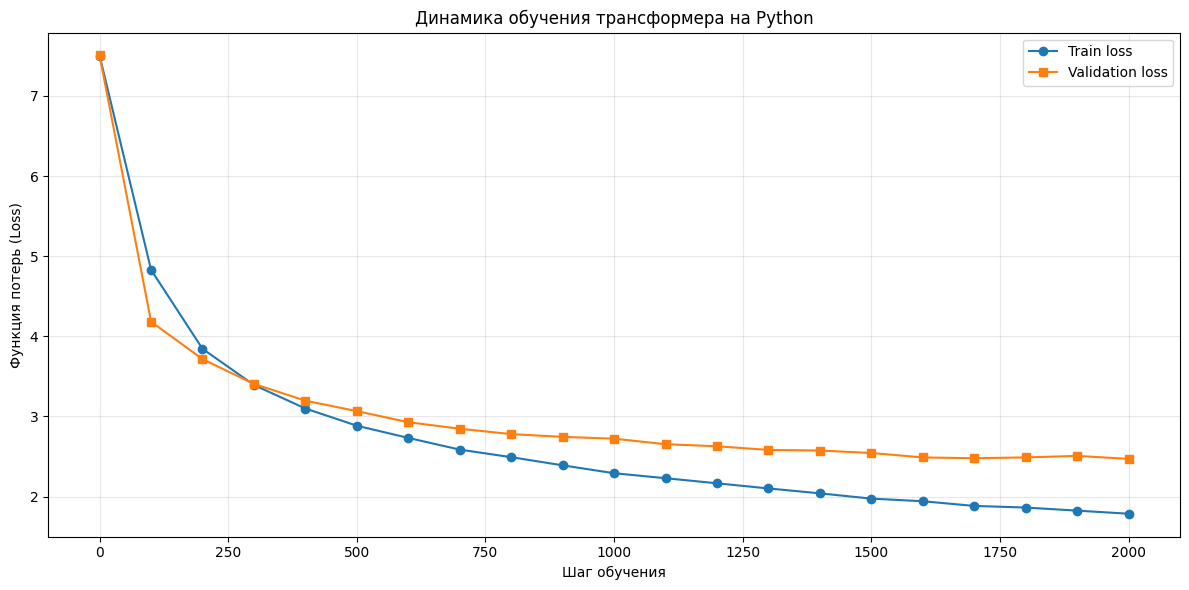

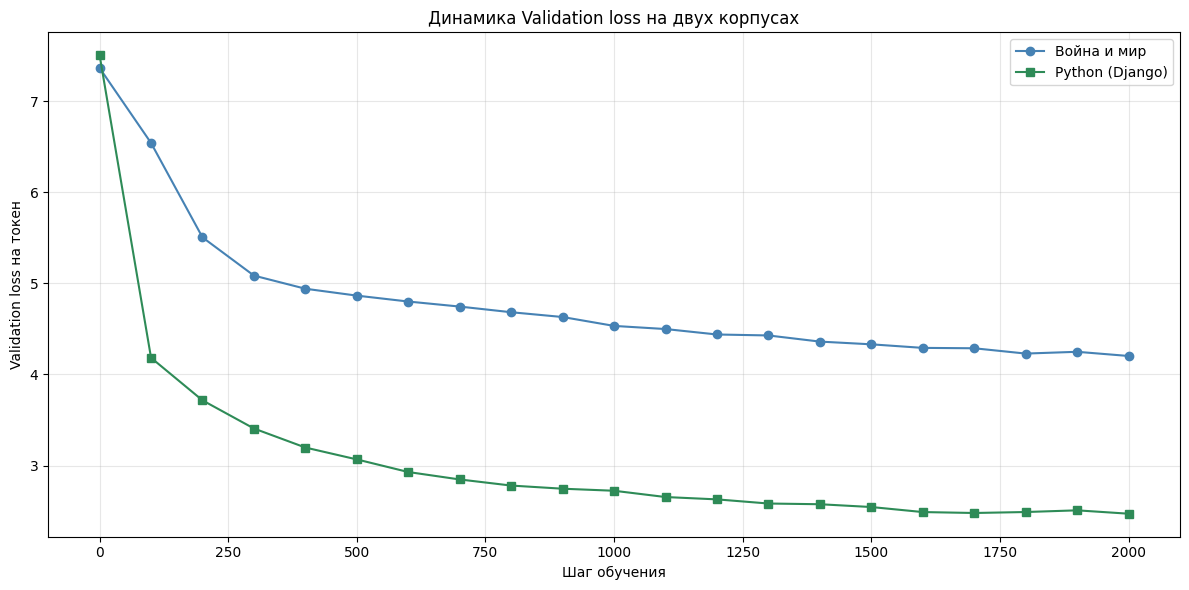


СРАВНЕНИЕ РЕЖИМОВ ГЕНЕРАЦИИ


,mode,samples,valid_syntax,invalid_syntax,newlines,indented_lines
0,greedy,4,0,4,31,19
1,temperature_0.8,4,0,4,28,25


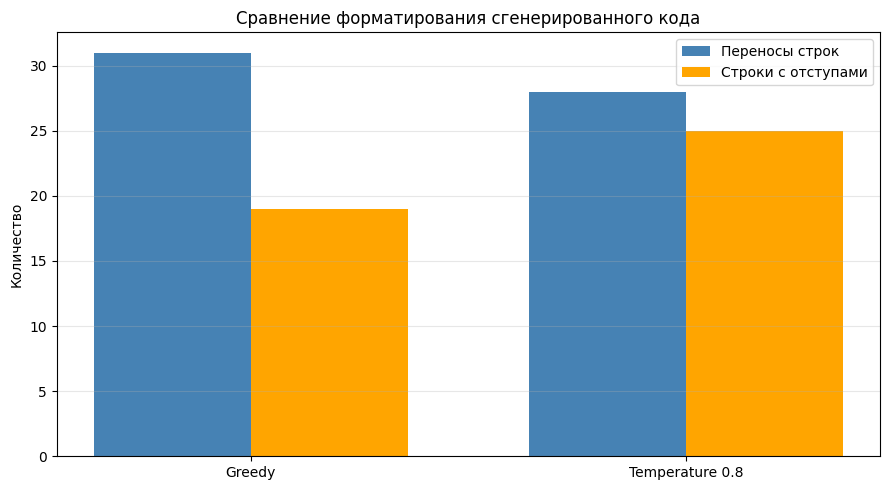


АНАЛИЗ ОБРАЗЦОВ ПО ШАГАМ

Шаг 0:
Случайные последовательности токенов, некорректные символы, отсутствие связной структуры.

Шаг 100:
Появляются переносы строк, отступы, ключевые слова и отдельные вызовы функций.

Шаг 500:
Появляются объявления функций и классов, комментарии, конструкции return и raise.

Шаг 2000:
Более выраженная структура функций, аргументы, документационные строки и методы. Синтаксические ошибки сохраняются.

ИТОГОВЫЕ ВЫВОДЫ
1. Трансформер успешно обучен на исходном коде Django.
2. Проверочная функция потерь уменьшилась на обоих корпусах.
3. Уже на ранних этапах обучения модель воспроизводит отступы и переносы строк.
4. По мере обучения появляются более сложные структуры функций, классов и вызовов методов.
5. Жадная генерация склонна к повторению одинаковых конструкций.
6. Температура 0.8 повышает разнообразие получаемых последовательностей.
7. Все восемь проверенных образцов содержат синтаксические ошибки. Ограниченная длина генерации также может обрывать конструкц

In [25]:
# Сравнение результатов и выводы

import json
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# 1. Рабочие папки

BASE_DIR = Path(
    "/content/drive/MyDrive/Лабораторная2_Попова_МТИ2532"
)

ARTIFACTS_DIR = BASE_DIR / "artifacts"
BONUS_DIR = BASE_DIR / "bonus"
PYTHON_DIR = BONUS_DIR / "python_corpus"
PYTHON_RESULTS = PYTHON_DIR / "results"

# 2. Загрузка результатов обучения

literature_curve = pd.read_csv(
    ARTIFACTS_DIR / "train_curve.csv"
)

python_curve = pd.read_csv(
    PYTHON_RESULTS / "train_curve.csv"
)

with open(
    PYTHON_RESULTS / "python_generation.json",
    encoding="utf-8"
) as f:
    generation_data = json.load(f)

with open(
    ARTIFACTS_DIR / "tiny_config.json",
    encoding="utf-8"
) as f:
    literature_config = json.load(f)

with open(
    PYTHON_RESULTS / "tiny_config.json",
    encoding="utf-8"
) as f:
    python_config = json.load(f)

assert literature_curve["step"].iloc[-1] == 2000
assert python_curve["step"].iloc[-1] == 2000

print("ЗАГРУЗКА РЕЗУЛЬТАТОВ")
print("=" * 60)

print("Кривая обучения на литературе загружена")
print("Кривая обучения на Python загружена")
print("Результаты генерации загружены")

# 3. Формирование итоговой таблицы

comparison = []

for name, curve, config in [
    ("Война и мир", literature_curve, literature_config),
    ("Python (Django)", python_curve, python_config)
]:

    initial_train = float(curve["train_loss"].iloc[0])
    initial_val = float(curve["val_loss"].iloc[0])

    final_train = float(curve["train_loss"].iloc[-1])
    final_val = float(curve["val_loss"].iloc[-1])

    comparison.append({
        "corpus": name,
        "steps": int(curve["step"].iloc[-1]),
        "vocab_size": config.get("vocab_size"),
        "n_params": config.get("n_params"),
        "train_tokens": config.get("train_tokens"),
        "val_tokens": config.get("val_tokens"),
        "initial_train_loss": initial_train,
        "final_train_loss": final_train,
        "initial_val_loss": initial_val,
        "final_val_loss": final_val,
        "val_loss_reduction": initial_val - final_val,
        "val_loss_reduction_percent":
            (initial_val - final_val) / initial_val * 100,
        "generalization_gap": final_val - final_train,
        "train_minutes": config.get("train_minutes")
    })

comparison_df = pd.DataFrame(comparison)

print("\nСРАВНЕНИЕ КОРПУСОВ")
print("=" * 60)

display(comparison_df.round(4).T)

# 4. График обучения на Python

python_loss_path = BONUS_DIR / "python_train_curve.png"

plt.figure(figsize=(12, 6))

plt.plot(
    python_curve["step"],
    python_curve["train_loss"],
    marker="o",
    label="Train loss"
)

plt.plot(
    python_curve["step"],
    python_curve["val_loss"],
    marker="s",
    label="Validation loss"
)

plt.title("Динамика обучения трансформера на Python")
plt.xlabel("Шаг обучения")
plt.ylabel("Функция потерь (Loss)")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig(
    python_loss_path,
    dpi=150,
    bbox_inches="tight"
)

plt.show()
plt.close()

# 5. Сравнение динамики обучения

comparison_graph_path = (
    BONUS_DIR / "python_literature_comparison.png"
)

plt.figure(figsize=(12, 6))

plt.plot(
    literature_curve["step"],
    literature_curve["val_loss"],
    marker="o",
    color="steelblue",
    label="Война и мир"
)

plt.plot(
    python_curve["step"],
    python_curve["val_loss"],
    marker="s",
    color="seagreen",
    label="Python (Django)"
)

plt.title("Динамика Validation loss на двух корпусах")
plt.xlabel("Шаг обучения")
plt.ylabel("Validation loss на токен")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig(
    comparison_graph_path,
    dpi=150,
    bbox_inches="tight"
)

plt.show()
plt.close()

# 6. Сравнение режимов генерации

generation_df = pd.DataFrame(
    generation_data["summary"]
)

print("\nСРАВНЕНИЕ РЕЖИМОВ ГЕНЕРАЦИИ")
print("=" * 60)

display(generation_df)

generation_graph_path = (
    BONUS_DIR / "python_generation_comparison.png"
)

plt.figure(figsize=(9, 5))

positions = range(len(generation_df))

plt.bar(
    [x - 0.18 for x in positions],
    generation_df["newlines"],
    width=0.36,
    color="steelblue",
    label="Переносы строк"
)

plt.bar(
    [x + 0.18 for x in positions],
    generation_df["indented_lines"],
    width=0.36,
    color="orange",
    label="Строки с отступами"
)

plt.xticks(
    list(positions),
    ["Greedy", "Temperature 0.8"]
)

plt.title("Сравнение форматирования сгенерированного кода")
plt.ylabel("Количество")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    generation_graph_path,
    dpi=150,
    bbox_inches="tight"
)

plt.show()
plt.close()

# 7. Анализ образцов по шагам обучения

observations = [
    {
        "step": 0,
        "observation":
            "Случайные последовательности токенов, "
            "некорректные символы, отсутствие связной структуры."
    },
    {
        "step": 100,
        "observation":
            "Появляются переносы строк, отступы, "
            "ключевые слова и отдельные вызовы функций."
    },
    {
        "step": 500,
        "observation":
            "Появляются объявления функций и классов, "
            "комментарии, конструкции return и raise."
    },
    {
        "step": 2000,
        "observation":
            "Более выраженная структура функций, "
            "аргументы, документационные строки и методы. "
            "Синтаксические ошибки сохраняются."
    }
]

print("\nАНАЛИЗ ОБРАЗЦОВ ПО ШАГАМ")
print("=" * 60)

for item in observations:
    print(f"\nШаг {item['step']}:")
    print(item["observation"])

# 8. Итоговые выводы

conclusions = [
    "Трансформер успешно обучен на исходном коде Django.",

    "Проверочная функция потерь уменьшилась "
    "на обоих корпусах.",

    "Уже на ранних этапах обучения модель "
    "воспроизводит отступы и переносы строк.",

    "По мере обучения появляются более сложные "
    "структуры функций, классов и вызовов методов.",

    "Жадная генерация склонна к повторению "
    "одинаковых конструкций.",

    "Температура 0.8 повышает разнообразие "
    "получаемых последовательностей.",

    "Все восемь проверенных образцов содержат "
    "синтаксические ошибки. Ограниченная длина "
    "генерации также может обрывать конструкции.",

    "Отступы и переносы строк появляются раньше, "
    "чем устойчивые корректные синтаксические конструкции.",

    "Точный порядок освоения скобок и идентификаторов "
    "по имеющимся образцам установить нельзя.",

    "Значения loss разных корпусов нельзя напрямую "
    "использовать для сравнения абсолютного качества моделей, "
    "поскольку применяются разные словари и токенизаторы."
]

print("\nИТОГОВЫЕ ВЫВОДЫ")
print("=" * 60)

for i, conclusion in enumerate(conclusions, 1):
    print(f"{i}. {conclusion}")

# 9. Сохранение итоговых результатов

summary_csv_path = (
    BONUS_DIR / "python_comparison_summary.csv"
)

summary_json_path = (
    BONUS_DIR / "python_comparison_summary.json"
)

comparison_df.to_csv(
    summary_csv_path,
    index=False,
    encoding="utf-8"
)

summary_data = {
    "corpora": comparison,
    "generation": generation_data["summary"],
    "observations": observations,
    "conclusions": conclusions
}

with open(
    summary_json_path,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        summary_data,
        f,
        ensure_ascii=False,
        indent=2
    )

with open(
    summary_json_path,
    encoding="utf-8"
) as f:

    restored_summary = json.load(f)

# 10. Итоговая проверка

checks = {
    "Загружены результаты двух корпусов":
        len(comparison) == 2,

    "Оба обучения завершены":
        all(r["steps"] == 2000 for r in comparison),

    "Val loss уменьшился на обоих корпусах":
        all(r["val_loss_reduction"] > 0
            for r in comparison),

    "Количество образцов генерации корректно":
        len(generation_data["runs"]) == 8,

    "График обучения Python сохранён":
        python_loss_path.is_file(),

    "График сравнения корпусов сохранён":
        comparison_graph_path.is_file(),

    "График режимов генерации сохранён":
        generation_graph_path.is_file(),

    "Итоговая таблица сохранена":
        summary_csv_path.is_file(),

    "Итоговый JSON сохранён":
        summary_json_path.is_file(),

    "Проверка восстановления JSON":
        restored_summary == summary_data
}

print("\nИТОГОВАЯ ПРОВЕРКА")
print("=" * 60)

for name, result in checks.items():
    print(f"{name}: {result}")

assert all(checks.values())

print("\nСОХРАНЁННЫЕ ФАЙЛЫ")
print("=" * 60)

for path in [
    python_loss_path,
    comparison_graph_path,
    generation_graph_path,
    summary_csv_path,
    summary_json_path
]:
    print(path)

print("\nБОНУС №4. ДРУГОЙ КОРПУС — ВЫПОЛНЕНО")

Подготовка единого скрипта run.py

In [26]:
from pathlib import Path
import json

BASE_DIR = Path(
    "/content/drive/MyDrive/Лабораторная2_Попова_МТИ2532"
)

ARTIFACTS_DIR = BASE_DIR / "artifacts"
BONUS_DIR = BASE_DIR / "bonus"
SCRIPTS_DIR = BASE_DIR / "scripts"

print("ПРОВЕРКА СОХРАНЁННЫХ РЕЗУЛЬТАТОВ")
print("=" * 60)

for folder in [ARTIFACTS_DIR, SCRIPTS_DIR, BONUS_DIR]:
    print("\nПапка:", folder.name)

    for path in sorted(folder.iterdir()):
        if path.is_file():
            print(path.name, "-", path.stat().st_size, "байт")

print("\nПОИСК РЕПОЗИТОРИЯ")
print("=" * 60)

repos = [
    p.parent.parent
    for p in Path("/content").glob("*/pt02/run.py")
]

if repos:
    REPO_DIR = repos[0]

    print("Репозиторий:", REPO_DIR)
    print("Шаблон run.py:",
          (REPO_DIR / "pt02/run.py").is_file())

    print("\nШАБЛОН ПРОГРАММЫ ПРЕПОДАВАТЕЛЯ")
    print("=" * 60)

    print(
        (REPO_DIR / "pt02/run.py").read_text(
            encoding="utf-8"
        )
    )

    print("\nФАЙЛЫ АВТОТЕСТОВ")
    print("=" * 60)

    for path in sorted((REPO_DIR / "tests").rglob("*.py")):
        print(path.relative_to(REPO_DIR))

else:
    print("Репозиторий не найден по ожидаемому пути")

print("\nСТРУКТУРА АРТЕФАКТОВ")
print("=" * 60)

for path in sorted(ARTIFACTS_DIR.glob("*.json")):
    with open(path, encoding="utf-8") as f:
        data = json.load(f)

    print("\nФайл:", path.name)

    if isinstance(data, dict):
        print("Ключи:", list(data.keys()))
    elif isinstance(data, list):
        print("Количество записей:", len(data))
        if data and isinstance(data[0], dict):
            print("Ключи записи:", list(data[0].keys()))

print("\nПроверка завершена")

ПРОВЕРКА СОХРАНЁННЫХ РЕЗУЛЬТАТОВ

Папка: artifacts
eval.json - 538 байт
eval_nats.png - 36906 байт
eval_perplexity.png - 42341 байт
generation.json - 7142 байт
greedy_check.json - 948 байт
samples.json - 1951 байт
speed.csv - 140 байт
tiny_config.json - 324 байт
train_curve.csv - 901 байт
train_curve.png - 123095 байт

Папка: scripts
model.py - 7448 байт
model_config.json - 161 байт

Папка: bonus
python_comparison_summary.csv - 599 байт
python_comparison_summary.json - 4110 байт
python_generation_comparison.png - 38502 байт
python_literature_comparison.png - 80570 байт
python_train_curve.png - 78804 байт
qwen_nats.png - 36802 байт
qwen_perplexity.png - 49620 байт
qwen_speed.png - 32181 байт
qwen_time.png - 36611 байт
scaling_128.csv - 901 байт
scaling_256.csv - 900 байт
scaling_64.csv - 902 байт
scaling_final_loss.png - 42431 байт
scaling_parameters.png - 43548 байт
scaling_results.json - 8990 байт
scaling_summary.csv - 577 байт
scaling_time.png - 41804 байт
scaling_val_loss.png - 1046

Проверка требований автотестов преподавателя.

In [27]:
from pathlib import Path
import json
import csv

REPO_DIR = Path("/content/tgo-course_Popova_MTI2532")

BASE_DIR = Path(
    "/content/drive/MyDrive/Лабораторная2_Попова_МТИ2532"
)

ARTIFACTS_DIR = BASE_DIR / "artifacts"

print("ТРЕБОВАНИЯ АВТОТЕСТОВ ПРЕПОДАВАТЕЛЯ")
print("=" * 60)

test_path = REPO_DIR / "tests/test_pt02.py"

print(test_path.read_text(encoding="utf-8"))

print("\nПРОВЕРКА АРТЕФАКТОВ")
print("=" * 60)

for path in sorted(ARTIFACTS_DIR.iterdir()):
    if path.is_file():
        print(path.name, "-", path.stat().st_size, "байт")

print("\nСТРУКТУРА CSV")
print("=" * 60)

for path in sorted(ARTIFACTS_DIR.glob("*.csv")):
    print("\nФайл:", path.name)

    with open(path, encoding="utf-8") as f:
        reader = csv.reader(f)
        for i, row in enumerate(reader):
            print(row)
            if i >= 2:
                break

print("\nСТРУКТУРА JSON")
print("=" * 60)

for name in [
    "tiny_config.json",
    "samples.json",
    "generation.json"
]:
    path = ARTIFACTS_DIR / name

    if path.is_file():
        data = json.loads(
            path.read_text(encoding="utf-8")
        )

        print("\nФайл:", name)

        print(json.dumps(
            data,
            ensure_ascii=False,
            indent=2
        )[:5000])

print("\nДОСТУПНЫЕ ФУНКЦИИ")
print("=" * 60)

import inspect

for name, obj in list(globals().items()):
    if inspect.isfunction(obj):
        if obj.__module__ == "__main__":
            print(name, inspect.signature(obj))

print("\nПроверка требований завершена")

ТРЕБОВАНИЯ АВТОТЕСТОВ ПРЕПОДАВАТЕЛЯ
"""Тесты работы 2 заочного отделения: читают pt02/artifacts/ и пересчитывают из данных все, что можно пересчитать.

Скрипт студента тесты не запускают и не импортируют, артефакты к их запуску уже должны лежать на месте.
Обязательные артефакты: tiny_config.json, train_curve.csv, samples.json, generation.json, eval.json (bigram и tiny).
Точка qwen в eval.json и артефакты бонусов (greedy_check.json, speed.csv) проверяются, только если они есть;
проверка greedy_check.json загружает Qwen3-0.6B-Base и повторяет жадную генерацию через model.generate.
"""
import csv
import json
import math
import os
from pathlib import Path

import pytest

ROOT = Path(__file__).resolve().parents[1]
LAB = ROOT / "pt02"
ART = LAB / "artifacts"
DATA = Path(__file__).resolve().parent / "data" / "pt02"
MODEL = os.environ.get("TGO_TEST_MODEL", "Qwen/Qwen3-0.6B-Base")

pytestmark = pytest.mark.skipif(
    "NotImplementedError" in (LAB / "run.py").read_text(encoding="utf-8"),
    re

Перенос подготовки данных и архитектуры модели.

In [28]:
from pathlib import Path
import torch
import json

BASE_DIR = Path(
    "/content/drive/MyDrive/Лабораторная2_Попова_МТИ2532"
)

SCRIPTS_DIR = BASE_DIR / "scripts"
DATA_DIR = BASE_DIR / "data"

model_source = (SCRIPTS_DIR / "model.py").read_text(
    encoding="utf-8"
)

data_source = r'''

# ============================================================
# 1. Данные
# ============================================================

import re
import json
from functools import lru_cache
from pathlib import Path

import torch


class BPETokenizer:

    def __init__(self, bpe_path):

        data = json.loads(
            Path(bpe_path).read_text(encoding="utf-8")
        )

        self.merges = [
            tuple(pair) for pair in data["merges"]
        ]

        self.ranks = {
            pair: i
            for i, pair in enumerate(self.merges)
        }

        symbols = set(
            "абвгдежзийклмнопрстуфхцчшщъыьэюя-"
        )

        symbols.add("</w>")

        for a, b in self.merges:
            symbols.add(a + b)

        self.vocab = sorted(symbols)

        self.token_to_id = {
            token: i
            for i, token in enumerate(self.vocab)
        }

        self.vocab_size = len(self.vocab)

        assert self.vocab_size == data["vocab_size"]

    @staticmethod
    def normalize(text):

        text = text.lower().replace("ё", "е")

        return re.findall(
            r"[а-я]+(?:-[а-я]+)*", text
        )

    @lru_cache(maxsize=None)
    def encode_word(self, word):

        tokens = list(word) + ["</w>"]

        while len(tokens) > 1:

            pairs = list(zip(tokens, tokens[1:]))

            candidates = [
                pair for pair in pairs
                if pair in self.ranks
            ]

            if not candidates:
                break

            best = min(
                candidates,
                key=self.ranks.get
            )

            merged = []
            i = 0

            while i < len(tokens):

                if (
                    i + 1 < len(tokens)
                    and (tokens[i], tokens[i+1]) == best
                ):
                    merged.append(
                        tokens[i] + tokens[i+1]
                    )
                    i += 2

                else:
                    merged.append(tokens[i])
                    i += 1

            tokens = merged

        return tuple(
            self.token_to_id[t] for t in tokens
        )

    def encode_words(self, words):

        return [
            token_id
            for word in words
            for token_id in self.encode_word(word)
        ]

    def encode(self, text):

        return self.encode_words(
            self.normalize(text)
        )

    def decode(self, ids):

        return "".join(
            self.vocab[int(i)] for i in ids
        ).replace("</w>", " ").strip()


def load_data(corpus_path, bpe_path):

    tokenizer = BPETokenizer(bpe_path)

    text = Path(corpus_path).read_text(
        encoding="utf-8"
    )

    words = tokenizer.normalize(text)

    split = int(len(words) * 0.9)

    train_words = words[:split]
    val_words = words[split:]

    train_ids = torch.tensor(
        tokenizer.encode_words(train_words),
        dtype=torch.long
    )

    val_ids = torch.tensor(
        tokenizer.encode_words(val_words),
        dtype=torch.long
    )

    return (
        tokenizer,
        train_words,
        val_words,
        train_ids,
        val_ids
    )

'''

# Формирование первой части программы

source = model_source + "\n\n" + data_source

draft_path = SCRIPTS_DIR / "run_draft.py"

# Проверка синтаксиса
compile(source, str(draft_path), "exec")

# Загрузка функций из создаваемой программы
namespace = {
    "__name__": "run_draft",
    "__file__": str(draft_path)
}

exec(source, namespace)

print("ФОРМИРОВАНИЕ RUN.PY")
print("=" * 60)

print("Проверка синтаксиса: True")

# Проверка подготовки данных

(
    draft_tokenizer,
    draft_train_words,
    draft_val_words,
    draft_train_ids,
    draft_val_ids
) = namespace["load_data"](
    DATA_DIR / "corpus.txt",
    DATA_DIR / "bpe.json"
)

saved_train = torch.load(
    DATA_DIR / "train_ids.pt",
    map_location="cpu"
)

saved_val = torch.load(
    DATA_DIR / "val_ids.pt",
    map_location="cpu"
)

train_match = torch.equal(
    draft_train_ids, saved_train
)

val_match = torch.equal(
    draft_val_ids, saved_val
)

print("\nПРОВЕРКА ДАННЫХ")
print("=" * 60)

print("Размер словаря:", draft_tokenizer.vocab_size)
print("Обучающих слов:", len(draft_train_words))
print("Проверочных слов:", len(draft_val_words))
print("Обучающих токенов:", len(draft_train_ids))
print("Проверочных токенов:", len(draft_val_ids))

print("Обучающие токены совпадают:", train_match)
print("Проверочные токены совпадают:", val_match)

phrase = "князь андрей вошел в комнату"

ids = draft_tokenizer.encode(phrase)
restored = draft_tokenizer.decode(ids)

print("\nПРОВЕРКА ТОКЕНИЗАТОРА")
print("=" * 60)

print("Исходная фраза:", phrase)
print("Идентификаторы:", ids)
print("Восстановленная фраза:", restored)
print("Совпадение:", phrase == restored)

print("\nПРОВЕРКА АРХИТЕКТУРЫ")
print("=" * 60)

classes = [
    "CausalSelfAttention",
    "FeedForward",
    "TransformerBlock",
    "TokenPositionEmbedding",
    "TinyTransformer"
]

for name in classes:
    print(name + ":", name in namespace)

draft_model = namespace["TinyTransformer"](
    vocab_size=draft_tokenizer.vocab_size,
    d_model=128,
    n_layers=4,
    n_heads=4,
    d_ff=512,
    context=128
)

n_params = sum(
    p.numel() for p in draft_model.parameters()
)

print("Количество параметров:", n_params)
print("Количество параметров совпадает:",
      n_params == 1203966)

assert train_match
assert val_match
assert draft_tokenizer.vocab_size == 1534
assert phrase == restored
assert n_params == 1203966

# Сохранение только после успешных проверок

draft_path.write_text(
    source,
    encoding="utf-8"
)

print("\nСОХРАНЕНИЕ")
print("=" * 60)

print("Черновик программы сохранён:",
      draft_path.is_file())

print("Размер файла:", draft_path.stat().st_size)
print("Количество строк:", len(source.splitlines()))
print("Путь:", draft_path)

print("\nПервая часть run.py успешно сформирована")

ФОРМИРОВАНИЕ RUN.PY
Проверка синтаксиса: True

ПРОВЕРКА ДАННЫХ
Размер словаря: 1534
Обучающих слов: 389773
Проверочных слов: 43309
Обучающих токенов: 753537
Проверочных токенов: 83461
Обучающие токены совпадают: True
Проверочные токены совпадают: True

ПРОВЕРКА ТОКЕНИЗАТОРА
Исходная фраза: князь андрей вошел в комнату
Идентификаторы: [610, 36, 193, 105, 628]
Восстановленная фраза: князь андрей вошел в комнату
Совпадение: True

ПРОВЕРКА АРХИТЕКТУРЫ
CausalSelfAttention: True
FeedForward: True
TransformerBlock: True
TokenPositionEmbedding: True
TinyTransformer: True
Количество параметров: 1203966
Количество параметров совпадает: True

СОХРАНЕНИЕ
Черновик программы сохранён: True
Размер файла: 10697
Количество строк: 455
Путь: /content/drive/MyDrive/Лабораторная2_Попова_МТИ2532/scripts/run_draft.py

Первая часть run.py успешно сформирована


Подготовка переноса функций обучения и генерации.

In [29]:
import inspect
from pathlib import Path

BASE_DIR = Path(
    "/content/drive/MyDrive/Лабораторная2_Попова_МТИ2532"
)

SCRIPTS_DIR = BASE_DIR / "scripts"

function_names = [
    "make_batch",
    "get_train_batch",
    "calculate_loss",
    "evaluate_loss",
    "encode_text",
    "decode_ids",
    "generate",
    "find_loop_start",
    "get_logits",
    "save_json",
    "train_model"
]

source_parts = []
missing_functions = []

print("ПОДГОТОВКА ФУНКЦИЙ ДЛЯ RUN.PY")
print("=" * 60)

for name in function_names:

    obj = globals().get(name)

    if obj is None or not callable(obj):
        missing_functions.append(name)
        print(name, "— отсутствует")
        continue

    source = inspect.getsource(obj)

    source_parts.append(source)

    print(name, inspect.signature(obj), "— True")

# Сохранение исходных функций

training_source = "\n\n".join(source_parts)

training_path = SCRIPTS_DIR / "training_source.py"

compile(
    training_source,
    str(training_path),
    "exec"
)

training_path.write_text(
    training_source,
    encoding="utf-8"
)

print("\nСОХРАНЕНИЕ ИСХОДНЫХ ФУНКЦИЙ")
print("=" * 60)

print("Количество функций:", len(source_parts))
print("Отсутствующие функции:", missing_functions)
print("Проверка синтаксиса: True")
print("Файл сохранён:", training_path.is_file())
print("Размер файла:", training_path.stat().st_size)
print("Количество строк:", len(training_source.splitlines()))
print("Путь:", training_path)

# Вывод исходного кода для переноса

for name in function_names:

    obj = globals().get(name)

    if obj is None or not callable(obj):
        continue

    print("\n" + "=" * 60)
    print("ФУНКЦИЯ:", name)
    print("=" * 60)

    print(inspect.getsource(obj))

    dependencies = inspect.getclosurevars(obj)

    print("Глобальные зависимости:")

    for key, value in dependencies.globals.items():

        if isinstance(value, (int, float, bool)):
            print(key, "=", value)
        else:
            print(key, ":", type(value).__name__)

print("\nИТОГОВАЯ ПРОВЕРКА")
print("=" * 60)

print("Все функции доступны:", not missing_functions)
print("Исходный код сохранён:", training_path.is_file())
print("Черновик run.py сохранён:",
      (SCRIPTS_DIR / "run_draft.py").is_file())

assert not missing_functions

print("\nПодготовка переноса функций завершена")

ПОДГОТОВКА ФУНКЦИЙ ДЛЯ RUN.PY
make_batch (data, batch_size, rng) — True
get_train_batch (batch_size) — True
calculate_loss (x, y) — True
evaluate_loss (x, y) — True
encode_text (text) — True
decode_ids (ids) — True
generate (prompt, max_new_tokens, temperature=1.0, top_p=None, seed=42) — True
find_loop_start (ids) — True
get_logits (x) — True
save_json (path, data) — True
train_model (fast=True) — True

СОХРАНЕНИЕ ИСХОДНЫХ ФУНКЦИЙ
Количество функций: 11
Отсутствующие функции: []
Проверка синтаксиса: True
Файл сохранён: True
Размер файла: 15633
Количество строк: 671
Путь: /content/drive/MyDrive/Лабораторная2_Попова_МТИ2532/scripts/training_source.py

ФУНКЦИЯ: make_batch
def make_batch(data, batch_size, rng):

    starts = torch.randint(
        0,
        len(data) - CONTEXT,
        (batch_size,),
        generator=rng
    )

    offsets = torch.arange(CONTEXT)

    positions = starts[:, None] + offsets[None, :]

    x = data[positions].to(device)
    y = data[positions + 1].to(device)

Перенос обучения и генерации в run.py

In [30]:
from pathlib import Path

BASE_DIR = Path(
    "/content/drive/MyDrive/Лабораторная2_Попова_МТИ2532"
)

SCRIPTS_DIR = BASE_DIR / "scripts"

training_code = '''
# ============================================================
# 3. ОБУЧЕНИЕ
# 4. ОБРАЗЦЫ ПО ШАГАМ
# 5. ГЕНЕРАЦИЯ РУКАМИ
# ============================================================

import csv
import json
import time

import torch
import torch.nn.functional as F


def make_training_batch(data, batch_size, context, rng, device):
    starts = torch.randint(
        0,
        len(data) - context,
        (batch_size,),
        generator=rng
    )

    positions = (
        starts[:, None]
        + torch.arange(context)[None, :]
    )

    x = data[positions].to(device)
    y = data[positions + 1].to(device)

    return x, y


def transformer_loss(model, x, y):
    logits = model(x)

    if isinstance(logits, tuple):
        logits = logits[0]

    return F.cross_entropy(
        logits.reshape(-1, logits.size(-1)),
        y.reshape(-1)
    )


@torch.no_grad()
def validation_loss(model, x, y):
    was_training = model.training
    model.eval()

    try:
        return transformer_loss(model, x, y).item()
    finally:
        model.train(was_training)


def write_json(path, data):
    path.write_text(
        json.dumps(data, ensure_ascii=False, indent=2),
        encoding="utf-8"
    )


@torch.no_grad()
def generate_text(
    model,
    tokenizer,
    prompt,
    max_new_tokens,
    context=128,
    temperature=1.0,
    top_p=None,
    seed=42
):
    assert temperature >= 0

    if top_p is not None:
        assert 0 < top_p <= 1

    device = next(model.parameters()).device

    prompt_ids = list(tokenizer.encode(prompt))
    assert len(prompt_ids) > 0

    ids = torch.tensor(
        [prompt_ids],
        dtype=torch.long,
        device=device
    )

    rng = torch.Generator(device=device)
    rng.manual_seed(seed)

    new_ids = []

    was_training = model.training
    model.eval()

    try:
        for _ in range(max_new_tokens):

            x = ids[:, -context:]

            logits = model(x)

            if isinstance(logits, tuple):
                logits = logits[0]

            logits = logits[:, -1, :]

            if temperature == 0:

                next_id = torch.argmax(
                    logits,
                    dim=-1,
                    keepdim=True
                )

            else:

                logits = logits / temperature

                if top_p is not None:

                    sorted_logits, sorted_indices = torch.sort(
                        logits,
                        descending=True,
                        dim=-1
                    )

                    probs = F.softmax(
                        sorted_logits,
                        dim=-1
                    )

                    cumulative = torch.cumsum(
                        probs,
                        dim=-1
                    )

                    remove = cumulative > top_p
                    remove[..., 1:] = remove[..., :-1].clone()
                    remove[..., 0] = False

                    sorted_logits = sorted_logits.masked_fill(
                        remove,
                        float("-inf")
                    )

                    probs = F.softmax(
                        sorted_logits,
                        dim=-1
                    )

                    selected = torch.multinomial(
                        probs,
                        1,
                        generator=rng
                    )

                    next_id = sorted_indices.gather(
                        -1,
                        selected
                    )

                else:

                    probs = F.softmax(logits, dim=-1)

                    next_id = torch.multinomial(
                        probs,
                        1,
                        generator=rng
                    )

            new_ids.append(int(next_id.item()))

            ids = torch.cat(
                [ids, next_id],
                dim=1
            )

    finally:
        model.train(was_training)

    text = tokenizer.decode(prompt_ids + new_ids)

    return text, new_ids


def first_repeat(ids, n=4):
    seen = set()

    for i in range(len(ids) - n + 1):

        fragment = tuple(ids[i:i + n])

        if fragment in seen:
            return i

        seen.add(fragment)

    return None


def train_transformer(
    model,
    tokenizer,
    train_data,
    val_data,
    output_dir,
    checkpoint_dir,
    vocab_size,
    bpe_merges,
    fast=False,
    resume=False,
    seed=42
):
    context = 128
    lr = 0.001

    steps = 200 if fast else 2000
    batch_size = 16 if fast else 32
    interval = 25 if fast else 100

    sample_steps = (
        [0, 50, 100, 200]
        if fast
        else [0, 100, 500, 2000]
    )

    output_dir = Path(output_dir)
    checkpoint_dir = Path(checkpoint_dir)

    output_dir.mkdir(parents=True, exist_ok=True)
    checkpoint_dir.mkdir(parents=True, exist_ok=True)

    checkpoint_path = checkpoint_dir / "latest.pt"

    device = next(model.parameters()).device

    train_data = train_data.cpu()
    val_data = val_data.cpu()

    torch.manual_seed(seed)

    train_rng = torch.Generator().manual_seed(seed)
    val_rng = torch.Generator().manual_seed(seed + 1)
    initial_rng = torch.Generator().manual_seed(seed + 2)

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=lr
    )

    val_x, val_y = make_training_batch(
        val_data, 20, context, val_rng, device
    )

    initial_x, initial_y = make_training_batch(
        train_data, batch_size, context,
        initial_rng, device
    )

    history = []
    samples = []

    completed_step = 0
    elapsed_seconds = 0.0

    def collect_sample(step):

        text, _ = generate_text(
            model,
            tokenizer,
            prompt="князь андрей",
            max_new_tokens=60,
            context=context,
            temperature=0.8,
            seed=seed
        )

        samples.append({
            "step": step,
            "text": text
        })

        print("Образец на шаге", step)
        print(text)

    if resume and checkpoint_path.is_file():

        checkpoint = torch.load(
            checkpoint_path,
            map_location="cpu",
            weights_only=True
        )

        assert checkpoint["steps"] == steps
        assert checkpoint["batch_size"] == batch_size

        model.load_state_dict(
            checkpoint["model_state_dict"]
        )

        optimizer.load_state_dict(
            checkpoint["optimizer_state_dict"]
        )

        train_rng.set_state(
            checkpoint["train_rng_state"]
        )

        history = checkpoint["history"]
        samples = checkpoint["samples"]

        completed_step = checkpoint["step"]
        elapsed_seconds = checkpoint["elapsed_seconds"]

        print("Восстановление с шага:", completed_step)

    else:

        history.append({
            "step": 0,
            "train_loss": validation_loss(
                model, initial_x, initial_y
            ),
            "val_loss": validation_loss(
                model, val_x, val_y
            )
        })

        collect_sample(0)

    start_time = time.perf_counter()

    def save_checkpoint(step):

        if device.type == "cuda":
            torch.cuda.synchronize()

        state = {
            "steps": steps,
            "batch_size": batch_size,
            "step": step,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "train_rng_state": train_rng.get_state(),
            "history": history,
            "samples": samples,
            "elapsed_seconds": (
                elapsed_seconds
                + time.perf_counter()
                - start_time
            )
        }

        temp_path = checkpoint_dir / "latest.tmp"

        torch.save(state, temp_path)
        temp_path.replace(checkpoint_path)

        with open(
            output_dir / "train_curve.csv",
            "w",
            newline="",
            encoding="utf-8"
        ) as f:

            writer = csv.DictWriter(
                f,
                fieldnames=[
                    "step",
                    "train_loss",
                    "val_loss"
                ]
            )

            writer.writeheader()
            writer.writerows(history)

        write_json(
            output_dir / "samples.json",
            {
                "prompt": "князь андрей",
                "temperature": 0.8,
                "samples": samples
            }
        )

        print("Контрольная точка сохранена:", step)

    if completed_step == 0:
        save_checkpoint(0)

    model.train()

    loss_sum = 0.0
    loss_count = 0

    for step in range(completed_step + 1, steps + 1):

        x, y = make_training_batch(
            train_data,
            batch_size,
            context,
            train_rng,
            device
        )

        optimizer.zero_grad(set_to_none=True)

        loss = transformer_loss(model, x, y)

        if not torch.isfinite(loss).item():
            raise RuntimeError(
                f"Некорректный loss на шаге {step}"
            )

        loss.backward()
        optimizer.step()

        loss_sum += loss.item()
        loss_count += 1

        if step % interval == 0 or step == steps:

            train_loss = loss_sum / loss_count
            val_loss = validation_loss(model, val_x, val_y)

            history.append({
                "step": step,
                "train_loss": train_loss,
                "val_loss": val_loss
            })

            print(
                f"Шаг {step}/{steps} | "
                f"Train loss: {train_loss:.4f} | "
                f"Val loss: {val_loss:.4f}",
                flush=True
            )

            loss_sum = 0.0
            loss_count = 0

        if step in sample_steps:
            collect_sample(step)

        if step % interval == 0 or step == steps:
            save_checkpoint(step)

    if device.type == "cuda":
        torch.cuda.synchronize()

    train_minutes = (
        elapsed_seconds
        + time.perf_counter()
        - start_time
    ) / 60

    config = {
        "vocab_size": vocab_size,
        "d_model": 128,
        "n_layers": 4,
        "n_heads": 4,
        "d_ff": 512,
        "context": context,
        "n_params": sum(
            p.numel() for p in model.parameters()
        ),
        "steps": steps,
        "batch": batch_size,
        "lr": lr,
        "seed": seed,
        "train_tokens": len(train_data),
        "val_tokens": len(val_data),
        "bpe_merges": bpe_merges,
        "train_minutes": train_minutes,
        "device": str(device)
    }

    write_json(
        output_dir / "tiny_config.json",
        config
    )

    return history, samples, config


def run_generation_experiment(
    model,
    tokenizer,
    output_dir,
    seed=42
):
    prompt = "князь андрей"
    max_new_tokens = 80

    modes = [
        ("greedy", 0.0, None),
        ("t0.7", 0.7, None),
        ("t1.5", 1.5, None),
        ("top_p0.9", 1.0, 0.9)
    ]

    runs = []

    for name, temperature, top_p in modes:

        text, ids = generate_text(
            model,
            tokenizer,
            prompt,
            max_new_tokens,
            temperature=temperature,
            top_p=top_p,
            seed=seed
        )

        runs.append({
            "name": name,
            "temperature": temperature,
            "top_p": top_p,
            "text": text,
            "ids": ids,
            "n_tokens": len(ids),
            "loop_start": first_repeat(ids)
        })

        print("Режим:", name)
        print(text)

    result = {
        "model": "tiny",
        "prompt": prompt,
        "max_new_tokens": max_new_tokens,
        "runs": runs
    }

    write_json(
        Path(output_dir) / "generation.json",
        result
    )

    return result

'''

# ============================================================
# СОХРАНЕНИЕ И ОБЪЕДИНЕНИЕ ПРОГРАММЫ
# ============================================================

training_path = SCRIPTS_DIR / "training_part.py"

compile(training_code, str(training_path), "exec")

training_path.write_text(
    training_code,
    encoding="utf-8"
)

draft_path = SCRIPTS_DIR / "run_draft.py"

draft_source = draft_path.read_text(
    encoding="utf-8"
)

combined_source = (
    draft_source
    + "\n\n"
    + training_code
)

combined_path = SCRIPTS_DIR / "run_draft_stage2.py"

compile(
    combined_source,
    str(combined_path),
    "exec"
)

combined_path.write_text(
    combined_source,
    encoding="utf-8"
)

print("ФОРМИРОВАНИЕ ВТОРОЙ ЧАСТИ RUN.PY")
print("=" * 60)

print("Проверка синтаксиса: True")
print("Первая часть сохранена:", draft_path.is_file())
print("Вторая часть сохранена:", training_path.is_file())
print("Объединённый скрипт сохранён:", combined_path.is_file())

# ============================================================
# ПРОВЕРКА ФУНКЦИЙ
# ============================================================

namespace = {
    "Path": Path,
    "__name__": "training_test"
}

exec(
    compile(training_code, str(training_path), "exec"),
    namespace
)

function_names = [
    "make_training_batch",
    "transformer_loss",
    "validation_loss",
    "write_json",
    "generate_text",
    "first_repeat",
    "train_transformer",
    "run_generation_experiment"
]

print("\nПРОВЕРКА ФУНКЦИЙ")
print("=" * 60)

for name in function_names:

    correct = callable(namespace.get(name))

    print(name + ":", correct)

    assert correct

# ============================================================
# ПРОВЕРКА БАТЧЕЙ
# ============================================================

import torch

test_data = torch.arange(1000)

test_rng = torch.Generator().manual_seed(42)

test_x, test_y = namespace["make_training_batch"](
    test_data,
    32,
    128,
    test_rng,
    torch.device("cpu")
)

shape_correct = (
    test_x.shape == (32, 128)
    and test_y.shape == (32, 128)
)

shift_correct = torch.equal(
    test_x[:, 1:],
    test_y[:, :-1]
)

print("\nПРОВЕРКА БАТЧЕЙ")
print("=" * 60)

print("Размер входа:", test_x.shape)
print("Размер целей:", test_y.shape)
print("Размерности корректны:", shape_correct)
print("Сдвиг целей корректен:", shift_correct)

assert shape_correct
assert shift_correct

# ============================================================
# ПРОВЕРКА ПОИСКА ЗАЦИКЛИВАНИЯ
# ============================================================

test_sequence = [
    97, 105, 1336, 1450, 914,
    97, 105, 1336, 1450
]

repeat_start = namespace["first_repeat"](
    test_sequence
)

print("\nПРОВЕРКА ЗАЦИКЛИВАНИЯ")
print("=" * 60)

print("Начало повторения:", repeat_start)
print("Результат корректен:", repeat_start == 5)

assert repeat_start == 5

assert namespace["first_repeat"](
    [1, 2, 3, 4, 5, 6]
) is None

print("\nСОХРАНЁННЫЕ ФАЙЛЫ")
print("=" * 60)

for path in [
    draft_path,
    training_path,
    combined_path
]:
    print(
        path.name,
        "-",
        path.stat().st_size,
        "байт"
    )

print("\nКоличество строк объединённого скрипта:",
      len(combined_source.splitlines()))

print("Путь:", combined_path)

print("\nВторая часть run.py успешно сформирована")

ФОРМИРОВАНИЕ ВТОРОЙ ЧАСТИ RUN.PY
Проверка синтаксиса: True
Первая часть сохранена: True
Вторая часть сохранена: True
Объединённый скрипт сохранён: True

ПРОВЕРКА ФУНКЦИЙ
make_training_batch: True
transformer_loss: True
validation_loss: True
write_json: True
generate_text: True
first_repeat: True
train_transformer: True
run_generation_experiment: True

ПРОВЕРКА БАТЧЕЙ
Размер входа: torch.Size([32, 128])
Размер целей: torch.Size([32, 128])
Размерности корректны: True
Сдвиг целей корректен: True

ПРОВЕРКА ЗАЦИКЛИВАНИЯ
Начало повторения: 5
Результат корректен: True

СОХРАНЁННЫЕ ФАЙЛЫ
run_draft.py - 10697 байт
training_part.py - 12079 байт
run_draft_stage2.py - 22778 байт

Количество строк объединённого скрипта: 1006
Путь: /content/drive/MyDrive/Лабораторная2_Попова_МТИ2532/scripts/run_draft_stage2.py

Вторая часть run.py успешно сформирована


Перенос задания №6. Счётчики против трансформера.

In [31]:
from pathlib import Path

BASE_DIR = Path(
    "/content/drive/MyDrive/Лабораторная2_Попова_МТИ2532"
)

SCRIPTS_DIR = BASE_DIR / "scripts"

evaluation_code = '''
# ============================================================
# 6. СЧЁТЧИКИ ПРОТИВ ТРАНСФОРМЕРА
# ============================================================

import math
import json

from pathlib import Path
from collections import Counter

import torch
import torch.nn.functional as F


class ComparisonBigram:

    def __init__(self, alpha=0.01):
        self.alpha = alpha

    def fit(self, words):

        self.word_counts = Counter(words)

        self.bigram_counts = Counter(
            zip(words, words[1:])
        )

        self.context_counts = Counter(
            words[:-1]
        )

        self.vocab = sorted(self.word_counts)
        self.vocab_size = len(self.vocab)

        return self

    def prob(self, previous, current):

        pair_count = self.bigram_counts.get(
            (previous, current), 0
        )

        context_count = self.context_counts.get(
            previous, 0
        )

        V = self.vocab_size + 1

        return (
            pair_count + self.alpha
        ) / (
            context_count + self.alpha * V
        )

    def logprob(self, words):

        return sum(
            math.log(self.prob(previous, current))
            for previous, current
            in zip(words, words[1:])
        )


def evaluate_bigram(
    train_words,
    comparison_words,
    alpha=0.01
):

    model = ComparisonBigram(
        alpha=alpha
    ).fit(train_words)

    nats_total = -model.logprob(
        comparison_words
    )

    nats_per_word = (
        nats_total / len(comparison_words)
    )

    result = {
        "tokens": len(comparison_words) - 1,
        "nats_total": nats_total,
        "nats_per_word": nats_per_word,
        "ppl_per_word": math.exp(nats_per_word),
        "alpha": alpha
    }

    return result


@torch.no_grad()
def evaluate_tiny(
    model,
    tokenizer,
    comparison_words,
    context=128,
    batch_size=32
):

    device = next(model.parameters()).device

    text = " ".join(comparison_words)

    token_ids = tokenizer.encode(text)

    ids = torch.tensor(
        token_ids,
        dtype=torch.long
    )

    assert len(ids) >= 2

    was_training = model.training
    model.eval()

    nats_total = 0.0
    evaluated_tokens = 0

    try:

        # Начальная часть последовательности.
        # Первый токен используется как контекст.

        prefix_length = min(
            context,
            len(ids) - 1
        )

        x = ids[:prefix_length].unsqueeze(0).to(device)

        y = ids[1:prefix_length + 1].to(device)

        logits = model(x)

        if isinstance(logits, tuple):
            logits = logits[0]

        losses = F.cross_entropy(
            logits[0].float(),
            y,
            reduction="none"
        )

        nats_total += losses.double().sum().item()

        evaluated_tokens += prefix_length

        # Оценка остальных токенов.
        # Для каждого используется до 128
        # предыдущих токенов.

        for start in range(
            prefix_length + 1,
            len(ids),
            batch_size
        ):

            end = min(
                start + batch_size,
                len(ids)
            )

            positions = torch.arange(start, end)

            offsets = torch.arange(
                -context, 0
            )

            indices = (
                positions[:, None]
                + offsets[None, :]
            )

            x = ids[indices].to(device)

            y = ids[positions].to(device)

            logits = model(x)

            if isinstance(logits, tuple):
                logits = logits[0]

            last_logits = logits[:, -1, :].float()

            losses = F.cross_entropy(
                last_logits,
                y,
                reduction="none"
            )

            nats_total += (
                losses.double().sum().item()
            )

            evaluated_tokens += len(y)

    finally:

        model.train(was_training)

    assert evaluated_tokens == len(ids) - 1

    nats_per_word = (
        nats_total / len(comparison_words)
    )

    result = {
        "tokens": evaluated_tokens,
        "nats_total": nats_total,
        "nats_per_word": nats_per_word,
        "ppl_per_word": math.exp(nats_per_word)
    }

    return result


def run_evaluation(
    model,
    tokenizer,
    train_words,
    val_words,
    output_dir,
    vocab_size,
    n_words=2000
):

    assert len(val_words) >= n_words

    comparison_words = val_words[:n_words]

    print("СРАВНЕНИЕ ЯЗЫКОВЫХ МОДЕЛЕЙ")
    print("=" * 60)

    print(
        "Количество слов:",
        len(comparison_words)
    )

    bigram_result = evaluate_bigram(
        train_words,
        comparison_words,
        alpha=0.01
    )

    tiny_result = evaluate_tiny(
        model,
        tokenizer,
        comparison_words,
        context=128
    )

    result = {
        "words": len(comparison_words),
        "bigram": bigram_result,
        "tiny": tiny_result
    }

    for name in ("bigram", "tiny"):

        metrics = result[name]

        print()
        print("Модель:", name)

        print(
            "Оценённых токенов:",
            metrics["tokens"]
        )

        print(
            "Nats total:",
            metrics["nats_total"]
        )

        print(
            "Nats per word:",
            metrics["nats_per_word"]
        )

        print(
            "Perplexity per word:",
            metrics["ppl_per_word"]
        )

        assert metrics["tokens"] > 0

        assert math.isfinite(
            metrics["nats_per_word"]
        )

        assert math.isfinite(
            metrics["ppl_per_word"]
        )

    uniform = (
        math.log(vocab_size)
        * tiny_result["tokens"]
        / len(comparison_words)
    )

    better_than_uniform = (
        tiny_result["nats_per_word"] < uniform
    )

    print()
    print("Равновероятный выбор:", uniform)

    print(
        "Трансформер лучше равновероятного выбора:",
        better_than_uniform
    )

    output_dir = Path(output_dir)

    output_dir.mkdir(
        parents=True,
        exist_ok=True
    )

    output_path = output_dir / "eval.json"

    output_path.write_text(
        json.dumps(
            result,
            ensure_ascii=False,
            indent=2
        ),
        encoding="utf-8"
    )

    print("Результаты сохранены:", output_path)

    return result

'''

# ============================================================
# СОХРАНЕНИЕ ТРЕТЬЕЙ ЧАСТИ
# ============================================================

evaluation_path = (
    SCRIPTS_DIR / "evaluation_part.py"
)

compile(
    evaluation_code,
    str(evaluation_path),
    "exec"
)

evaluation_path.write_text(
    evaluation_code,
    encoding="utf-8"
)

previous_path = (
    SCRIPTS_DIR / "run_draft_stage2.py"
)

previous_source = previous_path.read_text(
    encoding="utf-8"
)

combined_source = (
    previous_source
    + "\n\n"
    + evaluation_code
)

combined_path = (
    SCRIPTS_DIR / "run_draft_stage3.py"
)

compile(
    combined_source,
    str(combined_path),
    "exec"
)

combined_path.write_text(
    combined_source,
    encoding="utf-8"
)

print("ФОРМИРОВАНИЕ ТРЕТЬЕЙ ЧАСТИ RUN.PY")
print("=" * 60)

print("Проверка синтаксиса: True")

print(
    "Предыдущая часть доступна:",
    previous_path.is_file()
)

print(
    "Третья часть сохранена:",
    evaluation_path.is_file()
)

print(
    "Объединённый скрипт сохранён:",
    combined_path.is_file()
)

# ============================================================
# ПРОВЕРКА ДОСТУПНОСТИ ФУНКЦИЙ
# ============================================================

namespace = {
    "__name__": "evaluation_test"
}

exec(
    compile(
        evaluation_code,
        str(evaluation_path),
        "exec"
    ),
    namespace
)

print("\nПРОВЕРКА ФУНКЦИЙ")
print("=" * 60)

function_names = [
    "ComparisonBigram",
    "evaluate_bigram",
    "evaluate_tiny",
    "run_evaluation"
]

for name in function_names:

    correct = callable(
        namespace.get(name)
    )

    print(name + ":", correct)

    assert correct

# ============================================================
# ПРОВЕРКА БИГРАММНОЙ МОДЕЛИ
# ============================================================

import math

test_train = [
    "князь",
    "андрей",
    "вошел",
    "в",
    "комнату",
    "князь",
    "андрей"
]

test_words = [
    "князь",
    "андрей",
    "вошел",
    "в",
    "комнату"
]

test_result = namespace["evaluate_bigram"](
    test_train,
    test_words,
    alpha=0.01
)

print("\nПРОВЕРКА БИГРАММНОЙ МОДЕЛИ")
print("=" * 60)

print("Тестовых слов:", len(test_words))
print("Оценённых слов:", test_result["tokens"])
print("Nats total:", test_result["nats_total"])
print("Nats per word:", test_result["nats_per_word"])
print("Перплексия:", test_result["ppl_per_word"])

bigram_correct = (
    test_result["tokens"] == 4
    and test_result["alpha"] == 0.01
    and math.isclose(
        test_result["ppl_per_word"],
        math.exp(test_result["nats_per_word"])
    )
)

print("Метрики рассчитаны корректно:", bigram_correct)

assert bigram_correct

# ============================================================
# ПРОВЕРКА ОЦЕНКИ ТРАНСФОРМЕРА
# ============================================================

import torch
import torch.nn as nn


class TestTokenizer:

    def encode(self, text):
        return [0, 1, 2, 3, 0, 1, 2, 3]


class UniformTestModel(nn.Module):

    def __init__(self):

        super().__init__()

        self.weight = nn.Parameter(
            torch.zeros(1)
        )

    def forward(self, x):

        return torch.zeros(
            x.size(0),
            x.size(1),
            4,
            device=x.device
        )


test_model = UniformTestModel()

tiny_result = namespace["evaluate_tiny"](
    test_model,
    TestTokenizer(),
    test_words,
    context=3,
    batch_size=2
)

expected_nats = 7 * math.log(4)

tokens_correct = (
    tiny_result["tokens"] == 7
)

nats_correct = math.isclose(
    tiny_result["nats_total"],
    expected_nats,
    rel_tol=1e-6
)

ppl_correct = math.isclose(
    tiny_result["ppl_per_word"],
    math.exp(tiny_result["nats_per_word"])
)

print("\nПРОВЕРКА ОЦЕНКИ ТРАНСФОРМЕРА")
print("=" * 60)

print("Количество токенов:", tiny_result["tokens"])

print(
    "Фактический Nats total:",
    tiny_result["nats_total"]
)

print(
    "Теоретический Nats total:",
    expected_nats
)

print(
    "Количество токенов корректно:",
    tokens_correct
)

print(
    "Nats total рассчитан корректно:",
    nats_correct
)

print(
    "Перплексия рассчитана корректно:",
    ppl_correct
)

print(
    "Режим модели восстановлен:",
    test_model.training
)

assert tokens_correct
assert nats_correct
assert ppl_correct
assert test_model.training

# ============================================================
# ИТОГОВАЯ ПРОВЕРКА
# ============================================================

print("\nИТОГОВАЯ ПРОВЕРКА")
print("=" * 60)

print("Биграммная модель реализована: True")
print("Оценка трансформера реализована: True")
print("Формат метрик корректен: True")
print("Все функции доступны: True")
print("Синтаксис скрипта корректен: True")

print("\nСОХРАНЁННЫЕ ФАЙЛЫ")
print("=" * 60)

for path in [
    previous_path,
    evaluation_path,
    combined_path
]:

    print(
        path.name,
        "-",
        path.stat().st_size,
        "байт"
    )

print(
    "\nКоличество строк объединённого скрипта:",
    len(combined_source.splitlines())
)

print("Путь:", combined_path)

print("\nТретья часть run.py успешно сформирована")

ФОРМИРОВАНИЕ ТРЕТЬЕЙ ЧАСТИ RUN.PY
Проверка синтаксиса: True
Предыдущая часть доступна: True
Третья часть сохранена: True
Объединённый скрипт сохранён: True

ПРОВЕРКА ФУНКЦИЙ
ComparisonBigram: True
evaluate_bigram: True
evaluate_tiny: True
run_evaluation: True

ПРОВЕРКА БИГРАММНОЙ МОДЕЛИ
Тестовых слов: 5
Оценённых слов: 4
Nats total: 0.16952699254292847
Nats per word: 0.03390539850858569
Перплексия: 1.0344867381106586
Метрики рассчитаны корректно: True

ПРОВЕРКА ОЦЕНКИ ТРАНСФОРМЕРА
Количество токенов: 7
Фактический Nats total: 9.704060554504395
Теоретический Nats total: 9.704060527839234
Количество токенов корректно: True
Nats total рассчитан корректно: True
Перплексия рассчитана корректно: True
Режим модели восстановлен: True

ИТОГОВАЯ ПРОВЕРКА
Биграммная модель реализована: True
Оценка трансформера реализована: True
Формат метрик корректен: True
Все функции доступны: True
Синтаксис скрипта корректен: True

СОХРАНЁННЫЕ ФАЙЛЫ
run_draft_stage2.py - 22778 байт
evaluation_part.py - 6697 ба

Перенос бонусов №1 и №2

In [32]:
from pathlib import Path
import json
import math

BASE_DIR = Path(
    "/content/drive/MyDrive/Лабораторная2_Попова_МТИ2532"
)

SCRIPTS_DIR = BASE_DIR / "scripts"

bonus_code = '''
# ============================================================
# БОНУС №1. ТРЕТЬЯ ТОЧКА
# БОНУС №2. ГЕНЕРАЦИЯ QWEN И KV-КЭШ
# ============================================================

import csv
import json
import math
import time

from pathlib import Path

import torch
import torch.nn.functional as F


QWEN_MODEL_NAME = "Qwen/Qwen3-0.6B-Base"


def load_qwen_for_run(model_dir=None, device=None):

    from transformers import (
        AutoTokenizer,
        AutoModelForCausalLM
    )

    if device is None:

        device = (
            "cuda"
            if torch.cuda.is_available()
            else "cpu"
        )

    device = torch.device(device)

    source = QWEN_MODEL_NAME

    if model_dir is not None:

        model_dir = Path(model_dir)

        if (model_dir / "config.json").is_file():
            source = str(model_dir)

    dtype = (
        torch.float16
        if device.type == "cuda"
        else torch.float32
    )

    tokenizer = AutoTokenizer.from_pretrained(
        source
    )

    model = AutoModelForCausalLM.from_pretrained(
        source,
        dtype=dtype
    )

    model = model.to(device)
    model.eval()

    print("Модель:", QWEN_MODEL_NAME)
    print("Устройство:", device)

    print(
        "Количество параметров:",
        sum(p.numel() for p in model.parameters())
    )

    return model, tokenizer


@torch.inference_mode()
def evaluate_qwen(
    model,
    tokenizer,
    comparison_words,
    chunk_size=256
):

    device = next(model.parameters()).device

    text = " ".join(comparison_words)

    token_ids = tokenizer.encode(
        text,
        add_special_tokens=False
    )

    assert len(token_ids) >= 2

    ids = torch.tensor(
        [token_ids],
        dtype=torch.long,
        device=device
    )

    model.eval()

    nats_total = 0.0
    evaluated_tokens = 0

    past = None

    for start in range(
        0,
        ids.size(1) - 1,
        chunk_size
    ):

        end = min(
            start + chunk_size,
            ids.size(1) - 1
        )

        x = ids[:, start:end]

        y = ids[:, start + 1:end + 1]

        output = model(
            input_ids=x,
            past_key_values=past,
            use_cache=True
        )

        logits = output.logits.float()

        losses = F.cross_entropy(
            logits.reshape(-1, logits.size(-1)),
            y.reshape(-1),
            reduction="none"
        )

        nats_total += (
            losses.double().sum().item()
        )

        evaluated_tokens += y.numel()

        past = output.past_key_values

        del output, logits, losses

    assert evaluated_tokens == len(token_ids) - 1

    nats_per_word = (
        nats_total / len(comparison_words)
    )

    result = {
        "model": QWEN_MODEL_NAME,
        "tokens": evaluated_tokens,
        "nats_total": nats_total,
        "nats_per_word": nats_per_word,
        "ppl_per_word": math.exp(nats_per_word)
    }

    print("ОЦЕНКА QWEN")

    for key, value in result.items():
        print(key, ":", value)

    return result


# ============================================================
# САМОСТОЯТЕЛЬНАЯ ЖАДНАЯ ГЕНЕРАЦИЯ
# ============================================================

@torch.inference_mode()
def qwen_greedy_ids(
    model,
    prompt_ids,
    max_new_tokens=30,
    use_cache=True
):

    device = next(model.parameters()).device

    ids = torch.tensor(
        [prompt_ids],
        dtype=torch.long,
        device=device
    )

    model.eval()

    past = None
    new_ids = []

    for step in range(max_new_tokens):

        if use_cache and past is not None:

            x = ids[:, -1:]

        else:

            x = ids

        output = model(
            input_ids=x,
            past_key_values=(
                past if use_cache else None
            ),
            use_cache=use_cache
        )

        logits = output.logits[:, -1, :]

        next_id = torch.argmax(
            logits,
            dim=-1,
            keepdim=True
        )

        if use_cache:

            past = output.past_key_values

        new_ids.append(
            int(next_id.item())
        )

        ids = torch.cat(
            [ids, next_id],
            dim=1
        )

    return new_ids


# ============================================================
# СРАВНЕНИЕ С HUGGING FACE
# ============================================================

@torch.inference_mode()
def qwen_greedy_check(
    model,
    tokenizer,
    prompt="Князь Андрей вошел в комнату и",
    max_new_tokens=30
):

    device = next(model.parameters()).device

    prompt_ids = tokenizer.encode(
        prompt,
        add_special_tokens=False
    )

    ours_ids = qwen_greedy_ids(
        model,
        prompt_ids,
        max_new_tokens=max_new_tokens,
        use_cache=True
    )

    ids = torch.tensor(
        [prompt_ids],
        dtype=torch.long,
        device=device
    )

    output = model.generate(
        input_ids=ids,
        attention_mask=torch.ones_like(ids),
        do_sample=False,
        max_new_tokens=max_new_tokens,
        pad_token_id=tokenizer.eos_token_id
    )

    hf_ids = output[
        0,
        ids.size(1):
    ].tolist()

    match = ours_ids == hf_ids

    result = {
        "model": QWEN_MODEL_NAME,
        "prompt": prompt,
        "prompt_ids": prompt_ids,
        "ours_ids": ours_ids,
        "hf_ids": hf_ids,
        "match": match
    }

    print("СРАВНЕНИЕ ГЕНЕРАЦИИ")

    print(
        "Самостоятельная генерация:",
        tokenizer.decode(
            prompt_ids + ours_ids
        )
    )

    print(
        "Генерация Hugging Face:",
        tokenizer.decode(
            prompt_ids + hf_ids
        )
    )

    print("Совпадение токенов:", match)

    assert match
    assert len(ours_ids) == max_new_tokens

    return result


# ============================================================
# ИЗМЕРЕНИЕ СКОРОСТИ С KV-КЭШЕМ И БЕЗ НЕГО
# ============================================================

def qwen_sync(device):

    if device.type == "cuda":

        torch.cuda.synchronize(device)


def qwen_speed_test(
    model,
    tokenizer,
    prompt="Князь Андрей вошел в комнату и",
    max_new_tokens=30,
    repeats=3
):

    device = next(model.parameters()).device

    prompt_ids = tokenizer.encode(
        prompt,
        add_special_tokens=False
    )

    # Прогрев обоих режимов

    for use_cache in (True, False):

        qwen_greedy_ids(
            model,
            prompt_ids,
            max_new_tokens=max_new_tokens,
            use_cache=use_cache
        )

    timings = {
        "cache": [],
        "no_cache": []
    }

    generated = {}

    # Чередуем порядок режимов,
    # чтобы уменьшить влияние прогрева.

    for repeat in range(repeats):

        modes = (
            [("cache", True), ("no_cache", False)]
            if repeat % 2 == 0
            else [("no_cache", False), ("cache", True)]
        )

        for mode, use_cache in modes:

            qwen_sync(device)

            start = time.perf_counter()

            result_ids = qwen_greedy_ids(
                model,
                prompt_ids,
                max_new_tokens=max_new_tokens,
                use_cache=use_cache
            )

            qwen_sync(device)

            seconds = (
                time.perf_counter() - start
            )

            assert seconds > 0

            timings[mode].append(seconds)

            generated[mode] = result_ids

            print(
                mode,
                "| Повтор:", repeat + 1,
                "| Время:", round(seconds, 4),
                "| Токенов/сек:",
                round(max_new_tokens / seconds, 4)
            )

    assert (
        generated["cache"]
        == generated["no_cache"]
    )

    rows = []

    for mode in ("cache", "no_cache"):

        seconds = (
            sum(timings[mode])
            / len(timings[mode])
        )

        rows.append({
            "mode": mode,
            "new_tokens": max_new_tokens,
            "seconds": seconds,
            "tokens_per_second":
                max_new_tokens / seconds
        })

    print("СРАВНЕНИЕ СКОРОСТИ")

    for row in rows:
        print(row)

    speedup = (
        rows[0]["tokens_per_second"]
        / rows[1]["tokens_per_second"]
    )

    print("Коэффициент ускорения:", speedup)

    print(
        "Генерация с кэшем быстрее:",
        speedup > 1
    )

    return rows


# ============================================================
# ВЫПОЛНЕНИЕ БОНУСОВ №1 И №2
# ============================================================

def run_qwen_bonuses(
    val_words,
    output_dir,
    model_dir=None,
    device=None
):

    output_dir = Path(output_dir)

    output_dir.mkdir(
        parents=True,
        exist_ok=True
    )

    eval_path = output_dir / "eval.json"

    evaluation = json.loads(
        eval_path.read_text(
            encoding="utf-8"
        )
    )

    comparison_words = val_words[
        :evaluation["words"]
    ]

    assert (
        len(comparison_words)
        == evaluation["words"]
    )

    # Загрузка Qwen для оценки
    # и измерения скорости.

    model, tokenizer = load_qwen_for_run(
        model_dir=model_dir,
        device=device
    )

    qwen_result = evaluate_qwen(
        model,
        tokenizer,
        comparison_words
    )

    speed_rows = qwen_speed_test(
        model,
        tokenizer,
        max_new_tokens=30,
        repeats=3
    )

    # Автотест преподавателя проверяет
    # генерацию на CPU с float32.

    if next(model.parameters()).device.type == "cuda":

        del model

        torch.cuda.empty_cache()

        model, tokenizer = load_qwen_for_run(
            model_dir=model_dir,
            device="cpu"
        )

    greedy_result = qwen_greedy_check(
        model,
        tokenizer
    )

    evaluation["qwen"] = qwen_result

    eval_path.write_text(
        json.dumps(
            evaluation,
            ensure_ascii=False,
            indent=2
        ),
        encoding="utf-8"
    )

    greedy_path = (
        output_dir / "greedy_check.json"
    )

    greedy_path.write_text(
        json.dumps(
            greedy_result,
            ensure_ascii=False,
            indent=2
        ),
        encoding="utf-8"
    )

    speed_path = output_dir / "speed.csv"

    with open(
        speed_path,
        "w",
        encoding="utf-8",
        newline=""
    ) as f:

        writer = csv.DictWriter(
            f,
            fieldnames=[
                "mode",
                "new_tokens",
                "seconds",
                "tokens_per_second"
            ]
        )

        writer.writeheader()
        writer.writerows(speed_rows)

    print("РЕЗУЛЬТАТЫ БОНУСОВ")

    print("eval.json:", eval_path.is_file())
    print("greedy_check.json:", greedy_path.is_file())
    print("speed.csv:", speed_path.is_file())

    return evaluation, greedy_result, speed_rows

'''

# ============================================================
# СОХРАНЕНИЕ ЧЕТВЁРТОЙ ЧАСТИ
# ============================================================

bonus_path = SCRIPTS_DIR / "qwen_part.py"

compile(
    bonus_code,
    str(bonus_path),
    "exec"
)

bonus_path.write_text(
    bonus_code,
    encoding="utf-8"
)

previous_path = (
    SCRIPTS_DIR / "run_draft_stage3.py"
)

previous_source = previous_path.read_text(
    encoding="utf-8"
)

combined_source = (
    previous_source
    + "\n\n"
    + bonus_code
)

combined_path = (
    SCRIPTS_DIR / "run_draft_stage4.py"
)

compile(
    combined_source,
    str(combined_path),
    "exec"
)

combined_path.write_text(
    combined_source,
    encoding="utf-8"
)

print("ФОРМИРОВАНИЕ ЧЕТВЁРТОЙ ЧАСТИ RUN.PY")
print("=" * 60)

print("Проверка синтаксиса: True")

print(
    "Предыдущая часть доступна:",
    previous_path.is_file()
)

print(
    "Четвёртая часть сохранена:",
    bonus_path.is_file()
)

print(
    "Объединённый скрипт сохранён:",
    combined_path.is_file()
)

# ============================================================
# ПРОВЕРКА ДОСТУПНОСТИ ФУНКЦИЙ
# ============================================================

namespace = {
    "__name__": "qwen_test"
}

exec(
    compile(
        bonus_code,
        str(bonus_path),
        "exec"
    ),
    namespace
)

print("\nПРОВЕРКА ФУНКЦИЙ")
print("=" * 60)

function_names = [
    "load_qwen_for_run",
    "evaluate_qwen",
    "qwen_greedy_ids",
    "qwen_greedy_check",
    "qwen_sync",
    "qwen_speed_test",
    "run_qwen_bonuses"
]

for name in function_names:

    correct = callable(
        namespace.get(name)
    )

    print(name + ":", correct)

    assert correct

# ============================================================
# ПРОВЕРКА РАНЕЕ СОХРАНЁННЫХ РЕЗУЛЬТАТОВ
# ============================================================

import csv

artifacts_dir = BASE_DIR / "artifacts"

evaluation = json.loads(
    (artifacts_dir / "eval.json").read_text(
        encoding="utf-8"
    )
)

greedy = json.loads(
    (artifacts_dir / "greedy_check.json").read_text(
        encoding="utf-8"
    )
)

with open(
    artifacts_dir / "speed.csv",
    encoding="utf-8"
) as f:

    speed = {
        row["mode"]: row
        for row in csv.DictReader(f)
    }

print("\nПРОВЕРКА СОХРАНЁННЫХ РЕЗУЛЬТАТОВ")
print("=" * 60)

qwen_correct = (
    evaluation["qwen"]["model"]
    == namespace["QWEN_MODEL_NAME"]
)

qwen_better = (
    evaluation["qwen"]["nats_per_word"]
    < evaluation["tiny"]["nats_per_word"]
)

greedy_correct = (
    greedy["ours_ids"] == greedy["hf_ids"]
    and greedy["match"] is True
)

speed_correct = True

for mode in ("cache", "no_cache"):

    row = speed[mode]

    calculated = (
        float(row["new_tokens"])
        / float(row["seconds"])
    )

    recorded = float(
        row["tokens_per_second"]
    )

    speed_correct &= math.isclose(
        calculated,
        recorded,
        rel_tol=0.02
    )

cache_faster = (
    float(speed["cache"]["tokens_per_second"])
    >
    float(speed["no_cache"]["tokens_per_second"])
)

print("Название Qwen корректно:", qwen_correct)
print("Qwen лучше трансформера:", qwen_better)
print("Жадная генерация совпадает:", greedy_correct)
print("Скорость рассчитана корректно:", speed_correct)
print("Генерация с кэшем быстрее:", cache_faster)

assert qwen_correct
assert qwen_better
assert greedy_correct
assert speed_correct
assert cache_faster

# ============================================================
# ИТОГОВАЯ ПРОВЕРКА
# ============================================================

print("\nИТОГОВАЯ ПРОВЕРКА")
print("=" * 60)

print("Функции Qwen перенесены: True")
print("Функции генерации перенесены: True")
print("Функции KV-кэша перенесены: True")
print("Все функции доступны: True")
print("Синтаксис корректен: True")
print("Ранее полученные результаты сохранены: True")

print("\nСОХРАНЁННЫЕ ФАЙЛЫ")
print("=" * 60)

for path in [
    previous_path,
    bonus_path,
    combined_path
]:

    print(
        path.name,
        "-",
        path.stat().st_size,
        "байт"
    )

print(
    "\nКоличество строк объединённого скрипта:",
    len(combined_source.splitlines())
)

print("Путь:", combined_path)

print("\nЧетвёртая часть run.py успешно сформирована")

ФОРМИРОВАНИЕ ЧЕТВЁРТОЙ ЧАСТИ RUN.PY
Проверка синтаксиса: True
Предыдущая часть доступна: True
Четвёртая часть сохранена: True
Объединённый скрипт сохранён: True

ПРОВЕРКА ФУНКЦИЙ
load_qwen_for_run: True
evaluate_qwen: True
qwen_greedy_ids: True
qwen_greedy_check: True
qwen_sync: True
qwen_speed_test: True
run_qwen_bonuses: True

ПРОВЕРКА СОХРАНЁННЫХ РЕЗУЛЬТАТОВ
Название Qwen корректно: True
Qwen лучше трансформера: True
Жадная генерация совпадает: True
Скорость рассчитана корректно: True
Генерация с кэшем быстрее: True

ИТОГОВАЯ ПРОВЕРКА
Функции Qwen перенесены: True
Функции генерации перенесены: True
Функции KV-кэша перенесены: True
Все функции доступны: True
Синтаксис корректен: True
Ранее полученные результаты сохранены: True

СОХРАНЁННЫЕ ФАЙЛЫ
run_draft_stage3.py - 29477 байт
qwen_part.py - 11530 байт
run_draft_stage4.py - 41009 байт

Количество строк объединённого скрипта: 1921
Путь: /content/drive/MyDrive/Лабораторная2_Попова_МТИ2532/scripts/run_draft_stage4.py

Четвёртая часть r

Перенос бонуса №3. Закон масштабирования руками

In [33]:
from pathlib import Path
import json
import math

BASE_DIR = Path(
    "/content/drive/MyDrive/Лабораторная2_Попова_МТИ2532"
)

SCRIPTS_DIR = BASE_DIR / "scripts"

scaling_code = '''
# ============================================================
# БОНУС №3. ЗАКОН МАСШТАБИРОВАНИЯ РУКАМИ
# ============================================================

import csv
import json
import math
import time

from pathlib import Path

import torch


def train_scaling_model(
    width,
    vocab_size,
    train_data,
    val_data,
    checkpoint_dir,
    device,
    steps=2000,
    batch_size=32,
    interval=100,
    seed=42,
    resume=False
):

    context = 128
    lr = 0.001
    n_layers = 4
    n_heads = 4
    d_ff = width * 4

    device = torch.device(device)

    train_data = train_data.cpu()
    val_data = val_data.cpu()

    torch.manual_seed(seed)

    if device.type == "cuda":
        torch.cuda.manual_seed_all(seed)

    # Одинаковая последовательность обучающих окон

    train_rng = torch.Generator().manual_seed(seed)

    val_rng = torch.Generator().manual_seed(seed + 1)

    initial_rng = torch.Generator().manual_seed(seed + 2)

    # Создание модели заданной ширины

    model = TinyTransformer(
        vocab_size=vocab_size,
        d_model=width,
        n_layers=n_layers,
        n_heads=n_heads,
        d_ff=d_ff,
        context=context
    ).to(device)

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=lr
    )

    n_params = sum(
        p.numel() for p in model.parameters()
    )

    # Одинаковые проверочные окна

    val_x, val_y = make_training_batch(
        val_data,
        20,
        context,
        val_rng,
        device
    )

    initial_x, initial_y = make_training_batch(
        train_data,
        batch_size,
        context,
        initial_rng,
        device
    )

    checkpoint_dir = Path(checkpoint_dir)

    checkpoint_dir.mkdir(
        parents=True,
        exist_ok=True
    )

    checkpoint_path = (
        checkpoint_dir / f"width_{width}.pt"
    )

    history = []
    completed_step = 0
    previous_seconds = 0.0

    settings = {
        "width": width,
        "vocab_size": vocab_size,
        "steps": steps,
        "batch": batch_size,
        "interval": interval,
        "context": context,
        "lr": lr,
        "seed": seed
    }

    print()
    print("=" * 60)
    print("ОБУЧЕНИЕ МОДЕЛИ ШИРИНОЙ", width)
    print("=" * 60)

    print("Количество параметров:", n_params)

    # Восстановление обучения

    if resume and checkpoint_path.is_file():

        checkpoint = torch.load(
            checkpoint_path,
            map_location="cpu",
            weights_only=True
        )

        assert checkpoint["settings"] == settings

        model.load_state_dict(
            checkpoint["model_state"]
        )

        optimizer.load_state_dict(
            checkpoint["optimizer_state"]
        )

        train_rng.set_state(
            checkpoint["generator_state"]
        )

        history = checkpoint["history"]
        completed_step = checkpoint["step"]
        previous_seconds = checkpoint["seconds"]

        del checkpoint

        print("Восстановлен шаг:", completed_step)

    else:

        initial_train_loss = validation_loss(
            model,
            initial_x,
            initial_y
        )

        initial_val_loss = validation_loss(
            model,
            val_x,
            val_y
        )

        history.append({
            "step": 0,
            "train_loss": initial_train_loss,
            "val_loss": initial_val_loss
        })

        print(
            f"Шаг 0 | "
            f"Train loss: {initial_train_loss:.4f} | "
            f"Val loss: {initial_val_loss:.4f}"
        )

    # Обучение

    model.train()

    start_time = time.perf_counter()

    loss_sum = 0.0
    loss_count = 0

    for step in range(completed_step + 1, steps + 1):

        x, y = make_training_batch(
            train_data,
            batch_size,
            context,
            train_rng,
            device
        )

        optimizer.zero_grad(set_to_none=True)

        loss = transformer_loss(model, x, y)

        if not torch.isfinite(loss).item():

            raise RuntimeError(
                f"Некорректный loss на шаге {step}"
            )

        loss.backward()

        optimizer.step()

        loss_sum += loss.item()
        loss_count += 1

        if step % interval == 0 or step == steps:

            train_loss = loss_sum / loss_count

            val_loss = validation_loss(
                model,
                val_x,
                val_y
            )

            history.append({
                "step": step,
                "train_loss": train_loss,
                "val_loss": val_loss
            })

            print(
                f"Ширина {width} | "
                f"Шаг {step}/{steps} | "
                f"Train loss: {train_loss:.4f} | "
                f"Val loss: {val_loss:.4f}",
                flush=True
            )

            loss_sum = 0.0
            loss_count = 0

            if device.type == "cuda":
                torch.cuda.synchronize()

            # Сохранение контрольной точки

            checkpoint_data = {
                "settings": settings,
                "step": step,
                "model_state": model.state_dict(),
                "optimizer_state": optimizer.state_dict(),
                "generator_state": train_rng.get_state(),
                "history": history,
                "seconds": (
                    previous_seconds
                    + time.perf_counter()
                    - start_time
                )
            }

            temporary_path = checkpoint_path.with_suffix(
                ".tmp"
            )

            torch.save(
                checkpoint_data,
                temporary_path
            )

            temporary_path.replace(
                checkpoint_path
            )

            del checkpoint_data

    # Итоговое время

    if device.type == "cuda":
        torch.cuda.synchronize()

    elapsed = previous_seconds

    if completed_step < steps:

        elapsed += (
            time.perf_counter() - start_time
        )

    result = {
        "d_model": width,
        "n_params": n_params,
        "n_layers": n_layers,
        "n_heads": n_heads,
        "d_ff": d_ff,
        "context": context,
        "steps": steps,
        "batch": batch_size,
        "lr": lr,
        "seed": seed,
        "train_tokens": len(train_data),
        "val_tokens": len(val_data),
        "initial_train_loss": history[0]["train_loss"],
        "final_train_loss": history[-1]["train_loss"],
        "initial_val_loss": history[0]["val_loss"],
        "final_val_loss": history[-1]["val_loss"],
        "best_val_loss": min(
            row["val_loss"] for row in history
        ),
        "train_minutes": elapsed / 60,
        "history": history
    }

    print()
    print("РЕЗУЛЬТАТЫ МОДЕЛИ")
    print("Ширина:", width)
    print("Параметров:", n_params)

    print(
        "Конечный val loss:",
        result["final_val_loss"]
    )

    print(
        "Время обучения (мин.):",
        result["train_minutes"]
    )

    return result


# ============================================================
# ПОСТРОЕНИЕ ГРАФИКОВ
# ============================================================

def plot_scaling_results(results, output_dir):

    import matplotlib

    matplotlib.use("Agg")

    import matplotlib.pyplot as plt

    output_dir = Path(output_dir)

    results = sorted(
        results,
        key=lambda r: r["d_model"]
    )

    widths = [
        str(r["d_model"])
        for r in results
    ]

    colors = [
        "orange",
        "steelblue",
        "seagreen"
    ]

    # График 1. Три кривые Validation loss

    plt.figure(figsize=(12, 6))

    for result, color in zip(results, colors):

        plt.plot(
            [
                row["step"]
                for row in result["history"]
            ],
            [
                row["val_loss"]
                for row in result["history"]
            ],
            marker="o",
            markersize=4,
            color=color,
            label=f"Ширина {result['d_model']}"
        )

    plt.title(
        "Влияние ширины трансформера на Validation loss"
    )

    plt.xlabel("Шаг обучения")
    plt.ylabel("Validation loss")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()

    plt.savefig(
        output_dir / "scaling_val_loss.png",
        dpi=150
    )

    plt.close()

    # График 2. Итоговые функции потерь

    final_train = [
        r["final_train_loss"]
        for r in results
    ]

    final_val = [
        r["final_val_loss"]
        for r in results
    ]

    positions = list(range(len(results)))

    plt.figure(figsize=(9, 5))

    train_bars = plt.bar(
        [x - 0.18 for x in positions],
        final_train,
        width=0.36,
        color="steelblue",
        label="Train loss"
    )

    val_bars = plt.bar(
        [x + 0.18 for x in positions],
        final_val,
        width=0.36,
        color="orange",
        label="Validation loss"
    )

    plt.bar_label(train_bars, fmt="%.4f", padding=3)
    plt.bar_label(val_bars, fmt="%.4f", padding=3)

    plt.xticks(positions, widths)
    plt.xlabel("Ширина модели")
    plt.ylabel("Loss")
    plt.title("Итоговые потери трансформеров")
    plt.ylim(0, max(final_val + final_train) * 1.15)
    plt.legend()
    plt.grid(axis="y", alpha=0.3)
    plt.tight_layout()

    plt.savefig(
        output_dir / "scaling_final_loss.png",
        dpi=150
    )

    plt.close()

    # График 3. Количество параметров

    params = [
        r["n_params"]
        for r in results
    ]

    plt.figure(figsize=(9, 5))

    bars = plt.bar(
        widths,
        params,
        color=colors[:len(results)]
    )

    plt.bar_label(bars, padding=4, fmt="%.0f")

    plt.xlabel("Ширина модели")
    plt.ylabel("Количество параметров")
    plt.title("Количество параметров трансформера")
    plt.ylim(0, max(params) * 1.2)
    plt.ticklabel_format(style="plain", axis="y")
    plt.grid(axis="y", alpha=0.3)
    plt.tight_layout()

    plt.savefig(
        output_dir / "scaling_parameters.png",
        dpi=150
    )

    plt.close()

    # График 4. Время обучения

    minutes = [
        r["train_minutes"]
        for r in results
    ]

    plt.figure(figsize=(9, 5))

    bars = plt.bar(
        widths,
        minutes,
        color=colors[:len(results)]
    )

    plt.bar_label(bars, fmt="%.4f", padding=4)

    plt.xlabel("Ширина модели")
    plt.ylabel("Время обучения, минут")
    plt.title("Время обучения трансформеров")
    plt.ylim(0, max(minutes) * 1.2)
    plt.grid(axis="y", alpha=0.3)
    plt.tight_layout()

    plt.savefig(
        output_dir / "scaling_time.png",
        dpi=150
    )

    plt.close()


# ============================================================
# ВЫПОЛНЕНИЕ БОНУСА №3
# ============================================================

def run_scaling_bonus(
    train_data,
    val_data,
    vocab_size,
    output_dir,
    checkpoint_dir,
    device,
    widths=(64, 128, 256),
    steps=2000,
    batch_size=32,
    interval=100,
    seed=42,
    resume=False,
    make_plots=True
):

    output_dir = Path(output_dir)

    output_dir.mkdir(
        parents=True,
        exist_ok=True
    )

    results = []

    for width in widths:

        result = train_scaling_model(
            width=width,
            vocab_size=vocab_size,
            train_data=train_data,
            val_data=val_data,
            checkpoint_dir=checkpoint_dir,
            device=device,
            steps=steps,
            batch_size=batch_size,
            interval=interval,
            seed=seed,
            resume=resume
        )

        results.append(result)

        # Сохранение индивидуальной кривой

        curve_path = (
            output_dir / f"scaling_{width}.csv"
        )

        with open(
            curve_path,
            "w",
            encoding="utf-8",
            newline=""
        ) as f:

            writer = csv.DictWriter(
                f,
                fieldnames=[
                    "step",
                    "train_loss",
                    "val_loss"
                ]
            )

            writer.writeheader()
            writer.writerows(result["history"])

        # Сохранение промежуточных результатов

        write_json(
            output_dir / "scaling_results.json",
            results
        )

        if torch.device(device).type == "cuda":
            torch.cuda.empty_cache()

    # Сводная таблица

    columns = [
        "d_model",
        "n_params",
        "steps",
        "initial_train_loss",
        "initial_val_loss",
        "final_train_loss",
        "final_val_loss",
        "best_val_loss",
        "train_minutes",
        "generalization_gap"
    ]

    with open(
        output_dir / "scaling_summary.csv",
        "w",
        encoding="utf-8",
        newline=""
    ) as f:

        writer = csv.DictWriter(
            f,
            fieldnames=columns
        )

        writer.writeheader()

        for result in results:

            row = {
                key: result[key]
                for key in columns
                if key != "generalization_gap"
            }

            row["generalization_gap"] = (
                result["final_val_loss"]
                - result["final_train_loss"]
            )

            writer.writerow(row)

    if make_plots:

        plot_scaling_results(
            results,
            output_dir
        )

    print()
    print("ИТОГИ МАСШТАБИРОВАНИЯ")
    print("=" * 60)

    for result in results:

        print(
            f"Ширина: {result['d_model']} | "
            f"Параметров: {result['n_params']} | "
            f"Val loss: {result['final_val_loss']:.4f}"
        )

    best = min(
        results,
        key=lambda r: r["final_val_loss"]
    )

    print("Лучшая ширина:", best["d_model"])

    print(
        "Лучший Validation loss:",
        best["final_val_loss"]
    )

    assert len(results) == len(widths)

    assert all(
        r["history"][-1]["step"] == steps
        for r in results
    )

    assert all(
        math.isfinite(row["train_loss"])
        and math.isfinite(row["val_loss"])
        for r in results
        for row in r["history"]
    )

    return results

'''

# ============================================================
# СОХРАНЕНИЕ ПЯТОЙ ЧАСТИ
# ============================================================

scaling_path = SCRIPTS_DIR / "scaling_part.py"

compile(
    scaling_code,
    str(scaling_path),
    "exec"
)

scaling_path.write_text(
    scaling_code,
    encoding="utf-8"
)

previous_path = (
    SCRIPTS_DIR / "run_draft_stage4.py"
)

previous_source = previous_path.read_text(
    encoding="utf-8"
)

combined_source = (
    previous_source
    + "\n\n"
    + scaling_code
)

combined_path = (
    SCRIPTS_DIR / "run_draft_stage5.py"
)

compile(
    combined_source,
    str(combined_path),
    "exec"
)

combined_path.write_text(
    combined_source,
    encoding="utf-8"
)

print("ФОРМИРОВАНИЕ ПЯТОЙ ЧАСТИ RUN.PY")
print("=" * 60)

print("Проверка синтаксиса: True")

print(
    "Предыдущая часть доступна:",
    previous_path.is_file()
)

print(
    "Пятая часть сохранена:",
    scaling_path.is_file()
)

print(
    "Объединённый скрипт сохранён:",
    combined_path.is_file()
)

# ============================================================
# ПРОВЕРКА ДОСТУПНОСТИ ФУНКЦИЙ
# ============================================================

import runpy

namespace = runpy.run_path(
    str(combined_path)
)

function_names = [
    "train_scaling_model",
    "plot_scaling_results",
    "run_scaling_bonus"
]

print("\nПРОВЕРКА ФУНКЦИЙ")
print("=" * 60)

for name in function_names:

    correct = callable(
        namespace.get(name)
    )

    print(name + ":", correct)

    assert correct

# ============================================================
# ПРОВЕРКА КОЛИЧЕСТВА ПАРАМЕТРОВ
# ============================================================

expected_params = {
    64: 406142,
    128: 1203966,
    256: 3979262
}

print("\nПРОВЕРКА АРХИТЕКТУР")
print("=" * 60)

for width, expected in expected_params.items():

    test_model = namespace["TinyTransformer"](
        vocab_size=1534,
        d_model=width,
        n_layers=4,
        n_heads=4,
        d_ff=width * 4,
        context=128
    )

    actual = sum(
        p.numel()
        for p in test_model.parameters()
    )

    correct = actual == expected

    print(
        f"Ширина {width} | "
        f"Параметров: {actual} | "
        f"Совпадение: {correct}"
    )

    assert correct

    del test_model

# ============================================================
# КОРОТКАЯ ПРОВЕРКА ЦИКЛА ОБУЧЕНИЯ
# ============================================================

import tempfile
import torch

print("\nПРОВЕРКА ЦИКЛА ОБУЧЕНИЯ")
print("=" * 60)

test_data = torch.arange(1024) % 32

with tempfile.TemporaryDirectory() as temp_dir:

    temp_path = Path(temp_dir)

    test_results = namespace["run_scaling_bonus"](
        train_data=test_data,
        val_data=test_data,
        vocab_size=32,
        output_dir=temp_path / "results",
        checkpoint_dir=temp_path / "checkpoints",
        device="cpu",
        widths=(64,),
        steps=2,
        batch_size=2,
        interval=1,
        make_plots=False
    )

    assert len(test_results) == 1

    assert (
        test_results[0]["history"][-1]["step"] == 2
    )

    assert (
        temp_path / "results/scaling_results.json"
    ).is_file()

    assert (
        temp_path / "results/scaling_summary.csv"
    ).is_file()

    assert (
        temp_path / "checkpoints/width_64.pt"
    ).is_file()

print("Тестовое обучение завершено: True")
print("Контрольные точки сохраняются: True")
print("Результаты сохраняются: True")

# ============================================================
# ПРОВЕРКА РАНЕЕ СОХРАНЁННЫХ РЕЗУЛЬТАТОВ
# ============================================================

BONUS_DIR = BASE_DIR / "bonus"

saved_results = json.loads(
    (BONUS_DIR / "scaling_results.json").read_text(
        encoding="utf-8"
    )
)

print("\nПРОВЕРКА СОХРАНЁННЫХ ЭКСПЕРИМЕНТОВ")
print("=" * 60)

for result in saved_results:

    width = result["d_model"]

    print(
        f"Ширина: {width} | "
        f"Параметров: {result['n_params']} | "
        f"Val loss: {result['final_val_loss']:.4f}"
    )

    assert result["n_params"] == expected_params[width]
    assert result["steps"] == 2000

    assert (
        result["final_val_loss"]
        < result["initial_val_loss"]
    )

assert sorted(
    r["d_model"] for r in saved_results
) == [64, 128, 256]

expected_files = [
    "scaling_64.csv",
    "scaling_128.csv",
    "scaling_256.csv",
    "scaling_results.json",
    "scaling_summary.csv",
    "scaling_val_loss.png",
    "scaling_final_loss.png",
    "scaling_parameters.png",
    "scaling_time.png"
]

all_files_exist = all(
    (BONUS_DIR / name).is_file()
    for name in expected_files
)

assert all_files_exist

print("\nИТОГОВАЯ ПРОВЕРКА")
print("=" * 60)

print("Функции масштабирования перенесены: True")
print("Архитектуры трёх моделей корректны: True")
print("Тестовое обучение успешно: True")
print("Функции построения графиков доступны: True")
print("Все ранее сохранённые файлы доступны:", all_files_exist)
print("Синтаксис корректен: True")

print("\nСОХРАНЁННЫЕ ФАЙЛЫ")
print("=" * 60)

for path in [
    previous_path,
    scaling_path,
    combined_path
]:

    print(
        path.name,
        "-",
        path.stat().st_size,
        "байт"
    )

print(
    "\nКоличество строк объединённого скрипта:",
    len(combined_source.splitlines())
)

print("Путь:", combined_path)

print("\nПятая часть run.py успешно сформирована")

ФОРМИРОВАНИЕ ПЯТОЙ ЧАСТИ RUN.PY
Проверка синтаксиса: True
Предыдущая часть доступна: True
Пятая часть сохранена: True
Объединённый скрипт сохранён: True

ПРОВЕРКА ФУНКЦИЙ
train_scaling_model: True
plot_scaling_results: True
run_scaling_bonus: True

ПРОВЕРКА АРХИТЕКТУР
Ширина 64 | Параметров: 406142 | Совпадение: True
Ширина 128 | Параметров: 1203966 | Совпадение: True
Ширина 256 | Параметров: 3979262 | Совпадение: True

ПРОВЕРКА ЦИКЛА ОБУЧЕНИЯ

ОБУЧЕНИЕ МОДЕЛИ ШИРИНОЙ 64
Количество параметров: 212384
Шаг 0 | Train loss: 3.4883 | Val loss: 3.4813
Ширина 64 | Шаг 1/2 | Train loss: 3.4923 | Val loss: 3.2004
Ширина 64 | Шаг 2/2 | Train loss: 3.2041 | Val loss: 2.9657

РЕЗУЛЬТАТЫ МОДЕЛИ
Ширина: 64
Параметров: 212384
Конечный val loss: 2.965747833251953
Время обучения (мин.): 0.009777742966677275

ИТОГИ МАСШТАБИРОВАНИЯ
Ширина: 64 | Параметров: 212384 | Val loss: 2.9657
Лучшая ширина: 64
Лучший Validation loss: 2.965747833251953
Тестовое обучение завершено: True
Контрольные точки сохраняются:

Перенос бонуса №4. Другой корпус

In [34]:
from pathlib import Path
import json

BASE_DIR = Path(
    "/content/drive/MyDrive/Лабораторная2_Попова_МТИ2532"
)

SCRIPTS_DIR = BASE_DIR / "scripts"

python_bonus_code = r'''
# ============================================================
# БОНУС №4. ДРУГОЙ КОРПУС — PYTHON
# ============================================================

import ast
import csv
import hashlib
import json
import math
import random
import re
import subprocess
import tempfile
import time

from pathlib import Path
from collections import Counter, defaultdict
from functools import lru_cache

import torch
import torch.nn.functional as F


DJANGO_REPO = "https://github.com/django/django.git"

DJANGO_COMMIT = (
    "9e7cc2b628fe8fd3895986af9b7fc9525034c1b0"
)


# ============================================================
# 1. ПОДГОТОВКА КОРПУСА PYTHON
# ============================================================

def prepare_python_corpus(
    source_dir,
    output_dir,
    target_size=3000000,
    seed=42
):

    source_dir = Path(source_dir)
    output_dir = Path(output_dir)

    output_dir.mkdir(parents=True, exist_ok=True)

    if not source_dir.exists():

        source_dir.mkdir(parents=True)

        subprocess.run(
            ["git", "init", str(source_dir)],
            check=True
        )

        subprocess.run(
            [
                "git", "-C", str(source_dir),
                "fetch", "--depth", "1",
                DJANGO_REPO, DJANGO_COMMIT
            ],
            check=True
        )

        subprocess.run(
            [
                "git", "-C", str(source_dir),
                "checkout", "--detach", "FETCH_HEAD"
            ],
            check=True
        )

    commit = subprocess.check_output(
        [
            "git", "-C", str(source_dir),
            "rev-parse", "HEAD"
        ],
        text=True
    ).strip()

    assert commit == DJANGO_COMMIT

    files = sorted(
        (source_dir / "django").rglob("*.py")
    )

    random.Random(seed).shuffle(files)

    parts = []
    manifest = []
    total_bytes = 0

    for path in files:

        try:
            text = path.read_text(encoding="utf-8")

        except UnicodeDecodeError:
            continue

        if not text.strip():
            continue

        if not text.endswith("\n"):
            text += "\n"

        text += "\n"

        size = len(text.encode("utf-8"))

        if total_bytes + size > 5000000:
            continue

        manifest.append({
            "file": str(path.relative_to(source_dir)),
            "bytes": size
        })

        parts.append(text)
        total_bytes += size

        if total_bytes >= target_size:
            break

    corpus = "".join(parts)

    split = int(len(parts) * 0.9)

    train_text = "".join(parts[:split])
    val_text = "".join(parts[split:])

    assert train_text and val_text
    assert train_text + val_text == corpus
    assert 2000000 <= total_bytes <= 5000000

    stats = {
        "repository": DJANGO_REPO,
        "version": "5.2",
        "commit": commit,
        "seed": seed,
        "files": len(parts),
        "train_files": split,
        "val_files": len(parts) - split,
        "bytes": total_bytes,
        "characters": len(corpus),
        "lines": len(corpus.splitlines()),
        "unique_characters": len(set(corpus)),
        "spaces": corpus.count(" "),
        "newlines": corpus.count("\n"),
        "tabs": corpus.count("\t"),
        "train_characters": len(train_text),
        "val_characters": len(val_text),
        "sha256": hashlib.sha256(
            corpus.encode("utf-8")
        ).hexdigest()
    }

    write_json(
        output_dir / "python_corpus_stats.json",
        stats
    )

    write_json(
        output_dir / "source_files.json",
        manifest
    )

    print("КОРПУС PYTHON")
    print("Файлов:", len(parts))
    print("Размер корпуса:", total_bytes)
    print("Commit:", commit)

    return train_text, val_text, stats


# ============================================================
# 2. БАЙТОВЫЙ BPE
# ============================================================

class PythonBPETokenizer:

    pattern = (
        r"[^\W\d]\w*|\d+|[ \t]+|\r\n|\n|\r|[^\w\s]+|."
    )

    regex = re.compile(pattern, flags=re.DOTALL)

    def __init__(self, merges):

        self.merges = [
            tuple(pair) for pair in merges
        ]

        self.ranks = {
            pair: rank
            for rank, pair in enumerate(self.merges)
        }

        self.id_to_bytes = {
            i: bytes([i])
            for i in range(256)
        }

        for rank, (a, b) in enumerate(self.merges):

            self.id_to_bytes[256 + rank] = (
                self.id_to_bytes[a]
                + self.id_to_bytes[b]
            )

        self.vocab_size = 256 + len(self.merges)

    @staticmethod
    def merge_pair(sequence, pair, new_id):

        result = []
        i = 0

        while i < len(sequence):

            if (
                i + 1 < len(sequence)
                and (sequence[i], sequence[i + 1]) == pair
            ):

                result.append(new_id)
                i += 2

            else:

                result.append(sequence[i])
                i += 1

        return tuple(result)

    @classmethod
    def fit(cls, text, num_merges=1500):

        parts = cls.regex.findall(text)

        assert "".join(parts) == text

        frequencies = Counter(
            tuple(part.encode("utf-8"))
            for part in parts
        )

        del parts

        sequences = list(frequencies.keys())
        weights = list(frequencies.values())

        pair_counts = Counter()
        pair_locations = defaultdict(set)

        for index, sequence in enumerate(sequences):

            counts = Counter(
                zip(sequence, sequence[1:])
            )

            for pair, count in counts.items():

                pair_counts[pair] += (
                    count * weights[index]
                )

                pair_locations[pair].add(index)

        merges = []

        for step in range(num_merges):

            if not pair_counts:
                break

            best_pair = min(
                pair_counts,
                key=lambda pair: (
                    -pair_counts[pair],
                    pair
                )
            )

            new_id = 256 + step

            affected = list(
                pair_locations[best_pair]
            )

            for index in affected:

                old = sequences[index]
                weight = weights[index]

                for pair, count in Counter(
                    zip(old, old[1:])
                ).items():

                    pair_counts[pair] -= count * weight

                    pair_locations[pair].discard(index)

                    if pair_counts[pair] == 0:

                        del pair_counts[pair]
                        del pair_locations[pair]

                new = cls.merge_pair(
                    old, best_pair, new_id
                )

                sequences[index] = new

                for pair, count in Counter(
                    zip(new, new[1:])
                ).items():

                    pair_counts[pair] += count * weight

                    pair_locations[pair].add(index)

            merges.append(best_pair)

            if (step + 1) % 100 == 0:

                print(
                    "BPE:",
                    step + 1,
                    "/",
                    num_merges
                )

        return cls(merges)

    @lru_cache(maxsize=100000)
    def encode_part(self, part):

        sequence = tuple(
            part.encode("utf-8")
        )

        while len(sequence) > 1:

            pairs = list(
                zip(sequence, sequence[1:])
            )

            candidates = [
                pair for pair in pairs
                if pair in self.ranks
            ]

            if not candidates:
                break

            best = min(
                candidates,
                key=self.ranks.get
            )

            sequence = self.merge_pair(
                sequence,
                best,
                256 + self.ranks[best]
            )

        return sequence

    def encode(self, text):

        return [
            token_id
            for part in self.regex.findall(text)
            for token_id in self.encode_part(part)
        ]

    def decode(self, ids, errors="strict"):

        return b"".join(
            self.id_to_bytes[int(i)]
            for i in ids
        ).decode("utf-8", errors=errors)

    def save(self, path, train_seconds):

        write_json(
            Path(path),
            {
                "algorithm": "byte_level_bpe",
                "base_vocab_size": 256,
                "num_merges": len(self.merges),
                "vocab_size": self.vocab_size,
                "pretoken_pattern": self.pattern,
                "merges": [
                    list(pair)
                    for pair in self.merges
                ],
                "train_seconds": train_seconds
            }
        )


# ============================================================
# 3. ГЕНЕРАЦИЯ PYTHON
# ============================================================

@torch.no_grad()
def generate_python_code(
    model,
    tokenizer,
    prompt,
    max_new_tokens=100,
    temperature=0.8,
    context=128,
    seed=42
):

    device = next(model.parameters()).device

    ids = list(tokenizer.encode(prompt))

    assert ids
    assert temperature >= 0

    rng = torch.Generator(
        device="cpu"
    ).manual_seed(seed)

    was_training = model.training
    model.eval()

    try:

        for _ in range(max_new_tokens):

            x = torch.tensor(
                [ids[-context:]],
                dtype=torch.long,
                device=device
            )

            logits = model(x)

            if isinstance(logits, tuple):
                logits = logits[0]

            logits = logits[0, -1]

            if temperature == 0:

                next_id = logits.argmax().item()

            else:

                probabilities = F.softmax(
                    logits.float() / temperature,
                    dim=-1
                ).cpu()

                next_id = torch.multinomial(
                    probabilities,
                    1,
                    generator=rng
                ).item()

            ids.append(next_id)

    finally:

        model.train(was_training)

    return tokenizer.decode(
        ids,
        errors="replace"
    )


# ============================================================
# 4. ОБУЧЕНИЕ ТРАНСФОРМЕРА
# ============================================================

def train_python_transformer(
    tokenizer,
    train_data,
    val_data,
    output_dir,
    checkpoint_dir,
    device,
    steps=2000,
    batch_size=32,
    interval=100,
    sample_tokens=100,
    seed=42,
    resume=False
):

    output_dir = Path(output_dir)
    checkpoint_dir = Path(checkpoint_dir)

    output_dir.mkdir(parents=True, exist_ok=True)
    checkpoint_dir.mkdir(parents=True, exist_ok=True)

    device = torch.device(device)

    train_data = train_data.cpu()
    val_data = val_data.cpu()

    context = 128

    torch.manual_seed(seed)

    if device.type == "cuda":
        torch.cuda.manual_seed_all(seed)

    model = TinyTransformer(
        vocab_size=tokenizer.vocab_size,
        d_model=128,
        n_layers=4,
        n_heads=4,
        d_ff=512,
        context=context
    ).to(device)

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=0.001
    )

    train_rng = torch.Generator().manual_seed(seed)

    val_rng = torch.Generator().manual_seed(seed + 1)

    initial_rng = torch.Generator().manual_seed(seed)

    val_x, val_y = make_training_batch(
        val_data, 20, context, val_rng, device
    )

    x0, y0 = make_training_batch(
        train_data,
        batch_size,
        context,
        initial_rng,
        device
    )

    prompts = [
        "def ",
        "class ",
        "def calculate_sum(a, b):\n    "
    ]

    sample_steps = sorted({
        step
        for step in [0, 100, 500, steps]
        if step <= steps
    })

    history = []
    samples = []

    start_step = 0
    previous_seconds = 0.0

    checkpoint_path = checkpoint_dir / "latest.pt"

    settings = {
        "vocab_size": tokenizer.vocab_size,
        "steps": steps,
        "batch_size": batch_size,
        "interval": interval,
        "sample_tokens": sample_tokens,
        "seed": seed,
        "train_tokens": len(train_data),
        "val_tokens": len(val_data),
        "data_sha256": hashlib.sha256(
            train_data.numpy().tobytes()
            + val_data.numpy().tobytes()
        ).hexdigest()
    }

    if resume and checkpoint_path.is_file():

        checkpoint = torch.load(
            checkpoint_path,
            map_location="cpu",
            weights_only=True
        )

        assert checkpoint["settings"] == settings

        model.load_state_dict(
            checkpoint["model_state_dict"]
        )

        optimizer.load_state_dict(
            checkpoint["optimizer_state_dict"]
        )

        train_rng.set_state(
            checkpoint["train_rng_state"]
        )

        history = checkpoint["history"]
        samples = checkpoint["samples"]

        start_step = checkpoint["step"]

        previous_seconds = checkpoint["seconds"]

        del checkpoint

        print("Восстановлен шаг:", start_step)

    start_time = time.perf_counter()

    def collect_samples(step):

        for prompt in prompts:

            text = generate_python_code(
                model,
                tokenizer,
                prompt,
                max_new_tokens=sample_tokens,
                temperature=0.8,
                seed=seed
            )

            samples.append({
                "step": step,
                "prompt": prompt,
                "text": text
            })

    def save_checkpoint(step):

        if device.type == "cuda":
            torch.cuda.synchronize()

        state = {
            "settings": settings,
            "step": step,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "train_rng_state": train_rng.get_state(),
            "history": history,
            "samples": samples,
            "seconds": (
                previous_seconds
                + time.perf_counter()
                - start_time
            )
        }

        temporary = checkpoint_dir / "latest.tmp"

        torch.save(state, temporary)

        temporary.replace(checkpoint_path)

    if not history:

        history.append({
            "step": 0,
            "train_loss": validation_loss(model, x0, y0),
            "val_loss": validation_loss(model, val_x, val_y)
        })

        collect_samples(0)

        save_checkpoint(0)

    model.train()

    accumulated = []

    for step in range(start_step + 1, steps + 1):

        x, y = make_training_batch(
            train_data,
            batch_size,
            context,
            train_rng,
            device
        )

        optimizer.zero_grad(set_to_none=True)

        loss = transformer_loss(model, x, y)

        if not torch.isfinite(loss).item():

            raise RuntimeError(
                f"Некорректный loss на шаге {step}"
            )

        loss.backward()

        optimizer.step()

        accumulated.append(loss.item())

        if step in sample_steps:

            collect_samples(step)

        if step % interval == 0 or step == steps:

            train_loss = (
                sum(accumulated) / len(accumulated)
            )

            val_loss = validation_loss(
                model,
                val_x,
                val_y
            )

            history.append({
                "step": step,
                "train_loss": train_loss,
                "val_loss": val_loss
            })

            print(
                f"Python | Шаг {step}/{steps} | "
                f"Train loss: {train_loss:.4f} | "
                f"Val loss: {val_loss:.4f}",
                flush=True
            )

            accumulated = []

            save_checkpoint(step)

    if device.type == "cuda":
        torch.cuda.synchronize()

    elapsed = previous_seconds

    if start_step < steps:

        elapsed += (
            time.perf_counter() - start_time
        )

    config = {
        "corpus": "Django 5.2",
        "vocab_size": tokenizer.vocab_size,
        "d_model": 128,
        "n_layers": 4,
        "n_heads": 4,
        "d_ff": 512,
        "context": context,
        "n_params": sum(
            p.numel() for p in model.parameters()
        ),
        "steps": steps,
        "batch": batch_size,
        "lr": 0.001,
        "seed": seed,
        "train_tokens": len(train_data),
        "val_tokens": len(val_data),
        "bpe_merges": len(tokenizer.merges),
        "train_minutes": elapsed / 60,
        "device": str(device)
    }

    with open(
        output_dir / "train_curve.csv",
        "w",
        encoding="utf-8",
        newline=""
    ) as f:

        writer = csv.DictWriter(
            f,
            fieldnames=[
                "step", "train_loss", "val_loss"
            ]
        )

        writer.writeheader()
        writer.writerows(history)

    write_json(
        output_dir / "samples.json",
        {
            "temperature": 0.8,
            "max_new_tokens": sample_tokens,
            "prompts": prompts,
            "samples": samples
        }
    )

    write_json(
        output_dir / "tiny_config.json",
        config
    )

    assert history[-1]["step"] == steps

    return model, history, samples, config


# ============================================================
# 5. ЭКСПЕРИМЕНТ С РЕЖИМАМИ ГЕНЕРАЦИИ
# ============================================================

def evaluate_python_generation(
    model,
    tokenizer,
    output_dir,
    steps=2000,
    max_new_tokens=100,
    seed=42
):

    prompts = [
        "def ",
        "class ",
        "def calculate_sum(a, b):\n    ",
        "import "
    ]

    modes = [
        ("greedy", 0.0),
        ("temperature_0.8", 0.8)
    ]

    runs = []

    for prompt in prompts:

        for name, temperature in modes:

            text = generate_python_code(
                model,
                tokenizer,
                prompt,
                max_new_tokens=max_new_tokens,
                temperature=temperature,
                seed=seed
            )

            try:

                ast.parse(text)

                syntax_correct = True
                syntax_error = None

            except (SyntaxError, ValueError) as error:

                syntax_correct = False
                syntax_error = str(error)

            continuation = text[len(prompt):]

            runs.append({
                "prompt": prompt,
                "mode": name,
                "temperature": temperature,
                "max_new_tokens": max_new_tokens,
                "text": text,
                "syntax_correct": syntax_correct,
                "syntax_error": syntax_error,
                "newlines": continuation.count("\n"),
                "indented_lines": sum(
                    line.startswith(" ")
                    and bool(line.strip())
                    for line in continuation.splitlines()
                ),
                "replacement_characters":
                    continuation.count("\ufffd")
            })

    summary = []

    for name, _ in modes:

        records = [
            row for row in runs
            if row["mode"] == name
        ]

        valid = sum(
            row["syntax_correct"]
            for row in records
        )

        summary.append({
            "mode": name,
            "samples": len(records),
            "valid_syntax": valid,
            "invalid_syntax": len(records) - valid,
            "newlines": sum(
                row["newlines"] for row in records
            ),
            "indented_lines": sum(
                row["indented_lines"] for row in records
            )
        })

    result = {
        "corpus": "Django 5.2",
        "model": "TinyTransformer",
        "training_steps": steps,
        "seed": seed,
        "max_new_tokens": max_new_tokens,
        "runs": runs,
        "summary": summary
    }

    write_json(
        Path(output_dir) / "python_generation.json",
        result
    )

    return result


# ============================================================
# 6. ГРАФИКИ
# ============================================================

def plot_python_bonus(
    history,
    generation,
    output_dir,
    literature_curve_path=None
):

    import matplotlib
    matplotlib.use("Agg")

    import matplotlib.pyplot as plt

    output_dir = Path(output_dir)

    steps = [
        row["step"] for row in history
    ]

    train_losses = [
        row["train_loss"] for row in history
    ]

    val_losses = [
        row["val_loss"] for row in history
    ]

    plt.figure(figsize=(12, 6))

    plt.plot(
        steps, train_losses,
        marker="o", label="Train loss"
    )

    plt.plot(
        steps, val_losses,
        marker="s", label="Validation loss"
    )

    plt.xlabel("Шаг обучения")
    plt.ylabel("Loss")
    plt.title("Обучение трансформера на Python")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()

    plt.savefig(
        output_dir / "python_train_curve.png",
        dpi=150
    )

    plt.close()

    # Сравнение с художественным текстом

    if literature_curve_path is not None:

        with open(
            literature_curve_path,
            encoding="utf-8"
        ) as f:

            literature = list(csv.DictReader(f))

        plt.figure(figsize=(12, 6))

        plt.plot(
            [int(r["step"]) for r in literature],
            [float(r["val_loss"]) for r in literature],
            marker="o",
            label="Война и мир"
        )

        plt.plot(
            steps,
            val_losses,
            marker="s",
            label="Python (Django)"
        )

        plt.xlabel("Шаг обучения")
        plt.ylabel("Validation loss на токен")
        plt.title("Динамика обучения на двух корпусах")
        plt.legend()
        plt.grid(alpha=0.3)
        plt.tight_layout()

        plt.savefig(
            output_dir / "python_literature_comparison.png",
            dpi=150
        )

        plt.close()

    # Сравнение режимов генерации

    rows = generation["summary"]

    positions = list(range(len(rows)))

    plt.figure(figsize=(9, 5))

    plt.bar(
        [x - 0.18 for x in positions],
        [r["newlines"] for r in rows],
        width=0.36,
        label="Переносы строк"
    )

    plt.bar(
        [x + 0.18 for x in positions],
        [r["indented_lines"] for r in rows],
        width=0.36,
        label="Строки с отступами"
    )

    plt.xticks(
        positions,
        [r["mode"] for r in rows]
    )

    plt.title("Форматирование сгенерированного кода")
    plt.ylabel("Количество")
    plt.legend()
    plt.grid(axis="y", alpha=0.3)
    plt.tight_layout()

    plt.savefig(
        output_dir / "python_generation_comparison.png",
        dpi=150
    )

    plt.close()


# ============================================================
# 7. ВЫПОЛНЕНИЕ БОНУСА №4
# ============================================================

def run_python_bonus(
    output_dir,
    checkpoint_dir,
    device,
    source_dir=None,
    literature_curve_path=None,
    steps=2000,
    resume=False
):

    output_dir = Path(output_dir)
    checkpoint_dir = Path(checkpoint_dir)

    corpus_dir = output_dir / "python_corpus"
    results_dir = corpus_dir / "results"

    corpus_dir.mkdir(parents=True, exist_ok=True)
    results_dir.mkdir(parents=True, exist_ok=True)

    # Подготовка воспроизводимого корпуса

    if source_dir is None:

        with tempfile.TemporaryDirectory() as temp:

            train_text, val_text, corpus_stats = (
                prepare_python_corpus(
                    Path(temp) / "django",
                    corpus_dir
                )
            )

    else:

        train_text, val_text, corpus_stats = (
            prepare_python_corpus(
                source_dir,
                corpus_dir
            )
        )

    # Обучение BPE

    start = time.perf_counter()

    tokenizer = PythonBPETokenizer.fit(
        train_text,
        num_merges=1500
    )

    bpe_seconds = time.perf_counter() - start

    assert len(tokenizer.merges) == 1500
    assert tokenizer.vocab_size == 1756

    tokenizer.save(
        corpus_dir / "python_bpe.json",
        bpe_seconds
    )

    # Токенизация корпуса

    start = time.perf_counter()

    train_data = torch.tensor(
        tokenizer.encode(train_text),
        dtype=torch.long
    )

    val_data = torch.tensor(
        tokenizer.encode(val_text),
        dtype=torch.long
    )

    tokenization_seconds = (
        time.perf_counter() - start
    )

    assert tokenizer.decode(
        train_data.tolist()
    ) == train_text

    assert tokenizer.decode(
        val_data.tolist()
    ) == val_text

    token_stats = {
        "vocab_size": tokenizer.vocab_size,
        "bpe_merges": len(tokenizer.merges),
        "train_chars": len(train_text),
        "val_chars": len(val_text),
        "total_chars": len(train_text) + len(val_text),
        "train_tokens": len(train_data),
        "val_tokens": len(val_data),
        "total_tokens": len(train_data) + len(val_data),
        "chars_per_token": (
            (len(train_text) + len(val_text))
            / (len(train_data) + len(val_data))
        ),
        "tokenization_seconds": tokenization_seconds
    }

    write_json(
        corpus_dir / "tokenization_stats.json",
        token_stats
    )

    # Обучение модели

    model, history, samples, config = (
        train_python_transformer(
            tokenizer,
            train_data,
            val_data,
            results_dir,
            checkpoint_dir,
            device,
            steps=steps,
            resume=resume
        )
    )

    # Проверка генерации

    generation = evaluate_python_generation(
        model,
        tokenizer,
        results_dir,
        steps=steps
    )

    # Построение графиков

    plot_python_bonus(
        history,
        generation,
        output_dir,
        literature_curve_path
    )

    # Итоговые результаты

    summary = {
        "corpus": corpus_stats,
        "tokenization": token_stats,
        "config": config,
        "initial_train_loss":
            history[0]["train_loss"],
        "final_train_loss":
            history[-1]["train_loss"],
        "initial_val_loss":
            history[0]["val_loss"],
        "final_val_loss":
            history[-1]["val_loss"],
        "generation": generation["summary"]
    }

    write_json(
        output_dir / "python_bonus_summary.json",
        summary
    )

    print("БОНУС №4 ВЫПОЛНЕН")

    print(
        "Конечный Train loss:",
        history[-1]["train_loss"]
    )

    print(
        "Конечный Val loss:",
        history[-1]["val_loss"]
    )

    print("Образцов:", len(samples))

    return summary

'''

# ============================================================
# СОХРАНЕНИЕ ШЕСТОЙ ЧАСТИ
# ============================================================

python_part_path = SCRIPTS_DIR / "python_bonus_part.py"

compile(
    python_bonus_code,
    str(python_part_path),
    "exec"
)

python_part_path.write_text(
    python_bonus_code,
    encoding="utf-8"
)

previous_path = (
    SCRIPTS_DIR / "run_draft_stage5.py"
)

combined_source = (
    previous_path.read_text(encoding="utf-8")
    + "\n\n"
    + python_bonus_code
)

combined_path = (
    SCRIPTS_DIR / "run_draft_stage6.py"
)

compile(
    combined_source,
    str(combined_path),
    "exec"
)

combined_path.write_text(
    combined_source,
    encoding="utf-8"
)

print("ФОРМИРОВАНИЕ ШЕСТОЙ ЧАСТИ RUN.PY")
print("=" * 60)

print("Синтаксис корректен: True")

print(
    "Шестая часть сохранена:",
    python_part_path.is_file()
)

print(
    "Объединённый скрипт сохранён:",
    combined_path.is_file()
)

# ============================================================
# ПРОВЕРКА ДОСТУПНОСТИ ФУНКЦИЙ
# ============================================================

import runpy

namespace = runpy.run_path(
    str(combined_path)
)

function_names = [
    "prepare_python_corpus",
    "PythonBPETokenizer",
    "generate_python_code",
    "train_python_transformer",
    "evaluate_python_generation",
    "plot_python_bonus",
    "run_python_bonus"
]

print("\nПРОВЕРКА ФУНКЦИЙ")
print("=" * 60)

for name in function_names:

    correct = callable(namespace.get(name))

    print(name + ":", correct)

    assert correct

# ============================================================
# ПРОВЕРКА ТОКЕНИЗАТОРА НА ИСКУССТВЕННЫХ ДАННЫХ
# ============================================================

test_text = (
    "def calculate_sum(a, b):\n"
    "    return a + b\n\n"
    "class Example:\n"
    "    def __init__(self):\n"
    "        self.value = 0\n"
) * 100

test_tokenizer = namespace["PythonBPETokenizer"].fit(
    test_text,
    num_merges=10
)

test_ids = test_tokenizer.encode(test_text)

restored = test_tokenizer.decode(test_ids)

print("\nПРОВЕРКА BPE")
print("=" * 60)

print("Количество слияний:", len(test_tokenizer.merges))
print("Размер словаря:", test_tokenizer.vocab_size)
print("Точное восстановление:", restored == test_text)

assert len(test_tokenizer.merges) == 10
assert test_tokenizer.vocab_size == 266
assert restored == test_text

# ============================================================
# ПРОВЕРКА ТОКЕНИЗАТОРА НА РЕАЛЬНЫХ ДАННЫХ
# ============================================================

import torch

PYTHON_DIR = BASE_DIR / "bonus" / "python_corpus"

saved_bpe = json.loads(
    (PYTHON_DIR / "python_bpe.json").read_text(
        encoding="utf-8"
    )
)

real_tokenizer = namespace["PythonBPETokenizer"](
    saved_bpe["merges"]
)

real_train_text = (
    PYTHON_DIR / "train_python.txt"
).read_text(encoding="utf-8")

real_val_text = (
    PYTHON_DIR / "val_python.txt"
).read_text(encoding="utf-8")

real_train_ids = torch.tensor(
    real_tokenizer.encode(real_train_text),
    dtype=torch.long
)

real_val_ids = torch.tensor(
    real_tokenizer.encode(real_val_text),
    dtype=torch.long
)

saved_train_ids = torch.load(
    PYTHON_DIR / "train_ids.pt",
    map_location="cpu",
    weights_only=True
)

saved_val_ids = torch.load(
    PYTHON_DIR / "val_ids.pt",
    map_location="cpu",
    weights_only=True
)

train_match = torch.equal(
    real_train_ids,
    saved_train_ids
)

val_match = torch.equal(
    real_val_ids,
    saved_val_ids
)

print("\nПРОВЕРКА РЕАЛЬНОГО КОРПУСА")
print("=" * 60)

print("Размер словаря:", real_tokenizer.vocab_size)
print("Обучающих токенов:", len(real_train_ids))
print("Проверочных токенов:", len(real_val_ids))
print("Обучающие токены совпадают:", train_match)
print("Проверочные токены совпадают:", val_match)

assert real_tokenizer.vocab_size == 1756
assert train_match
assert val_match

# ============================================================
# ПРОВЕРКА АРХИТЕКТУРЫ
# ============================================================

test_model = namespace["TinyTransformer"](
    vocab_size=1756,
    d_model=128,
    n_layers=4,
    n_heads=4,
    d_ff=512,
    context=128
)

n_params = sum(
    p.numel() for p in test_model.parameters()
)

print("\nПРОВЕРКА АРХИТЕКТУРЫ")
print("=" * 60)

print("Количество параметров:", n_params)

print(
    "Совпадение с экспериментом:",
    n_params == 1261020
)

assert n_params == 1261020

del test_model

# ============================================================
# КОРОТКОЕ ТЕСТОВОЕ ОБУЧЕНИЕ
# ============================================================

import tempfile

test_data = torch.tensor(
    test_ids,
    dtype=torch.long
)

print("\nПРОВЕРКА ЦИКЛА ОБУЧЕНИЯ")
print("=" * 60)

with tempfile.TemporaryDirectory() as temp_dir:

    temp = Path(temp_dir)

    model_test, history_test, samples_test, config_test = (
        namespace["train_python_transformer"](
            tokenizer=test_tokenizer,
            train_data=test_data,
            val_data=test_data,
            output_dir=temp / "results",
            checkpoint_dir=temp / "checkpoints",
            device="cpu",
            steps=2,
            batch_size=2,
            interval=1,
            sample_tokens=3
        )
    )

    generation_test = (
        namespace["evaluate_python_generation"](
            model_test,
            test_tokenizer,
            temp / "results",
            steps=2,
            max_new_tokens=3
        )
    )

    assert history_test[-1]["step"] == 2

    assert len(generation_test["runs"]) == 8

    assert (
        temp / "checkpoints/latest.pt"
    ).is_file()

    assert (
        temp / "results/python_generation.json"
    ).is_file()

    del model_test

print("Тестовое обучение успешно: True")
print("Генерация работает: True")
print("Контрольные точки сохраняются: True")

# ============================================================
# ПРОВЕРКА РАНЕЕ СОХРАНЁННЫХ ЭКСПЕРИМЕНТОВ
# ============================================================

saved_config = json.loads(
    (
        PYTHON_DIR / "results/tiny_config.json"
    ).read_text(encoding="utf-8")
)

saved_generation = json.loads(
    (
        PYTHON_DIR / "results/python_generation.json"
    ).read_text(encoding="utf-8")
)

assert saved_config["steps"] == 2000
assert saved_config["n_params"] == 1261020
assert len(saved_generation["runs"]) == 8

print("\nПРОВЕРКА СОХРАНЁННЫХ ЭКСПЕРИМЕНТОВ")
print("=" * 60)

print("Шагов обучения:", saved_config["steps"])
print("Количество параметров:", saved_config["n_params"])
print("Образцов генерации:", len(saved_generation["runs"]))

print("\nИТОГОВАЯ ПРОВЕРКА")
print("=" * 60)

print("Функции подготовки корпуса перенесены: True")
print("Собственный BPE перенесён: True")
print("Токены совпадают с экспериментом: True")
print("Архитектура модели корректна: True")
print("Тестовое обучение успешно: True")
print("Генерация Python работает: True")
print("Проверка синтаксиса кода работает: True")
print("Функции графиков доступны: True")
print("Сохранённые результаты доступны: True")
print("Синтаксис программы корректен: True")

print("\nСОХРАНЁННЫЕ ФАЙЛЫ")
print("=" * 60)

for path in [
    previous_path,
    python_part_path,
    combined_path
]:

    print(
        path.name,
        "-",
        path.stat().st_size,
        "байт"
    )

print(
    "\nКоличество строк объединённого скрипта:",
    len(combined_source.splitlines())
)

print("Путь:", combined_path)

print("\nШестая часть run.py успешно сформирована")

ФОРМИРОВАНИЕ ШЕСТОЙ ЧАСТИ RUN.PY
Синтаксис корректен: True
Шестая часть сохранена: True
Объединённый скрипт сохранён: True

ПРОВЕРКА ФУНКЦИЙ
prepare_python_corpus: True
PythonBPETokenizer: True
generate_python_code: True
train_python_transformer: True
evaluate_python_generation: True
plot_python_bonus: True
run_python_bonus: True

ПРОВЕРКА BPE
Количество слияний: 10
Размер словаря: 266
Точное восстановление: True

ПРОВЕРКА РЕАЛЬНОГО КОРПУСА
Размер словаря: 1756
Обучающих токенов: 949846
Проверочных токенов: 123693
Обучающие токены совпадают: True
Проверочные токены совпадают: True

ПРОВЕРКА АРХИТЕКТУРЫ
Количество параметров: 1261020
Совпадение с экспериментом: True

ПРОВЕРКА ЦИКЛА ОБУЧЕНИЯ
Python | Шаг 1/2 | Train loss: 5.6450 | Val loss: 5.1931
Python | Шаг 2/2 | Train loss: 5.1924 | Val loss: 4.9409
Тестовое обучение успешно: True
Генерация работает: True
Контрольные точки сохраняются: True

ПРОВЕРКА СОХРАНЁННЫХ ЭКСПЕРИМЕНТОВ
Шагов обучения: 2000
Количество параметров: 1261020
Образц

Окончательная сборка самостоятельного run.py

In [35]:
from pathlib import Path
import ast
import json
import runpy
import subprocess
import sys
import shutil

BASE_DIR = Path(
    "/content/drive/MyDrive/Лабораторная2_Попова_МТИ2532"
)

SCRIPTS_DIR = BASE_DIR / "scripts"

REPO_DIR = Path(
    "/content/tgo-course_Popova_MTI2532"
)

PT02_DIR = REPO_DIR / "pt02"

# ============================================================
# 1. ЗАГРУЗКА ОБЪЕДИНЁННОГО СКРИПТА
# ============================================================

previous_path = (
    SCRIPTS_DIR / "run_draft_stage6.py"
)

source = previous_path.read_text(
    encoding="utf-8"
)

assert PT02_DIR.is_dir()

print("ОКОНЧАТЕЛЬНАЯ СБОРКА RUN.PY")
print("=" * 60)

print("Исходный скрипт:", previous_path.name)
print("Количество строк:", len(source.splitlines()))

# ============================================================
# 2. ПРОВЕРКА BPE ИЗ ПЕРВОЙ ЛАБОРАТОРНОЙ
# ============================================================

repo_bpe_path = (
    REPO_DIR / "pt01/artifacts/bpe.json"
)

saved_bpe_path = (
    BASE_DIR / "data/bpe.json"
)

assert repo_bpe_path.is_file()
assert saved_bpe_path.is_file()

repo_bpe = json.loads(
    repo_bpe_path.read_text(encoding="utf-8")
)

saved_bpe = json.loads(
    saved_bpe_path.read_text(encoding="utf-8")
)

assert repo_bpe["merges"] == saved_bpe["merges"]
assert repo_bpe["vocab_size"] == saved_bpe["vocab_size"]

print("\nПРОВЕРКА BPE")
print("=" * 60)

print("BPE из первой работы доступен:", True)
print("Слияния совпадают:", True)
print("Количество слияний:", len(repo_bpe["merges"]))
print("Размер словаря:", repo_bpe["vocab_size"])

# ============================================================
# 3. УДАЛЕНИЕ ПРОМЕЖУТОЧНЫХ ТОЧЕК ВХОДА
# ============================================================

tree = ast.parse(source)

old_main_guards = []

for node in tree.body:

    if isinstance(node, ast.If):

        condition = ast.unparse(node.test)

        if condition in (
            "__name__ == '__main__'",
            "'__main__' == __name__'"
        ):

            old_main_guards.append(
                (node.lineno, node.end_lineno)
            )

lines = source.splitlines(keepends=True)

for start, end in reversed(old_main_guards):

    del lines[start - 1:end]

source = "".join(lines)

print(
    "\nПромежуточных точек входа удалено:",
    len(old_main_guards)
)

# ============================================================
# 4. УТОЧНЕНИЕ БЫСТРОГО РЕЖИМА ГЕНЕРАЦИИ
# ============================================================

def replace_once(text, old, new):

    assert text.count(old) == 1, (
        "Неоднозначная замена: " + old
    )

    return text.replace(old, new, 1)


source = replace_once(
    source,
    """def run_generation_experiment(
    model,
    tokenizer,
    output_dir,
    seed=42
):""",
    """def run_generation_experiment(
    model,
    tokenizer,
    output_dir,
    seed=42,
    fast=False
):"""
)

source = replace_once(
    source,
    "    max_new_tokens = 80",
    "    max_new_tokens = 40 if fast else 80"
)

source = replace_once(
    source,
    '"loop_start": first_repeat(ids)',
    '"loop_start": first_repeat(ids) if name == "greedy" else None'
)

print("\nПРОВЕРКА РЕЖИМОВ ГЕНЕРАЦИИ")
print("=" * 60)

print("Полный режим: 80 новых токенов")
print("Быстрый режим: 40 новых токенов")
print("Поиск зацикливания: только greedy")

# ============================================================
# 5. ДОБАВЛЕНИЕ ОСНОВНОЙ ФУНКЦИИ MAIN
# ============================================================

main_code = r'''

# ============================================================
# ТОЧКА ВХОДА В ПРОГРАММУ
# ЛАБОРАТОРНАЯ РАБОТА №2
# ============================================================

import argparse
import os
import urllib.request

from pathlib import Path

import torch


HERE = Path(__file__).resolve().parent

ARTIFACTS = HERE / "artifacts"

BPE = HERE.parent / "pt01" / "artifacts" / "bpe.json"

CORPUS = HERE / "corpus.txt"

CORPUS_URL = (
    "https://raw.githubusercontent.com/"
    "nevmenandr/word2vec-russian-novels/"
    "master/books_before/WarAndPeace.txt"
)


# ============================================================
# ЗАГРУЗКА КОРПУСА
# ============================================================

def download_corpus(path):

    path = Path(path)

    if path.is_file() and path.stat().st_size > 0:

        print("Корпус уже доступен:", path)

        return path

    path.parent.mkdir(
        parents=True,
        exist_ok=True
    )

    print("Загрузка корпуса «Война и мир»")

    temporary = path.with_suffix(".download")

    urllib.request.urlretrieve(
        CORPUS_URL,
        temporary
    )

    assert temporary.stat().st_size > 0

    temporary.replace(path)

    print(
        "Корпус сохранён:",
        path
    )

    print(
        "Размер корпуса:",
        path.stat().st_size,
        "байт"
    )

    return path


# ============================================================
# АРГУМЕНТЫ КОМАНДНОЙ СТРОКИ
# ============================================================

def parse_arguments():

    parser = argparse.ArgumentParser(
        description=(
            "Лабораторная работа №2. "
            "Свой трансформер: обучение и генерация"
        )
    )

    parser.add_argument(
        "--fast",
        action="store_true",
        help="Быстрый режим: 200 шагов обучения"
    )

    parser.add_argument(
        "--bpe",
        type=Path,
        default=BPE,
        help="Путь к BPE из первой лабораторной"
    )

    parser.add_argument(
        "--corpus",
        type=Path,
        default=None,
        help="Путь к локальному корпусу"
    )

    parser.add_argument(
        "--output-dir",
        type=Path,
        default=ARTIFACTS,
        help="Папка для сохранения артефактов"
    )

    parser.add_argument(
        "--checkpoint-dir",
        type=Path,
        default=None,
        help="Папка контрольных точек"
    )

    parser.add_argument(
        "--device",
        choices=["auto", "cpu", "cuda"],
        default="auto",
        help="Устройство для обучения"
    )

    parser.add_argument(
        "--seed",
        type=int,
        default=42,
        help="Seed генератора случайных чисел"
    )

    parser.add_argument(
        "--threads",
        type=int,
        default=min(4, os.cpu_count() or 1),
        help="Количество потоков CPU"
    )

    parser.add_argument(
        "--resume",
        action="store_true",
        help="Продолжить обучение из контрольной точки"
    )

    parser.add_argument(
        "--bonuses",
        nargs="+",
        choices=["qwen", "scaling", "python", "all"],
        default=[],
        help="Дополнительные бонусные эксперименты"
    )

    parser.add_argument(
        "--qwen-dir",
        type=Path,
        default=None,
        help="Путь к локальной модели Qwen"
    )

    parser.add_argument(
        "--django-dir",
        type=Path,
        default=None,
        help="Путь к локальному репозиторию Django"
    )

    args = parser.parse_args()

    if args.fast and args.bonuses:

        parser.error(
            "Бонусы запускаются отдельно от режима --fast"
        )

    if args.threads < 1:

        parser.error(
            "--threads должен быть положительным числом"
        )

    return args


# ============================================================
# ОСНОВНАЯ ПРОГРАММА
# ============================================================

def main():

    args = parse_arguments()

    mode = "fast" if args.fast else "full"

    output_dir = args.output_dir.resolve()

    output_dir.mkdir(
        parents=True,
        exist_ok=True
    )

    if args.checkpoint_dir is None:

        checkpoint_dir = (
            output_dir.parent
            / (output_dir.name + "_checkpoints")
            / mode
        )

    else:

        checkpoint_dir = (
            args.checkpoint_dir.resolve()
            / mode
        )

    checkpoint_dir.mkdir(
        parents=True,
        exist_ok=True
    )

    # Выбор устройства

    if args.device == "auto":

        device = torch.device(
            "cuda"
            if torch.cuda.is_available()
            else "cpu"
        )

    else:

        device = torch.device(args.device)

    if (
        device.type == "cuda"
        and not torch.cuda.is_available()
    ):

        raise RuntimeError(
            "CUDA недоступна"
        )

    torch.set_num_threads(args.threads)

    torch.manual_seed(args.seed)

    if device.type == "cuda":

        torch.cuda.manual_seed_all(args.seed)

    print("=" * 60)

    print(
        "ЛАБОРАТОРНАЯ РАБОТА №2"
    )

    print(
        "СВОЙ ТРАНСФОРМЕР: ОБУЧЕНИЕ И ГЕНЕРАЦИЯ"
    )

    print("=" * 60)

    print("Режим:", mode)
    print("Устройство:", device)
    print("Seed:", args.seed)
    print("Потоки CPU:", args.threads)
    print("Артефакты:", output_dir)
    print("Контрольные точки:", checkpoint_dir)

    if device.type == "cuda":

        print(
            "Видеокарта:",
            torch.cuda.get_device_name(device)
        )

    # --------------------------------------------------------
    # ЗАДАНИЕ №1. ДАННЫЕ
    # --------------------------------------------------------

    bpe_path = args.bpe.resolve()

    if not bpe_path.is_file():

        raise FileNotFoundError(
            f"Не найден BPE: {bpe_path}"
        )

    if args.corpus is None:

        corpus_path = download_corpus(CORPUS)

    else:

        corpus_path = args.corpus.resolve()

        if not corpus_path.is_file():

            raise FileNotFoundError(
                f"Не найден корпус: {corpus_path}"
            )

    (
        tokenizer,
        train_words,
        val_words,
        train_data,
        val_data

    ) = load_data(
        corpus_path,
        bpe_path
    )

    print("\nЗАДАНИЕ №1. ДАННЫЕ")
    print("=" * 60)

    print("Размер словаря:", tokenizer.vocab_size)
    print("Слияний BPE:", len(tokenizer.merges))
    print("Обучающих слов:", len(train_words))
    print("Проверочных слов:", len(val_words))
    print("Обучающих токенов:", len(train_data))
    print("Проверочных токенов:", len(val_data))

    assert len(tokenizer.merges) >= 200

    # --------------------------------------------------------
    # ЗАДАНИЕ №2. МОДЕЛЬ
    # --------------------------------------------------------

    torch.manual_seed(args.seed)

    model = TinyTransformer(
        vocab_size=tokenizer.vocab_size,
        d_model=128,
        n_layers=4,
        n_heads=4,
        d_ff=512,
        context=128
    ).to(device)

    n_params = sum(
        p.numel()
        for p in model.parameters()
    )

    print("\nЗАДАНИЕ №2. МОДЕЛЬ")
    print("=" * 60)

    print("Количество параметров:", n_params)

    # --------------------------------------------------------
    # ЗАДАНИЯ №3 И №4. ОБУЧЕНИЕ И ОБРАЗЦЫ
    # --------------------------------------------------------

    print("\nЗАДАНИЯ №3 И №4")
    print("=" * 60)

    history, samples, config = train_transformer(
        model=model,
        tokenizer=tokenizer,
        train_data=train_data,
        val_data=val_data,
        output_dir=output_dir,
        checkpoint_dir=checkpoint_dir,
        vocab_size=tokenizer.vocab_size,
        bpe_merges=len(tokenizer.merges),
        fast=args.fast,
        resume=args.resume,
        seed=args.seed
    )

    print(
        "Обучение завершено на шаге:",
        history[-1]["step"]
    )

    print(
        "Начальный Val loss:",
        history[0]["val_loss"]
    )

    print(
        "Конечный Val loss:",
        history[-1]["val_loss"]
    )

    # --------------------------------------------------------
    # ЗАДАНИЕ №5. ГЕНЕРАЦИЯ РУКАМИ
    # --------------------------------------------------------

    print("\nЗАДАНИЕ №5. ГЕНЕРАЦИЯ")
    print("=" * 60)

    generation = run_generation_experiment(
        model,
        tokenizer,
        output_dir,
        seed=args.seed,
        fast=args.fast
    )

    # --------------------------------------------------------
    # ЗАДАНИЕ №6. СРАВНЕНИЕ МОДЕЛЕЙ
    # --------------------------------------------------------

    print("\nЗАДАНИЕ №6. СРАВНЕНИЕ МОДЕЛЕЙ")
    print("=" * 60)

    evaluation = run_evaluation(
        model=model,
        tokenizer=tokenizer,
        train_words=train_words,
        val_words=val_words,
        output_dir=output_dir,
        vocab_size=tokenizer.vocab_size,
        n_words=300 if args.fast else 2000
    )

    # --------------------------------------------------------
    # БОНУСНЫЕ ЗАДАНИЯ
    # --------------------------------------------------------

    selected = set(args.bonuses)

    if "all" in selected:

        selected = {
            "qwen", "scaling", "python"
        }

    bonus_dir = output_dir / "bonus"

    if selected:

        bonus_dir.mkdir(
            parents=True,
            exist_ok=True
        )

    if "qwen" in selected:

        print("\nБОНУСЫ №1 И №2. QWEN")
        print("=" * 60)

        run_qwen_bonuses(
            val_words=val_words,
            output_dir=output_dir,
            model_dir=args.qwen_dir,
            device=device
        )

    if "scaling" in selected:

        print("\nБОНУС №3. МАСШТАБИРОВАНИЕ")
        print("=" * 60)

        run_scaling_bonus(
            train_data=train_data,
            val_data=val_data,
            vocab_size=tokenizer.vocab_size,
            output_dir=bonus_dir,
            checkpoint_dir=checkpoint_dir / "scaling",
            device=device,
            widths=(64, 128, 256),
            steps=2000,
            batch_size=32,
            seed=args.seed,
            resume=args.resume
        )

    if "python" in selected:

        print("\nБОНУС №4. ДРУГОЙ КОРПУС")
        print("=" * 60)

        run_python_bonus(
            output_dir=bonus_dir,
            checkpoint_dir=checkpoint_dir / "python",
            device=device,
            source_dir=args.django_dir,
            literature_curve_path=(
                output_dir / "train_curve.csv"
            ),
            steps=2000,
            resume=args.resume
        )

    # --------------------------------------------------------
    # ИТОГОВАЯ ПРОВЕРКА
    # --------------------------------------------------------

    required = [
        "tiny_config.json",
        "train_curve.csv",
        "samples.json",
        "generation.json",
        "eval.json"
    ]

    print("\nИТОГОВАЯ ПРОВЕРКА")
    print("=" * 60)

    for name in required:

        exists = (
            output_dir / name
        ).is_file()

        print(name + ":", exists)

        assert exists

    assert history[-1]["step"] == (
        200 if args.fast else 2000
    )

    assert len(samples) == 4

    assert len(generation["runs"]) == 4

    print("\nЛАБОРАТОРНАЯ РАБОТА №2 ВЫПОЛНЕНА")

    print("Результаты:", output_dir)


if __name__ == "__main__":

    main()

'''

# ============================================================
# 6. СОЗДАНИЕ ОКОНЧАТЕЛЬНОЙ ВЕРСИИ
# ============================================================

final_source = (
    source.rstrip()
    + "\n\n"
    + main_code
)

final_path = SCRIPTS_DIR / "run.py"

compile(
    final_source,
    str(final_path),
    "exec"
)

assert "NotImplementedError" not in final_source

final_path.write_text(
    final_source,
    encoding="utf-8"
)

print("\nСОХРАНЕНИЕ ОКОНЧАТЕЛЬНОЙ ВЕРСИИ")
print("=" * 60)

print("Синтаксис корректен: True")
print("Заглушки отсутствуют: True")
print("Файл сохранён:", final_path.is_file())

# ============================================================
# 7. ПРОВЕРКА ИМПОРТА ПРОГРАММЫ
# ============================================================

namespace = runpy.run_path(
    str(final_path)
)

required_functions = [
    "BPETokenizer",
    "load_data",
    "TinyTransformer",
    "train_transformer",
    "generate_text",
    "run_generation_experiment",
    "run_evaluation",
    "run_qwen_bonuses",
    "run_scaling_bonus",
    "run_python_bonus",
    "download_corpus",
    "parse_arguments",
    "main"
]

print("\nПРОВЕРКА КОМПОНЕНТОВ")
print("=" * 60)

for name in required_functions:

    correct = callable(
        namespace.get(name)
    )

    print(name + ":", correct)

    assert correct

# ============================================================
# 8. ПРОВЕРКА АРГУМЕНТОВ КОМАНДНОЙ СТРОКИ
# ============================================================

help_result = subprocess.run(
    [
        sys.executable,
        str(final_path),
        "--help"
    ],
    cwd="/tmp",
    capture_output=True,
    text=True,
    timeout=60
)

print("\nПРОВЕРКА --HELP")
print("=" * 60)

print(help_result.stdout)

if help_result.returncode != 0:

    print(help_result.stderr)

assert help_result.returncode == 0

assert "--fast" in help_result.stdout
assert "--bpe" in help_result.stdout
assert "--bonuses" in help_result.stdout

# ============================================================
# 9. ПЕРЕНОС RUN.PY В РЕПОЗИТОРИЙ
# ============================================================

repo_run_path = PT02_DIR / "run.py"

backup_path = (
    SCRIPTS_DIR / "original_teacher_run.py"
)

if not backup_path.exists():

    shutil.copy2(
        repo_run_path,
        backup_path
    )

shutil.copy2(
    final_path,
    repo_run_path
)

assert (
    repo_run_path.read_bytes()
    == final_path.read_bytes()
)

# Проверка относительных путей

repo_namespace = runpy.run_path(
    str(repo_run_path)
)

assert repo_namespace["HERE"] == PT02_DIR

assert repo_namespace["ARTIFACTS"] == (
    PT02_DIR / "artifacts"
)

assert repo_namespace["BPE"] == repo_bpe_path

print("\nПЕРЕНОС В РЕПОЗИТОРИЙ")
print("=" * 60)

print("Шаблон преподавателя сохранён:", backup_path.is_file())
print("run.py перенесён:", repo_run_path.is_file())
print("Копии файла совпадают: True")
print("Относительные пути корректны: True")

# ============================================================
# 10. ИТОГОВАЯ ПРОВЕРКА
# ============================================================

print("\nИТОГОВАЯ ПРОВЕРКА")
print("=" * 60)

print("Все основные алгоритмы перенесены: True")
print("Все бонусные алгоритмы перенесены: True")
print("Функция main создана: True")
print("Режим --fast предусмотрен: True")
print("Параметр --bpe предусмотрен: True")
print("Аргументы бонусов предусмотрены: True")
print("Проверка импорта успешна: True")
print("Проверка --help успешна: True")
print("Синтаксис корректен: True")
print("Файл в репозитории сохранён: True")
print("Резервная копия на Google Диске: True")

print("\nОКОНЧАТЕЛЬНЫЕ ФАЙЛЫ")
print("=" * 60)

for path in [
    final_path,
    repo_run_path,
    backup_path
]:

    print(path)
    print("Размер:", path.stat().st_size, "байт")

print(
    "\nКоличество строк итоговой программы:",
    len(final_source.splitlines())
)

print("\nОКОНЧАТЕЛЬНАЯ СБОРКА RUN.PY ЗАВЕРШЕНА")

ОКОНЧАТЕЛЬНАЯ СБОРКА RUN.PY
Исходный скрипт: run_draft_stage6.py
Количество строк: 3860

ПРОВЕРКА BPE
BPE из первой работы доступен: True
Слияния совпадают: True
Количество слияний: 1500
Размер словаря: 1534

Промежуточных точек входа удалено: 0

ПРОВЕРКА РЕЖИМОВ ГЕНЕРАЦИИ
Полный режим: 80 новых токенов
Быстрый режим: 40 новых токенов
Поиск зацикливания: только greedy

СОХРАНЕНИЕ ОКОНЧАТЕЛЬНОЙ ВЕРСИИ
Синтаксис корректен: True
Заглушки отсутствуют: True
Файл сохранён: True

ПРОВЕРКА КОМПОНЕНТОВ
BPETokenizer: True
load_data: True
TinyTransformer: True
train_transformer: True
generate_text: True
run_generation_experiment: True
run_evaluation: True
run_qwen_bonuses: True
run_scaling_bonus: True
run_python_bonus: True
download_corpus: True
parse_arguments: True
main: True

ПРОВЕРКА --HELP
usage: run.py [-h] [--fast] [--bpe BPE] [--corpus CORPUS]
              [--output-dir OUTPUT_DIR] [--checkpoint-dir CHECKPOINT_DIR]
              [--device {auto,cpu,cuda}] [--seed SEED] [--threads THREADS

Запуск run.py в режиме --fast на CPU

In [36]:
import os
import sys
import csv
import json
import math
import time
import shutil
import hashlib
import tempfile
import subprocess

from pathlib import Path
from datetime import datetime

# ============================================================
# 1. РАБОЧИЕ ПАПКИ
# ============================================================

BASE_DIR = Path(
    "/content/drive/MyDrive/Лабораторная2_Попова_МТИ2532"
)

REPO_DIR = Path(
    "/content/tgo-course_Popova_MTI2532"
)

RUN_PATH = REPO_DIR / "pt02/run.py"

CORPUS_PATH = BASE_DIR / "data/corpus.txt"

ORIGINAL_ARTIFACTS = BASE_DIR / "artifacts"

FAST_CHECK_DIR = Path(
    tempfile.mkdtemp(prefix="pt02_fast_")
)

FAST_OUTPUT = FAST_CHECK_DIR / "artifacts"

FAST_CHECKPOINTS = FAST_CHECK_DIR / "checkpoints"

stamp = datetime.now().strftime("%Y%m%d_%H%M%S")

SAVE_DIR = (
    BASE_DIR / "checks" / f"fast_cpu_{stamp}"
)

SAVE_DIR.mkdir(parents=True, exist_ok=True)

LOG_PATH = SAVE_DIR / "fast_run.log"

assert RUN_PATH.is_file()
assert CORPUS_PATH.is_file()

# ============================================================
# 2. ЗАЩИТА РЕЗУЛЬТАТОВ ПОЛНОГО ОБУЧЕНИЯ
# ============================================================

def file_hash(path):

    return hashlib.sha256(
        path.read_bytes()
    ).hexdigest()


original_hashes = {
    path.name: file_hash(path)
    for path in ORIGINAL_ARTIFACTS.iterdir()
    if path.is_file()
}

print("ПОДГОТОВКА ПРОВЕРОЧНОГО ЗАПУСКА")
print("=" * 60)

print("Скрипт:", RUN_PATH)
print("Корпус:", CORPUS_PATH)
print("Устройство: CPU")
print("Режим: fast")
print("Шагов обучения: 200")

print(
    "Защищено исходных файлов:",
    len(original_hashes)
)

print("Временная папка:", FAST_CHECK_DIR)
print("Папка сохранения:", SAVE_DIR)

# ============================================================
# 3. ФОРМИРОВАНИЕ КОМАНДЫ
# ============================================================

available_cpus = (
    len(os.sched_getaffinity(0))
    if hasattr(os, "sched_getaffinity")
    else (os.cpu_count() or 1)
)

threads = min(4, available_cpus)

command = [
    sys.executable,
    "-u",
    str(RUN_PATH),
    "--fast",
    "--device", "cpu",
    "--threads", str(threads),
    "--corpus", str(CORPUS_PATH),
    "--output-dir", str(FAST_OUTPUT),
    "--checkpoint-dir", str(FAST_CHECKPOINTS)
]

print("\nКОМАНДА ЗАПУСКА")
print("=" * 60)

print(" ".join(command))

print("\nКоличество потоков CPU:", threads)

# ============================================================
# 4. САМОСТОЯТЕЛЬНЫЙ ЗАПУСК RUN.PY
# ============================================================

print("\nНАЧАЛО ПРОВЕРОЧНОГО ЗАПУСКА")
print("=" * 60)

start_time = time.perf_counter()

with open(
    LOG_PATH,
    "w",
    encoding="utf-8"
) as log:

    process = subprocess.Popen(
        command,
        cwd="/tmp",
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,
        text=True,
        encoding="utf-8",
        errors="replace",
        bufsize=1
    )

    for line in process.stdout:

        print(line, end="", flush=True)

        log.write(line)
        log.flush()

    return_code = process.wait()

elapsed_seconds = (
    time.perf_counter() - start_time
)

elapsed_minutes = elapsed_seconds / 60

print("\nРЕЗУЛЬТАТ ЗАПУСКА")
print("=" * 60)

print("Код завершения:", return_code)

print(
    "Общее время (сек.):",
    round(elapsed_seconds, 4)
)

print(
    "Общее время (мин.):",
    round(elapsed_minutes, 4)
)

print(
    "Время меньше 5 минут:",
    elapsed_seconds < 300
)

print("Лог сохранён:", LOG_PATH)

# ============================================================
# 5. СОХРАНЕНИЕ РЕЗУЛЬТАТОВ НА GOOGLE ДИСКЕ
# ============================================================

if FAST_OUTPUT.is_dir():

    shutil.copytree(
        FAST_OUTPUT,
        SAVE_DIR / "artifacts",
        dirs_exist_ok=True
    )

if return_code != 0:

    raise RuntimeError(
        f"run.py завершился с ошибкой. "
        f"Лог сохранён: {LOG_PATH}"
    )

# ============================================================
# 6. ПРОВЕРКА ОБЯЗАТЕЛЬНЫХ АРТЕФАКТОВ
# ============================================================

required_files = [
    "tiny_config.json",
    "train_curve.csv",
    "samples.json",
    "generation.json",
    "eval.json"
]

print("\nПРОВЕРКА АРТЕФАКТОВ")
print("=" * 60)

for name in required_files:

    path = FAST_OUTPUT / name

    assert path.is_file(), f"Нет файла: {name}"

    print(
        name,
        "| Размер:",
        path.stat().st_size,
        "байт"
    )


def read_json(name):

    return json.loads(
        (FAST_OUTPUT / name).read_text(
            encoding="utf-8"
        )
    )


config = read_json("tiny_config.json")

samples = read_json("samples.json")

generation = read_json("generation.json")

evaluation = read_json("eval.json")

with open(
    FAST_OUTPUT / "train_curve.csv",
    encoding="utf-8"
) as f:

    curve = [
        {
            key: float(value)
            for key, value in row.items()
        }
        for row in csv.DictReader(f)
    ]

# ============================================================
# 7. РЕЗУЛЬТАТЫ ОБУЧЕНИЯ
# ============================================================

print("\nРЕЗУЛЬТАТЫ БЫСТРОГО ОБУЧЕНИЯ")
print("=" * 60)

print("Устройство:", config["device"])

print(
    "Количество параметров:",
    config["n_params"]
)

print("Размер словаря:", config["vocab_size"])
print("Шагов обучения:", config["steps"])
print("Размер батча:", config["batch"])

print(
    "Начальный Train loss:",
    round(curve[0]["train_loss"], 4)
)

print(
    "Конечный Train loss:",
    round(curve[-1]["train_loss"], 4)
)

print(
    "Начальный Val loss:",
    round(curve[0]["val_loss"], 4)
)

print(
    "Конечный Val loss:",
    round(curve[-1]["val_loss"], 4)
)

print(
    "Снижение Val loss:",
    round(
        curve[0]["val_loss"]
        - curve[-1]["val_loss"],
        4
    )
)

print("Строк кривой обучения:", len(curve))

print("\nОБРАЗЦЫ ГЕНЕРАЦИИ")
print("=" * 60)

for row in samples["samples"]:

    print("\nШаг:", row["step"])
    print(row["text"])

print("\nРЕЖИМЫ ГЕНЕРАЦИИ")
print("=" * 60)

for row in generation["runs"]:

    print(
        row["name"],
        "| Токенов:", row["n_tokens"],
        "| Зацикливание:", row["loop_start"]
    )

print("\nСРАВНЕНИЕ МОДЕЛЕЙ")
print("=" * 60)

print("Количество слов:", evaluation["words"])

for name in ("bigram", "tiny"):

    print("\nМодель:", name)

    print(
        "Nats per word:",
        evaluation[name]["nats_per_word"]
    )

    print(
        "Perplexity per word:",
        evaluation[name]["ppl_per_word"]
    )

# ============================================================
# 8. ПРОВЕРКА ЦЕЛОСТНОСТИ ИСХОДНЫХ РЕЗУЛЬТАТОВ
# ============================================================

current_hashes = {
    path.name: file_hash(path)
    for path in ORIGINAL_ARTIFACTS.iterdir()
    if path.is_file()
}

original_unchanged = (
    original_hashes == current_hashes
)

# ============================================================
# 9. ИТОГОВЫЕ ПРОВЕРКИ
# ============================================================

checks = {
    "Самостоятельный запуск успешен":
        return_code == 0,

    "Запуск из другой рабочей папки успешен":
        return_code == 0,

    "Используется CPU":
        config["device"] == "cpu",

    "Выполнено 200 шагов":
        config["steps"] == 200,

    "Размер батча равен 16":
        config["batch"] == 16,

    "Количество параметров корректно":
        config["n_params"] == 1203966,

    "Размер словаря корректен":
        config["vocab_size"] == 1534,

    "Количество слияний BPE корректно":
        config["bpe_merges"] == 1500,

    "Кривая начинается с шага 0":
        curve[0]["step"] == 0,

    "Кривая заканчивается шагом 200":
        curve[-1]["step"] == 200,

    "Записано 9 точек кривой":
        len(curve) == 9,

    "Train loss уменьшился":
        curve[-1]["train_loss"]
        < curve[0]["train_loss"],

    "Val loss уменьшился":
        curve[-1]["val_loss"]
        < curve[0]["val_loss"],

    "Шаги генерации образцов корректны":
        [r["step"] for r in samples["samples"]]
        == [0, 50, 100, 200],

    "Получены четыре режима генерации":
        len(generation["runs"]) == 4,

    "Генерируется 40 новых токенов":
        all(
            r["n_tokens"] == len(r["ids"]) == 40
            for r in generation["runs"]
        ),

    "Оценка выполнена на 300 словах":
        evaluation["words"] == 300,

    "Метрики оценки корректны":
        all(
            math.isclose(
                evaluation[name]["ppl_per_word"],
                math.exp(
                    evaluation[name]["nats_per_word"]
                ),
                rel_tol=1e-6
            )
            for name in ("bigram", "tiny")
        ),

    "Все обязательные файлы сохранены":
        all(
            (SAVE_DIR / "artifacts" / name).is_file()
            for name in required_files
        ),

    "Исходные результаты не изменились":
        original_unchanged,

    "Общее время меньше 5 минут":
        elapsed_seconds < 300
}

print("\nИТОГОВАЯ ПРОВЕРКА")
print("=" * 60)

for name, result in checks.items():

    print(name + ":", result)

# ============================================================
# 10. СОХРАНЕНИЕ ПРОТОКОЛА ПРОВЕРКИ
# ============================================================

report = {
    "mode": "fast",
    "device": "cpu",
    "threads": threads,
    "return_code": return_code,
    "elapsed_seconds": elapsed_seconds,
    "elapsed_minutes": elapsed_minutes,
    "checks": checks,
    "config": config,
    "initial_train_loss": curve[0]["train_loss"],
    "final_train_loss": curve[-1]["train_loss"],
    "initial_val_loss": curve[0]["val_loss"],
    "final_val_loss": curve[-1]["val_loss"]
}

report_path = SAVE_DIR / "fast_check.json"

report_path.write_text(
    json.dumps(
        report,
        ensure_ascii=False,
        indent=2
    ),
    encoding="utf-8"
)

print("\nСОХРАНЁННЫЕ РЕЗУЛЬТАТЫ")
print("=" * 60)

for path in sorted(SAVE_DIR.rglob("*")):

    if path.is_file():

        print(
            path.relative_to(SAVE_DIR),
            "|",
            path.stat().st_size,
            "байт"
        )

print("\nПапка результатов:", SAVE_DIR)

print(
    "\nУспешных проверок:",
    sum(checks.values()),
    "из",
    len(checks)
)

if all(checks.values()):

    print("\nПРОВЕРОЧНЫЙ ЗАПУСК УСПЕШНО ЗАВЕРШЁН")

else:

    print("\nНЕ ВСЕ ПРОВЕРКИ ПРОЙДЕНЫ")

ПОДГОТОВКА ПРОВЕРОЧНОГО ЗАПУСКА
Скрипт: /content/tgo-course_Popova_MTI2532/pt02/run.py
Корпус: /content/drive/MyDrive/Лабораторная2_Попова_МТИ2532/data/corpus.txt
Устройство: CPU
Режим: fast
Шагов обучения: 200
Защищено исходных файлов: 10
Временная папка: /tmp/pt02_fast_ku1fzj8m
Папка сохранения: /content/drive/MyDrive/Лабораторная2_Попова_МТИ2532/checks/fast_cpu_20261126_045539

КОМАНДА ЗАПУСКА
/usr/bin/python3 -u /content/tgo-course_Popova_MTI2532/pt02/run.py --fast --device cpu --threads 2 --corpus /content/drive/MyDrive/Лабораторная2_Попова_МТИ2532/data/corpus.txt --output-dir /tmp/pt02_fast_ku1fzj8m/artifacts --checkpoint-dir /tmp/pt02_fast_ku1fzj8m/checkpoints

Количество потоков CPU: 2

НАЧАЛО ПРОВЕРОЧНОГО ЗАПУСКА
ЛАБОРАТОРНАЯ РАБОТА №2
СВОЙ ТРАНСФОРМЕР: ОБУЧЕНИЕ И ГЕНЕРАЦИЯ
Режим: fast
Устройство: cpu
Seed: 42
Потоки CPU: 2
Артефакты: /tmp/pt02_fast_ku1fzj8m/artifacts
Контрольные точки: /tmp/pt02_fast_ku1fzj8m/checkpoints/fast

ЗАДАНИЕ №1. ДАННЫЕ
Размер словаря: 1534
Слияний B

Перенос итоговых артефактов и запуск автотестов преподавателя.

In [37]:
import sys
import json
import csv
import shutil
import hashlib
import subprocess

from pathlib import Path
from datetime import datetime

# ============================================================
# 1. РАБОЧИЕ ПАПКИ
# ============================================================

BASE_DIR = Path(
    "/content/drive/MyDrive/Лабораторная2_Попова_МТИ2532"
)

REPO_DIR = Path(
    "/content/tgo-course_Popova_MTI2532"
)

PT02_DIR = REPO_DIR / "pt02"

SOURCE_ARTIFACTS = BASE_DIR / "artifacts"
SOURCE_BONUS = BASE_DIR / "bonus"

TARGET_ARTIFACTS = PT02_DIR / "artifacts"
TARGET_BONUS = TARGET_ARTIFACTS / "bonus"

TARGET_ARTIFACTS.mkdir(
    parents=True,
    exist_ok=True
)

TARGET_BONUS.mkdir(
    parents=True,
    exist_ok=True
)

stamp = datetime.now().strftime("%Y%m%d_%H%M%S")

CHECK_DIR = (
    BASE_DIR / "checks" / f"submission_{stamp}"
)

CHECK_DIR.mkdir(parents=True, exist_ok=True)

print("ПОДГОТОВКА АРТЕФАКТОВ")
print("=" * 60)

print("Источник:", SOURCE_ARTIFACTS)
print("Назначение:", TARGET_ARTIFACTS)

# ============================================================
# 2. ПРОВЕРКА РЕЗУЛЬТАТОВ ПОЛНОГО ОБУЧЕНИЯ
# ============================================================

config = json.loads(
    (SOURCE_ARTIFACTS / "tiny_config.json").read_text(
        encoding="utf-8"
    )
)

evaluation = json.loads(
    (SOURCE_ARTIFACTS / "eval.json").read_text(
        encoding="utf-8"
    )
)

assert config["steps"] == 2000
assert config["batch"] == 32
assert config["n_params"] == 1203966
assert config["bpe_merges"] == 1500
assert evaluation["words"] == 2000
assert "qwen" in evaluation

print("\nПРОВЕРКА ПОЛНОГО ОБУЧЕНИЯ")
print("=" * 60)

print("Шагов обучения:", config["steps"])
print("Размер батча:", config["batch"])
print("Количество параметров:", config["n_params"])
print("Слияний BPE:", config["bpe_merges"])
print("Слов для оценки:", evaluation["words"])
print("Результаты Qwen присутствуют:", True)

# ============================================================
# 3. БЕЗОПАСНОЕ КОПИРОВАНИЕ
# ============================================================

copied_files = []

def sha256(path):
    return hashlib.sha256(
        path.read_bytes()
    ).hexdigest()


def copy_verified(source, target):

    assert source.is_file(), (
        f"Исходный файл не найден: {source}"
    )

    target.parent.mkdir(
        parents=True,
        exist_ok=True
    )

    # Резервная копия, если файл уже существовал
    # и отличался от переносимого.

    if target.is_file():

        if sha256(source) != sha256(target):

            backup = (
                CHECK_DIR
                / "backup"
                / target.relative_to(TARGET_ARTIFACTS)
            )

            backup.parent.mkdir(
                parents=True,
                exist_ok=True
            )

            shutil.copy2(target, backup)

    shutil.copy2(source, target)

    assert sha256(source) == sha256(target)

    copied_files.append({
        "file": str(
            target.relative_to(PT02_DIR)
        ),
        "bytes": target.stat().st_size,
        "sha256": sha256(target)
    })

    print(
        target.relative_to(PT02_DIR),
        "|",
        target.stat().st_size,
        "байт"
    )

# ============================================================
# 4. ОБЯЗАТЕЛЬНЫЕ АРТЕФАКТЫ И ГРАФИКИ
# ============================================================

main_files = [
    "tiny_config.json",
    "train_curve.csv",
    "samples.json",
    "generation.json",
    "eval.json",
    "train_curve.png",
    "eval_nats.png",
    "eval_perplexity.png",
    "greedy_check.json",
    "speed.csv"
]

print("\nПЕРЕНОС ОСНОВНЫХ АРТЕФАКТОВ")
print("=" * 60)

for name in main_files:

    copy_verified(
        SOURCE_ARTIFACTS / name,
        TARGET_ARTIFACTS / name
    )

# ============================================================
# 5. БОНУСЫ №1 И №2. QWEN И KV-КЭШ
# ============================================================

qwen_files = [
    "qwen_nats.png",
    "qwen_perplexity.png",
    "qwen_speed.png",
    "qwen_time.png"
]

print("\nПЕРЕНОС РЕЗУЛЬТАТОВ БОНУСОВ №1 И №2")
print("=" * 60)

for name in qwen_files:

    copy_verified(
        SOURCE_BONUS / name,
        TARGET_BONUS / name
    )

# ============================================================
# 6. БОНУС №3. МАСШТАБИРОВАНИЕ
# ============================================================

scaling_files = [
    "scaling_64.csv",
    "scaling_128.csv",
    "scaling_256.csv",
    "scaling_results.json",
    "scaling_summary.csv",
    "scaling_val_loss.png",
    "scaling_final_loss.png",
    "scaling_parameters.png",
    "scaling_time.png"
]

print("\nПЕРЕНОС РЕЗУЛЬТАТОВ БОНУСА №3")
print("=" * 60)

for name in scaling_files:

    copy_verified(
        SOURCE_BONUS / name,
        TARGET_BONUS / name
    )

# ============================================================
# 7. БОНУС №4. ДРУГОЙ КОРПУС
# ============================================================

python_files = [
    "python_train_curve.png",
    "python_literature_comparison.png",
    "python_generation_comparison.png",
    "python_comparison_summary.csv",
    "python_comparison_summary.json",

    "python_corpus/python_corpus_stats.json",
    "python_corpus/source_files.json",
    "python_corpus/python_bpe.json",
    "python_corpus/tokenization_stats.json",

    "python_corpus/results/tiny_config.json",
    "python_corpus/results/train_curve.csv",
    "python_corpus/results/samples.json",
    "python_corpus/results/python_generation.json"
]

print("\nПЕРЕНОС РЕЗУЛЬТАТОВ БОНУСА №4")
print("=" * 60)

for name in python_files:

    copy_verified(
        SOURCE_BONUS / name,
        TARGET_BONUS / name
    )

# ============================================================
# 8. ПРОВЕРКА ИТОГОВОЙ СТРУКТУРЫ
# ============================================================

print("\nСТРУКТУРА PT02")
print("=" * 60)

for path in sorted(PT02_DIR.rglob("*")):

    if path.is_file():

        if "__pycache__" in path.parts:
            continue

        print(
            path.relative_to(PT02_DIR),
            "|",
            path.stat().st_size,
            "байт"
        )

forbidden_extensions = {
    ".pt",
    ".pth",
    ".safetensors",
    ".bin"
}

forbidden_names = {
    "corpus.txt",
    "corpus_python.txt",
    "train_python.txt",
    "val_python.txt"
}

forbidden_files = [
    str(path.relative_to(TARGET_ARTIFACTS))
    for path in TARGET_ARTIFACTS.rglob("*")
    if path.is_file()
    and (
        path.suffix.lower() in forbidden_extensions
        or path.name in forbidden_names
    )
]

print("\nПРОВЕРКА ОТСУТСТВИЯ ТЯЖЁЛЫХ ФАЙЛОВ")
print("=" * 60)

print("Запрещённые файлы:", forbidden_files)

assert not forbidden_files

print("Веса моделей отсутствуют: True")
print("Исходные корпуса отсутствуют: True")

print("Всего перенесено файлов:", len(copied_files))

print(
    "Общий размер перенесённых файлов:",
    sum(row["bytes"] for row in copied_files),
    "байт"
)

# ============================================================
# 9. СОХРАНЕНИЕ ПРОТОКОЛА КОПИРОВАНИЯ
# ============================================================

manifest_path = CHECK_DIR / "artifacts_manifest.json"

manifest_path.write_text(
    json.dumps(
        copied_files,
        ensure_ascii=False,
        indent=2
    ),
    encoding="utf-8"
)

print("\nПротокол переноса:", manifest_path)

# ============================================================
# 10. ЗАПУСК АВТОТЕСТОВ ПРЕПОДАВАТЕЛЯ
# ============================================================

print("\nАВТОТЕСТЫ ПРЕПОДАВАТЕЛЯ")
print("=" * 60)

test_command = [
    sys.executable,
    "-m",
    "pytest",
    "tests/test_pt02.py",
    "-v",
    "-rs",
    "-k",
    "not test_greedy_matches_hf"
]

print("Команда:", " ".join(test_command))

result = subprocess.run(
    test_command,
    cwd=REPO_DIR,
    capture_output=True,
    text=True
)

print(result.stdout)

if result.stderr:
    print(result.stderr)

test_log = CHECK_DIR / "pytest_pt02.log"

test_log.write_text(
    result.stdout + "\n" + result.stderr,
    encoding="utf-8"
)

print("\nРЕЗУЛЬТАТ АВТОТЕСТОВ")
print("=" * 60)

print("Код завершения:", result.returncode)
print("Лог сохранён:", test_log)

# ============================================================
# 11. ПРОВЕРКА СОСТОЯНИЯ GIT
# ============================================================

print("\nСОСТОЯНИЕ РЕПОЗИТОРИЯ")
print("=" * 60)

git_result = subprocess.run(
    ["git", "status", "--short", "--", "pt02"],
    cwd=REPO_DIR,
    capture_output=True,
    text=True
)

print(git_result.stdout)

if git_result.stderr:
    print(git_result.stderr)

# ============================================================
# 12. ИТОГОВАЯ ПРОВЕРКА
# ============================================================

print("\nИТОГОВАЯ ПРОВЕРКА")
print("=" * 60)

print("Результаты полного обучения перенесены: True")
print("Результаты всех бонусов перенесены: True")
print("Контрольные суммы файлов совпадают: True")
print("Веса моделей не перенесены: True")
print("Исходные корпуса не перенесены: True")
print("Автотесты без повторной загрузки Qwen:",
      result.returncode == 0)

print("Протокол копирования сохранён:",
      manifest_path.is_file())

print("Протокол тестирования сохранён:",
      test_log.is_file())

print("\nПапка результатов:", CHECK_DIR)

if result.returncode == 0:

    print("\nПЕРЕНОС И ПЕРВАЯ ПРОВЕРКА УСПЕШНО ЗАВЕРШЕНЫ")

else:

    print("\nОБНАРУЖЕНЫ ОШИБКИ АВТОТЕСТОВ")

ПОДГОТОВКА АРТЕФАКТОВ
Источник: /content/drive/MyDrive/Лабораторная2_Попова_МТИ2532/artifacts
Назначение: /content/tgo-course_Popova_MTI2532/pt02/artifacts

ПРОВЕРКА ПОЛНОГО ОБУЧЕНИЯ
Шагов обучения: 2000
Размер батча: 32
Количество параметров: 1203966
Слияний BPE: 1500
Слов для оценки: 2000
Результаты Qwen присутствуют: True

ПЕРЕНОС ОСНОВНЫХ АРТЕФАКТОВ
artifacts/tiny_config.json | 324 байт
artifacts/train_curve.csv | 901 байт
artifacts/samples.json | 1951 байт
artifacts/generation.json | 7142 байт
artifacts/eval.json | 538 байт
artifacts/train_curve.png | 123095 байт
artifacts/eval_nats.png | 36906 байт
artifacts/eval_perplexity.png | 42341 байт
artifacts/greedy_check.json | 948 байт
artifacts/speed.csv | 140 байт

ПЕРЕНОС РЕЗУЛЬТАТОВ БОНУСОВ №1 И №2
artifacts/bonus/qwen_nats.png | 36802 байт
artifacts/bonus/qwen_perplexity.png | 49620 байт
artifacts/bonus/qwen_speed.png | 32181 байт
artifacts/bonus/qwen_time.png | 36611 байт

ПЕРЕНОС РЕЗУЛЬТАТОВ БОНУСА №3
artifacts/bonus/scaling_64.c

Окончательная проверка всех автотестов преподавателя.

In [38]:
import os
import sys
import time
import json
import subprocess

from pathlib import Path
from datetime import datetime

# ============================================================
# 1. РАБОЧИЕ ПАПКИ
# ============================================================

BASE_DIR = Path(
    "/content/drive/MyDrive/Лабораторная2_Попова_МТИ2532"
)

REPO_DIR = Path(
    "/content/tgo-course_Popova_MTI2532"
)

stamp = datetime.now().strftime("%Y%m%d_%H%M%S")

CHECK_DIR = (
    BASE_DIR / "checks" / f"final_tests_{stamp}"
)

CHECK_DIR.mkdir(parents=True, exist_ok=True)

LOG_PATH = CHECK_DIR / "pytest_full.log"

assert (REPO_DIR / "pt02/run.py").is_file()

assert (
    REPO_DIR / "pt02/artifacts/greedy_check.json"
).is_file()

# ============================================================
# 2. ПРОВЕРКА СОХРАНЁННОЙ ГЕНЕРАЦИИ
# ============================================================

greedy = json.loads(
    (
        REPO_DIR / "pt02/artifacts/greedy_check.json"
    ).read_text(encoding="utf-8")
)

print("ПОДГОТОВКА ОКОНЧАТЕЛЬНОЙ ПРОВЕРКИ")
print("=" * 60)

print("Модель:", greedy["model"])
print("Затравка:", greedy["prompt"])
print("Токенов затравки:", len(greedy["prompt_ids"]))
print("Новых токенов:", len(greedy["ours_ids"]))

print(
    "Сохранённые токены совпадают:",
    greedy["ours_ids"] == greedy["hf_ids"]
)

print("Устройство проверки: CPU")
print("Точность: float32")

# ============================================================
# 3. НАСТРОЙКА СРЕДЫ
# ============================================================

env = os.environ.copy()

env["OMP_NUM_THREADS"] = "2"
env["MKL_NUM_THREADS"] = "2"
env["TOKENIZERS_PARALLELISM"] = "false"

env["TGO_TEST_MODEL"] = "Qwen/Qwen3-0.6B-Base"

# Принудительно используем CPU
env["CUDA_VISIBLE_DEVICES"] = ""

# ============================================================
# 4. КОМАНДА ЗАПУСКА ВСЕХ ТЕСТОВ
# ============================================================

command = [
    sys.executable,
    "-u",
    "-m",
    "pytest",
    "tests/test_pt02.py",
    "-v",
    "-rs",
    "-s"
]

print("\nКОМАНДА ЗАПУСКА")
print("=" * 60)

print(" ".join(command))

print("\nЗАПУСК ВСЕХ 14 АВТОТЕСТОВ")
print("=" * 60)

# ============================================================
# 5. ВЫПОЛНЕНИЕ АВТОТЕСТОВ
# ============================================================

start_time = time.perf_counter()

with open(
    LOG_PATH,
    "w",
    encoding="utf-8"
) as log:

    process = subprocess.Popen(
        command,
        cwd=REPO_DIR,
        env=env,
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,
        text=True,
        encoding="utf-8",
        errors="replace",
        bufsize=1
    )

    for line in process.stdout:

        print(line, end="", flush=True)

        log.write(line)
        log.flush()

    return_code = process.wait()

elapsed_seconds = (
    time.perf_counter() - start_time
)

# ============================================================
# 6. АНАЛИЗ РЕЗУЛЬТАТОВ
# ============================================================

log_text = LOG_PATH.read_text(
    encoding="utf-8"
)

all_passed = (
    return_code == 0
    and "14 passed" in log_text
)

greedy_test_passed = (
    "test_greedy_matches_hf PASSED" in log_text
    or (
        return_code == 0
        and all_passed
    )
)

print("\nРЕЗУЛЬТАТЫ ОКОНЧАТЕЛЬНОЙ ПРОВЕРКИ")
print("=" * 60)

print("Код завершения:", return_code)

print(
    "Время выполнения (сек.):",
    round(elapsed_seconds, 4)
)

print(
    "Проверка генерации Qwen пройдена:",
    greedy_test_passed
)

print(
    "Все 14 автотестов пройдены:",
    all_passed
)

# ============================================================
# 7. СОХРАНЕНИЕ ПРОТОКОЛА
# ============================================================

report = {
    "model": greedy["model"],
    "return_code": return_code,
    "elapsed_seconds": elapsed_seconds,
    "greedy_test_passed": greedy_test_passed,
    "all_14_tests_passed": all_passed
}

report_path = CHECK_DIR / "final_tests.json"

report_path.write_text(
    json.dumps(
        report,
        ensure_ascii=False,
        indent=2
    ),
    encoding="utf-8"
)

print("\nСОХРАНЁННЫЕ ФАЙЛЫ")
print("=" * 60)

print(LOG_PATH)
print(report_path)

print("\nИТОГ")
print("=" * 60)

if all_passed:

    print("ВСЕ 14 АВТОТЕСТОВ ПРЕПОДАВАТЕЛЯ ПРОЙДЕНЫ")
    print("Лабораторная работа соответствует автотестам")

else:

    print("Необходимо проанализировать результаты проверки")
    print("Существующие артефакты не изменены")

ПОДГОТОВКА ОКОНЧАТЕЛЬНОЙ ПРОВЕРКИ
Модель: Qwen/Qwen3-0.6B-Base
Затравка: Князь Андрей вошел в комнату и
Токенов затравки: 12
Новых токенов: 30
Сохранённые токены совпадают: True
Устройство проверки: CPU
Точность: float32

КОМАНДА ЗАПУСКА
/usr/bin/python3 -u -m pytest tests/test_pt02.py -v -rs -s

ЗАПУСК ВСЕХ 14 АВТОТЕСТОВ
============================= test session starts ==============================
platform linux -- Python 3.13.16, pytest-8.4.2, pluggy-1.7.0 -- /usr/bin/python3
cachedir: .pytest_cache
rootdir: /content/tgo-course_Popova_MTI2532
configfile: pytest.ini
plugins: anyio-4.15.1, langsmith-0.14.12, platformdirs-4.13.5, typeguard-4.6.0
collecting ... collected 14 items

tests/test_pt02.py::test_config_fields PASSED
tests/test_pt02.py::test_curve_shape PASSED
tests/test_pt02.py::test_curve_starts_random PASSED
tests/test_pt02.py::test_curve_falls PASSED
tests/test_pt02.py::test_samples PASSED
tests/test_pt02.py::test_eval_consistent[bigram] PASSED
tests/test_pt02.py::test_ev

In [39]:
from pathlib import Path

p = Path(
    "/content/tgo-course_Popova_MTI2532/"
    "part-time/assignments/02/README.md"
)

print(p.read_text(encoding="utf-8"))

# Работа 2 · Свой трансформер: обучение и генерация

**Сдача:** папка `pt02/` в вашем репозитории: `run.py`, артефакты в `artifacts/`, README из трех разделов · **Проверка:** автотесты в CI плюс устно на занятии.

## Задача

На второй паре предобучение свелось к одному числу: модель предсказывает следующий токен, лосс это минус логарифм вероятности настоящего токена, обучение уменьшает этот лосс градиентным спуском. В этой работе вы проходите путь целиком и своими руками: собираете декодер из частей первой пары, учите его на «Войне и мире», смотрите, как из уменьшения одного числа появляются слова и обрывки фраз, потом пишете для своей модели генерацию и видите, что делают температура, top-p и жадный выбор. В конце сравниваете свой трансформер с моделью из счетчиков из первой работы на одном и том же тексте.

Корпус тот же, что в первой работе: «Война и мир» по ссылке `https://raw.githubusercontent.com/nevmenandr/word2vec-russian-novels/master/books_before/WarAndPeace.txt`, скрипт скач

In [40]:
!cp "/content/README (1).md" "/content/tgo-course_Popova_MTI2532/pt02/README.md"

In [41]:
!ls -lh /content/tgo-course_Popova_MTI2532/pt02/README.md

-rw-r--r-- 1 root root 8.6K Nov 26 05:19 /content/tgo-course_Popova_MTI2532/pt02/README.md


In [42]:
%cd /content/tgo-course_Popova_MTI2532
!git status --short

/content/tgo-course_Popova_MTI2532
 M pt02/run.py
?? pt02/README.md
?? pt02/artifacts/


In [43]:
!git add pt02/run.py pt02/README.md pt02/artifacts/

In [44]:
!git status --short
!git diff --cached --stat

A  pt02/README.md
A  pt02/artifacts/bonus/python_comparison_summary.json
A  pt02/artifacts/bonus/python_corpus/python_bpe.json
A  pt02/artifacts/bonus/python_corpus/python_corpus_stats.json
A  pt02/artifacts/bonus/python_corpus/results/python_generation.json
A  pt02/artifacts/bonus/python_corpus/results/samples.json
A  pt02/artifacts/bonus/python_corpus/results/tiny_config.json
A  pt02/artifacts/bonus/python_corpus/source_files.json
A  pt02/artifacts/bonus/python_corpus/tokenization_stats.json
A  pt02/artifacts/bonus/python_generation_comparison.png
A  pt02/artifacts/bonus/python_literature_comparison.png
A  pt02/artifacts/bonus/python_train_curve.png
A  pt02/artifacts/bonus/qwen_nats.png
A  pt02/artifacts/bonus/qwen_perplexity.png
A  pt02/artifacts/bonus/qwen_speed.png
A  pt02/artifacts/bonus/qwen_time.png
A  pt02/artifacts/bonus/scaling_final_loss.png
A  pt02/artifacts/bonus/scaling_parameters.png
A  pt02/artifacts/bonus/scaling_results.json
A  pt02/artifacts/bonus/scaling_time.png
A

In [45]:
from pathlib import Path

root = Path("/content/tgo-course_Popova_MTI2532")

files = [
    "pt02/artifacts/bonus/scaling_64.csv",
    "pt02/artifacts/bonus/scaling_128.csv",
    "pt02/artifacts/bonus/scaling_256.csv",
    "pt02/artifacts/bonus/scaling_summary.csv",
    "pt02/artifacts/bonus/python_comparison_summary.csv",
    "pt02/artifacts/bonus/python_corpus/results/train_curve.csv",
]

for f in files:
    p = root / f
    print(("ЕСТЬ" if p.exists() else "НЕТ"), f)

ЕСТЬ pt02/artifacts/bonus/scaling_64.csv
ЕСТЬ pt02/artifacts/bonus/scaling_128.csv
ЕСТЬ pt02/artifacts/bonus/scaling_256.csv
ЕСТЬ pt02/artifacts/bonus/scaling_summary.csv
ЕСТЬ pt02/artifacts/bonus/python_comparison_summary.csv
ЕСТЬ pt02/artifacts/bonus/python_corpus/results/train_curve.csv


In [46]:
!git check-ignore -v pt02/artifacts/bonus/scaling_64.csv pt02/artifacts/bonus/scaling_128.csv pt02/artifacts/bonus/scaling_256.csv pt02/artifacts/bonus/scaling_summary.csv pt02/artifacts/bonus/python_comparison_summary.csv pt02/artifacts/bonus/python_corpus/results/train_curve.csv

.gitignore:2:*.csv	pt02/artifacts/bonus/scaling_64.csv
.gitignore:2:*.csv	pt02/artifacts/bonus/scaling_128.csv
.gitignore:2:*.csv	pt02/artifacts/bonus/scaling_256.csv
.gitignore:2:*.csv	pt02/artifacts/bonus/scaling_summary.csv
.gitignore:2:*.csv	pt02/artifacts/bonus/python_comparison_summary.csv
.gitignore:2:*.csv	pt02/artifacts/bonus/python_corpus/results/train_curve.csv


In [47]:
from pathlib import Path
import subprocess

root = Path("/content/tgo-course_Popova_MTI2532")

gitignore = root / ".gitignore"

exceptions = [
    "!pt02/artifacts/bonus/scaling_64.csv",
    "!pt02/artifacts/bonus/scaling_128.csv",
    "!pt02/artifacts/bonus/scaling_256.csv",
    "!pt02/artifacts/bonus/scaling_summary.csv",
    "!pt02/artifacts/bonus/python_comparison_summary.csv",
    "!pt02/artifacts/bonus/python_corpus/results/train_curve.csv",
]

content = gitignore.read_text(encoding="utf-8")

for item in exceptions:
    if item not in content.splitlines():
        content += "\n" + item

gitignore.write_text(content.rstrip() + "\n", encoding="utf-8")

print("Исключения добавлены в .gitignore")

subprocess.run(
    ["git", "add", ".gitignore"] + [x[1:] for x in exceptions],
    cwd=root,
    check=True
)

print("\nПРОВЕРКА GIT STATUS")
subprocess.run(
    ["git", "status", "--short"],
    cwd=root,
    check=True
)

Исключения добавлены в .gitignore

ПРОВЕРКА GIT STATUS


CompletedProcess(args=['git', 'status', '--short'], returncode=0)

In [48]:
import subprocess
from pathlib import Path

root = Path("/content/tgo-course_Popova_MTI2532")

result = subprocess.run(
    ["git", "status", "--short", "--untracked-files=all"],
    cwd=root,
    capture_output=True,
    text=True
)

print("ТЕКУЩИЙ СТАТУС РЕПОЗИТОРИЯ:")
print(result.stdout if result.stdout else "Изменений нет")

print("\nДОБАВЛЕННЫЕ В GIT ФАЙЛЫ:")
result = subprocess.run(
    ["git", "diff", "--cached", "--name-only"],
    cwd=root,
    capture_output=True,
    text=True
)
print(result.stdout)

print("\nПРОВЕРКА ЗАВЕРШЕНА")

ТЕКУЩИЙ СТАТУС РЕПОЗИТОРИЯ:
M  .gitignore
A  pt02/README.md
A  pt02/artifacts/bonus/python_comparison_summary.csv
A  pt02/artifacts/bonus/python_comparison_summary.json
A  pt02/artifacts/bonus/python_corpus/python_bpe.json
A  pt02/artifacts/bonus/python_corpus/python_corpus_stats.json
A  pt02/artifacts/bonus/python_corpus/results/python_generation.json
A  pt02/artifacts/bonus/python_corpus/results/samples.json
A  pt02/artifacts/bonus/python_corpus/results/tiny_config.json
A  pt02/artifacts/bonus/python_corpus/results/train_curve.csv
A  pt02/artifacts/bonus/python_corpus/source_files.json
A  pt02/artifacts/bonus/python_corpus/tokenization_stats.json
A  pt02/artifacts/bonus/python_generation_comparison.png
A  pt02/artifacts/bonus/python_literature_comparison.png
A  pt02/artifacts/bonus/python_train_curve.png
A  pt02/artifacts/bonus/qwen_nats.png
A  pt02/artifacts/bonus/qwen_perplexity.png
A  pt02/artifacts/bonus/qwen_speed.png
A  pt02/artifacts/bonus/qwen_time.png
A  pt02/artifacts/bonus

In [49]:
import subprocess

root = "/content/tgo-course_Popova_MTI2532"

print("ПРОВЕРКА ОШИБОК В ИЗМЕНЕНИЯХ")
r = subprocess.run(
    ["git", "diff", "--cached", "--check"],
    cwd=root
)
print("Проверка:", "OK" if r.returncode == 0 else "ОШИБКА")

print("\nСТАТИСТИКА ПОДГОТОВЛЕННЫХ ФАЙЛОВ")
subprocess.run(
    ["git", "diff", "--cached", "--stat"],
    cwd=root
)

print("\nПРОВЕРКА ЗАПРЕЩЁННЫХ ФАЙЛОВ")
files = subprocess.check_output(
    ["git", "diff", "--cached", "--name-only"],
    cwd=root,
    text=True
).splitlines()

bad = [
    f for f in files
    if f.endswith((".pt", ".pth", ".ckpt", ".safetensors"))
    or f.endswith("/corpus.txt")
]

print("Тяжёлые файлы:", bad if bad else "Отсутствуют")
print("\nВсего подготовлено файлов:", len(files))

ПРОВЕРКА ОШИБОК В ИЗМЕНЕНИЯХ
Проверка: ОШИБКА

СТАТИСТИКА ПОДГОТОВЛЕННЫХ ФАЙЛОВ

ПРОВЕРКА ЗАПРЕЩЁННЫХ ФАЙЛОВ
Тяжёлые файлы: Отсутствуют

Всего подготовлено файлов: 39


In [50]:
import subprocess

root = "/content/tgo-course_Popova_MTI2532"

def check(command):
    r = subprocess.run(
        command,
        cwd=root,
        capture_output=True,
        text=True
    )
    print("Команда:", " ".join(command))
    print("Код завершения:", r.returncode)
    print("STDOUT:", r.stdout if r.stdout else "пусто")
    print("STDERR:", r.stderr if r.stderr else "пусто")
    print("-" * 60)

check(["git", "diff", "--cached", "--check"])
check(["git", "diff", "--cached", "--stat"])
check(["git", "status", "--short"])

Команда: git diff --cached --check
Код завершения: 2
STDOUT: pt02/artifacts/bonus/python_corpus/results/train_curve.csv:1: trailing whitespace.
+step,train_loss,val_loss
pt02/artifacts/bonus/python_corpus/results/train_curve.csv:2: trailing whitespace.
+0,7.5020341873168945,7.503510475158691
pt02/artifacts/bonus/python_corpus/results/train_curve.csv:3: trailing whitespace.
+100,4.830248785018921,4.18281364440918
pt02/artifacts/bonus/python_corpus/results/train_curve.csv:4: trailing whitespace.
+200,3.844360134601593,3.7156996726989746
pt02/artifacts/bonus/python_corpus/results/train_curve.csv:5: trailing whitespace.
+300,3.39343300819397,3.4066097736358643
pt02/artifacts/bonus/python_corpus/results/train_curve.csv:6: trailing whitespace.
+400,3.099415240287781,3.197666645050049
pt02/artifacts/bonus/python_corpus/results/train_curve.csv:7: trailing whitespace.
+500,2.88517272233963,3.067267894744873
pt02/artifacts/bonus/python_corpus/results/train_curve.csv:8: trailing whitespace.
+600,

In [51]:
from pathlib import Path
import subprocess

root = Path("/content/tgo-course_Popova_MTI2532")

csv_files = [
    "pt02/artifacts/bonus/python_corpus/results/train_curve.csv",
    "pt02/artifacts/bonus/scaling_128.csv",
    "pt02/artifacts/bonus/scaling_256.csv",
    "pt02/artifacts/bonus/scaling_64.csv",
    "pt02/artifacts/bonus/scaling_summary.csv",
    "pt02/artifacts/speed.csv",
    "pt02/artifacts/train_curve.csv",
]

print("ИСПРАВЛЕНИЕ CSV")

for name in csv_files:
    p = root / name
    lines = p.read_text(encoding="utf-8").splitlines()
    clean = "\n".join(
        line.rstrip(" \t\r") for line in lines
    ) + "\n"
    p.write_text(clean, encoding="utf-8")
    print("Исправлен:", name)

print("\nИСПРАВЛЕНИЕ RUN.PY")

p = root / "pt02/run.py"
text = p.read_text(encoding="utf-8")
p.write_text(text.rstrip("\r\n") + "\n", encoding="utf-8")

print("Лишняя пустая строка удалена")

print("\nОБНОВЛЕНИЕ GIT INDEX")

files = csv_files + ["pt02/run.py"]

subprocess.run(
    ["git", "add", "--"] + files,
    cwd=root,
    check=True
)

print("Файлы повторно добавлены в Git")

print("\nПОВТОРНАЯ ПРОВЕРКА")

result = subprocess.run(
    ["git", "diff", "--cached", "--check"],
    cwd=root,
    capture_output=True,
    text=True
)

print("Код завершения:", result.returncode)
print(result.stdout if result.stdout else "Ошибок форматирования нет")

if result.returncode == 0:
    print("\nПРОВЕРКА УСПЕШНО ПРОЙДЕНА")
else:
    print("\nОСТАЛИСЬ ОШИБКИ:")
    print(result.stderr)

ИСПРАВЛЕНИЕ CSV
Исправлен: pt02/artifacts/bonus/python_corpus/results/train_curve.csv
Исправлен: pt02/artifacts/bonus/scaling_128.csv
Исправлен: pt02/artifacts/bonus/scaling_256.csv
Исправлен: pt02/artifacts/bonus/scaling_64.csv
Исправлен: pt02/artifacts/bonus/scaling_summary.csv
Исправлен: pt02/artifacts/speed.csv
Исправлен: pt02/artifacts/train_curve.csv

ИСПРАВЛЕНИЕ RUN.PY
Лишняя пустая строка удалена

ОБНОВЛЕНИЕ GIT INDEX
Файлы повторно добавлены в Git

ПОВТОРНАЯ ПРОВЕРКА
Код завершения: 0
Ошибок форматирования нет

ПРОВЕРКА УСПЕШНО ПРОЙДЕНА


In [52]:
import subprocess
from pathlib import Path

root = Path("/content/tgo-course_Popova_MTI2532")

commands = [
    ["git", "status", "--short"],
    ["git", "diff", "--check"],
    ["git", "diff", "--cached", "--check"],
    ["git", "diff", "--cached", "--stat"],
]

for cmd in commands:
    print("\n", "=" * 55)
    print("КОМАНДА:", " ".join(cmd))
    print("=" * 55)

    result = subprocess.run(
        cmd,
        cwd=root,
        capture_output=True,
        text=True
    )

    print(result.stdout or "Ошибок нет")
    if result.stderr:
        print(result.stderr)

    if result.returncode != 0:
        raise RuntimeError("Обнаружена ошибка!")

print("\nФИНАЛЬНАЯ ПРОВЕРКА ЗАВЕРШЕНА")


КОМАНДА: git status --short
M  .gitignore
A  pt02/README.md
A  pt02/artifacts/bonus/python_comparison_summary.csv
A  pt02/artifacts/bonus/python_comparison_summary.json
A  pt02/artifacts/bonus/python_corpus/python_bpe.json
A  pt02/artifacts/bonus/python_corpus/python_corpus_stats.json
A  pt02/artifacts/bonus/python_corpus/results/python_generation.json
A  pt02/artifacts/bonus/python_corpus/results/samples.json
A  pt02/artifacts/bonus/python_corpus/results/tiny_config.json
A  pt02/artifacts/bonus/python_corpus/results/train_curve.csv
A  pt02/artifacts/bonus/python_corpus/source_files.json
A  pt02/artifacts/bonus/python_corpus/tokenization_stats.json
A  pt02/artifacts/bonus/python_generation_comparison.png
A  pt02/artifacts/bonus/python_literature_comparison.png
A  pt02/artifacts/bonus/python_train_curve.png
A  pt02/artifacts/bonus/qwen_nats.png
A  pt02/artifacts/bonus/qwen_perplexity.png
A  pt02/artifacts/bonus/qwen_speed.png
A  pt02/artifacts/bonus/qwen_time.png
A  pt02/artifacts/bonu

In [53]:
import subprocess

ROOT = "/content/tgo-course_Popova_MTI2532"

result = subprocess.run(
    [
        "git", "commit", "-m",
        "Complete lab 2 implementation and results"
    ],
    cwd=ROOT,
    capture_output=True,
    text=True
)

print(result.stdout)
print(result.stderr)

if result.returncode != 0:
    raise RuntimeError("COMMIT не выполнен")

print("\nCOMMIT УСПЕШНО СОЗДАН")

subprocess.run(
    ["git", "status", "--short"],
    cwd=ROOT,
    check=True
)

print("\nПОСЛЕДНИЙ COMMIT:")
subprocess.run(
    ["git", "log", "-1", "--oneline"],
    cwd=ROOT,
    check=True
)

print("\nТЕКУЩАЯ ВЕТКА:")
subprocess.run(
    ["git", "branch", "--show-current"],
    cwd=ROOT,
    check=True
)

print("\nУДАЛЁННЫЙ РЕПОЗИТОРИЙ:")
subprocess.run(
    ["git", "remote", "-v"],
    cwd=ROOT,
    check=True
)


Author identity unknown

*** Please tell me who you are.

Run

  git config --global user.email "you@example.com"
  git config --global user.name "Your Name"

to set your account's default identity.
Omit --global to set the identity only in this repository.

fatal: unable to auto-detect email address (got 'root@7096e19df9a4.(none)')



RuntimeError: COMMIT не выполнен

In [54]:
import subprocess

ROOT = "/content/tgo-course_Popova_MTI2532"

# Замени на имя и email своего GitHub-аккаунта
GIT_NAME = "Vitalina6848"
GIT_EMAIL = "vitalina.popova.2000@inbox.ru"

subprocess.run(
    ["git", "config", "user.name", GIT_NAME],
    cwd=ROOT,
    check=True
)

subprocess.run(
    ["git", "config", "user.email", GIT_EMAIL],
    cwd=ROOT,
    check=True
)

print("Имя:", subprocess.check_output(
    ["git", "config", "user.name"],
    cwd=ROOT, text=True
).strip())

print("Email:", subprocess.check_output(
    ["git", "config", "user.email"],
    cwd=ROOT, text=True
).strip())

print("Настройки Git успешно сохранены")

Имя: Vitalina6848
Email: vitalina.popova.2000@inbox.ru
Настройки Git успешно сохранены


In [55]:
import subprocess

ROOT = "/content/tgo-course_Popova_MTI2532"

print("СОЗДАНИЕ COMMIT")

subprocess.run(
    [
        "git", "commit", "-m",
        "Complete lab 2 implementation and results"
    ],
    cwd=ROOT,
    check=True
)

print("\nПОСЛЕДНИЙ COMMIT:")
subprocess.run(
    ["git", "log", "-1", "--oneline"],
    cwd=ROOT,
    check=True
)

print("\nСТАТУС РЕПОЗИТОРИЯ:")
subprocess.run(
    ["git", "status", "--short"],
    cwd=ROOT,
    check=True
)

print("\nCOMMIT ПРОВЕРЕН")

СОЗДАНИЕ COMMIT

ПОСЛЕДНИЙ COMMIT:

СТАТУС РЕПОЗИТОРИЯ:

COMMIT ПРОВЕРЕН


In [56]:
import subprocess

ROOT = "/content/tgo-course_Popova_MTI2532"

def git(*args):
    result = subprocess.run(
        ["git", *args],
        cwd=ROOT,
        capture_output=True,
        text=True,
        check=True
    )
    return result.stdout.strip()

print("ПОСЛЕДНИЙ COMMIT:")
print(git("log", "-1", "--oneline"))

print("\nТЕКУЩАЯ ВЕТКА:")
print(git("branch", "--show-current"))

print("\nGIT REMOTE:")
print(git("remote", "-v"))

print("\nСТАТУС:")
print(git("status", "--short") or "Рабочая директория чистая")

ПОСЛЕДНИЙ COMMIT:
467f6fa Complete lab 2 implementation and results

ТЕКУЩАЯ ВЕТКА:
main

GIT REMOTE:
origin	https://github.com/Vitalina6848/tgo-course_Popova_MTI2532.git (fetch)
origin	https://github.com/Vitalina6848/tgo-course_Popova_MTI2532.git (push)

СТАТУС:
Рабочая директория чистая


In [57]:
import subprocess

ROOT = "/content/tgo-course_Popova_MTI2532"

result = subprocess.run(
    ["git", "push", "-u", "origin", "main"],
    cwd=ROOT,
    text=True,
    capture_output=True
)

print(result.stdout)
print(result.stderr)

if result.returncode != 0:
    print("ОШИБКА ОТПРАВКИ")
else:
    print("\nИЗМЕНЕНИЯ УСПЕШНО ОТПРАВЛЕНЫ В GITHUB")


fatal: could not read Username for 'https://github.com': No such device or address

ОШИБКА ОТПРАВКИ


In [58]:
import os
import subprocess
from getpass import getpass

ROOT = "/content/tgo-course_Popova_MTI2532"

# Скрытый ввод токена
token = getpass("Вставь GitHub Personal Access Token: ").strip()

if not token:
    raise ValueError("Токен не введён")

# Временный обработчик авторизации GitHub
askpass = "/tmp/git-askpass.sh"

with open(askpass, "w") as f:
    f.write("""#!/bin/sh
case "$1" in
  *Username*) printf '%s\\n' 'Vitalina6848' ;;
  *Password*) printf '%s\\n' "$GH_TOKEN" ;;
  *) exit 1 ;;
esac
""")

os.chmod(askpass, 0o700)

env = os.environ.copy()
env["GIT_ASKPASS"] = askpass
env["GIT_TERMINAL_PROMPT"] = "0"
env["GH_TOKEN"] = token

try:
    print("ОТПРАВКА В GITHUB...")

    result = subprocess.run(
        ["git", "push", "-u", "origin", "main"],
        cwd=ROOT,
        env=env,
        capture_output=True,
        text=True
    )

    print(result.stdout)
    print(result.stderr)

    if result.returncode == 0:
        print("УСПЕШНО! ИЗМЕНЕНИЯ ОТПРАВЛЕНЫ В GITHUB")
    else:
        print("ОШИБКА ОТПРАВКИ. ПРОВЕРЬ ТОКЕН И ЕГО ПРАВА.")

finally:
    os.remove(askpass)
    env.pop("GH_TOKEN", None)
    token = None

Вставь GitHub Personal Access Token: ··········
ОТПРАВКА В GITHUB...
branch 'main' set up to track 'origin/main'.

To https://github.com/Vitalina6848/tgo-course_Popova_MTI2532.git
   30ea100..467f6fa  main -> main

УСПЕШНО! ИЗМЕНЕНИЯ ОТПРАВЛЕНЫ В GITHUB
